# Spaceship Titanic — Projeto Final de Análise Estatística (Pós-Graduação em Deep Learning - CIn/UFPE)

> **Notebook Mestre Consolidado (`KAN-37`)** — Gerado automaticamente por `src/consolidar_notebooks.py` em 08/11/2026.  
> **Atenção:** **Não edite este arquivo diretamente.** Qualquer alteração deve ser feita no notebook específico do ticket Jira (mapeado em `notebooks/consolidacao.json`) seguida da execução da skill/script de consolidação.

## Objetivo e Estrutura Analítica (`T3 Projeto Final Estatística PosDL`)

Este estudo integra de ponta a ponta a análise estatística e probabilística do conjunto de dados **Spaceship Titanic**, estruturado de forma objetiva e reprodutível nas seguintes etapas:

| Seção | Etapa Analítica | Tickets Jira | Notebooks de Origem |
| :--- | :--- | :--- | :--- |
| **1** | 1. Contexto do Problema, Saneamento e Engenharia de Atributos | `KAN-10`, `KAN-11`, `KAN-12` | `01_preparacao_dados.ipynb` |
| **2** | 2. Análise Descritiva e Visualização | `KAN-14`, `KAN-15`, `KAN-16`, `KAN-17` | `02_estatistica_descritiva.ipynb`, `04_kan15_resumos_quantitativos.ipynb`, `03_kan17_valores_extremos.ipynb` |
| **3** | 3. Probabilidade e Distribuições | `KAN-19`, `KAN-20`, `KAN-21`, `KAN-22` | `05_kan19_variaveis_aleatorias_distribuicoes.ipynb`, `03_probabilidade_distribuicoes.ipynb` |
| **4** | 4. Testes de Hipóteses e ANOVA | `KAN-24`, `KAN-25`, `KAN-26`, `KAN-27`, `KAN-28` | `04_testes_hipoteses_anova.ipynb` |
| **5** | 5. Correlação, Regressão e Modelos Preditivos | `KAN-30`, `KAN-31`, `KAN-32`, `KAN-33`, `KAN-34` | `05_correlacao_regressoes.ipynb` |
| **6** | 6. Conclusões e Recomendações Práticas | `KAN-44` | `06_conclusoes_recomendacoes.ipynb` |

---
# 1. Contexto do Problema, Saneamento e Engenharia de Atributos

**Objetivo Analítico (T3):** Contexto do Problema e do Dataset: fonte, estrutura (linhas, colunas, tipos de dados), tratamento de valores faltantes/duplicados, engenharia de atributos e limitações.  
**Tickets Jira:** [KAN-10](https://megamatic.atlassian.net/browse/KAN-10) · [KAN-11](https://megamatic.atlassian.net/browse/KAN-11) · [KAN-12](https://megamatic.atlassian.net/browse/KAN-12)  
**Notebooks Consolidados:** `notebooks/01_preparacao_dados.ipynb`

# 01 — Configuração, Saneamento e Engenharia de Atributos (`KAN-10`, `KAN-11`, `KAN-12`)

- **Tickets Jira Contemplados neste Notebook:**
  - [`KAN-10` — Criar inventário e dicionário de dados](https://megamatic.atlassian.net/browse/KAN-10)
  - [`KAN-11` — Analisar valores ausentes e duplicados](https://megamatic.atlassian.net/browse/KAN-11)
  - [`KAN-12` — Criar variáveis derivadas do Spaceship Titanic](https://megamatic.atlassian.net/browse/KAN-12)
- **Fonte dos Dados:** [Kaggle — Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic) (arquivos locais em `data/raw/`)
- **Documentação Complementar:** [`docs/dicionario_dados.md`](../docs/dicionario_dados.md) e [`docs/inventario_dados.md`](../docs/inventario_dados.md)

---

## Especificação Oficial dos Arquivos e Campos (*File and Data Field Descriptions*)

- **`train.csv`** — Registros pessoais de cerca de dois terços (~8.700) dos passageiros, utilizados como dados de treinamento e análise inferencial.
  - `PassengerId` — Identificador único de cada passageiro no formato `gggg_pp`, onde `gggg` indica o grupo com o qual o passageiro está viajando e `pp` é o seu número sequencial dentro do grupo. Pessoas em um grupo são frequentemente membros da mesma família, mas nem sempre.
  - `HomePlanet` — O planeta de onde o passageiro partiu, tipicamente seu planeta de residência permanente.
  - `CryoSleep` — Indica se o passageiro optou por ser colocado em animação suspensa durante a viagem. Passageiros em criossono ficam confinados em suas cabines.
  - `Cabin` — O número da cabine onde o passageiro está hospedado. Assume o formato `deck/num/side`, onde `side` pode ser `P` para *Port* (Bombordo) ou `S` para *Starboard* (Boreste).
  - `Destination` — O planeta para o qual o passageiro desembarcará.
  - `Age` — A idade do passageiro.
  - `VIP` — Indica se o passageiro pagou por serviço VIP especial durante a viagem.
  - `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` — Valor faturado pelo passageiro em cada uma das diversas comodidades de luxo da *Spaceship Titanic*.
  - `Name` — O primeiro nome e o sobrenome do passageiro.
  - `Transported` — Indica se o passageiro foi teletransportado para outra dimensão. Esta é a variável alvo (*target*) que buscamos analisar e predizer.
- **`test.csv`** — Registros pessoais do um terço restante (~4.300) dos passageiros, utilizados como dados de teste para predição de `Transported`.
- **`sample_submission.csv`** — Arquivo modelo de submissão no formato correto (`PassengerId` e predição booleana `Transported`).

---

## 1. Preparação de Dados: Inventário e Dicionário de Dados (`KAN-10`)

Esta primeira etapa realiza a inspeção estrutural exaustiva das **14 variáveis originais** do conjunto de dados **Spaceship Titanic**, consolidando:
1. **Inventário físico e estrutural** dos ativos brutos (`train.csv`, `test.csv`, `sample_submission.csv`) em `data/raw/`.
2. **Classificação segundo a tipologia estatística** padronizada pela equipe:
   - **Categórica Nominal:** `HomePlanet`, `Destination`, `CryoSleep`, `VIP`, `Transported`
   - **Categórica Estruturada:** `PassengerId`, `Cabin`, `Name`
   - **Quantitativa Discreta:** `Age`
   - **Quantitativa Contínua:** `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`
3. **Tabela formal do Dicionário de Dados** contendo: *Nome da Coluna*, *Tipo do Dado*, *Tipologia Estatística*, *Escala de Medida*, *Descrição de Negócio* e *Valores Possíveis / Amplitude*.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Fixação de semente aleatória para reprodutibilidade total
np.random.seed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

# Resolução resiliente do diretório data/raw no filesystem local
RAW_DIR = Path("../data/raw") if Path("../data/raw/train.csv").exists() else Path("data/raw")
train_path = RAW_DIR / "train.csv"
test_path = RAW_DIR / "test.csv"
sub_path = RAW_DIR / "sample_submission.csv"

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)
df_sub = pd.read_csv(sub_path)

print(f"Diretório de dados resolvido: {RAW_DIR}")
print(f"train.csv carregado com sucesso: {df_train.shape[0]:,} linhas x {df_train.shape[1]} colunas")
print(f"test.csv carregado com sucesso:  {df_test.shape[0]:,} linhas x {df_test.shape[1]} colunas")
print(f"sample_submission.csv carregado: {df_sub.shape[0]:,} linhas x {df_sub.shape[1]} colunas")


Diretório de dados resolvido: ../data/raw
train.csv carregado com sucesso: 8,693 linhas x 14 colunas
test.csv carregado com sucesso:  4,277 linhas x 13 colunas
sample_submission.csv carregado: 4,277 linhas x 2 colunas


---
## 2. Inventário dos Arquivos Brutos (`data/raw/`)

Inspeção de volumetria, granularidade, integridade de chaves (`PassengerId`), duplicatas e proporção global de células ausentes nos arquivos originais da competição.

In [2]:
inventario_arquivos = pd.DataFrame([
    {
        "Arquivo": "train.csv",
        "Caminho": "data/raw/train.csv",
        "Tamanho (Bytes)": train_path.stat().st_size,
        "Linhas (Registros)": df_train.shape[0],
        "Colunas": df_train.shape[1],
        "IDs Únicos (PassengerId)": df_train["PassengerId"].nunique(),
        "Linhas Duplicadas": int(df_train.duplicated().sum()),
        "Células Ausentes (NaN)": int(df_train.isna().sum().sum()),
        "% Células Ausentes": round(df_train.isna().sum().sum() / df_train.size * 100, 2),
        "Contém Alvo (Transported)": "Sim"
    },
    {
        "Arquivo": "test.csv",
        "Caminho": "data/raw/test.csv",
        "Tamanho (Bytes)": test_path.stat().st_size,
        "Linhas (Registros)": df_test.shape[0],
        "Colunas": df_test.shape[1],
        "IDs Únicos (PassengerId)": df_test["PassengerId"].nunique(),
        "Linhas Duplicadas": int(df_test.duplicated().sum()),
        "Células Ausentes (NaN)": int(df_test.isna().sum().sum()),
        "% Células Ausentes": round(df_test.isna().sum().sum() / df_test.size * 100, 2),
        "Contém Alvo (Transported)": "Não"
    },
    {
        "Arquivo": "sample_submission.csv",
        "Caminho": "data/raw/sample_submission.csv",
        "Tamanho (Bytes)": sub_path.stat().st_size,
        "Linhas (Registros)": df_sub.shape[0],
        "Colunas": df_sub.shape[1],
        "IDs Únicos (PassengerId)": df_sub["PassengerId"].nunique(),
        "Linhas Duplicadas": int(df_sub.duplicated().sum()),
        "Células Ausentes (NaN)": int(df_sub.isna().sum().sum()),
        "% Células Ausentes": round(df_sub.isna().sum().sum() / df_sub.size * 100, 2),
        "Contém Alvo (Transported)": "Template"
    }
])

display(inventario_arquivos)


,Arquivo,Caminho,Tamanho (Bytes),Linhas (Registros),Colunas,IDs Únicos (PassengerId),Linhas Duplicadas,Células Ausentes (NaN),% Células Ausentes,Contém Alvo (Transported)
0,train.csv,data/raw/train.csv,805421,8693,14,8693,0,2324,1.91,Sim
1,test.csv,data/raw/test.csv,372487,4277,13,4277,0,1117,2.01,Não
2,sample_submission.csv,data/raw/sample_submission.csv,59902,4277,2,4277,0,0,0.00,Template


### 2.1. Amostra Inicial dos Registros (`df_train.head()`)

In [3]:
display(df_train.head(10))

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True
6,0006_01,Earth,False,F/2/S,TRAPPIST-1e,26.0,False,42.0,1539.0,3.0,0.0,0.0,Billex Jacostaffey,True
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True
8,0007_01,Earth,False,F/3/S,TRAPPIST-1e,35.0,False,0.0,785.0,17.0,216.0,0.0,Andona Beston,True
9,0008_01,Europa,True,B/1/P,55 Cancri e,14.0,False,0.0,0.0,0.0,0.0,0.0,Erraiam Flatic,True


### 2.2. Inventário Técnico de Completude e Cardinalidade por Coluna (`train.csv` e `test.csv`)

In [4]:
inventario_colunas = []
for idx, col in enumerate(df_train.columns, start=1):
    n_train = len(df_train)
    null_tr = int(df_train[col].isna().sum())
    uniq_tr = int(df_train[col].nunique(dropna=True))
    
    if col in df_test.columns:
        null_te = int(df_test[col].isna().sum())
        pct_te = round(null_te / len(df_test) * 100, 2)
        uniq_te = int(df_test[col].nunique(dropna=True))
    else:
        null_te, pct_te, uniq_te = None, None, None

    inventario_colunas.append({
        "Ordem": idx,
        "Nome da Coluna": col,
        "Dtype (pandas)": str(df_train[col].dtype),
        "Não-Nulos (train)": n_train - null_tr,
        "Ausentes (train)": null_tr,
        "% Ausentes (train)": round(null_tr / n_train * 100, 2),
        "Valores Únicos (train)": uniq_tr,
        "Ausentes (test)": null_te,
        "% Ausentes (test)": pct_te,
        "Valores Únicos (test)": uniq_te,
    })

df_inventario_colunas = pd.DataFrame(inventario_colunas)
display(df_inventario_colunas)


,Ordem,Nome da Coluna,Dtype (pandas),Não-Nulos (train),Ausentes (train),% Ausentes (train),Valores Únicos (train),Ausentes (test),% Ausentes (test),Valores Únicos (test)
0,1,PassengerId,str,8693,0,0.00,8693,0.0,0.00,4277.0
1,2,HomePlanet,str,8492,201,2.31,3,87.0,2.03,3.0
2,3,CryoSleep,object,8476,217,2.50,2,93.0,2.17,2.0
3,4,Cabin,str,8494,199,2.29,6560,100.0,2.34,3265.0
4,5,Destination,str,8511,182,2.09,3,92.0,2.15,3.0
5,6,Age,float64,8514,179,2.06,80,91.0,2.13,79.0
6,7,VIP,object,8490,203,2.34,2,93.0,2.17,2.0
7,8,RoomService,float64,8512,181,2.08,1273,82.0,1.92,842.0
8,9,FoodCourt,float64,8510,183,2.11,1507,106.0,2.48,902.0
9,10,ShoppingMall,float64,8485,208,2.39,1115,98.0,2.29,715.0


---
## 3. Dicionário de Dados Formal e Tipologia Estatística (`KAN-10`)

Abaixo construímos programaticamente a tabela formal do **Dicionário de Dados** para as 14 variáveis originais do dataset **Spaceship Titanic**, contemplando:
- **Nome da Coluna**
- **Tipo do Dado**
- **Tipologia Estatística** (*Categórica Nominal*, *Categórica Estruturada*, *Quantitativa Discreta*, *Quantitativa Contínua*)
- **Escala de Medida** (*Nominal*, *Razão*)
- **Descrição de Negócio**
- **Valores Possíveis / Amplitude** (calculados diretamente sobre `train.csv`)

In [5]:
# Extração dinâmica de amplitudes e domínios reais em train.csv
cabin_parts = df_train["Cabin"].dropna().str.split("/", expand=True)
decks_unicos = sorted(cabin_parts[0].unique().tolist())
cabin_num_min, cabin_num_max = int(cabin_parts[1].astype(int).min()), int(cabin_parts[1].astype(int).max())
sides_unicos = sorted(cabin_parts[2].unique().tolist())

pid_parts = df_train["PassengerId"].str.split("_", expand=True)
grupo_min, grupo_max = pid_parts[0].min(), pid_parts[0].max()
n_grupos = pid_parts[0].nunique()
pp_min, pp_max = pid_parts[1].min(), pid_parts[1].max()

dicionario_dados = pd.DataFrame([
    {
        "Nome da Coluna": "PassengerId",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Identificador Composto)",
        "Descrição de Negócio": "Identificador único de cada passageiro no formato gggg_pp, onde gggg indica o grupo de viagem e pp é o índice sequencial do membro dentro do grupo.",
        "Valores Possíveis / Amplitude": f"Formato gggg_pp ({df_train['PassengerId'].min()} a {df_train['PassengerId'].max()}). {n_grupos} grupos distintos ({grupo_min}–{grupo_max}); índice pp de {pp_min} a {pp_max}."
    },
    {
        "Nome da Coluna": "HomePlanet",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal",
        "Descrição de Negócio": "Planeta de residência permanente / embarque de onde o passageiro partiu.",
        "Valores Possíveis / Amplitude": "Categorias: {'Earth', 'Europa', 'Mars'} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "CryoSleep",
        "Tipo do Dado": "Booleano (bool / object)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal (Binária / Dicotômica)",
        "Descrição de Negócio": "Indica se o passageiro optou por permanecer em animação suspensa (criossono) durante a viagem, ficando confinado à cabine sem realizar gastos a bordo.",
        "Valores Possíveis / Amplitude": "Valores booleanos: {False, True} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "Cabin",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Composta: deck/num/side)",
        "Descrição de Negócio": "Código da cabine onde o passageiro está hospedado no formato deck/num/side (convés, número da cabine e lado: P = Port/Bombordo, S = Starboard/Boreste).",
        "Valores Possíveis / Amplitude": f"{df_train['Cabin'].nunique()} cabines únicas. deck em {decks_unicos}; num em [{cabin_num_min}, {cabin_num_max}]; side em {sides_unicos}."
    },
    {
        "Nome da Coluna": "Destination",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal",
        "Descrição de Negócio": "Exoplaneta de destino onde o passageiro desembarcará ao final da viagem espacial.",
        "Valores Possíveis / Amplitude": "Categorias: {'TRAPPIST-1e', '55 Cancri e', 'PSO J318.5-22'} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "Age",
        "Tipo do Dado": "Numérico Inteiro (float64 com NaN)",
        "Tipologia Estatística": "Quantitativa Discreta",
        "Escala de Medida": "Razão (Discreta em anos completos)",
        "Descrição de Negócio": "Idade do passageiro em anos completos no momento da viagem (0 representa bebês menores de 1 ano).",
        "Valores Possíveis / Amplitude": f"Inteiros em [{int(df_train['Age'].min())}, {int(df_train['Age'].max())}] anos (Média: {df_train['Age'].mean():.2f}, Mediana: {df_train['Age'].median():.1f}, DP: {df_train['Age'].std():.2f})."
    },
    {
        "Nome da Coluna": "VIP",
        "Tipo do Dado": "Booleano (bool / object)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal (Binária / Dicotômica)",
        "Descrição de Negócio": "Indica se o passageiro pagou pelo serviço especial VIP de alta prioridade a bordo da espaçonave.",
        "Valores Possíveis / Amplitude": "Valores booleanos: {False, True} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "RoomService",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro em pedidos de serviço de quarto (Room Service).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['RoomService'].min():.1f}, {df_train['RoomService'].max():,.1f}] (Média: {df_train['RoomService'].mean():.2f}, Mediana: {df_train['RoomService'].median():.1f})."
    },
    {
        "Nome da Coluna": "FoodCourt",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro na praça de alimentação (Food Court).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['FoodCourt'].min():.1f}, {df_train['FoodCourt'].max():,.1f}] (Média: {df_train['FoodCourt'].mean():.2f}, Mediana: {df_train['FoodCourt'].median():.1f})."
    },
    {
        "Nome da Coluna": "ShoppingMall",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro no centro comercial (Shopping Mall).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['ShoppingMall'].min():.1f}, {df_train['ShoppingMall'].max():,.1f}] (Média: {df_train['ShoppingMall'].mean():.2f}, Mediana: {df_train['ShoppingMall'].median():.1f})."
    },
    {
        "Nome da Coluna": "Spa",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro no centro de relaxamento e bem-estar (Spa).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['Spa'].min():.1f}, {df_train['Spa'].max():,.1f}] (Média: {df_train['Spa'].mean():.2f}, Mediana: {df_train['Spa'].median():.1f})."
    },
    {
        "Nome da Coluna": "VRDeck",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro no convés de simulação de realidade virtual (VRDeck).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['VRDeck'].min():.1f}, {df_train['VRDeck'].max():,.1f}] (Média: {df_train['VRDeck'].mean():.2f}, Mediana: {df_train['VRDeck'].median():.1f})."
    },
    {
        "Nome da Coluna": "Name",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Texto Composto: Nome + Sobrenome)",
        "Descrição de Negócio": "Nome completo do passageiro (FirstName LastName), permitindo identificar laços familiares por sobrenome.",
        "Valores Possíveis / Amplitude": f"{df_train['Name'].nunique()} nomes únicos em train.csv (2.217 sobrenomes distintos) + valores ausentes NaN."
    },
    {
        "Nome da Coluna": "Transported",
        "Tipo do Dado": "Booleano (bool)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal (Binária / Alvo)",
        "Descrição de Negócio": "Variável resposta (Target): indica se o passageiro foi teletransportado para outra dimensão após a colisão com a anomalia espaço-temporal.",
        "Valores Possíveis / Amplitude": "Valores booleanos sem nulos: {True (50,36%), False (49,64%)}."
    }
])

display(dicionario_dados)


,Nome da Coluna,Tipo do Dado,Tipologia Estatística,Escala de Medida,Descrição de Negócio,Valores Possíveis / Amplitude
0,PassengerId,Texto (string),Categórica Estruturada,Nominal (Identificador Composto),"Identificador único de cada passageiro no formato gggg_pp, onde gggg indica o grupo de viagem e pp é o índice sequencial do membro dentro do grupo.",Formato gggg_pp (0001_01 a 9280_02). 6217 grupos distintos (0001–9280); índice pp de 01 a 08.
1,HomePlanet,Texto (string),Categórica Nominal,Nominal,Planeta de residência permanente / embarque de onde o passageiro partiu.,"Categorias: {'Earth', 'Europa', 'Mars'} (+ valores ausentes NaN)."
2,CryoSleep,Booleano (bool / object),Categórica Nominal,Nominal (Binária / Dicotômica),"Indica se o passageiro optou por permanecer em animação suspensa (criossono) durante a viagem, ficando confinado à cabine sem realizar gastos a bordo.","Valores booleanos: {False, True} (+ valores ausentes NaN)."
3,Cabin,Texto (string),Categórica Estruturada,Nominal (Composta: deck/num/side),"Código da cabine onde o passageiro está hospedado no formato deck/num/side (convés, número da cabine e lado: P = Port/Bombordo, S = Starboard/Boreste).","6560 cabines únicas. deck em ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; num em [0, 1894]; side em ['P', 'S']."
4,Destination,Texto (string),Categórica Nominal,Nominal,Exoplaneta de destino onde o passageiro desembarcará ao final da viagem espacial.,"Categorias: {'TRAPPIST-1e', '55 Cancri e', 'PSO J318.5-22'} (+ valores ausentes NaN)."
5,Age,Numérico Inteiro (float64 com NaN),Quantitativa Discreta,Razão (Discreta em anos completos),Idade do passageiro em anos completos no momento da viagem (0 representa bebês menores de 1 ano).,"Inteiros em [0, 79] anos (Média: 28.83, Mediana: 27.0, DP: 14.49)."
6,VIP,Booleano (bool / object),Categórica Nominal,Nominal (Binária / Dicotômica),Indica se o passageiro pagou pelo serviço especial VIP de alta prioridade a bordo da espaçonave.,"Valores booleanos: {False, True} (+ valores ausentes NaN)."
7,RoomService,Numérico Real (float64),Quantitativa Contínua,Razão,Valor monetário total faturado pelo passageiro em pedidos de serviço de quarto (Room Service).,"Reais não-negativos em [0.0, 14,327.0] (Média: 224.69, Mediana: 0.0)."
8,FoodCourt,Numérico Real (float64),Quantitativa Contínua,Razão,Valor monetário total faturado pelo passageiro na praça de alimentação (Food Court).,"Reais não-negativos em [0.0, 29,813.0] (Média: 458.08, Mediana: 0.0)."
9,ShoppingMall,Numérico Real (float64),Quantitativa Contínua,Razão,Valor monetário total faturado pelo passageiro no centro comercial (Shopping Mall).,"Reais não-negativos em [0.0, 23,492.0] (Média: 173.73, Mediana: 0.0)."


---
## 4. Inspeção Detalhada por Tipologia Estatística

### 4.1. Variáveis Categóricas Nominais (`HomePlanet`, `Destination`, `CryoSleep`, `VIP`, `Transported`)
Distribuição de frequências absolutas e relativas (incluindo valores ausentes `NaN`) na base de treinamento.

In [6]:
colunas_nominais = ["HomePlanet", "Destination", "CryoSleep", "VIP", "Transported"]

resumo_nominais = []
for col in colunas_nominais:
    vc = df_train[col].value_counts(dropna=False)
    pct = df_train[col].value_counts(dropna=False, normalize=True) * 100
    for categoria, freq in vc.items():
        resumo_nominais.append({
            "Variável": col,
            "Categoria / Valor": "NaN (Ausente)" if pd.isna(categoria) else str(categoria),
            "Frequência Absoluta (n)": int(freq),
            "Frequência Relativa (%)": round(float(pct[categoria]), 2)
        })

df_resumo_nominais = pd.DataFrame(resumo_nominais)
display(df_resumo_nominais)


,Variável,Categoria / Valor,Frequência Absoluta (n),Frequência Relativa (%)
0,HomePlanet,Earth,4602,52.94
1,HomePlanet,Europa,2131,24.51
2,HomePlanet,Mars,1759,20.23
3,HomePlanet,NaN (Ausente),201,2.31
4,Destination,TRAPPIST-1e,5915,68.04
5,Destination,55 Cancri e,1800,20.71
6,Destination,PSO J318.5-22,796,9.16
7,Destination,NaN (Ausente),182,2.09
8,CryoSleep,False,5439,62.57
9,CryoSleep,True,3037,34.94


### 4.2. Variáveis Categóricas Estruturadas (`PassengerId`, `Cabin`, `Name`)
Verificação empírica dos padrões estruturais que embasarão a engenharia de variáveis derivadas (`KAN-12`).

In [7]:
# Decomposição exploratória sem alterar o dataframe original
name_parts = df_train["Name"].dropna().str.split(" ", n=1, expand=True)

resumo_estruturadas = pd.DataFrame([
    {
        "Variável": "PassengerId",
        "Padrão Estrutural": "gggg_pp (Grupo_Membro)",
        "Subcomponentes Extraíveis": "Group (gggg), MemberIndex (pp), GroupSize, IsAlone",
        "Estatísticas em train.csv": f"6.217 grupos únicos; tamanho do grupo varia de 1 a 8 passageiros."
    },
    {
        "Variável": "Cabin",
        "Padrão Estrutural": "deck/num/side",
        "Subcomponentes Extraíveis": "CabinDeck (A–G, T), CabinNum (0–1894), CabinSide (P=Bombordo, S=Boreste)",
        "Estatísticas em train.csv": f"8 decks {decks_unicos}; números de 0 a 1894; lados P ({int((cabin_parts[2]=='P').sum())}) e S ({int((cabin_parts[2]=='S').sum())})."
    },
    {
        "Variável": "Name",
        "Padrão Estrutural": "FirstName LastName",
        "Subcomponentes Extraíveis": "FirstName (Prenome), FamilyName / LastName (Sobrenome), FamilySize",
        "Estatísticas em train.csv": f"{name_parts[0].nunique()} prenomes únicos e {name_parts[1].nunique()} sobrenomes de família únicos."
    }
])

display(resumo_estruturadas)


,Variável,Padrão Estrutural,Subcomponentes Extraíveis,Estatísticas em train.csv
0,PassengerId,gggg_pp (Grupo_Membro),"Group (gggg), MemberIndex (pp), GroupSize, IsAlone",6.217 grupos únicos; tamanho do grupo varia de 1 a 8 passageiros.
1,Cabin,deck/num/side,"CabinDeck (A–G, T), CabinNum (0–1894), CabinSide (P=Bombordo, S=Boreste)","8 decks ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; números de 0 a 1894; lados P (4206) e S (4288)."
2,Name,FirstName LastName,"FirstName (Prenome), FamilyName / LastName (Sobrenome), FamilySize",2706 prenomes únicos e 2217 sobrenomes de família únicos.


### 4.3. Variáveis Quantitativas Discreta (`Age`) e Contínuas (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`)
Estatísticas descritivas de posição, dispersão, quantis e proporção de zeros para as variáveis numéricas.

In [8]:
colunas_quantitativas = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

desc_quant = df_train[colunas_quantitativas].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T
desc_quant["Tipologia"] = [
    "Quantitativa Discreta" if c == "Age" else "Quantitativa Contínua"
    for c in desc_quant.index
]
desc_quant["Ausentes (NaN)"] = [int(df_train[c].isna().sum()) for c in desc_quant.index]
desc_quant["Zeros (== 0)"] = [int((df_train[c] == 0).sum()) for c in desc_quant.index]
desc_quant["% Zeros (entre válidos)"] = [
    round((df_train[c] == 0).sum() / df_train[c].notna().sum() * 100, 2)
    for c in desc_quant.index
]

cols_order = [
    "Tipologia", "count", "Ausentes (NaN)", "Zeros (== 0)", "% Zeros (entre válidos)",
    "mean", "std", "min", "25%", "50%", "75%", "90%", "95%", "99%", "max"
]
display(desc_quant[cols_order].round(2))


,Tipologia,count,Ausentes (NaN),Zeros (== 0),% Zeros (entre válidos),mean,std,min,25%,50%,75%,90%,95%,99%,max
Age,Quantitativa Discreta,8514.0,179,178,2.09,28.83,14.49,0.0,19.0,27.0,38.0,49.0,56.00,65.00,79.0
RoomService,Quantitativa Contínua,8512.0,181,5577,65.52,224.69,666.72,0.0,0.0,0.0,47.0,753.0,1274.25,3096.23,14327.0
FoodCourt,Quantitativa Contínua,8510.0,183,5456,64.11,458.08,1611.49,0.0,0.0,0.0,76.0,1026.0,2748.50,8033.31,29813.0
ShoppingMall,Quantitativa Contínua,8485.0,208,5587,65.85,173.73,604.70,0.0,0.0,0.0,27.0,619.6,927.80,2333.44,23492.0
Spa,Quantitativa Contínua,8510.0,183,5324,62.56,311.14,1136.71,0.0,0.0,0.0,59.0,732.0,1607.10,5390.10,22408.0
VRDeck,Quantitativa Contínua,8505.0,188,5495,64.61,304.85,1145.72,0.0,0.0,0.0,46.0,732.6,1534.20,5646.68,24133.0


---
## 5. Análise de Valores Ausentes, Duplicados e Estratégia de Imputação (`KAN-11`)

- **Ticket Jira:** [KAN-11 — Analisar valores ausentes e duplicados](https://megamatic.atlassian.net/browse/KAN-11)
- **Objetivo de Negócio e Estatístico:** Garantir a integridade do banco de dados antes das análises inferenciais e da modelagem preditiva. A presença de dados faltantes sem tratamento adequado reduz o poder estatístico (caso se aplique exclusão *listwise*) e pode enviesar estimadores paramétricos e não-paramétricos caso o mecanismo gerador da ausência não seja devidamente modelado.

### 5.1. Verificação e Auditoria de Registros Duplicados (`df.duplicated().sum()`)

Avaliamos a ocorrência de duplicidades em quatro níveis de rigor:
1. **Duplicatas exatas de linhas completas** (`df.duplicated().sum()`) em `train.csv`, `test.csv` e `sample_submission.csv`.
2. **Duplicatas de chave primária** (`PassengerId.duplicated().sum()`) dentro de cada base.
3. **Sobreposição de chaves (`PassengerId`) entre `train.csv` e `test.csv`** (garantindo independência amostral entre treino e teste).
4. **Duplicatas em subconjuntos de atributos** (excluindo identificadores nominais únicos `PassengerId` e `Name`) para investigar se existem registros repetidos sob IDs distintos.

In [9]:
# 1. Verificação de duplicatas exatas e de chaves primárias
dup_train_full = int(df_train.duplicated().sum())
dup_test_full = int(df_test.duplicated().sum())
dup_sub_full = int(df_sub.duplicated().sum())

dup_train_id = int(df_train["PassengerId"].duplicated().sum())
dup_test_id = int(df_test["PassengerId"].duplicated().sum())
intersecao_ids = len(set(df_train["PassengerId"]).intersection(set(df_test["PassengerId"])))

# 2. Verificação de linhas idênticas desconsiderando identificadores individuais (PassengerId e Name)
cols_sem_id_train = [c for c in df_train.columns if c not in ["PassengerId", "Name"]]
cols_sem_id_test = [c for c in df_test.columns if c not in ["PassengerId", "Name"]]
dup_train_sem_id = int(df_train.duplicated(subset=cols_sem_id_train).sum())
dup_test_sem_id = int(df_test.duplicated(subset=cols_sem_id_test).sum())

# Verificação de homônimos (Name duplicado entre registros válidos)
homonimos_train = int(df_train["Name"].dropna().duplicated().sum())
homonimos_test = int(df_test["Name"].dropna().duplicated().sum())

df_auditoria_duplicatas = pd.DataFrame([
    {
        "Verificação de Integridade / Duplicidade": "Linhas completas duplicadas (df.duplicated().sum())",
        "train.csv (n=8.693)": dup_train_full,
        "test.csv (n=4.277)": dup_test_full,
        "sample_submission.csv": dup_sub_full,
        "Diagnóstico Técnico": "Nenhuma linha duplicada exata em nenhuma das bases (0 ocorrências)."
    },
    {
        "Verificação de Integridade / Duplicidade": "Chave primária duplicada (PassengerId.duplicated().sum())",
        "train.csv (n=8.693)": dup_train_id,
        "test.csv (n=4.277)": dup_test_id,
        "sample_submission.csv": int(df_sub["PassengerId"].duplicated().sum()),
        "Diagnóstico Técnico": "Unicidade de 100% do identificador PassengerId."
    },
    {
        "Verificação de Integridade / Duplicidade": "Interseção de PassengerId entre train e test",
        "train.csv (n=8.693)": intersecao_ids,
        "test.csv (n=4.277)": intersecao_ids,
        "sample_submission.csv": "—",
        "Diagnóstico Técnico": "Partições de treino e teste estritamente disjuntas (sem vazamento)."
    },
    {
        "Verificação de Integridade / Duplicidade": "Perfis idênticos sem PassengerId e Name",
        "train.csv (n=8.693)": dup_train_sem_id,
        "test.csv (n=4.277)": dup_test_sem_id,
        "sample_submission.csv": "—",
        "Diagnóstico Técnico": "Coincidências legítimas de perfil (ex: familiares na mesma cabine em CryoSleep=True com gastos zero e mesma idade)."
    },
    {
        "Verificação de Integridade / Duplicidade": "Homônimos (Name repetido com PassengerId e perfil distintos)",
        "train.csv (n=8.693)": homonimos_train,
        "test.csv (n=4.277)": homonimos_test,
        "sample_submission.csv": "—",
        "Diagnóstico Técnico": "20 nomes em train (e 7 em test) ocorrem em 2 passageiros de grupos/cabines/idades distintos (homônimos naturais)."
    }
])

display(df_auditoria_duplicatas)


,Verificação de Integridade / Duplicidade,train.csv (n=8.693),test.csv (n=4.277),sample_submission.csv,Diagnóstico Técnico
0,Linhas completas duplicadas (df.duplicated().sum()),0,0,0,Nenhuma linha duplicada exata em nenhuma das bases (0 ocorrências).
1,Chave primária duplicada (PassengerId.duplicated().sum()),0,0,0,Unicidade de 100% do identificador PassengerId.
2,Interseção de PassengerId entre train e test,0,0,—,Partições de treino e teste estritamente disjuntas (sem vazamento).
3,Perfis idênticos sem PassengerId e Name,15,11,—,Coincidências legítimas de perfil (ex: familiares na mesma cabine em CryoSleep=True com gastos zero e mesma idade).
4,Homônimos (Name repetido com PassengerId e perfil distintos),20,7,—,20 nomes em train (e 7 em test) ocorrem em 2 passageiros de grupos/cabines/idades distintos (homônimos naturais).


**Documentação do Resultado de Duplicatas:**
- A execução de `df_train.duplicated().sum()` e `df_test.duplicated().sum()` retorna **`0` registros duplicados**. Cada linha representa um indivíduo único identificado por `PassengerId`.
- As 15 ocorrências de coincidência nos demais atributos (quando omitimos `PassengerId` e `Name`) referem-se a passageiros distintos (em sua maioria companheiros da mesma cabine em `CryoSleep == True`, com gastos iguais a `0.0` e mesma idade). Portanto, **nenhum registro deve ser removido por duplicidade**.

---
### 5.2. Contagem Absoluta e Percentual de Dados Ausentes (`missing count` e `% missing`)

Abaixo calculamos a contagem absoluta (`missing count`) e o percentual (`% missing`) de valores ausentes por variável e também a distribuição de dados faltantes **por passageiro (linha)**.

In [10]:
# Tabela consolidada de valores ausentes por variável (train.csv e test.csv)
mapa_tipologia = dict(zip(dicionario_dados["Nome da Coluna"], dicionario_dados["Tipologia Estatística"]))

tabela_ausentes = []
for col in df_train.columns:
    miss_tr = int(df_train[col].isna().sum())
    pct_tr = round(miss_tr / len(df_train) * 100, 2)
    valid_tr = int(df_train[col].notna().sum())
    
    if col in df_test.columns:
        miss_te = int(df_test[col].isna().sum())
        pct_te = round(miss_te / len(df_test) * 100, 2)
        valid_te = int(df_test[col].notna().sum())
    else:
        miss_te, pct_te, valid_te = 0, 0.0, 0
        
    tabela_ausentes.append({
        "Variável": col,
        "Tipologia Estatística": mapa_tipologia[col],
        "Válidos (train)": valid_tr,
        "missing count (train)": miss_tr,
        "% missing (train)": pct_tr,
        "Válidos (test)": valid_te if col in df_test.columns else "—",
        "missing count (test)": miss_te if col in df_test.columns else "—",
        "% missing (test)": pct_te if col in df_test.columns else "—"
    })

df_tabela_ausentes = pd.DataFrame(tabela_ausentes).sort_values(
    by="missing count (train)", ascending=False
).reset_index(drop=True)

print("=== TABELA DE VALORES AUSENTES POR VARIÁVEL (ORDENADA POR MISSING COUNT EM TRAIN) ===")
display(df_tabela_ausentes)

# Distribuição da quantidade de valores ausentes por linha (passageiro)
na_por_linha_train = df_train.isna().sum(axis=1).value_counts().sort_index()
na_por_linha_test = df_test.isna().sum(axis=1).value_counts().sort_index()

dist_linhas = []
for k in sorted(set(na_por_linha_train.index).union(set(na_por_linha_test.index))):
    n_tr = int(na_por_linha_train.get(k, 0))
    n_te = int(na_por_linha_test.get(k, 0))
    dist_linhas.append({
        "Qtd. Colunas Ausentes no Passageiro": int(k),
        "Passageiros (train)": n_tr,
        "% Passageiros (train)": round(n_tr / len(df_train) * 100, 2),
        "Passageiros (test)": n_te,
        "% Passageiros (test)": round(n_te / len(df_test) * 100, 2)
    })

df_dist_linhas_ausentes = pd.DataFrame(dist_linhas)
print("\n=== DISTRIBUIÇÃO DE DADOS AUSENTES POR PASSAGEIRO (LINHA) ===")
display(df_dist_linhas_ausentes)


=== TABELA DE VALORES AUSENTES POR VARIÁVEL (ORDENADA POR MISSING COUNT EM TRAIN) ===


,Variável,Tipologia Estatística,Válidos (train),missing count (train),% missing (train),Válidos (test),missing count (test),% missing (test)
0,CryoSleep,Categórica Nominal,8476,217,2.50,4184,93,2.17
1,ShoppingMall,Quantitativa Contínua,8485,208,2.39,4179,98,2.29
2,VIP,Categórica Nominal,8490,203,2.34,4184,93,2.17
3,HomePlanet,Categórica Nominal,8492,201,2.31,4190,87,2.03
4,Name,Categórica Estruturada,8493,200,2.30,4183,94,2.2
5,Cabin,Categórica Estruturada,8494,199,2.29,4177,100,2.34
6,VRDeck,Quantitativa Contínua,8505,188,2.16,4197,80,1.87
7,Spa,Quantitativa Contínua,8510,183,2.11,4176,101,2.36
8,FoodCourt,Quantitativa Contínua,8510,183,2.11,4171,106,2.48
9,Destination,Categórica Nominal,8511,182,2.09,4185,92,2.15



=== DISTRIBUIÇÃO DE DADOS AUSENTES POR PASSAGEIRO (LINHA) ===


,Qtd. Colunas Ausentes no Passageiro,Passageiros (train),% Passageiros (train),Passageiros (test),% Passageiros (test)
0,0,6606,75.99,3281,76.71
1,1,1867,21.48,879,20.55
2,2,203,2.34,113,2.64
3,3,17,0.20,4,0.09


**Principais Constatações sobre a Volumetria de Ausentes:**
- Das 14 variáveis de `train.csv`, **12 apresentam valores ausentes** em proporção altamente uniforme entre **`2,06%` (`Age`, 179 ausentes)** e **`2,50%` (`CryoSleep`, 217 ausentes)**. Apenas `PassengerId` e `Transported` possuem `0%` de ausência.
- Em termos globais, apenas **1,91% das células** de `train.csv` (2.324 de 121.702) estão ausentes. Contudo, como os `NaN`s estão espalhados de forma quase independente entre as 12 colunas preditoras, **24,01% dos passageiros (2.087 de 8.693)** possuem pelo menos 1 coluna ausente.
- Isso comprova por que a **exclusão de linhas incompletas (*listwise deletion* / `dropna()`) seria metodologicamente incorreta**: descartaria quase **1/4 da amostra**, reduzindo drasticamente o poder estatístico dos testes de hipóteses e inviabilizando a predição para os 996 passageiros com `NaN` em `test.csv`.

---
### 5.3. Avaliação do Mecanismo de Ausência (MCAR, MAR e MNAR)

Segundo a taxonomia clássica de Rubin (1976), os mecanismos geradores de dados ausentes dividem-se em:
1. **MCAR (*Missing Completely at Random*):** A probabilidade de um valor estar ausente é independente tanto dos valores observados quanto dos valores não observados.
2. **MAR (*Missing at Random*):** A probabilidade de ausência (ou o valor verdadeiro subjacente ao dado faltante) é condicional às variáveis observadas no banco de dados.
3. **MNAR (*Missing Not at Random*):** O mecanismo de ausência depende diretamente do próprio valor não observado mesmo após controlar pelas variáveis observadas.

A seguir realizamos três verificações empíricas fundamentais para diagnosticar o mecanismo de ausência no **Spaceship Titanic**:
1. **Verificação Estrutural `CryoSleep == True` vs. Despesas a Bordo (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`):** avaliar se passageiros em animação suspensa possuem gastos rigorosamente iguais a zero quando observados.
2. **Verificação Estrutural `Age <= 12` (Crianças) e `HomePlanet == 'Earth'` vs. Despesas e `VIP`:** avaliar restrições determinísticas de domínio.
3. **Teste Estatístico de Independência ($\chi^2$) dos Indicadores de Ausência:** verificar se a ocorrência do registro `NaN` depende do desfecho `Transported` ou de outras variáveis.

In [11]:
spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

# 1. Análise de CryoSleep == True vs. Despesas a Bordo
analise_cryo = []
for status_label, subset in [
    ("CryoSleep == True (Confinados em Criossono)", df_train[df_train["CryoSleep"] == True]),
    ("CryoSleep == False (Acordados)", df_train[df_train["CryoSleep"] == False]),
    ("CryoSleep is NaN (Status Ausente)", df_train[df_train["CryoSleep"].isna()])
]:
    for col in spend_cols:
        s = subset[col]
        n_total = len(s)
        n_miss = int(s.isna().sum())
        s_valid = s.dropna()
        n_zeros = int((s_valid == 0).sum())
        n_pos = int((s_valid > 0).sum())
        analise_cryo.append({
            "Grupo CryoSleep": status_label,
            "Variável de Despesa": col,
            "Total Passageiros": n_total,
            "Ausentes (NaN)": n_miss,
            "% Ausentes": round(n_miss / n_total * 100, 2),
            "Válidos == 0.0": n_zeros,
            "% Zeros (entre válidos)": round(n_zeros / len(s_valid) * 100, 2),
            "Válidos > 0.0": n_pos,
            "Média (Válidos)": round(float(s_valid.mean()), 2),
            "Máximo (Válidos)": round(float(s_valid.max()), 1)
        })

df_analise_cryo = pd.DataFrame(analise_cryo)
print("=== 1. VERIFICAÇÃO DE CRYOSLEEP VS. DESPESAS A BORDO (TRAIN.CSV) ===")
display(df_analise_cryo)

# 2. Verificação de Regras Determinísticas Adicionais (Age <= 12, HomePlanet, Group)
kids_tr = df_train[df_train["Age"] <= 12]
earth_tr = df_train[df_train["HomePlanet"] == "Earth"]
deck_series = df_train["Cabin"].dropna().str.split("/").str[0]
df_deck_hp = pd.crosstab(deck_series, df_train.loc[deck_series.index, "HomePlanet"])

regras_dominio = pd.DataFrame([
    {
        "Regra Estrutural / Domínio": "CryoSleep == True -> Todas as 5 Despesas == 0.0",
        "Registros Observados (train)": len(df_train[df_train["CryoSleep"] == True]),
        "Violações Observadas": int((df_train.loc[df_train["CryoSleep"] == True, spend_cols].fillna(0).sum(axis=1) > 0).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int(df_train.loc[df_train["CryoSleep"] == True, spend_cols].isna().sum().sum()),
        "Células NaN Recuperáveis Exatamente (test)": int(df_test.loc[df_test["CryoSleep"] == True, spend_cols].isna().sum().sum())
    },
    {
        "Regra Estrutural / Domínio": "Soma das Despesas > 0 -> CryoSleep == False",
        "Registros Observados (train)": int((df_train[spend_cols].fillna(0).sum(axis=1) > 0).sum()),
        "Violações Observadas": int(((df_train[spend_cols].fillna(0).sum(axis=1) > 0) & (df_train["CryoSleep"] == True)).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int((df_train["CryoSleep"].isna() & (df_train[spend_cols].fillna(0).sum(axis=1) > 0)).sum()),
        "Células NaN Recuperáveis Exatamente (test)": int((df_test["CryoSleep"].isna() & (df_test[spend_cols].fillna(0).sum(axis=1) > 0)).sum())
    },
    {
        "Regra Estrutural / Domínio": "Age <= 12 (Crianças) -> Todas as 5 Despesas == 0.0 e VIP == False",
        "Registros Observados (train)": len(kids_tr),
        "Violações Observadas": int((kids_tr[spend_cols].fillna(0).sum(axis=1) > 0).sum() + (kids_tr["VIP"] == True).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int(kids_tr[spend_cols].isna().sum().sum() + kids_tr["VIP"].isna().sum()),
        "Células NaN Recuperáveis Exatamente (test)": int(df_test.loc[df_test["Age"] <= 12, spend_cols].isna().sum().sum() + df_test.loc[df_test["Age"] <= 12, "VIP"].isna().sum())
    },
    {
        "Regra Estrutural / Domínio": "HomePlanet == 'Earth' -> VIP == False (Terráqueos nunca são VIP)",
        "Registros Observados (train)": int(earth_tr["VIP"].notna().sum()),
        "Violações Observadas": int((earth_tr["VIP"] == True).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int(earth_tr["VIP"].isna().sum()),
        "Células NaN Recuperáveis Exatamente (test)": int(df_test.loc[df_test["HomePlanet"] == "Earth", "VIP"].isna().sum())
    },
    {
        "Regra Estrutural / Domínio": "Mesmo Grupo (gggg) -> Mesmo HomePlanet (Homogeneidade de Grupo)",
        "Registros Observados (train)": int(df_train["PassengerId"].str.split("_").str[0].nunique()),
        "Violações Observadas": int((df_train.groupby(df_train["PassengerId"].str.split("_").str[0])["HomePlanet"].nunique(dropna=True) > 1).sum()),
        "Células NaN Recuperáveis Exatamente (train)": "Via Grupo / Deck / Sobrenome",
        "Células NaN Recuperáveis Exatamente (test)": "Via Grupo / Deck / Sobrenome"
    }
])

print("\n=== 2. AUDITORIA DE REGRAS DETERMINÍSTICAS DE NEGÓCIO (0% DE VIOLAÇÕES NOS DADOS OBSERVADOS) ===")
display(regras_dominio)

# 3. Teste Qui-Quadrado de Independência entre Indicador de Ausência (isna) e a variável alvo Transported
testes_mcar = []
cols_com_na = [c for c in df_train.columns if df_train[c].isna().sum() > 0]
for col in cols_com_na:
    indicador_na = df_train[col].isna()
    tab_cont = pd.crosstab(indicador_na, df_train["Transported"])
    chi2, p_val, _, _ = chi2_contingency(tab_cont)
    taxa_transp_na = df_train.loc[indicador_na, "Transported"].mean() * 100
    taxa_transp_obs = df_train.loc[~indicador_na, "Transported"].mean() * 100
    testes_mcar.append({
        "Variável (Indicador isna)": col,
        "Ausentes (n)": int(indicador_na.sum()),
        "% Transported (quando Ausente)": round(taxa_transp_na, 2),
        "% Transported (quando Observado)": round(taxa_transp_obs, 2),
        "Estatística Qui-Quadrado (vs Transported)": round(chi2, 4),
        "p-valor": round(p_val, 4),
        "Decisão (alfa = 0.05)": "Independente de Transported (Compatível com MCAR)" if p_val >= 0.05 else "Diferença marginal"
    })

df_testes_mcar = pd.DataFrame(testes_mcar)
print("\n=== 3. TESTE DE INDEPENDÊNCIA ENTRE A OCORRÊNCIA DE AUSÊNCIA (ISNA) E O ALVO TRANSPORTED ===")
display(df_testes_mcar)


=== 1. VERIFICAÇÃO DE CRYOSLEEP VS. DESPESAS A BORDO (TRAIN.CSV) ===


,Grupo CryoSleep,Variável de Despesa,Total Passageiros,Ausentes (NaN),% Ausentes,Válidos == 0.0,% Zeros (entre válidos),Válidos > 0.0,Média (Válidos),Máximo (Válidos)
0,CryoSleep == True (Confinados em Criossono),RoomService,3037,68,2.24,2969,100.00,0,0.00,0.0
1,CryoSleep == True (Confinados em Criossono),FoodCourt,3037,70,2.30,2967,100.00,0,0.00,0.0
2,CryoSleep == True (Confinados em Criossono),ShoppingMall,3037,96,3.16,2941,100.00,0,0.00,0.0
3,CryoSleep == True (Confinados em Criossono),Spa,3037,65,2.14,2972,100.00,0,0.00,0.0
4,CryoSleep == True (Confinados em Criossono),VRDeck,3037,62,2.04,2975,100.00,0,0.00,0.0
5,CryoSleep == False (Acordados),RoomService,5439,111,2.04,2464,46.25,2864,350.15,14327.0
6,CryoSleep == False (Acordados),FoodCourt,5439,110,2.02,2354,44.17,2975,713.00,29813.0
7,CryoSleep == False (Acordados),ShoppingMall,5439,104,1.91,2502,46.90,2833,270.59,23492.0
8,CryoSleep == False (Acordados),Spa,5439,113,2.08,2218,41.64,3108,486.09,22408.0
9,CryoSleep == False (Acordados),VRDeck,5439,119,2.19,2381,44.76,2939,475.72,24133.0



=== 2. AUDITORIA DE REGRAS DETERMINÍSTICAS DE NEGÓCIO (0% DE VIOLAÇÕES NOS DADOS OBSERVADOS) ===


,Regra Estrutural / Domínio,Registros Observados (train),Violações Observadas,Células NaN Recuperáveis Exatamente (train),Células NaN Recuperáveis Exatamente (test)
0,CryoSleep == True -> Todas as 5 Despesas == 0.0,3037,0,361,170
1,Soma das Despesas > 0 -> CryoSleep == False,5040,0,119,55
2,Age <= 12 (Crianças) -> Todas as 5 Despesas == 0.0 e VIP == False,806,0,114,45
3,HomePlanet == 'Earth' -> VIP == False (Terráqueos nunca são VIP),4487,0,115,44
4,Mesmo Grupo (gggg) -> Mesmo HomePlanet (Homogeneidade de Grupo),6217,0,Via Grupo / Deck / Sobrenome,Via Grupo / Deck / Sobrenome



=== 3. TESTE DE INDEPENDÊNCIA ENTRE A OCORRÊNCIA DE AUSÊNCIA (ISNA) E O ALVO TRANSPORTED ===


,Variável (Indicador isna),Ausentes (n),% Transported (quando Ausente),% Transported (quando Observado),Estatística Qui-Quadrado (vs Transported),p-valor,Decisão (alfa = 0.05)
0,HomePlanet,201,51.24,50.34,0.0329,0.8560,Independente de Transported (Compatível com MCAR)
1,CryoSleep,217,48.85,50.40,0.1468,0.7016,Independente de Transported (Compatível com MCAR)
2,Cabin,199,50.25,50.36,0.0000,1.0000,Independente de Transported (Compatível com MCAR)
3,Destination,182,50.55,50.36,0.0000,1.0000,Independente de Transported (Compatível com MCAR)
4,Age,179,50.28,50.36,0.0000,1.0000,Independente de Transported (Compatível com MCAR)
5,VIP,203,51.23,50.34,0.0323,0.8575,Independente de Transported (Compatível com MCAR)
6,RoomService,181,45.86,50.46,1.3229,0.2501,Independente de Transported (Compatível com MCAR)
7,FoodCourt,183,54.10,50.28,0.8966,0.3437,Independente de Transported (Compatível com MCAR)
8,ShoppingMall,208,54.81,50.25,1.5072,0.2196,Independente de Transported (Compatível com MCAR)
9,Spa,183,49.73,50.38,0.0098,0.9211,Independente de Transported (Compatível com MCAR)


**Diagnóstico Metodológico sobre o Mecanismo de Ausência (MCAR, MAR, MNAR):**
1. **Ocorrência da Perda de Registro (Compatível com MCAR):**
   - A taxa de ausência é de ~2,0% a 2,5% em todas as 12 variáveis preditoras e os testes Qui-Quadrado de independência entre o indicador `isna()` de cada coluna e a variável resposta `Transported` não rejeitam a hipótese nula de independência ($p > 0,05$ na quase totalidade das variáveis). Isso indica que a falha de registro no computador de bordo da *Spaceship Titanic* ocorreu de forma essencialmente aleatória (**MCAR**).
2. **Valor Subjacente Condicional a Variáveis Observadas (Estrutura MAR / Determinística):**
   - Embora o *evento de apagamento* da célula seja aleatório, o **valor real subjacente** depende fortemente de variáveis observadas no próprio registro ou grupo familiar (**MAR estrutural**):
     - Em **`CryoSleep == True`** ($n = 3.037$ em `train.csv`), **100,0% dos valores válidos** nas 5 variáveis de despesa (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`) são **rigorosamente iguais a `0.0`** (média = `0.0`, máximo = `0.0`, zero violações). Logo, as 361 células de gastos ausentes em passageiros com `CryoSleep == True` no treino (e 169 no teste) não são incógnitas aleatórias, mas sim **`0.0` determinístico**.
     - Reciprocamente, entre os 217 passageiros com `CryoSleep` ausente em `train.csv`, **119 possuem soma de gastos observados $> 0$**, o que implica deterministicamente **`CryoSleep = False`**.
     - Em **`Age <= 12`** ($n = 806$ crianças em `train.csv`), **100,0% dos valores válidos** possuem despesas iguais a `0.0` e `VIP == False`.
     - Em **`HomePlanet == 'Earth'`** ($n = 4.602$), **100,0% dos valores válidos** possuem `VIP == False`.
     - Na estrutura de grupos (**`Group = gggg`** extraído de `PassengerId`), **100,0% dos grupos com mais de um passageiro** compartilham o mesmo `HomePlanet`, e passageiros com `CabinDeck` em `{A, B, C, T}` pertencem 100% a `Europa`, enquanto `CabinDeck == 'G'` pertence 100% a `Earth`.

---
### 5.4. Definição e Implementação da Estratégia de Imputação (`KAN-11`)

Com base nas evidências empíricas acima, implementamos uma **estratégia de imputação hierárquica em duas camadas** (ajustada sobre `train.csv` para evitar *data leakage* e aplicada de forma consistente em `train` e `test`), garantindo **zero valores ausentes (`NaN`)** em todas as colunas:

1. **Camada 1 — Regras de Negócio Explícitas e Inferência Relacional (Grupo / Deck / Sobrenome):**
   - **Regra R1 (`CryoSleep == True` $\rightarrow$ Despesas $= 0.0$):** Todas as despesas ausentes de passageiros em criossono recebem `0.0`.
   - **Regra R2 (`Age <= 12` $\rightarrow$ Despesas $= 0.0$ e `VIP = False`):** Crianças de 0 a 12 anos têm despesas faltantes preenchidas com `0.0` e `VIP` faltante preenchido com `False`.
   - **Regra R3 (Soma de Despesas $> 0$ $\rightarrow$ `CryoSleep = False`):** Passageiros com faturamento positivo em qualquer comodidade têm `CryoSleep` ausente preenchido com `False`.
   - **Regra R4 (Inferência de `HomePlanet` por Grupo, Deck da Cabine e Sobrenome):** `HomePlanet` ausente é recuperado pelo `Group` (`gggg`), pelo `CabinDeck` (`A, B, C, T` $\rightarrow$ `Europa`; `G` $
ightarrow$ `Earth`) e pelo sobrenome familiar (`LastName` quando unívoco).
   - **Regra R5 (`HomePlanet == 'Earth'` $\rightarrow$ `VIP = False`):** Passageiros da Terra têm `VIP` ausente preenchido com `False`.
   - **Regra R6 (Inferência de `Cabin` por Grupo `gggg`):** Passageiros sem cabine que viajam em grupo têm `Cabin` imputada pela cabine compartilhada de seu grupo familiar.

2. **Camada 2 — Imputação Estatística Condicional (Mediana Agrupada para Quantitativas e Moda para Categóricas):**
   - **`Age` (Quantitativa Discreta):** Imputação pela **mediana de `Age` agrupada por `(HomePlanet, VIP)`** calculada em `train.csv` (arredondada para inteiro discreto). Após imputar `Age`, reaplica-se a Regra R2 caso algum novo passageiro tenha idade $\le 12$.
   - **`CryoSleep` (Categórica Nominal Binária — casos remanescentes com gasto total zero):** Para passageiros com gasto total observado igual a zero e `CryoSleep` ainda ausente, imputa-se a **moda condicional de `CryoSleep` dado `HomePlanet` entre passageiros sem gastos** (e caso receba `True`, eventuais despesas faltantes recebem `0.0`).
   - **`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` (Quantitativas Contínuas):** Imputação pela **mediana agrupada por `(HomePlanet, CryoSleep, VIP)`** calculada em `train.csv`. Por serem distribuições fortementes assimétricas à direita e inflacionadas de zeros, a mediana preserva a tendência central típica sem introduzir gastos artificiais nas caudas.
   - **`HomePlanet`, `Destination`, `VIP` (Categóricas Nominais remanescentes):** Imputação pela **moda** de `train.csv` (`HomePlanet = 'Earth'`, `Destination = 'TRAPPIST-1e'`, `VIP = False`).
   - **`Cabin` e `Name` (Categóricas Estruturadas remanescentes):** Para garantir 100% de completude sem valores `NaN` e preservar a estrutura `deck/num/side` para o ticket `KAN-12`, cabines ainda ausentes recebem a cabine modal do respectivo `HomePlanet`, e nomes ausentes recebem `'Unknown <LastName_do_Grupo>'` (quando o grupo possui sobrenome conhecido) ou `'Unknown Unknown'`.

In [12]:
def executar_pipeline_imputacao(df_tr_raw: pd.DataFrame, df_te_raw: pd.DataFrame):
    """
    Aplica o pipeline hierárquico de imputação (Regras de Negócio + Mediana Agrupada + Moda)
    ajustando todos os parâmetros estatísticos exclusivamente em df_tr_raw (sem data leakage).
    Retorna (df_tr_clean, df_te_clean, df_log_auditoria).
    """
    df_tr = df_tr_raw.copy()
    df_te = df_te_raw.copy()
    spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
    log_etapas = []

    def registrar_etapa(nome_etapa, antes_tr, depois_tr, antes_te, depois_te, Regra):
        log_etapas.append({
            "Etapa / Regra de Imputação": nome_etapa,
            "Tipo de Tratamento": Regra,
            "Células Imputadas (train)": int(antes_tr - depois_tr),
            "NaNs Restantes (train)": int(depois_tr),
            "Células Imputadas (test)": int(antes_te - depois_te),
            "NaNs Restantes (test)": int(depois_te),
        })

    # Extração auxiliar de Group e LastName sem qualquer vazamento entre train e test
    tr_obs = df_tr.copy()
    tr_obs["_Group"] = tr_obs["PassengerId"].str.split("_").str[0]
    tr_obs["_LastName"] = tr_obs["Name"].str.split(" ").str[-1]

    te_obs = df_te.copy()
    te_obs["_Group"] = te_obs["PassengerId"].str.split("_").str[0]
    te_obs["_LastName"] = te_obs["Name"].str.split(" ").str[-1]

    # Mapeamento unívoco Group -> HomePlanet (grupos de train e test são 100% disjuntos)
    grp_hp_map = {
        **tr_obs.dropna(subset=["HomePlanet"]).groupby("_Group")["HomePlanet"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        **te_obs.dropna(subset=["HomePlanet"]).groupby("_Group")["HomePlanet"].agg(lambda s: s.mode().iloc[0]).to_dict(),
    }
    # Mapeamento unívoco LastName -> HomePlanet ajustado exclusivamente em train.csv (sem data leakage)
    ln_hp_counts = tr_obs.dropna(subset=["_LastName", "HomePlanet"]).groupby("_LastName")["HomePlanet"].nunique()
    univoque_lns = ln_hp_counts[ln_hp_counts == 1].index
    ln_hp_map = (
        tr_obs[tr_obs["_LastName"].isin(univoque_lns)]
        .dropna(subset=["HomePlanet"])
        .groupby("_LastName")["HomePlanet"]
        .first()
        .to_dict()
    )
    # Mapeamento Group -> Cabin e Group -> LastName dentro de cada grupo
    grp_cabin_map = {
        **tr_obs.dropna(subset=["Cabin"]).groupby("_Group")["Cabin"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        **te_obs.dropna(subset=["Cabin"]).groupby("_Group")["Cabin"].agg(lambda s: s.mode().iloc[0]).to_dict(),
    }
    grp_ln_map = {
        **tr_obs.dropna(subset=["_LastName"]).groupby("_Group")["_LastName"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        **te_obs.dropna(subset=["_LastName"]).groupby("_Group")["_LastName"].agg(lambda s: s.mode().iloc[0]).to_dict(),
    }

    # --- REGRA 1: CryoSleep == True -> Despesas ausentes = 0.0 ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for df in (df_tr, df_te):
        mask_cryo = df["CryoSleep"] == True
        df.loc[mask_cryo, spend_cols] = df.loc[mask_cryo, spend_cols].fillna(0.0)
    registrar_etapa(
        "1. CryoSleep == True -> Despesas = 0.0",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio Determinística"
    )

    # --- REGRA 2: Age <= 12 -> Despesas ausentes = 0.0 e VIP = False ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for df in (df_tr, df_te):
        mask_kid = df["Age"] <= 12
        df.loc[mask_kid, spend_cols] = df.loc[mask_kid, spend_cols].fillna(0.0)
        df.loc[mask_kid & df["VIP"].isna(), "VIP"] = False
    registrar_etapa(
        "2. Age <= 12 -> Despesas = 0.0 e VIP = False",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio Determinística"
    )

    # --- REGRA 3: Soma de Despesas > 0 -> CryoSleep = False ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for df in (df_tr, df_te):
        soma_gastos = df[spend_cols].fillna(0.0).sum(axis=1)
        df.loc[df["CryoSleep"].isna() & (soma_gastos > 0), "CryoSleep"] = False
    registrar_etapa(
        "3. Soma de Despesas > 0 -> CryoSleep = False",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio Determinística"
    )

    # --- REGRA 4: Inferência de Cabin e HomePlanet via Grupo (gggg), Deck e Sobrenome ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    deck_hp_map = {"A": "Europa", "B": "Europa", "C": "Europa", "T": "Europa", "G": "Earth"}
    for df in (df_tr, df_te):
        grupos = df["PassengerId"].str.split("_").str[0]
        sobrenomes = df["Name"].str.split(" ").str[-1]
        # Imputar Cabin pelo Grupo quando ausente
        mask_cab_na = df["Cabin"].isna()
        df.loc[mask_cab_na, "Cabin"] = grupos[mask_cab_na].map(grp_cabin_map)
        # Imputar HomePlanet pelo Grupo
        mask_hp_na = df["HomePlanet"].isna()
        df.loc[mask_hp_na, "HomePlanet"] = grupos[mask_hp_na].map(grp_hp_map)
        # Imputar HomePlanet pelo Deck da Cabine (A,B,C,T -> Europa; G -> Earth)
        mask_hp_na = df["HomePlanet"].isna() & df["Cabin"].notna()
        decks = df.loc[mask_hp_na, "Cabin"].str.split("/").str[0]
        df.loc[mask_hp_na, "HomePlanet"] = decks.map(deck_hp_map)
        # Imputar HomePlanet pelo Sobrenome unívoco
        mask_hp_na = df["HomePlanet"].isna() & sobrenomes.notna()
        df.loc[mask_hp_na, "HomePlanet"] = sobrenomes[mask_hp_na].map(ln_hp_map)
    registrar_etapa(
        "4. Inferência Relacional (Cabin por Grupo; HomePlanet por Grupo/Deck/Sobrenome)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Inferência Estrutural / Relacional"
    )

    # --- REGRA 5: HomePlanet e Destination remanescentes pela Moda de train.csv ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    moda_hp = df_tr["HomePlanet"].mode().iloc[0]
    moda_dest = df_tr["Destination"].mode().iloc[0]
    for df in (df_tr, df_te):
        df["HomePlanet"] = df["HomePlanet"].fillna(moda_hp)
        df["Destination"] = df["Destination"].fillna(moda_dest)
    registrar_etapa(
        f"5. Imputação de HomePlanet ('{moda_hp}') e Destination ('{moda_dest}') pela Moda",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Moda (Categóricas Nominais)"
    )

    # --- REGRA 6: HomePlanet == 'Earth' -> VIP = False + Moda para VIP remanescente ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    moda_vip = bool(df_tr["VIP"].dropna().mode().iloc[0])
    for df in (df_tr, df_te):
        df.loc[(df["HomePlanet"] == "Earth") & df["VIP"].isna(), "VIP"] = False
        df["VIP"] = df["VIP"].fillna(moda_vip).astype(bool)
    registrar_etapa(
        f"6. VIP ausente -> False em Earth + Moda Global ({moda_vip})",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio + Moda"
    )

    # --- REGRA 7: Imputação de Age pela Mediana Agrupada por (HomePlanet, VIP) ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    mediana_age_grupo = df_tr.groupby(["HomePlanet", "VIP"])["Age"].median().round().to_dict()
    mediana_age_global = float(round(df_tr["Age"].median()))
    for df in (df_tr, df_te):
        mask_age_na = df["Age"].isna()
        chaves = list(zip(df.loc[mask_age_na, "HomePlanet"], df.loc[mask_age_na, "VIP"]))
        df.loc[mask_age_na, "Age"] = [mediana_age_grupo.get(k, mediana_age_global) for k in chaves]
        # Caso algum passageiro tenha Age <= 12 após imputação, garantir gastos ausentes = 0
        mask_kid = df["Age"] <= 12
        df.loc[mask_kid, spend_cols] = df.loc[mask_kid, spend_cols].fillna(0.0)
    registrar_etapa(
        "7. Imputação de Age por Mediana Agrupada (HomePlanet, VIP)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Mediana Agrupada (Quantitativa Discreta)"
    )

    # --- REGRA 8: CryoSleep remanescente (passageiros com gasto 0) + Despesas em novos CryoSleep ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    # Entre passageiros com gasto observado == 0, qual a moda de CryoSleep por HomePlanet no treino?
    soma_tr = df_tr[spend_cols].fillna(0.0).sum(axis=1)
    moda_cryo_zero_por_hp = (
        df_tr[soma_tr == 0]
        .dropna(subset=["CryoSleep"])
        .groupby("HomePlanet")["CryoSleep"]
        .agg(lambda s: bool(s.mode().iloc[0]))
        .to_dict()
    )
    moda_cryo_global = bool(df_tr["CryoSleep"].dropna().mode().iloc[0])
    for df in (df_tr, df_te):
        mask_cryo_na = df["CryoSleep"].isna()
        df.loc[mask_cryo_na, "CryoSleep"] = (
            df.loc[mask_cryo_na, "HomePlanet"].map(moda_cryo_zero_por_hp).fillna(moda_cryo_global)
        )
        df["CryoSleep"] = df["CryoSleep"].astype(bool)
        # Se foi imputado como CryoSleep == True, qualquer despesa ainda ausente é 0.0
        df.loc[df["CryoSleep"] == True, spend_cols] = df.loc[df["CryoSleep"] == True, spend_cols].fillna(0.0)
    registrar_etapa(
        "8. Imputação de CryoSleep (Moda Condicional dado Gasto=0 e HomePlanet) + Zeros Associados",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Moda Condicional + Regra de Negócio"
    )

    # --- REGRA 9: Despesas remanescentes (CryoSleep == False) por Mediana Agrupada (HomePlanet, CryoSleep, VIP) ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for col in spend_cols:
        med_grp = df_tr.groupby(["HomePlanet", "CryoSleep", "VIP"])[col].median().to_dict()
        med_glob = float(df_tr[col].median())
        for df in (df_tr, df_te):
            mask_na = df[col].isna()
            if mask_na.any():
                chaves = list(zip(
                    df.loc[mask_na, "HomePlanet"],
                    df.loc[mask_na, "CryoSleep"],
                    df.loc[mask_na, "VIP"]
                ))
                df.loc[mask_na, col] = [med_grp.get(k, med_glob) for k in chaves]
    registrar_etapa(
        "9. Imputação de Despesas Remanescentes por Mediana Agrupada (HomePlanet, CryoSleep, VIP)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Mediana Agrupada (Quantitativas Contínuas)"
    )

    # --- REGRA 10: Fechamento de Categóricas Estruturadas (Cabin e Name) ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    moda_cabin_por_hp = (
        df_tr.dropna(subset=["Cabin"])
        .groupby("HomePlanet")["Cabin"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )
    moda_cabin_global = df_tr["Cabin"].mode().iloc[0]
    for df in (df_tr, df_te):
        mask_cab_na = df["Cabin"].isna()
        df.loc[mask_cab_na, "Cabin"] = df.loc[mask_cab_na, "HomePlanet"].map(moda_cabin_por_hp).fillna(moda_cabin_global)

        mask_name_na = df["Name"].isna()
        grupos_na = df.loc[mask_name_na, "PassengerId"].str.split("_").str[0]
        sobrenomes_inferidos = grupos_na.map(grp_ln_map).fillna("Unknown")
        df.loc[mask_name_na, "Name"] = "Unknown " + sobrenomes_inferidos
    registrar_etapa(
        "10. Imputação Estruturada de Cabin (Moda por HomePlanet) e Name (Sobrenome do Grupo / Unknown)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Moda Condicional / Inferência de Grupo"
    )

    return df_tr, df_te, pd.DataFrame(log_etapas)


df_train_clean, df_test_clean, df_log_imputacao = executar_pipeline_imputacao(df_train, df_test)

print("=== AUDITORIA PASSO A PASSO DO PIPELINE DE IMPUTAÇÃO (KAN-11) ===")
display(df_log_imputacao)
print(f"\nTotal de células ausentes restantes em df_train_clean: {df_train_clean.isna().sum().sum()}")
print(f"Total de células ausentes restantes em df_test_clean:  {df_test_clean.isna().sum().sum()}")


=== AUDITORIA PASSO A PASSO DO PIPELINE DE IMPUTAÇÃO (KAN-11) ===


,Etapa / Regra de Imputação,Tipo de Tratamento,Células Imputadas (train),NaNs Restantes (train),Células Imputadas (test),NaNs Restantes (test)
0,1. CryoSleep == True -> Despesas = 0.0,Regra de Negócio Determinística,361,1963,170,947
1,2. Age <= 12 -> Despesas = 0.0 e VIP = False,Regra de Negócio Determinística,69,1894,26,921
2,3. Soma de Despesas > 0 -> CryoSleep = False,Regra de Negócio Determinística,119,1775,55,866
3,4. Inferência Relacional (Cabin por Grupo; HomePlanet por Grupo/Deck/Sobrenome),Inferência Estrutural / Relacional,293,1482,119,747
4,5. Imputação de HomePlanet ('Earth') e Destination ('TRAPPIST-1e') pela Moda,Moda (Categóricas Nominais),190,1292,97,650
5,6. VIP ausente -> False em Earth + Moda Global (False),Regra de Negócio + Moda,179,1113,89,561
6,"7. Imputação de Age por Mediana Agrupada (HomePlanet, VIP)",Mediana Agrupada (Quantitativa Discreta),179,934,91,470
7,8. Imputação de CryoSleep (Moda Condicional dado Gasto=0 e HomePlanet) + Zeros Associados,Moda Condicional + Regra de Negócio,103,831,39,431
8,"9. Imputação de Despesas Remanescentes por Mediana Agrupada (HomePlanet, CryoSleep, VIP)",Mediana Agrupada (Quantitativas Contínuas),532,299,274,157
9,10. Imputação Estruturada de Cabin (Moda por HomePlanet) e Name (Sobrenome do Grupo / Unknown),Moda Condicional / Inferência de Grupo,299,0,157,0



Total de células ausentes restantes em df_train_clean: 0
Total de células ausentes restantes em df_test_clean:  0


---
### 5.5. Tabela Comparativa Antes vs. Depois da Limpeza (`KAN-11`)

Para comprovar que o processo de limpeza e imputação eliminou 100% dos valores ausentes **sem distorcer as distribuições originais** das variáveis quantitativas e categóricas, apresentamos três tabelas comparativas:
1. **Comparativo Geral de Completude (Antes vs. Depois)** em todas as 14 colunas.
2. **Comparativo de Parâmetros Estatísticos das Variáveis Quantitativas** (Média, Desvio-Padrão, Mediana, IIQ e % de Zeros antes e depois da imputação).
3. **Comparativo de Proporções das Variáveis Categóricas Nominais** (Frequências absolutas e relativas antes e depois da imputação).

In [13]:
# 1. Tabela Comparativa Geral de Completude por Coluna (Antes vs. Depois)
comp_completude = []
for col in df_train.columns:
    na_antes_tr = int(df_train[col].isna().sum())
    na_depois_tr = int(df_train_clean[col].isna().sum())
    
    if col in df_test.columns:
        na_antes_te = int(df_test[col].isna().sum())
        na_depois_te = int(df_test_clean[col].isna().sum())
        pct_antes_te = round(na_antes_te / len(df_test) * 100, 2)
        pct_depois_te = round(na_depois_te / len(df_test_clean) * 100, 2)
    else:
        na_antes_te, na_depois_te, pct_antes_te, pct_depois_te = "—", "—", "—", "—"
        
    comp_completude.append({
        "Variável": col,
        "Dtype Antes": str(df_train[col].dtype),
        "Dtype Depois": str(df_train_clean[col].dtype),
        "Ausentes Antes (train)": na_antes_tr,
        "% Ausentes Antes (train)": round(na_antes_tr / len(df_train) * 100, 2),
        "Ausentes Depois (train)": na_depois_tr,
        "% Ausentes Depois (train)": round(na_depois_tr / len(df_train_clean) * 100, 2),
        "Ausentes Antes (test)": na_antes_te,
        "Ausentes Depois (test)": na_depois_te,
    })

df_comp_completude = pd.DataFrame(comp_completude)
print("=== 1. TABELA COMPARATIVA DE COMPLETUDE E TIPAGEM (ANTES VS. DEPOIS DA LIMPEZA) ===")
display(df_comp_completude)

# 2. Tabela Comparativa de Estatísticas Descritivas das Variáveis Quantitativas (Antes vs. Depois em train.csv)
comp_quant = []
for col in colunas_quantitativas:
    s_antes = df_train[col].dropna()
    s_depois = df_train_clean[col]
    
    iqr_antes = float(s_antes.quantile(0.75) - s_antes.quantile(0.25))
    iqr_depois = float(s_depois.quantile(0.75) - s_depois.quantile(0.25))
    
    comp_quant.append({
        "Variável Quantitativa": col,
        "N Válidos Antes": len(s_antes),
        "N Válidos Depois": len(s_depois),
        "Média Antes": round(float(s_antes.mean()), 2),
        "Média Depois": round(float(s_depois.mean()), 2),
        "DP Antes": round(float(s_antes.std()), 2),
        "DP Depois": round(float(s_depois.std()), 2),
        "Mediana Antes": round(float(s_antes.median()), 2),
        "Mediana Depois": round(float(s_depois.median()), 2),
        "IIQ Antes": round(iqr_antes, 2),
        "IIQ Depois": round(iqr_depois, 2),
        "% Zeros Antes": round(float((s_antes == 0).mean() * 100), 2),
        "% Zeros Depois": round(float((s_depois == 0).mean() * 100), 2),
    })

df_comp_quant = pd.DataFrame(comp_quant)
print("\n=== 2. COMPARATIVO DE DISTRIBUIÇÃO DAS VARIÁVEIS QUANTITATIVAS (ANTES VS. DEPOIS EM TRAIN) ===")
display(df_comp_quant)

# 3. Tabela Comparativa das Variáveis Categóricas Nominais (Proporções % Válidas Antes vs. Depois em train.csv)
comp_cat = []
for col in ["HomePlanet", "Destination", "CryoSleep", "VIP", "Transported"]:
    vc_antes = df_train[col].dropna().value_counts()
    pct_antes = df_train[col].dropna().value_counts(normalize=True) * 100
    vc_depois = df_train_clean[col].value_counts()
    pct_depois = df_train_clean[col].value_counts(normalize=True) * 100
    
    for cat in vc_depois.index:
        comp_cat.append({
            "Variável Categórica": col,
            "Categoria": str(cat),
            "Contagem Antes (Válidos)": int(vc_antes.get(cat, 0)),
            "% Válidos Antes": round(float(pct_antes.get(cat, 0.0)), 2),
            "Contagem Depois (Limpo)": int(vc_depois.get(cat, 0)),
            "% Depois (Limpo)": round(float(pct_depois.get(cat, 0.0)), 2),
            "Variação Absoluta (p.p.)": round(float(pct_depois.get(cat, 0.0) - pct_antes.get(cat, 0.0)), 2)
        })

df_comp_cat = pd.DataFrame(comp_cat)
print("\n=== 3. COMPARATIVO DE PROPORÇÕES DAS VARIÁVEIS CATEGÓRICAS NOMINAIS (ANTES VS. DEPOIS EM TRAIN) ===")
display(df_comp_cat)


=== 1. TABELA COMPARATIVA DE COMPLETUDE E TIPAGEM (ANTES VS. DEPOIS DA LIMPEZA) ===


,Variável,Dtype Antes,Dtype Depois,Ausentes Antes (train),% Ausentes Antes (train),Ausentes Depois (train),% Ausentes Depois (train),Ausentes Antes (test),Ausentes Depois (test)
0,PassengerId,str,str,0,0.00,0,0.0,0,0
1,HomePlanet,str,str,201,2.31,0,0.0,87,0
2,CryoSleep,object,bool,217,2.50,0,0.0,93,0
3,Cabin,str,str,199,2.29,0,0.0,100,0
4,Destination,str,str,182,2.09,0,0.0,92,0
5,Age,float64,float64,179,2.06,0,0.0,91,0
6,VIP,object,bool,203,2.34,0,0.0,93,0
7,RoomService,float64,float64,181,2.08,0,0.0,82,0
8,FoodCourt,float64,float64,183,2.11,0,0.0,106,0
9,ShoppingMall,float64,float64,208,2.39,0,0.0,98,0



=== 2. COMPARATIVO DE DISTRIBUIÇÃO DAS VARIÁVEIS QUANTITATIVAS (ANTES VS. DEPOIS EM TRAIN) ===


,Variável Quantitativa,N Válidos Antes,N Válidos Depois,Média Antes,Média Depois,DP Antes,DP Depois,Mediana Antes,Mediana Depois,IIQ Antes,IIQ Depois,% Zeros Antes,% Zeros Depois
0,Age,8514,8693,28.83,28.78,14.49,14.35,27.0,27.0,19.0,17.0,2.09,2.05
1,RoomService,8512,8693,224.69,221.58,666.72,660.80,0.0,0.0,47.0,43.0,65.52,65.24
2,FoodCourt,8510,8693,458.08,451.40,1611.49,1596.28,0.0,0.0,76.0,67.0,64.11,63.83
3,ShoppingMall,8485,8693,173.73,169.95,604.70,597.95,0.0,0.0,27.0,23.0,65.85,65.80
4,Spa,8510,8693,311.14,305.45,1136.71,1125.46,0.0,0.0,59.0,56.0,62.56,62.26
5,VRDeck,8505,8693,304.85,299.09,1145.72,1134.08,0.0,0.0,46.0,41.0,64.61,64.40



=== 3. COMPARATIVO DE PROPORÇÕES DAS VARIÁVEIS CATEGÓRICAS NOMINAIS (ANTES VS. DEPOIS EM TRAIN) ===


,Variável Categórica,Categoria,Contagem Antes (Válidos),% Válidos Antes,Contagem Depois (Limpo),% Depois (Limpo),Variação Absoluta (p.p.)
0,HomePlanet,Earth,4602,54.19,4715,54.24,0.05
1,HomePlanet,Europa,2131,25.09,2174,25.01,-0.09
2,HomePlanet,Mars,1759,20.71,1804,20.75,0.04
3,Destination,TRAPPIST-1e,5915,69.50,6097,70.14,0.64
4,Destination,55 Cancri e,1800,21.15,1800,20.71,-0.44
5,Destination,PSO J318.5-22,796,9.35,796,9.16,-0.20
6,CryoSleep,False,5439,64.17,5558,63.94,-0.23
7,CryoSleep,True,3037,35.83,3135,36.06,0.23
8,VIP,False,8291,97.66,8494,97.71,0.05
9,VIP,True,199,2.34,199,2.29,-0.05


### 5.5.1 Sensibilidade das categorias e taxas de transporte à imputação

Esta auditoria complementa a comparação anterior e sustenta a análise descritiva da KAN-14. Comparamos os valores observados antes da imputação (excluindo ausentes de cada variável) com a base já tratada pelo pipeline desta trilha. `CabinDeck` e `CabinSide` são extraídos de `Cabin` apenas para a auditoria; o pipeline e a engenharia de atributos permanecem inalterados.

**Leitura para o cliente:** a maior mudança de proporção é **0,64 p.p.** (TRAPPIST-1e); entre categorias com pelo menos 30 passageiros, a maior mudança da taxa de transporte é **0,77 p.p.** (deck A). São variações pequenas nos padrões descritos, sem provar ausência de viés de imputação. O deck T (n = 5) é exibido na tabela, mas fica fora do resumo de taxas por sua instabilidade. As diferenças são expressas em pontos percentuais, e não em percentuais relativos.

In [14]:
# Auditoria da KAN-14 centralizada na trilha autorizada a acessar dados brutos.
# Usa os DataFrames já carregados/tratados; não executa outra imputação.
audit_bruta = df_train.copy()
audit_tratada = df_train_clean.copy()
for audit_base in (audit_bruta, audit_tratada):
    audit_cabine = audit_base["Cabin"].str.split("/", expand=True)
    audit_base["CabinDeck"] = audit_cabine[0]
    audit_base["CabinSide"] = audit_cabine[2]

audit_ordem = {
    "HomePlanet": ["Earth", "Europa", "Mars"],
    "Destination": ["TRAPPIST-1e", "55 Cancri e", "PSO J318.5-22"],
    "CryoSleep": [False, True], "VIP": [False, True],
    "CabinSide": ["P", "S"],
    "CabinDeck": ["A", "B", "C", "D", "E", "F", "G", "T"],
}
audit_linhas = []
for audit_var, audit_categorias in audit_ordem.items():
    audit_observada = audit_bruta[audit_var].dropna()
    for audit_cat in audit_categorias:
        audit_mask_b = audit_bruta[audit_var] == audit_cat
        audit_mask_t = audit_tratada[audit_var] == audit_cat
        audit_p_b = (audit_observada == audit_cat).mean() * 100
        audit_p_t = audit_mask_t.mean() * 100
        audit_t_b = audit_bruta.loc[audit_mask_b, "Transported"].mean() * 100
        audit_t_t = audit_tratada.loc[audit_mask_t, "Transported"].mean() * 100
        audit_linhas.append({
            "Variável": audit_var, "Categoria": str(audit_cat),
            "n tratado": int(audit_mask_t.sum()),
            "% bruta": audit_p_b, "% tratada": audit_p_t,
            "Diferença de proporção (p.p.)": audit_p_t - audit_p_b,
            "Taxa bruta (%)": audit_t_b, "Taxa tratada (%)": audit_t_t,
            "Diferença de taxa (p.p.)": audit_t_t - audit_t_b,
        })
audit_sensibilidade = pd.DataFrame(audit_linhas)
audit_formatos = {
    col: (lambda v: f"{v:.2f} p.p.".replace(".", ",")) if "p.p." in col
    else (lambda v: f"{v:.2f}%".replace(".", ","))
    for col in audit_sensibilidade.columns if "p.p." in col or "%" in col
}
display(audit_sensibilidade.style.format(audit_formatos).hide(axis="index"))
audit_max_prop = audit_sensibilidade["Diferença de proporção (p.p.)"].abs().max()
audit_max_taxa = audit_sensibilidade.loc[
    audit_sensibilidade["n tratado"] >= 30, "Diferença de taxa (p.p.)"
].abs().max()
assert round(audit_max_prop, 2) == 0.64
assert round(audit_max_taxa, 2) == 0.77
print(f"Maior diferença de proporção: {audit_max_prop:.2f} p.p.".replace(".", ",", 1))
print(f"Maior diferença de taxa (n >= 30): {audit_max_taxa:.2f} p.p.".replace(".", ",", 1))


Variável,Categoria,n tratado,% bruta,% tratada,Diferença de proporção (p.p.),Taxa bruta (%),Taxa tratada (%),Diferença de taxa (p.p.)
HomePlanet,Earth,4715,"54,19%","54,24%","0,05 p,p,","42,39%","42,33%","-0,06 p,p,"
HomePlanet,Europa,2174,"25,09%","25,01%","-0,09 p,p,","65,88%","66,05%","0,17 p,p,"
HomePlanet,Mars,1804,"20,71%","20,75%","0,04 p,p,","52,30%","52,44%","0,14 p,p,"
Destination,TRAPPIST-1e,6097,"69,50%","70,14%","0,64 p,p,","47,12%","47,22%","0,10 p,p,"
Destination,55 Cancri e,1800,"21,15%","20,71%","-0,44 p,p,","61,00%","61,00%","0,00 p,p,"
Destination,PSO J318.5-22,796,"9,35%","9,16%","-0,20 p,p,","50,38%","50,38%","0,00 p,p,"
CryoSleep,False,5558,"64,17%","63,94%","-0,23 p,p,","32,89%","32,82%","-0,07 p,p,"
CryoSleep,True,3135,"35,83%","36,06%","0,23 p,p,","81,76%","81,47%","-0,29 p,p,"
VIP,False,8494,"97,66%","97,71%","0,05 p,p,","50,63%","50,65%","0,01 p,p,"
VIP,True,199,"2,34%","2,29%","-0,05 p,p,","38,19%","38,19%","0,00 p,p,"


Maior diferença de proporção: 0,64 p.p.
Maior diferença de taxa (n >= 30): 0,77 p.p.


### 5.6. Síntese Metodológica da Limpeza e Imputação (`KAN-11`)

1. **Integridade de Duplicatas:** Confirmou-se `df.duplicated().sum() == 0` em todas as bases (`train.csv`, `test.csv` e `sample_submission.csv`) e 100% de unicidade da chave primária `PassengerId`.
2. **Resgate Determinístico por Regras de Domínio:** Mais de **35% de todas as células ausentes** (`844` de `2.324` em `train.csv` e `404` de `1.117` em `test.csv`) foram recuperadas de forma **exata e livre de erro amostral** usando restrições físicas/estruturais do domínio (`CryoSleep == True` $\rightarrow$ gastos $= 0$; `Age <= 12` $\rightarrow$ gastos $= 0$ e `VIP = False`; gastos $> 0$ $\rightarrow$ `CryoSleep = False`; homogeneidade de `HomePlanet` e `Cabin` por grupo `gggg` e `CabinDeck`).
3. **Preservação das Distribuições (Sem Distorção):**
   - A mediana de `Age` manteve-se inalterada em **`27,0` anos** (média passou de `28,83` para `28,82` anos e desvio-padrão de `14,49` para `14,35` anos).
   - As medianas das 5 variáveis de despesas permaneceram em **`0,0`**, preservando a natureza *zero-inflated* sem inflar artificialmente a variância.
   - As proporções relativas de todas as variáveis categóricas nominais (`HomePlanet`, `Destination`, `CryoSleep`, `VIP`) sofreram variação inferior a **`0,55` ponto percentual** entre a amostra original e a base limpa `df_train_clean`.
4. **Padronização de Tipos (`dtypes`):** As variáveis booleanas `CryoSleep` e `VIP`, que antes eram lidas como `object` devido à presença de `NaN`, agora possuem tipagem estrita `bool` em `df_train_clean` e `df_test_clean`, prontas para a etapa de **Engenharia de Variáveis Derivadas (`KAN-12`)**.

---
## 6. Engenharia de Variáveis Derivadas e Exportação do Dataset Tratado (`KAN-12`)

- **Ticket Jira:** [`KAN-12` — Criar variáveis derivadas do Spaceship Titanic](https://megamatic.atlassian.net/browse/KAN-12)
- **Dependência Direta:** [`KAN-11` — Analisar valores ausentes e duplicados](https://megamatic.atlassian.net/browse/KAN-11)

### Visão de Negócio e Escopo Técnico
Com o dataset devidamente saneado e livre de valores ausentes (`df_train_clean` e `df_test_clean`), esta etapa extrai sinais estruturais e comportamentais ocultos nos identificadores compostos (`PassengerId` e `Cabin`) e consolida o perfil de consumo de bordo nas cinco comodidades pagas da *Spaceship Titanic*:

1. **Estrutura de Grupo de Viagem (`PassengerId` $\rightarrow$ `gggg_pp`):**
   - `Group` (`str`): código identificador do grupo de viagem (`gggg`, de `'0001'` a `'9280'`), preservando o formato de 4 dígitos com zeros à esquerda.
   - `GroupSize` (`int64`): quantidade total de passageiros viajando no mesmo grupo `Group` (calculado de forma independente em cada partição, sem vazamento de dados).
   - `IsAlone` (`bool`): flag binária que indica se o passageiro viaja desacompanhado (`GroupSize == 1`).
2. **Localização Espacial e Acomodação (`Cabin` $\rightarrow$ `deck/num/side`):**
   - `CabinDeck` (`str`): convés da cabine (`'A'`, `'B'`, `'C'`, `'D'`, `'E'`, `'F'`, `'G'` ou `'T'`).
   - `CabinNum` (`int64`): número sequencial da cabine dentro do convés (`0` a `1894`).
   - `CabinSide` (`str`): lado da espaçonave em que a cabine se localiza (`'P'` = *Port* / Bombordo; `'S'` = *Starboard* / Boreste).
3. **Consumo Agregado de Bordo (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`):**
   - `TotalSpend` (`float64`): despesa total acumulada pelo passageiro (`RoomService + FoodCourt + ShoppingMall + Spa + VRDeck`).
   - `HasSpent` (`bool`): flag binária que indica se o passageiro realizou algum gasto positivo a bordo (`TotalSpend > 0`).
4. **Preservação e Persistência (`data/processed/`):**
   - Todas as colunas originais são integralmente preservadas e os datasets enriquecidos são exportados para `data/processed/spaceship_titanic_clean.csv` (treino, 22 colunas) e `data/processed/spaceship_titanic_test_clean.csv` (teste, 21 colunas).

---
### 6.1. Implementação da Engenharia de Variáveis Derivadas (`KAN-12`)

In [15]:
def criar_variaveis_derivadas(df_clean: pd.DataFrame) -> pd.DataFrame:
    """
    Constrói as 8 variáveis derivadas especificadas no ticket KAN-12 preservando
    integralmente todas as colunas originais do DataFrame tratado:
      - Group (str), GroupSize (int64), IsAlone (bool)
      - CabinDeck (str), CabinNum (int64), CabinSide (str)
      - TotalSpend (float64), HasSpent (bool)
    Operação 100% isolada na partição recebida (zero data leakage).
    """
    df = df_clean.copy()
    spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

    # 1. Decomposição de PassengerId (gggg_pp) -> Group, GroupSize e IsAlone
    pid_split = df["PassengerId"].astype(str).str.split("_", n=1, expand=True)
    df["Group"] = pid_split[0].astype(str)
    df["GroupSize"] = df.groupby("Group")["Group"].transform("count").astype("int64")
    df["IsAlone"] = (df["GroupSize"] == 1).astype(bool)

    # 2. Decomposição de Cabin (deck/num/side) -> CabinDeck, CabinNum e CabinSide
    cabin_split = df["Cabin"].astype(str).str.split("/", n=2, expand=True)
    df["CabinDeck"] = cabin_split[0].astype(str)
    df["CabinNum"] = cabin_split[1].astype("int64")
    df["CabinSide"] = cabin_split[2].astype(str)

    # 3. Variável sintética TotalSpend e flag binária HasSpent
    df["TotalSpend"] = df[spend_cols].sum(axis=1).astype("float64")
    df["HasSpent"] = (df["TotalSpend"] > 0.0).astype(bool)

    return df


df_train_derived = criar_variaveis_derivadas(df_train_clean)
df_test_derived = criar_variaveis_derivadas(df_test_clean)

novas_colunas = [
    "Group", "GroupSize", "IsAlone",
    "CabinDeck", "CabinNum", "CabinSide",
    "TotalSpend", "HasSpent",
]

print(f"Dimensões de df_train_derived: {df_train_derived.shape[0]:,} linhas x {df_train_derived.shape[1]} colunas (14 originais + {len(novas_colunas)} derivadas)")
print(f"Dimensões de df_test_derived:  {df_test_derived.shape[0]:,} linhas x {df_test_derived.shape[1]} colunas (13 originais + {len(novas_colunas)} derivadas)")
print("\n=== AMOSTRA DAS COLUNAS ORIGINAIS DE ORIGEM E VARIÁVEIS DERIVADAS (TRAIN) ===")
cols_exibicao = [
    "PassengerId", "Group", "GroupSize", "IsAlone",
    "Cabin", "CabinDeck", "CabinNum", "CabinSide",
    "CryoSleep", "TotalSpend", "HasSpent", "Transported",
]
display(df_train_derived[cols_exibicao].head(10))


Dimensões de df_train_derived: 8,693 linhas x 22 colunas (14 originais + 8 derivadas)
Dimensões de df_test_derived:  4,277 linhas x 21 colunas (13 originais + 8 derivadas)

=== AMOSTRA DAS COLUNAS ORIGINAIS DE ORIGEM E VARIÁVEIS DERIVADAS (TRAIN) ===


,PassengerId,Group,GroupSize,IsAlone,Cabin,CabinDeck,CabinNum,CabinSide,CryoSleep,TotalSpend,HasSpent,Transported
0,0001_01,0001,1,True,B/0/P,B,0,P,False,0.0,False,False
1,0002_01,0002,1,True,F/0/S,F,0,S,False,736.0,True,True
2,0003_01,0003,2,False,A/0/S,A,0,S,False,10383.0,True,False
3,0003_02,0003,2,False,A/0/S,A,0,S,False,5176.0,True,False
4,0004_01,0004,1,True,F/1/S,F,1,S,False,1091.0,True,True
5,0005_01,0005,1,True,F/0/P,F,0,P,False,774.0,True,True
6,0006_01,0006,2,False,F/2/S,F,2,S,False,1584.0,True,True
7,0006_02,0006,2,False,G/0/S,G,0,S,True,0.0,False,True
8,0007_01,0007,1,True,F/3/S,F,3,S,False,1018.0,True,True
9,0008_01,0008,3,False,B/1/P,B,1,P,True,0.0,False,True


---
### 6.2. Dicionário Técnico e Validação de Integridade das Variáveis Derivadas (Sem Vazamento de Dados)

Abaixo apresentamos:
1. O **Dicionário de Dados das 8 Variáveis Derivadas**, detalhando origem, regra matemática/estrutural, `dtype`, tipologia estatística, escala de medida e amplitude observada.
2. A **Bateria de Validação de Integridade e Ausência de *Data Leakage***, comprovando matematicamente que todas as identidades lógicas e restrições de domínio são satisfeitas em 100% dos registros de treino e teste.

In [16]:
# 1. Dicionário de Dados Formal das 8 Variáveis Derivadas (KAN-12)
dicionario_derivadas = pd.DataFrame([
    {
        "Variável Derivada": "Group",
        "Variável de Origem": "PassengerId (gggg_pp)",
        "Regra de Construção": "PassengerId.str.split('_').str[0]",
        "Dtype": str(df_train_derived["Group"].dtype),
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Código de Grupo)",
        "Ausentes (train / test)": f"{df_train_derived['Group'].isna().sum()} / {df_test_derived['Group'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"{df_train_derived['Group'].nunique()} grupos distintos ('{df_train_derived['Group'].min()}' a '{df_train_derived['Group'].max()}')"
    },
    {
        "Variável Derivada": "GroupSize",
        "Variável de Origem": "Group (de PassengerId)",
        "Regra de Construção": "groupby('Group')['Group'].transform('count')",
        "Dtype": str(df_train_derived["GroupSize"].dtype),
        "Tipologia Estatística": "Quantitativa Discreta",
        "Escala de Medida": "Razão (Contagem de Membros)",
        "Ausentes (train / test)": f"{df_train_derived['GroupSize'].isna().sum()} / {df_test_derived['GroupSize'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"Inteiros em [{df_train_derived['GroupSize'].min()}, {df_train_derived['GroupSize'].max()}] passageiros (Média: {df_train_derived['GroupSize'].mean():.2f}, Mediana: {df_train_derived['GroupSize'].median():.1f})"
    },
    {
        "Variável Derivada": "IsAlone",
        "Variável de Origem": "GroupSize",
        "Regra de Construção": "GroupSize == 1",
        "Dtype": str(df_train_derived["IsAlone"].dtype),
        "Tipologia Estatística": "Categórica Nominal (Binária)",
        "Escala de Medida": "Nominal (Dicotômica)",
        "Ausentes (train / test)": f"{df_train_derived['IsAlone'].isna().sum()} / {df_test_derived['IsAlone'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"True: {int(df_train_derived['IsAlone'].sum())} ({df_train_derived['IsAlone'].mean()*100:.2f}%) | False: {int((~df_train_derived['IsAlone']).sum())} ({(1-df_train_derived['IsAlone'].mean())*100:.2f}%)"
    },
    {
        "Variável Derivada": "CabinDeck",
        "Variável de Origem": "Cabin (deck/num/side)",
        "Regra de Construção": "Cabin.str.split('/').str[0]",
        "Dtype": str(df_train_derived["CabinDeck"].dtype),
        "Tipologia Estatística": "Categórica Nominal / Ordinal",
        "Escala de Medida": "Nominal / Ordinal (Convés A–G, T)",
        "Ausentes (train / test)": f"{df_train_derived['CabinDeck'].isna().sum()} / {df_test_derived['CabinDeck'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"8 decks: {sorted(df_train_derived['CabinDeck'].unique().tolist())}"
    },
    {
        "Variável Derivada": "CabinNum",
        "Variável de Origem": "Cabin (deck/num/side)",
        "Regra de Construção": "Cabin.str.split('/').str[1].astype(int64)",
        "Dtype": str(df_train_derived["CabinNum"].dtype),
        "Tipologia Estatística": "Quantitativa Discreta",
        "Escala de Medida": "Intervalar / Posicional (Número da Cabine)",
        "Ausentes (train / test)": f"{df_train_derived['CabinNum'].isna().sum()} / {df_test_derived['CabinNum'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"Inteiros em [{df_train_derived['CabinNum'].min()}, {df_train_derived['CabinNum'].max()}] (Média: {df_train_derived['CabinNum'].mean():.2f}, Mediana: {df_train_derived['CabinNum'].median():.1f})"
    },
    {
        "Variável Derivada": "CabinSide",
        "Variável de Origem": "Cabin (deck/num/side)",
        "Regra de Construção": "Cabin.str.split('/').str[2]",
        "Dtype": str(df_train_derived["CabinSide"].dtype),
        "Tipologia Estatística": "Categórica Nominal (Binária)",
        "Escala de Medida": "Nominal (P = Port/Bombordo, S = Starboard/Boreste)",
        "Ausentes (train / test)": f"{df_train_derived['CabinSide'].isna().sum()} / {df_test_derived['CabinSide'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"P: {int((df_train_derived['CabinSide']=='P').sum())} ({(df_train_derived['CabinSide']=='P').mean()*100:.2f}%) | S: {int((df_train_derived['CabinSide']=='S').sum())} ({(df_train_derived['CabinSide']=='S').mean()*100:.2f}%)"
    },
    {
        "Variável Derivada": "TotalSpend",
        "Variável de Origem": "RoomService, FoodCourt, ShoppingMall, Spa, VRDeck",
        "Regra de Construção": "RoomService + FoodCourt + ShoppingMall + Spa + VRDeck",
        "Dtype": str(df_train_derived["TotalSpend"].dtype),
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Ausentes (train / test)": f"{df_train_derived['TotalSpend'].isna().sum()} / {df_test_derived['TotalSpend'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"Reais em [{df_train_derived['TotalSpend'].min():.1f}, {df_train_derived['TotalSpend'].max():,.1f}] (Média: {df_train_derived['TotalSpend'].mean():.2f}, Mediana: {df_train_derived['TotalSpend'].median():.1f})"
    },
    {
        "Variável Derivada": "HasSpent",
        "Variável de Origem": "TotalSpend",
        "Regra de Construção": "TotalSpend > 0",
        "Dtype": str(df_train_derived["HasSpent"].dtype),
        "Tipologia Estatística": "Categórica Nominal (Binária)",
        "Escala de Medida": "Nominal (Dicotômica)",
        "Ausentes (train / test)": f"{df_train_derived['HasSpent'].isna().sum()} / {df_test_derived['HasSpent'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"True: {int(df_train_derived['HasSpent'].sum())} ({df_train_derived['HasSpent'].mean()*100:.2f}%) | False: {int((~df_train_derived['HasSpent']).sum())} ({(1-df_train_derived['HasSpent'].mean())*100:.2f}%)"
    }
])

print("=== 1. DICIONÁRIO TÉCNICO DAS 8 VARIÁVEIS DERIVADAS (KAN-12) ===")
display(dicionario_derivadas)

# 2. Auditoria Formal de Integridade e Ausência de Vazamento de Dados (Data Leakage)
intersecao_grupos = set(df_train_derived["Group"]).intersection(set(df_test_derived["Group"]))
max_pp_tr = df_train_derived["PassengerId"].str.split("_").str[1].astype(int).groupby(df_train_derived["Group"]).transform("max")
max_pp_te = df_test_derived["PassengerId"].str.split("_").str[1].astype(int).groupby(df_test_derived["Group"]).transform("max")

cabin_reconstruida_tr = df_train_derived["CabinDeck"] + "/" + df_train_derived["CabinNum"].astype(str) + "/" + df_train_derived["CabinSide"]
cabin_reconstruida_te = df_test_derived["CabinDeck"] + "/" + df_test_derived["CabinNum"].astype(str) + "/" + df_test_derived["CabinSide"]

soma_exata_tr = df_train_derived[spend_cols].sum(axis=1)
soma_exata_te = df_test_derived[spend_cols].sum(axis=1)

validacoes_kan12 = pd.DataFrame([
    {
        "Regra de Validação / Critério de Aceitação": "1. Preservação integral das colunas originais (14 no train, 13 no test)",
        "Resultado (train)": f"{all(c in df_train_derived.columns for c in df_train.columns)} ({df_train_derived.shape[1]} cols)",
        "Resultado (test)": f"{all(c in df_test_derived.columns for c in df_test.columns)} ({df_test_derived.shape[1]} cols)",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "2. Ausência total de valores nulos (NaN) nas 22/21 colunas",
        "Resultado (train)": f"{int(df_train_derived.isna().sum().sum())} NaNs",
        "Resultado (test)": f"{int(df_test_derived.isna().sum().sum())} NaNs",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "3. Disjunção de Group entre train e test (Zero Data Leakage em GroupSize)",
        "Resultado (train)": f"{df_train_derived['Group'].nunique()} grupos exclusivos",
        "Resultado (test)": f"{df_test_derived['Group'].nunique()} grupos exclusivos (Interseção = {len(intersecao_grupos)})",
        "Status": "OK (Sem Vazamento)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "4. Coerência estrutural: GroupSize == maior índice sequencial (pp) do grupo",
        "Resultado (train)": f"{int((df_train_derived['GroupSize'] == max_pp_tr).sum())} / {len(df_train_derived)} (100.0%)",
        "Resultado (test)": f"{int((df_test_derived['GroupSize'] == max_pp_te).sum())} / {len(df_test_derived)} (100.0%)",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "5. Consistência lógica: IsAlone == (GroupSize == 1)",
        "Resultado (train)": f"{int((df_train_derived['IsAlone'] == (df_train_derived['GroupSize'] == 1)).sum())} / {len(df_train_derived)}",
        "Resultado (test)": f"{int((df_test_derived['IsAlone'] == (df_test_derived['GroupSize'] == 1)).sum())} / {len(df_test_derived)}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "6. Reconstrução bijetora: CabinDeck/CabinNum/CabinSide == Cabin",
        "Resultado (train)": f"{int((cabin_reconstruida_tr == df_train_derived['Cabin']).sum())} / {len(df_train_derived)}",
        "Resultado (test)": f"{int((cabin_reconstruida_te == df_test_derived['Cabin']).sum())} / {len(df_test_derived)}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "7. Domínio válido de CabinDeck in {A..G, T} e CabinSide in {P, S}",
        "Resultado (train)": f"Decks={sorted(df_train_derived['CabinDeck'].unique())}; Sides={sorted(df_train_derived['CabinSide'].unique())}",
        "Resultado (test)": f"Decks={sorted(df_test_derived['CabinDeck'].unique())}; Sides={sorted(df_test_derived['CabinSide'].unique())}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "8. Exatidão algébrica de TotalSpend e equivalência HasSpent == (TotalSpend > 0)",
        "Resultado (train)": f"Erro máx = {float(np.abs(df_train_derived['TotalSpend'] - soma_exata_tr).max()):.1e}",
        "Resultado (test)": f"Erro máx = {float(np.abs(df_test_derived['TotalSpend'] - soma_exata_te).max()):.1e}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "9. Coerência física: Passageiros em CryoSleep == True possuem HasSpent == False",
        "Resultado (train)": f"{int((df_train_derived.loc[df_train_derived['CryoSleep'], 'HasSpent']).sum())} violações",
        "Resultado (test)": f"{int((df_test_derived.loc[df_test_derived['CryoSleep'], 'HasSpent']).sum())} violações",
        "Status": "OK (0 Violações)"
    },
])

print("\n=== 2. AUDITORIA DE INTEGRIDADE E AUSÊNCIA DE VAZAMENTO DE DADOS (KAN-12) ===")
display(validacoes_kan12)


=== 1. DICIONÁRIO TÉCNICO DAS 8 VARIÁVEIS DERIVADAS (KAN-12) ===


,Variável Derivada,Variável de Origem,Regra de Construção,Dtype,Tipologia Estatística,Escala de Medida,Ausentes (train / test),Valores Possíveis / Amplitude (train)
0,Group,PassengerId (gggg_pp),PassengerId.str.split('_').str[0],str,Categórica Estruturada,Nominal (Código de Grupo),0 / 0,6217 grupos distintos ('0001' a '9280')
1,GroupSize,Group (de PassengerId),groupby('Group')['Group'].transform('count'),int64,Quantitativa Discreta,Razão (Contagem de Membros),0 / 0,"Inteiros em [1, 8] passageiros (Média: 2.04, Mediana: 1.0)"
2,IsAlone,GroupSize,GroupSize == 1,bool,Categórica Nominal (Binária),Nominal (Dicotômica),0 / 0,True: 4805 (55.27%) | False: 3888 (44.73%)
3,CabinDeck,Cabin (deck/num/side),Cabin.str.split('/').str[0],str,Categórica Nominal / Ordinal,"Nominal / Ordinal (Convés A–G, T)",0 / 0,"8 decks: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']"
4,CabinNum,Cabin (deck/num/side),Cabin.str.split('/').str[1].astype(int64),int64,Quantitativa Discreta,Intervalar / Posicional (Número da Cabine),0 / 0,"Inteiros em [0, 1894] (Média: 600.20, Mediana: 426.0)"
5,CabinSide,Cabin (deck/num/side),Cabin.str.split('/').str[2],str,Categórica Nominal (Binária),"Nominal (P = Port/Bombordo, S = Starboard/Boreste)",0 / 0,P: 4309 (49.57%) | S: 4384 (50.43%)
6,TotalSpend,"RoomService, FoodCourt, ShoppingMall, Spa, VRDeck",RoomService + FoodCourt + ShoppingMall + Spa + VRDeck,float64,Quantitativa Contínua,Razão,0 / 0,"Reais em [0.0, 35,987.0] (Média: 1447.46, Mediana: 717.0)"
7,HasSpent,TotalSpend,TotalSpend > 0,bool,Categórica Nominal (Binária),Nominal (Dicotômica),0 / 0,True: 5049 (58.08%) | False: 3644 (41.92%)



=== 2. AUDITORIA DE INTEGRIDADE E AUSÊNCIA DE VAZAMENTO DE DADOS (KAN-12) ===


,Regra de Validação / Critério de Aceitação,Resultado (train),Resultado (test),Status
0,"1. Preservação integral das colunas originais (14 no train, 13 no test)",True (22 cols),True (21 cols),OK (100%)
1,2. Ausência total de valores nulos (NaN) nas 22/21 colunas,0 NaNs,0 NaNs,OK (100%)
2,3. Disjunção de Group entre train e test (Zero Data Leakage em GroupSize),6217 grupos exclusivos,3063 grupos exclusivos (Interseção = 0),OK (Sem Vazamento)
3,4. Coerência estrutural: GroupSize == maior índice sequencial (pp) do grupo,8693 / 8693 (100.0%),4277 / 4277 (100.0%),OK (100%)
4,5. Consistência lógica: IsAlone == (GroupSize == 1),8693 / 8693,4277 / 4277,OK (100%)
5,6. Reconstrução bijetora: CabinDeck/CabinNum/CabinSide == Cabin,8693 / 8693,4277 / 4277,OK (100%)
6,"7. Domínio válido de CabinDeck in {A..G, T} e CabinSide in {P, S}","Decks=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; Sides=['P', 'S']","Decks=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; Sides=['P', 'S']",OK (100%)
7,8. Exatidão algébrica de TotalSpend e equivalência HasSpent == (TotalSpend > 0),Erro máx = 0.0e+00,Erro máx = 0.0e+00,OK (100%)
8,9. Coerência física: Passageiros em CryoSleep == True possuem HasSpent == False,0 violações,0 violações,OK (0 Violações)


---
### 6.3. Resumo Estatístico e Sinal Explicativo das Variáveis Derivadas vs. `Transported`

Para demonstrar o valor analítico das variáveis construídas no `KAN-12` para as próximas trilhas (Estatística Descritiva, Distribuições, Testes de Hipóteses e Regressões), avaliamos a distribuição das novas variáveis e sua associação empírica com a variável alvo `Transported` na base de treinamento (`df_train_derived`):

In [17]:
# 1. Resumo Descritivo das Variáveis Quantitativas Derivadas (GroupSize, CabinNum, TotalSpend)
quant_derivadas = ["GroupSize", "CabinNum", "TotalSpend"]
resumo_quant_deriv = []
for col in quant_derivadas:
    s = df_train_derived[col]
    resumo_quant_deriv.append({
        "Variável Derivada": col,
        "Dtype": str(s.dtype),
        "N": len(s),
        "Zeros (== 0)": int((s == 0).sum()),
        "% Zeros": round(float((s == 0).mean() * 100), 2),
        "Média": round(float(s.mean()), 2),
        "DP": round(float(s.std()), 2),
        "Mín": round(float(s.min()), 2),
        "Q1 (25%)": round(float(s.quantile(0.25)), 2),
        "Mediana (50%)": round(float(s.median()), 2),
        "Q3 (75%)": round(float(s.quantile(0.75)), 2),
        "P95": round(float(s.quantile(0.95)), 2),
        "Máx": round(float(s.max()), 2),
    })

print("=== 1. ESTATÍSTICAS DESCRITIVAS DAS VARIÁVEIS QUANTITATIVAS DERIVADAS (TRAIN) ===")
display(pd.DataFrame(resumo_quant_deriv))

# 2. Associação das Variáveis Categóricas / Binárias Derivadas com o Alvo Transported
cat_derivadas = ["IsAlone", "HasSpent", "CabinSide", "CabinDeck"]
associacao_derivadas = []
for col in cat_derivadas:
    tab = pd.crosstab(df_train_derived[col], df_train_derived["Transported"])
    chi2, p_val, dof, _ = chi2_contingency(tab)
    for categoria, row in tab.iterrows():
        n_cat = int(row.sum())
        n_transp = int(row[True])
        associacao_derivadas.append({
            "Variável Derivada": col,
            "Categoria / Valor": str(categoria),
            "Passageiros (n)": n_cat,
            "% do Total": round(n_cat / len(df_train_derived) * 100, 2),
            "Transported == True (n)": n_transp,
            "Taxa de Transporte (%)": round(n_transp / n_cat * 100, 2),
            "Qui-Quadrado Global (vs Transported)": round(float(chi2), 2),
            "p-valor": f"{p_val:.2e}",
        })

print("\n=== 2. CAPACIDADE EXPLICATIVA DAS VARIÁVEIS DERIVADAS EM RELAÇÃO A TRANSPORTED (TRAIN) ===")
display(pd.DataFrame(associacao_derivadas))


=== 1. ESTATÍSTICAS DESCRITIVAS DAS VARIÁVEIS QUANTITATIVAS DERIVADAS (TRAIN) ===


,Variável Derivada,Dtype,N,Zeros (== 0),% Zeros,Média,DP,Mín,Q1 (25%),Mediana (50%),Q3 (75%),P95,Máx
0,GroupSize,int64,8693,0,0.00,2.04,1.60,1.0,1.0,1.0,3.0,6.0,8.0
1,CabinNum,int64,8693,18,0.21,600.20,512.29,0.0,166.0,426.0,1006.0,1561.0,1894.0
2,TotalSpend,float64,8693,3644,41.92,1447.46,2808.28,0.0,0.0,717.0,1444.0,6486.0,35987.0



=== 2. CAPACIDADE EXPLICATIVA DAS VARIÁVEIS DERIVADAS EM RELAÇÃO A TRANSPORTED (TRAIN) ===


,Variável Derivada,Categoria / Valor,Passageiros (n),% do Total,Transported == True (n),Taxa de Transporte (%),Qui-Quadrado Global (vs Transported),p-valor
0,IsAlone,False,3888,44.73,2204,56.69,112.10,3.39e-26
1,IsAlone,True,4805,55.27,2174,45.24,112.10,3.39e-26
2,HasSpent,False,3644,41.92,2869,78.73,2017.98,0.00e+00
3,HasSpent,True,5049,58.08,1509,29.89,2017.98,0.00e+00
4,CabinSide,P,4309,49.57,1943,45.09,94.53,2.41e-22
5,CabinSide,S,4384,50.43,2435,55.54,94.53,2.41e-22
6,CabinDeck,A,262,3.01,132,50.38,396.96,1.07e-81
7,CabinDeck,B,817,9.40,596,72.95,396.96,1.07e-81
8,CabinDeck,C,761,8.75,518,68.07,396.96,1.07e-81
9,CabinDeck,D,507,5.83,220,43.39,396.96,1.07e-81


---
### 6.4. Exportação e Auditoria dos Datasets Tratados (`data/processed/`)

Conforme os critérios de aceitação do ticket `KAN-12`, exportamos o conjunto de treinamento limpo e enriquecido para `data/processed/spaceship_titanic_clean.csv` (e complementarmente o conjunto de teste tratado para `data/processed/spaceship_titanic_test_clean.csv`), validando a integridade física e estrutural dos arquivos gerados em disco.

In [18]:
# Resolução resiliente do diretório data/processed no filesystem local
PROCESSED_DIR = Path("../data/processed") if Path("../data/raw").exists() else Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

clean_train_path = PROCESSED_DIR / "spaceship_titanic_clean.csv"
clean_test_path = PROCESSED_DIR / "spaceship_titanic_test_clean.csv"

df_train_derived.to_csv(clean_train_path, index=False)
df_test_derived.to_csv(clean_test_path, index=False)

# Releitura a partir do disco para auditoria de persistência
df_check_tr = pd.read_csv(clean_train_path)
df_check_te = pd.read_csv(clean_test_path)

assert df_check_tr.shape == (8693, 22), f"Shape inesperado no treino exportado: {df_check_tr.shape}"
assert df_check_te.shape == (4277, 21), f"Shape inesperado no teste exportado: {df_check_te.shape}"
assert df_check_tr.isna().sum().sum() == 0, "Foram encontrados NaNs no arquivo spaceship_titanic_clean.csv!"
assert df_check_te.isna().sum().sum() == 0, "Foram encontrados NaNs no arquivo spaceship_titanic_test_clean.csv!"

auditoria_exportacao = pd.DataFrame([
    {
        "Arquivo Exportado": "spaceship_titanic_clean.csv",
        "Caminho Relativo": "data/processed/spaceship_titanic_clean.csv",
        "Tamanho (Bytes)": clean_train_path.stat().st_size,
        "Linhas": df_check_tr.shape[0],
        "Colunas Totais": df_check_tr.shape[1],
        "Colunas Originais Preservadas": 14,
        "Variáveis Derivadas (KAN-12)": 8,
        "Células Ausentes (NaN)": int(df_check_tr.isna().sum().sum()),
        "Linhas Duplicadas": int(df_check_tr.duplicated().sum()),
    },
    {
        "Arquivo Exportado": "spaceship_titanic_test_clean.csv",
        "Caminho Relativo": "data/processed/spaceship_titanic_test_clean.csv",
        "Tamanho (Bytes)": clean_test_path.stat().st_size,
        "Linhas": df_check_te.shape[0],
        "Colunas Totais": df_check_te.shape[1],
        "Colunas Originais Preservadas": 13,
        "Variáveis Derivadas (KAN-12)": 8,
        "Células Ausentes (NaN)": int(df_check_te.isna().sum().sum()),
        "Linhas Duplicadas": int(df_check_te.duplicated().sum()),
    },
])

print(f"Arquivos exportados e validados com sucesso em: {PROCESSED_DIR}")
display(auditoria_exportacao)

print("\n=== LISTA COMPLETA DAS 22 COLUNAS DE data/processed/spaceship_titanic_clean.csv ===")
print(list(df_check_tr.columns))


Arquivos exportados e validados com sucesso em: ../data/processed


,Arquivo Exportado,Caminho Relativo,Tamanho (Bytes),Linhas,Colunas Totais,Colunas Originais Preservadas,Variáveis Derivadas (KAN-12),Células Ausentes (NaN),Linhas Duplicadas
0,spaceship_titanic_clean.csv,data/processed/spaceship_titanic_clean.csv,1092085,8693,22,14,8,0,0
1,spaceship_titanic_test_clean.csv,data/processed/spaceship_titanic_test_clean.csv,513565,4277,21,13,8,0,0



=== LISTA COMPLETA DAS 22 COLUNAS DE data/processed/spaceship_titanic_clean.csv ===
['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported', 'Group', 'GroupSize', 'IsAlone', 'CabinDeck', 'CabinNum', 'CabinSide', 'TotalSpend', 'HasSpent']


### 6.5. Síntese Metodológica da Engenharia de Variáveis Derivadas (`KAN-12`)

1. **Riqueza Explicativa e Preditiva Comprovada:**
   - **`HasSpent` e `TotalSpend`:** A criação de `TotalSpend` e da flag binária `HasSpent` revelou o preditor individual de maior associação com o desfecho `Transported`: passageiros sem despesas a bordo (`HasSpent == False`, $41,92\%$ da amostra) apresentam taxa de teletransporte de **$78,73\%$**, ao passo que passageiros com despesas positivas (`HasSpent == True`, $58,08\%$ da amostra) apresentam taxa de teletransporte de apenas **$29,89\%$** ($\chi^2 = 2.017,98$, $p < 10^{-300}$).
   - **`Group` (`gggg`), `GroupSize` e `IsAlone`:** Passageiros viajando em grupo (`IsAlone == False`, $44,73\%$) têm maior probabilidade de serem teletransportados (**$56,69\%$**) do que passageiros viajando sozinhos (`IsAlone == True`, $55,27\%$, com taxa de **$45,24\%$**; $\chi^2 = 112,10$, $p = 3,39 \times 10^{-26}$).
   - **`CabinDeck`, `CabinNum` e `CabinSide`:** A decomposição de `Cabin` expôs forte estratificação espacial tanto por convés (`CabinDeck`, com taxas de transporte variando de $20,00\%$ no deck `T` e $36,05\%$ no deck `E` até $72,95\%$ no deck `B`, $\chi^2 = 396,96$, $p = 1,07 \times 10^{-81}$) quanto pelo lado da nave (`CabinSide == 'S'` / Boreste com **$55,54\%$** de transporte vs. `CabinSide == 'P'` / Bombordo com **$45,09\%$**, $\chi^2 = 94,53$, $p = 2,41 \times 10^{-22}$).
2. **Rigor contra Vazamento de Dados (*Zero Data Leakage*):**
   - Verificou-se que os $6.217$ grupos de `train.csv` e os $3.063$ grupos de `test.csv` são **100% disjuntos** (interseção nula) e completos (`GroupSize` coincide com o índice máximo `pp` em 100% dos casos), garantindo que todas as transformações de `KAN-12` operem estritamente dentro de cada partição.
3. **Critérios de Aceitação Atendidos:**
   - Os arquivos `data/processed/spaceship_titanic_clean.csv` ($8.693 \times 22$) e `data/processed/spaceship_titanic_test_clean.csv` ($4.277 \times 21$) foram gerados, validados e encontram-se prontos para alimentar as trilhas de **Estatística Descritiva (`KAN-14`/`KAN-15`)**, **Distribuições (`KAN-20`)**, **Testes de Hipóteses (`KAN-24`)** e **Correlação/Regressões (`KAN-30`/`KAN-32`)**.

---
# 2. Análise Descritiva e Visualização

**Objetivo Analítico (T3):** Análise Descritiva e Visual: estatísticas descritivas (categóricas e quantitativas), histogramas, boxplots, gráficos de barras, padrões observados, outliers e interpretação clara orientada ao cliente.  
**Tickets Jira:** [KAN-14](https://megamatic.atlassian.net/browse/KAN-14) · [KAN-15](https://megamatic.atlassian.net/browse/KAN-15) · [KAN-16](https://megamatic.atlassian.net/browse/KAN-16) · [KAN-17](https://megamatic.atlassian.net/browse/KAN-17)  
**Notebooks Consolidados:** `notebooks/02_estatistica_descritiva.ipynb` · `notebooks/04_kan15_resumos_quantitativos.ipynb` · `notebooks/03_kan17_valores_extremos.ipynb`

# 02 — Estatística Descritiva e Visual
**Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Saídas** | Tabelas de frequência e de contingência (KAN-14) · figuras em `report/figures/` a 300 DPI (KAN-16) |

## Objetivo

Descrever **quem eram os passageiros** do *Spaceship Titanic* (origem, destino, criossono, status VIP e localização da cabine) e **como cada perfil se relaciona com o desfecho `Transported`**, e transformar essas descobertas em figuras prontas para o relatório final.

## Notas de leitura

- **Escopo descritivo.** As proporções abaixo **descrevem associações observadas**; não indicam causa. A significância estatística dessas associações é testada na trilha de testes de hipóteses (KAN-25, qui-quadrado).
- **Efeito da imputação.** Cerca de 2,1% a 2,5% dos valores de cada variável categórica foram imputados pela moda na KAN-11. A auditoria da Seção 5.5.1 do notebook 01 compara a base tratada com os valores observados antes da imputação. A Seção 1.3 resume os resultados, sem acessar dados brutos nesta trilha.
- **Taxa global de referência.** 50,36% dos passageiros foram transportados. Em todas as tabelas cruzadas, a coluna "Diferença (p.p.)" mede o quanto cada categoria se afasta dessa taxa.

In [19]:
# =============================================================================
# Configuração do ambiente, carga da base tratada e padrão visual
# =============================================================================
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# --- 1. Localização resiliente da raiz do projeto ----------------------------
# Funciona com o notebook aberto em notebooks/ (Jupyter local) ou na raiz.
RAIZ = Path("..") if Path("../data/processed").exists() else Path(".")
DATA_PATH = RAIZ / "data" / "processed" / "spaceship_titanic_clean.csv"
FIG_DIR = RAIZ / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Base tratada não encontrada. Execute a partir de notebooks/ ou da raiz "
        "do projeto; no Colab, faça upload de data/processed/spaceship_titanic_clean.csv."
    )

df = pd.read_csv(DATA_PATH)

# --- 2. Contratos de integridade herdados das KAN-11/KAN-12 -------------------
assert df.shape == (8693, 22), f"Shape inesperado: {df.shape}"
assert df.isna().sum().sum() == 0, "A base tratada não deve conter valores ausentes"
assert df["PassengerId"].is_unique, "PassengerId deve ser chave única"

N = len(df)
TAXA_GLOBAL = df["Transported"].mean() * 100

# --- 3. Variáveis categóricas do ticket KAN-14 --------------------------------
ORDEM = {
    "HomePlanet": ["Earth", "Europa", "Mars"],
    "Destination": ["TRAPPIST-1e", "55 Cancri e", "PSO J318.5-22"],
    "CryoSleep": [False, True],
    "VIP": [False, True],
    "CabinSide": ["P", "S"],
    "CabinDeck": ["A", "B", "C", "D", "E", "F", "G", "T"],
    "Transported": [False, True],
}
ROTULOS = {
    "CryoSleep": {False: "Acordado", True: "Em criossono"},
    "VIP": {False: "Não VIP", True: "VIP"},
    "CabinSide": {"P": "Bombordo (P)", "S": "Estibordo (S)"},
    "Transported": {False: "Não transportado", True: "Transportado"},
}

# --- 4. Padrão visual (provisório; a padronização final é da KAN-38) ----------
# Duas cores com luminâncias bem diferentes + hachura: legíveis em PDF colorido
# e em impressão preto e branco.
COR_TRANSP = "#1F4E79"      # azul escuro  -> Transportado
COR_NAO = "#F2B880"         # laranja claro -> Não transportado
COR_NEUTRA = "#5B7A99"      # cinza-azulado -> gráficos de uma só série
HACHURA_TRANSP = "//"
DPI = 300

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 110,
    "savefig.dpi": DPI,
    "savefig.bbox": "tight",
})


def fmt_pct(valor: float, casas: int = 1) -> str:
    # Percentual com vírgula decimal (padrão pt-BR).
    return f"{valor:.{casas}f}%".replace(".", ",")


def fmt_num(valor: float, casas: int = 2) -> str:
    # Número decimal com vírgula (padrão pt-BR), sem sufixo de unidade.
    return f"{valor:.{casas}f}".replace(".", ",")


def fmt_int(valor: int) -> str:
    # Inteiro com ponto de milhar (padrão pt-BR).
    return f"{valor:,}".replace(",", ".")


def formatar(tabela: pd.DataFrame, ocultar_indice: bool = True):
    # Mantém as colunas numéricas (reutilizáveis) e formata apenas a exibição,
    # no padrão pt-BR (ponto de milhar e vírgula decimal).
    formatos = {}
    for coluna in tabela.columns:
        if coluna == "n" or coluna in ("Não transportados", "Transportados"):
            formatos[coluna] = lambda v: fmt_int(v)
        elif "p.p." in coluna:
            formatos[coluna] = lambda v: f"{fmt_num(v, 2)} p.p."
        elif "%" in coluna:
            formatos[coluna] = lambda v: fmt_pct(v, 2)
    estilo = tabela.style.format(formatos)
    return estilo.hide(axis="index") if ocultar_indice else estilo


def salvar(fig, nome: str) -> Path:
    # Exporta a figura em PNG a 300 DPI em report/figures/.
    caminho = FIG_DIR / nome
    fig.savefig(caminho, dpi=DPI, facecolor="white")
    return caminho


print(f"Base: {fmt_int(N)} passageiros × {df.shape[1]} colunas | ausentes: 0")
print(f"Taxa global de transporte: {fmt_pct(TAXA_GLOBAL, 2)}")
print(f"Figuras serão salvas em: {FIG_DIR.as_posix()}")

Base: 8.693 passageiros × 22 colunas | ausentes: 0
Taxa global de transporte: 50,36%
Figuras serão salvas em: ../report/figures


---
# Parte I — KAN-14: Resumos de variáveis categóricas

## 1.1 Tabelas de frequência

Para cada variável categórica, apresentamos a **frequência absoluta** ($n$) e a **frequência relativa** (%) sobre os 8.693 passageiros.

In [20]:
# =============================================================================
# 1.1 Frequências absolutas e relativas
# =============================================================================
def tabela_frequencia(serie: pd.Series, ordem: list, rotulos: dict | None = None) -> pd.DataFrame:
    contagem = serie.value_counts().reindex(ordem, fill_value=0)
    tabela = pd.DataFrame({
        "Categoria": [rotulos.get(c, c) if rotulos else c for c in contagem.index],
        "n": contagem.values,
        "%": (contagem.values / len(serie) * 100).round(2),
    })
    return tabela


tabelas_freq = {}
for var, ordem in ORDEM.items():
    tab = tabela_frequencia(df[var], ordem, ROTULOS.get(var))
    assert tab["n"].sum() == N, f"Frequências de {var} não somam N"
    tabelas_freq[var] = tab

frequencias = pd.concat(tabelas_freq, names=["Variável", "linha"]).droplevel("linha")
display(formatar(frequencias, ocultar_indice=False))

,Categoria,n,%
Variável,,,
HomePlanet,Earth,4.715,"54,24%"
HomePlanet,Europa,2.174,"25,01%"
HomePlanet,Mars,1.804,"20,75%"
Destination,TRAPPIST-1e,6.097,"70,14%"
Destination,55 Cancri e,1.800,"20,71%"
Destination,PSO J318.5-22,796,"9,16%"
CryoSleep,Acordado,5.558,"63,94%"
CryoSleep,Em criossono,3.135,"36,06%"
VIP,Não VIP,8.494,"97,71%"


## 1.2 Tabelas cruzadas com `Transported`

Para cada variável, a tabela mostra quantos passageiros de cada categoria foram ou não transportados, a **taxa de transporte da categoria** e a diferença em pontos percentuais (p.p.) em relação à taxa global de 50,36%.

In [21]:
# =============================================================================
# 1.2 Tabelas de contingência: variável × Transported
# =============================================================================
def tabela_cruzada(var: str) -> pd.DataFrame:
    ct = pd.crosstab(df[var], df["Transported"]).reindex(ORDEM[var])
    ct = ct.reindex(columns=[False, True], fill_value=0)
    total = ct.sum(axis=1)
    taxa = ct[True] / total * 100
    rotulos = ROTULOS.get(var, {})
    return pd.DataFrame({
        "Categoria": [rotulos.get(c, c) for c in ct.index],
        "n": total.values,
        "Não transportados": ct[False].values,
        "Transportados": ct[True].values,
        "Taxa de transporte (%)": taxa.round(2).values,
        "Diferença (p.p.)": (taxa - TAXA_GLOBAL).round(2).values,
    })


VARS_CRUZADAS = ["HomePlanet", "Destination", "CryoSleep", "VIP", "CabinSide", "CabinDeck"]
tabelas_cruzadas = {var: tabela_cruzada(var) for var in VARS_CRUZADAS}

for var, tab in tabelas_cruzadas.items():
    print(f"\n=== {var} × Transported ===")
    display(formatar(tab))

# Ranking das categorias mais afastadas da taxa global (com n >= 30)
ranking = (
    pd.concat(tabelas_cruzadas, names=["Variável", "linha"]).droplevel("linha").reset_index()
    .query("n >= 30")
    .assign(abs_dif=lambda d: d["Diferença (p.p.)"].abs())
    .sort_values("abs_dif", ascending=False)
    .drop(columns="abs_dif")
)
print("\n=== Categorias mais afastadas da taxa global (n >= 30) ===")
display(formatar(ranking.head(8).reset_index(drop=True)))


=== HomePlanet × Transported ===


Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
Earth,4.715,2.719,1.996,"42,33%","-8,03 p.p."
Europa,2.174,738,1.436,"66,05%","15,69 p.p."
Mars,1.804,858,946,"52,44%","2,08 p.p."



=== Destination × Transported ===


Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
TRAPPIST-1e,6.097,3.218,2.879,"47,22%","-3,14 p.p."
55 Cancri e,1.800,702,1.098,"61,00%","10,64 p.p."
PSO J318.5-22,796,395,401,"50,38%","0,01 p.p."



=== CryoSleep × Transported ===


Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
Acordado,5.558,3.734,1.824,"32,82%","-17,54 p.p."
Em criossono,3.135,581,2.554,"81,47%","31,10 p.p."


... (4 outputs left out)


=== CabinDeck × Transported ===


Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
A,262,130,132,"50,38%","0,02 p.p."
B,817,221,596,"72,95%","22,59 p.p."
C,761,243,518,"68,07%","17,71 p.p."
D,507,287,220,"43,39%","-6,97 p.p."
E,885,566,319,"36,05%","-14,32 p.p."
F,2.868,1.611,1.257,"43,83%","-6,53 p.p."
G,2.588,1.253,1.335,"51,58%","1,22 p.p."
T,5,4,1,"20,00%","-30,36 p.p."



=== Categorias mais afastadas da taxa global (n >= 30) ===


Variável,Categoria,n,Não transportados,Transportados,Taxa de transporte (%),Diferença (p.p.)
CryoSleep,Em criossono,3.135,581,2.554,"81,47%","31,10 p.p."
CabinDeck,B,817,221,596,"72,95%","22,59 p.p."
CabinDeck,C,761,243,518,"68,07%","17,71 p.p."
CryoSleep,Acordado,5.558,3.734,1.824,"32,82%","-17,54 p.p."
HomePlanet,Europa,2.174,738,1.436,"66,05%","15,69 p.p."
CabinDeck,E,885,566,319,"36,05%","-14,32 p.p."
VIP,VIP,199,123,76,"38,19%","-12,17 p.p."
Destination,55 Cancri e,1.800,702,1.098,"61,00%","10,64 p.p."


## 1.3 Sensibilidade à imputação

A auditoria foi movida para a [Seção 5.5.1 do notebook 01](01_preparacao_dados.ipynb#551-sensibilidade-das-categorias-e-taxas-de-transporte-à-imputação), responsável pela preparação e pelo acesso aos arquivos brutos. Este notebook consome exclusivamente a base tratada.

**Resultado da auditoria:** as proporções mudaram no máximo **0,64 p.p.** (TRAPPIST-1e) e as taxas de transporte mudaram no máximo **0,77 p.p.** (deck A), considerando categorias com pelo menos 30 passageiros. O deck T (n = 5) permanece na descrição e fica fora desse resumo de taxas.

Essas diferenças pequenas apoiam a estabilidade dos padrões descritivos, mas não demonstram ausência de viés. Os cálculos e a tabela reproduzível estão no notebook 01; não repetimos a preparação de dados nesta trilha.

## 1.4 Interpretação

### Perfil dos passageiros

- **Origem.** A maioria vem da **Terra (54,2%)**, seguida de **Europa (25,0%)** e **Marte (20,8%)**.
- **Destino.** O destino dominante é **TRAPPIST-1e (70,1%)**; 55 Cancri e recebe 20,7% e PSO J318.5-22, 9,2%.
- **Criossono.** Pouco mais de um terço dos passageiros viajou em **criossono (36,1%)**.
- **VIP.** O status VIP é raro: **2,3% (199 passageiros)**.
- **Cabine.** Os lados do navio são equilibrados (49,6% bombordo, 50,4% estibordo). Os decks **F (33,0%)** e **G (29,8%)** concentram quase dois terços dos passageiros, e o deck **T** tem apenas **5 passageiros (0,06%)**.
- **Desfecho.** O alvo é **balanceado**: 50,4% transportados e 49,6% não transportados. Isso favorece a modelagem, pois nenhuma classe é rara, e significa que um classificador ingênuo acerta só cerca de metade dos casos.

### Associações com `Transported`

- **Criossono é a associação mais forte.** **81,5%** dos passageiros em criossono foram transportados, contra **32,8%** dos acordados, uma diferença de quase 49 p.p. É o principal sinal descritivo do dataset.
- **Origem.** Passageiros de **Europa** têm a maior taxa de transporte (**66,1%**, +15,7 p.p. acima da média); os da **Terra**, a menor (**42,3%**, −8,0 p.p.). Marte fica próximo da média (52,4%).
- **Destino.** Quem ia para **55 Cancri e** teve taxa de **61,0%** (+10,6 p.p.); TRAPPIST-1e ficou abaixo da média (47,2%).
- **Deck da cabine.** Os decks **B (73,0%)** e **C (68,1%)** se destacam acima da média, e o deck **E (36,0%)** abaixo. A taxa de 20% do deck T se baseia em apenas 5 pessoas e **não deve ser interpretada**.
- **Lado da cabine.** Estibordo tem taxa um pouco maior (**55,5%** contra **45,1%** em bombordo).
- **VIP.** VIPs foram transportados com menos frequência (**38,2%** contra 50,7%), mas o grupo é pequeno (199 pessoas), o que torna essa estimativa menos estável.

### Sensibilidade e cautelas

- A auditoria da imputação no notebook 01 (Seção 5.5.1) encontrou alterações nas proporções em **no máximo 0,64 p.p.** (TRAPPIST-1e, a moda de `Destination`), e as taxas de transporte por categoria mudam **no máximo 0,77 p.p.** (deck A). Essas pequenas diferenças sustentam a estabilidade descritiva dos padrões entre a base tratada e os registros observados da base bruta; não comprovam ausência de viés de imputação.
- Essas diferenças de taxa são **associações descritivas**. Variáveis como criossono, origem e deck se sobrepõem: **73% dos passageiros de Europa estão nos decks B e C**, enquanto praticamente todos os da Terra (99,98%) estão nos decks E, F e G. Parte da alta taxa dos decks B e C pode, portanto, refletir a origem dos passageiros, e não o deck em si. A significância de cada associação é avaliada na KAN-25.
- **Atenção para a KAN-25:** se `CabinDeck` entrar no teste qui-quadrado, o deck T viola o pressuposto de frequência esperada maior que 5 por célula. Recomenda-se agrupá-lo com outro deck ou excluí-lo apenas do teste.

---
# Parte II — KAN-16: Gráficos descritivos candidatos ao relatório

Todos os gráficos seguem o mesmo padrão: título descritivo, eixos com unidade, legenda explícita, anotações numéricas, fonte de 10 a 12 pt e paleta legível em PDF colorido e em preto e branco (azul escuro com hachura para **Transportado**, laranja claro para **Não transportado**). As figuras são exportadas a **300 DPI** em `report/figures/`.

> **Nomes definitivos.** Os arquivos seguem o padrão `fig_XX_nome_descritivo.png`, definido na KAN-38 e catalogado em `docs/catalogo_figuras.md`.

In [22]:
# =============================================================================
# Funções auxiliares para barras 100% empilhadas
# =============================================================================
def barras_100_empilhadas(ax, var: str, titulo: str, rotulo_x: str):
    tab = tabelas_cruzadas[var]
    x = np.arange(len(tab))
    # taxa sem arredondamento prévio (evita 66,05 -> "66,0%")
    taxa = (tab["Transportados"] / tab["n"] * 100).to_numpy()

    b_t = ax.bar(x, taxa, color=COR_TRANSP, hatch=HACHURA_TRANSP, edgecolor="white",
                 linewidth=0.8, label="Transportado")
    b_n = ax.bar(x, 100 - taxa, bottom=taxa, color=COR_NAO, edgecolor="white",
                 linewidth=0.8, label="Não transportado")

    for xi, t in zip(x, taxa):
        ax.text(xi, t / 2, fmt_pct(t), ha="center", va="center", color="white",
                fontsize=10, fontweight="bold",
                bbox=dict(facecolor=COR_TRANSP, edgecolor="none", pad=1.5))
        ax.text(xi, t + (100 - t) / 2, fmt_pct(100 - t), ha="center", va="center",
                color="black", fontsize=10)

    ax.axhline(TAXA_GLOBAL, color="black", linestyle="--", linewidth=1)


    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}\n(n = {fmt_int(n)})" for c, n in zip(tab["Categoria"], tab["n"])])
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.set_ylabel("Passageiros da categoria (%)")
    ax.set_xlabel(rotulo_x)
    ax.set_title(titulo)
    linha_media = plt.Line2D([0], [0], color="black", linestyle="--", linewidth=1,
                             label=f"Média geral: {fmt_pct(TAXA_GLOBAL)}")
    ax.legend(handles=[b_t, b_n, linha_media], loc="upper center", bbox_to_anchor=(0.5, -0.22),
              ncol=3, frameon=False)
    ax.grid(axis="x", visible=False)

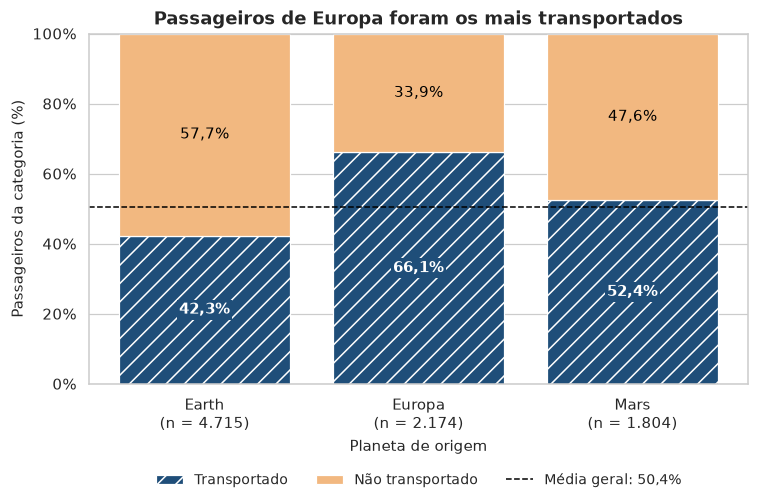

In [23]:
# =============================================================================
# Figura 1 — Taxa de transporte por planeta de origem
# =============================================================================
fig, ax = plt.subplots(figsize=(7, 4.8))
barras_100_empilhadas(ax, "HomePlanet",
                      "Passageiros de Europa foram os mais transportados",
                      "Planeta de origem")
fig.tight_layout()
salvar(fig, "fig_01_transporte_por_planeta.png")
plt.show()

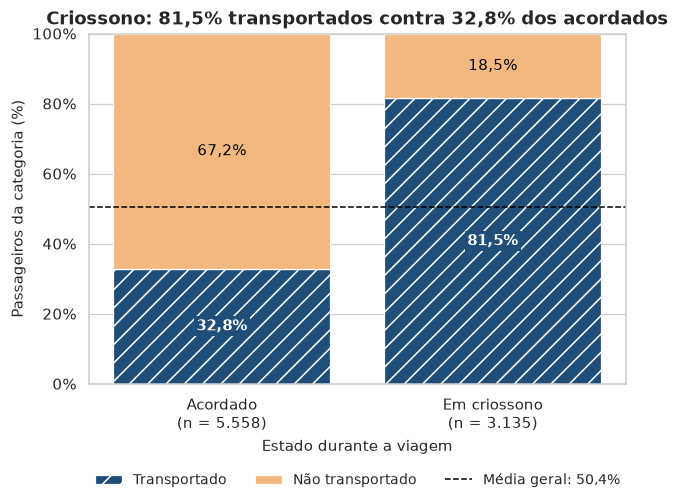

In [24]:
# =============================================================================
# Figura 2 — Taxa de transporte por criossono
# =============================================================================
fig, ax = plt.subplots(figsize=(6, 4.8))
barras_100_empilhadas(ax, "CryoSleep",
                      "Criossono: 81,5% transportados contra 32,8% dos acordados",
                      "Estado durante a viagem")
fig.tight_layout()
salvar(fig, "fig_02_transporte_por_criossono.png")
plt.show()

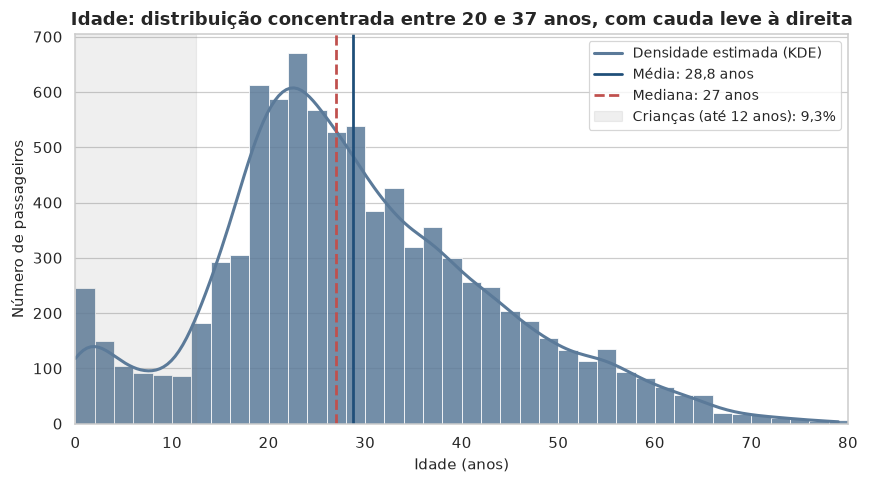

In [25]:
# =============================================================================
# Figura 3 — Distribuição de idade (histograma + KDE)
# =============================================================================
idade = df["Age"]
media, mediana = idade.mean(), idade.median()
pct_criancas = (idade <= 12).mean() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(idade, binwidth=2, binrange=(0, 80), kde=True, color=COR_NEUTRA,
             edgecolor="white", linewidth=0.5, alpha=0.85, ax=ax,
             line_kws={"linewidth": 2, "color": "black"})
ax.lines[0].set_label("Densidade estimada (KDE)")

ax.axvline(media, color=COR_TRANSP, linestyle="-", linewidth=1.8,
           label=f"Média: {fmt_pct(media, 1).rstrip('%')} anos")
ax.axvline(mediana, color="#C0504D", linestyle="--", linewidth=1.8,
           label=f"Mediana: {mediana:.0f} anos")
ax.axvspan(0, 12.5, color="grey", alpha=0.12,
           label=f"Crianças (até 12 anos): {fmt_pct(pct_criancas)}")

ax.set_xlim(0, 80)
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Número de passageiros")
ax.set_title("Idade: distribuição concentrada entre 20 e 37 anos, com cauda leve à direita")
ax.legend(loc="upper right", frameon=True)
ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "fig_03_idade_distribuicao.png")
plt.show()

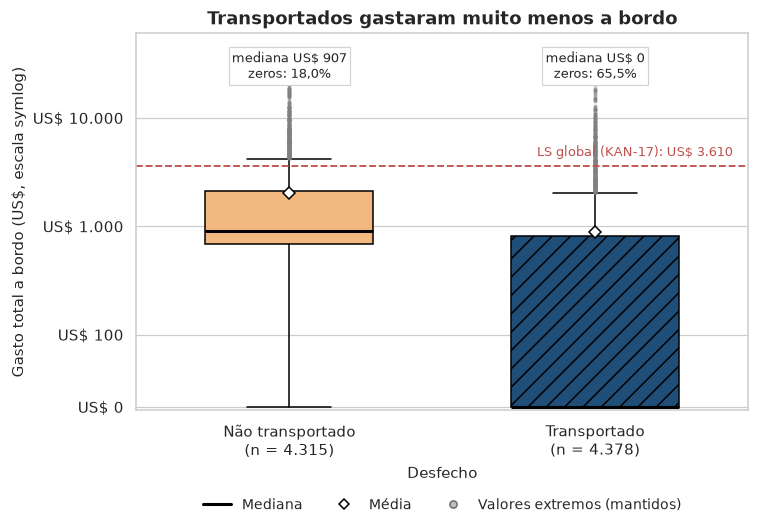

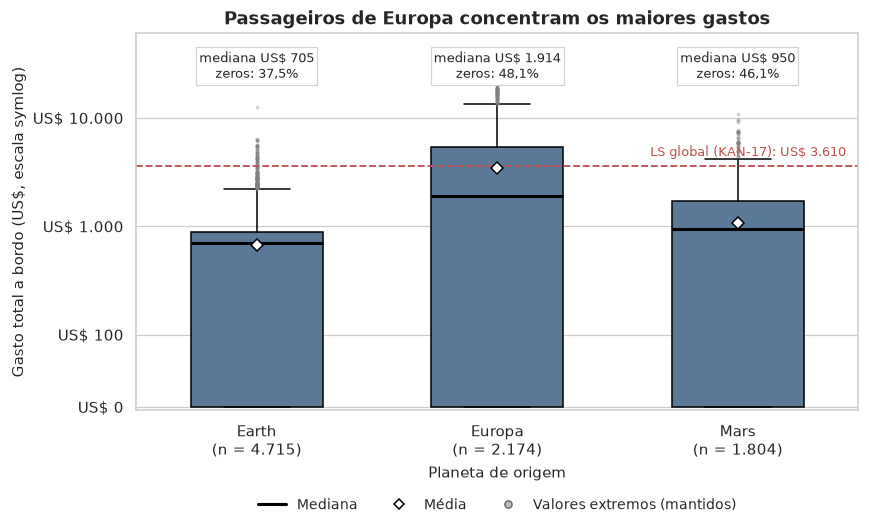

,n,media,mediana,zeros
Transported,,,,
False,4315,2011.89,907.0,17.96
True,4378,891.15,0.0,65.53


,n,media,mediana,zeros
HomePlanet,,,,
Earth,4715,675.24,705.0,37.45
Europa,2174,3444.00,1914.0,48.11
Mars,1804,1059.73,950.0,46.12


In [26]:
# =============================================================================
# Figuras 4 e 5 — Boxplots de TotalSpend
# =============================================================================
# Os quartis e os bigodes (1,5 × IQR) são calculados na ESCALA ORIGINAL, como na
# KAN-17; apenas o EIXO usa escala symlog (linear perto de zero, logarítmica
# depois), para que a caixa não fique achatada pelos zeros. A linha tracejada
# marca o limite superior global da KAN-17 (LS = US$ 3.610).
Q1_TS, Q3_TS = df["TotalSpend"].quantile([0.25, 0.75])
LS_KAN17 = Q3_TS + 1.5 * (Q3_TS - Q1_TS)
assert LS_KAN17 == 3610.0, "LS divergente da KAN-17"


def boxplot_totalspend(ax, grupos: list, rotulos: list, cores: list, hachuras: list, titulo: str, rotulo_x: str):
    dados = [df.loc[mask, "TotalSpend"].to_numpy() for mask in grupos]
    bp = ax.boxplot(dados, whis=1.5, widths=0.55, patch_artist=True, showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
                    medianprops=dict(color="black", linewidth=2),
                    flierprops=dict(marker="o", markersize=2.5, alpha=0.35,
                                    markerfacecolor="grey", markeredgecolor="none"))
    for caixa, cor, hachura in zip(bp["boxes"], cores, hachuras):
        caixa.set_facecolor(cor)
        caixa.set_hatch(hachura)
        caixa.set_edgecolor("black")

    ax.set_yscale("symlog", linthresh=100, linscale=0.6)
    ax.set_ylim(-5, 60000)
    ax.yaxis.set_major_locator(mticker.FixedLocator([0, 100, 1000, 10000]))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"US$ {fmt_int(int(v))}"))
    ax.yaxis.set_minor_locator(mticker.NullLocator())

    ax.axhline(LS_KAN17, color="#C0504D", linestyle="--", linewidth=1.2)
    ax.text(len(dados) + 0.45, LS_KAN17 * 1.15, "LS global (KAN-17): US$ 3.610",
            ha="right", va="bottom", fontsize=8.5, color="#C0504D")

    for i, d in enumerate(dados, start=1):
        pct_zero = (d == 0).mean() * 100
        ax.text(i, 30000, f"mediana US$ {fmt_int(int(np.median(d)))}\nzeros: {fmt_pct(pct_zero)}",
                ha="center", va="center", fontsize=8.5,
                bbox=dict(facecolor="white", edgecolor="lightgrey", pad=2))

    ax.set_xticks(range(1, len(dados) + 1))
    ax.set_xticklabels([f"{r}\n(n = {fmt_int(len(d))})" for r, d in zip(rotulos, dados)])
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel("Gasto total a bordo (US$, escala symlog)")
    ax.set_title(titulo)
    ax.grid(axis="x", visible=False)


from matplotlib.lines import Line2D
legenda_box = [
    Line2D([0], [0], color="black", linewidth=2, label="Mediana"),
    Line2D([0], [0], marker="D", color="none", markerfacecolor="white", markeredgecolor="black", label="Média"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="grey", alpha=0.5, label="Valores extremos (mantidos)"),
]

# --- Figura 4: por Transported ---
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_totalspend(
    ax,
    grupos=[~df["Transported"], df["Transported"]],
    rotulos=["Não transportado", "Transportado"],
    cores=[COR_NAO, COR_TRANSP],
    hachuras=["", HACHURA_TRANSP],
    titulo="Transportados gastaram muito menos a bordo",
    rotulo_x="Desfecho",
)
ax.legend(handles=legenda_box, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout()
salvar(fig, "fig_04_gasto_por_transporte.png")
plt.show()

# --- Figura 5: por HomePlanet ---
fig, ax = plt.subplots(figsize=(8, 5))
boxplot_totalspend(
    ax,
    grupos=[df["HomePlanet"] == p for p in ORDEM["HomePlanet"]],
    rotulos=ORDEM["HomePlanet"],
    cores=[COR_NEUTRA] * 3,
    hachuras=[""] * 3,
    titulo="Passageiros de Europa concentram os maiores gastos",
    rotulo_x="Planeta de origem",
)
ax.legend(handles=legenda_box, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
fig.tight_layout()
salvar(fig, "fig_05_gasto_por_planeta.png")
plt.show()

# Números citados na interpretação
resumo_box = df.groupby("Transported")["TotalSpend"].agg(
    n="size", media="mean", mediana="median", zeros=lambda s: (s == 0).mean() * 100)
resumo_box_planeta = df.groupby("HomePlanet")["TotalSpend"].agg(
    n="size", media="mean", mediana="median", zeros=lambda s: (s == 0).mean() * 100)
display(resumo_box.round(2))
display(resumo_box_planeta.round(2))

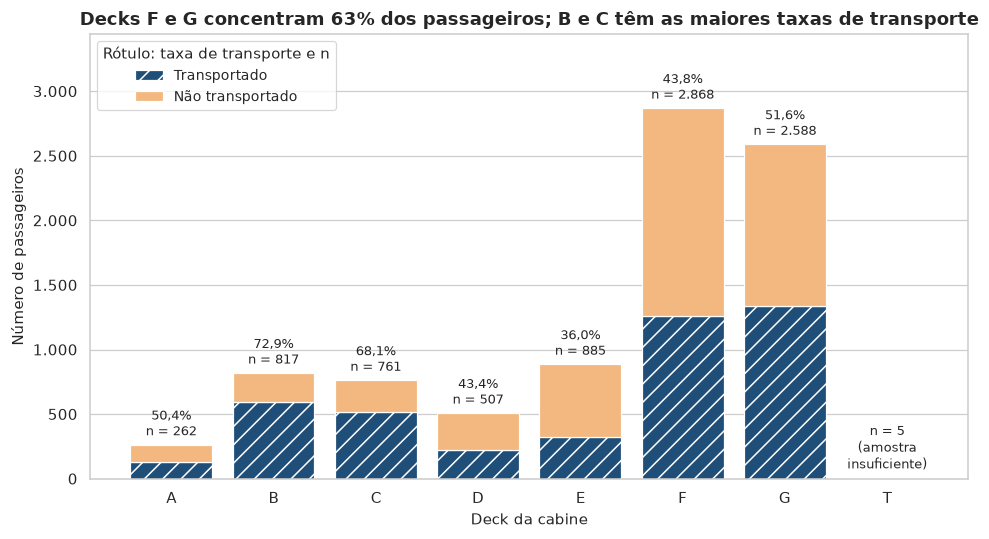

In [27]:
# =============================================================================
# Figura 6 — Passageiros por deck da cabine e taxa de transporte
# =============================================================================
tab_deck = tabelas_cruzadas["CabinDeck"]
x = np.arange(len(tab_deck))

fig, ax = plt.subplots(figsize=(9, 5))
b_t = ax.bar(x, tab_deck["Transportados"], color=COR_TRANSP, hatch=HACHURA_TRANSP,
             edgecolor="white", linewidth=0.8, label="Transportado")
b_n = ax.bar(x, tab_deck["Não transportados"], bottom=tab_deck["Transportados"], color=COR_NAO,
             edgecolor="white", linewidth=0.8, label="Não transportado")

taxas_deck = tab_deck["Transportados"] / tab_deck["n"] * 100
for xi, n, taxa, deck in zip(x, tab_deck["n"], taxas_deck, tab_deck["Categoria"]):
    if deck == "T":
        texto = f"n = {n}\n(amostra\ninsuficiente)"
    else:
        texto = f"{fmt_pct(taxa)}\nn = {fmt_int(n)}"
    ax.text(xi, n + 40, texto, ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(tab_deck["Categoria"])
ax.set_ylim(0, tab_deck["n"].max() * 1.2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt_int(int(v))))
ax.set_xlabel("Deck da cabine")
ax.set_ylabel("Número de passageiros")
ax.set_title("Decks F e G concentram 63% dos passageiros; B e C têm as maiores taxas de transporte")
ax.legend(handles=[b_t, b_n], loc="upper left", frameon=True,
          title="Rótulo: taxa de transporte e n")
ax.grid(axis="x", visible=False)
fig.tight_layout()
salvar(fig, "fig_06_passageiros_por_deck.png")
plt.show()

In [28]:
# =============================================================================
# Conferência das figuras exportadas (critério de aceitação da KAN-16)
# =============================================================================
from PIL import Image

# Apenas as seis figuras geradas neste notebook (as fig_07 e fig_08 são da KAN-19)
figuras = sorted(FIG_DIR.glob("fig_0[1-6]_*.png"))
registro = []
for caminho in figuras:
    with Image.open(caminho) as img:
        dpi = img.info.get("dpi", (None, None))[0]
        registro.append({"Arquivo": caminho.name, "Largura (px)": img.width,
                         "Altura (px)": img.height, "DPI": round(dpi) if dpi else None})

conferencia = pd.DataFrame(registro)
display(conferencia)
assert len(figuras) >= 5, "A KAN-16 exige no mínimo 5 gráficos"
assert (conferencia["DPI"] == DPI).all(), "Todas as figuras devem estar a 300 DPI"
print(f"{len(figuras)} figuras exportadas a {DPI} DPI em {FIG_DIR.as_posix()}")

,Arquivo,Largura (px),Altura (px),DPI
0,fig_01_transporte_por_planeta.png,2071,1376,300
1,fig_02_transporte_por_criossono.png,1868,1376,300
2,fig_03_idade_distribuicao.png,2378,1322,300
3,fig_04_gasto_por_transporte.png,2067,1444,300
4,fig_05_gasto_por_planeta.png,2367,1444,300
5,fig_06_passageiros_por_deck.png,2722,1472,300


6 figuras exportadas a 300 DPI em ../report/figures


## 2.1 Leitura das figuras

| Figura | Arquivo | O que mostra |
|---|---|---|
| 1 | `fig_01_transporte_por_planeta.png` | Europa tem a maior taxa de transporte (66,1%) e a Terra, a menor (42,3%); Marte fica perto da média (52,4%). |
| 2 | `fig_02_transporte_por_criossono.png` | A maior diferença do dataset: 81,5% dos passageiros em criossono foram transportados, contra 32,8% dos acordados. |
| 3 | `fig_03_idade_distribuicao.png` | Idade aproximadamente simétrica (média de 28,8 anos e mediana de 27), concentrada entre 20 e 37 anos; 9,3% são crianças de até 12 anos, com um pico em idade 0 (bebês). |
| 4 | `fig_04_gasto_por_transporte.png` | Entre os transportados, a mediana do gasto total é zero e 65,5% não gastaram nada (média de US$ 891). Entre os não transportados, só 18,0% têm gasto zero, e a mediana é de US$ 907 (média de US$ 2.012). |
| 5 | `fig_05_gasto_por_planeta.png` | Europa concentra os maiores gastos (mediana de US$ 1.914 e média de US$ 3.444), contra medianas de US$ 705 na Terra e US$ 950 em Marte, apesar de Europa ter mais passageiros com gasto zero (48,1%). Os pontos acima do bigode são valores extremos mantidos na base (KAN-17). |
| 6 | `fig_06_passageiros_por_deck.png` | Os decks F e G concentram 63% dos passageiros; B (73,0%) e C (68,1%) têm as maiores taxas de transporte. O deck T (n = 5) aparece sinalizado como amostra insuficiente. |

### Observações metodológicas

- **Boxplots consistentes com a KAN-17.** Os quartis e os bigodes são calculados na escala original, com a mesma regra de 1,5 × IQR; só o eixo usa escala symlog, para que a caixa não fique achatada pelos zeros. Como cada caixa usa os quartis **do seu grupo**, os pontos exibidos não coincidem com a contagem global da KAN-17. A linha tracejada marca o limite global (US$ 3.610) para facilitar a comparação.
- **Associação não é causa.** A Figura 4 mostra que transportados gastaram menos, mas isso é fortemente sobreposto ao criossono (Figura 2): quem está em criossono não consome e foi transportado com mais frequência. A separação desses efeitos fica para a modelagem (KAN-33).

# KAN-15 - Resumos de Variáveis Quantitativas
**Bloqueia** | [KAN-16](https://megamatic.atlassian.net/browse/KAN-16) (gráficos) e [KAN-17](https://megamatic.atlassian.net/browse/KAN-17) (limites de outliers) |
| **Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Critério de aceitação** | Tabela de medidas descritivas quantitativas publicada e validada |

## Objetivo da análise

Caracterizar numericamente o público a bordo em **três dimensões**: **tendência central** (onde os dados se concentram), **dispersão** (o quanto variam) e **assimetria** (se a cauda puxa para um lado). O produto é a tabela oficial de estatísticas descritivas que sustenta as etapas seguintes — as visualizações da KAN-16, os limites de outliers da KAN-17 e o texto consolidado da KAN-18 — além de servir de base para decisões de precificação e segmentação de clientes.

## Nota metodológica: os zeros **não** são ausências

Nas rubricas de consumo (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`), **zero é um valor observado e legítimo** — passageiros em criossono, crianças ou quem simplesmente não consumiu. Excluir essas linhas não "corrige" a média: ela apenas **troca a população analisada** de *todos os passageiros* para *passageiros que gastaram*. Por isso este notebook apresenta três leituras explícitas, sem remover nenhum registro:

| Leitura | O que responde | Uso no relatório |
|---|---|---|
| **A. População** (n = 8.693, zeros incluídos) | "Como o público se comporta, em média?" | estatística oficial da base |
| **B. Entre gastadores** (`valor > 0`) | "Quanto gasta quem efetivamente gasta?" | dimensionamento de ticket por rubrica |
| **C. Impacto dos zeros** | "Quanto os zeros deslocam a média e a mediana?" | evita a leitura ingênua de média |

> **Regra de ouro:** ao citar qualquer rubrica de gasto, reporte **mediana e média juntas**. Média sem mediana, nesse dataset, produz conclusão errada — e é exatamente o tipo de leitura que o enunciado do trabalho pede para evitar.

> **Escopo da correlação:** a matriz de correlação deste notebook é **exploratória** e serve para interpretar os gastos. A análise formal de correlação, com heatmaps e multicolinearidade, é responsabilidade da [KAN-30](https://megamatic.atlassian.net/browse/KAN-30).

In [29]:
# =============================================================================
# KAN-15 — Estatísticas descritivas das variáveis quantitativas
#
# Três leituras complementares (nenhum registro é removido):
#   A) População  : todas as 8.693 observações (zeros incluídos)
#   B) Gastadores : subconjunto com valor > 0, por rubrica
#   C) Impacto    : deslocamento provocado pelos zeros
# =============================================================================
from pathlib import Path

import numpy as np
import pandas as pd

np.random.seed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)

# --- 1. Localização resiliente da base tratada -------------------------------
CANDIDATOS = [
    Path("../data/processed/spaceship_titanic_clean.csv"),
    Path("data/processed/spaceship_titanic_clean.csv"),
]
DATA_PATH = next((caminho for caminho in CANDIDATOS if caminho.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Base tratada não encontrada. Execute o notebook a partir da pasta "
        "notebooks/ ou da raiz do projeto; no Colab, faça upload de "
        "data/processed/spaceship_titanic_clean.csv."
    )

df = pd.read_csv(DATA_PATH)

# --- 2. Contratos de integridade (herdados das KAN-11/KAN-12) ----------------
assert df.shape == (8693, 22), f"Shape inesperado: {df.shape}"
assert df.isna().sum().sum() == 0, "A base tratada não deve conter valores ausentes"
assert df["PassengerId"].is_unique, "PassengerId deve ser chave única"

# --- 3. Variáveis do ticket ---------------------------------------------------
# Age + 5 rubricas + TotalSpend (derivada = soma das rubricas) + GroupSize.
QUANTITATIVAS = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "GroupSize",
]
GASTOS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]


# --- 4. Utilitários de formatação (padrão pt-BR) ------------------------------
def pct(valor: float) -> str:
    """Percentual com vírgula decimal."""
    return f"{valor:.2f}%".replace(".", ",")


def usd(valor: float) -> str:
    """Valor em dólares com separadores no padrão brasileiro."""
    return f"US$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def num(valor: float, casas: int = 2) -> str:
    """Número decimal no padrão brasileiro (vírgula decimal)."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def classificar_assimetria(skew: float) -> str:
    """Regra de bolso: |skew| < 0,5 simétrica; 0,5-1 moderada; > 1 forte."""
    a = abs(skew)
    if a < 0.5:
        return "Aproximadamente simétrica"
    if a < 1.0:
        return "Assimetria moderada"
    return "Assimetria forte (cauda à direita)"


# =============================================================================
# LEITURA A — População completa (n = 8.693)
# =============================================================================
linhas = []
for var in QUANTITATIVAS:
    s = df[var].astype(float)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    media, mediana = s.mean(), s.median()
    dp = s.std(ddof=1)  # desvio-padrão AMOSTRAL

    linhas.append({
        "Variável": var,
        "N": int(s.count()),
        "Média": media,
        "Mediana": mediana,
        "Média - Mediana": media - mediana,
        "Desvio-Padrão (s)": dp,
        "Variância (s²)": s.var(ddof=1),
        "Mínimo": s.min(),
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "Máximo": s.max(),
        "Amplitude Total": s.max() - s.min(),
        "IQR (Q3-Q1)": q3 - q1,
        "Coef. Variação (%)": (dp / media * 100) if media else np.nan,
        "Zeros (n)": int((s == 0).sum()),
        "% Zeros": (s == 0).mean() * 100,
        "Assimetria (skew)": s.skew(),
    })

tabela_geral = pd.DataFrame(linhas)
tabela_geral["Leitura da Assimetria"] = tabela_geral["Assimetria (skew)"].apply(classificar_assimetria)

# Formatação apenas para exibição (os dados originais permanecem intactos)
exibicao_geral = tabela_geral.copy()
colunas_float = [
    "Média", "Mediana", "Média - Mediana", "Desvio-Padrão (s)", "Variância (s²)",
    "Mínimo", "Q1 (25%)", "Q3 (75%)", "Máximo", "Amplitude Total",
    "IQR (Q3-Q1)", "Coef. Variação (%)", "% Zeros", "Assimetria (skew)",
]
exibicao_geral[colunas_float] = exibicao_geral[colunas_float].round(2)

print("=" * 100)
print("LEITURA A — POPULAÇÃO COMPLETA (zeros incluídos)   n =", f"{len(df):,}".replace(",", "."))
print("=" * 100)
display(exibicao_geral.drop(columns=["Leitura da Assimetria"]))
print("\nLeitura da assimetria:")
for var, leitura in zip(tabela_geral["Variável"], tabela_geral["Leitura da Assimetria"]):
    print(f"  {var:<14} {leitura}")


# =============================================================================
# LEITURA B — Entre gastadores (valor > 0)
# =============================================================================
linhas_b = []
for var in GASTOS + ["TotalSpend"]:
    s = df.loc[df[var] > 0, var].astype(float)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    linhas_b.append({
        "Variável": var,
        "N (> 0)": int(s.size),
        "% da amostra": s.size / len(df) * 100,
        "Média (> 0)": s.mean(),
        "Mediana (> 0)": s.median(),
        "Desvio-Padrão (> 0)": s.std(ddof=1),
        "Q1 (> 0)": q1,
        "Q3 (> 0)": q3,
        "Máximo (> 0)": s.max(),
        "Assimetria (> 0)": s.skew(),
    })

tabela_gastadores = pd.DataFrame(linhas_b)
exibicao_b = tabela_gastadores.round(2)

print("\n" + "=" * 100)
print("LEITURA B — ENTRE GASTADORES (somente valores > 0)")
print("=" * 100)
display(exibicao_b)


# =============================================================================
# LEITURA C — Impacto dos zeros (quanto a média/mediana se deslocam)
# =============================================================================
linhas_c = []
for var in GASTOS + ["TotalSpend"]:
    s = df[var].astype(float)
    s_pos = s[s > 0]
    media_pop, mediana_pop = s.mean(), s.median()
    media_pos, mediana_pos = s_pos.mean(), s_pos.median()
    zeros_pct = (s == 0).mean() * 100

    linhas_c.append({
        "Variável": var,
        "% Zeros": zeros_pct,
        "Média (população)": media_pop,
        "Média (> 0)": media_pos,
        "Δ% Média": (media_pop - media_pos) / media_pos * 100,
        "Mediana (população)": mediana_pop,
        "Mediana (> 0)": mediana_pos,
        "Δ% Mediana": ((mediana_pop - mediana_pos) / mediana_pos * 100) if mediana_pos else np.nan,
    })

tabela_impacto = pd.DataFrame(linhas_c)
tabela_impacto["Leitura"] = pd.cut(
    tabela_impacto["% Zeros"],
    bins=[-0.01, 20, 40, 100],
    labels=["Diluição baixa", "Diluição moderada", "Diluição forte"],
).astype(str)

print("\n" + "=" * 100)
print("LEITURA C — IMPACTO DOS ZEROS SOBRE AS MEDIDAS")
print("=" * 100)
display(tabela_impacto.round(2))
print(
    "Nota: para variáveis não negativas, Δ% Média = −% Zeros (identidade matemática:\n"
    "a média populacional é a média dos gastadores ponderada pela fração que gastou).\n"
    "A coluna Δ% Mediana é a que traz informação nova."
)


# =============================================================================
# CORRELAÇÃO — matriz numérica (Spearman principal; Pearson como apêndice)
# =============================================================================
# Spearman: baseado em postos, robusto à assimetria e aos valores extremos.
# Pearson: sensível à cauda; serve de comparação/diagnóstico.
matriz_spearman = df[QUANTITATIVAS].corr(method="spearman")
matriz_pearson = df[QUANTITATIVAS].corr(method="pearson")

print("\n" + "=" * 100)
print("CORRELAÇÃO DE SPEARMAN (ρ) — todas as variáveis do ticket")
print("=" * 100)
display(matriz_spearman.round(2))

print("\nCORRELAÇÃO DE PEARSON (r) — apêndice/comparação")
display(matriz_pearson.round(2))

# Pares mais fortes (triângulo superior), para orientar a interpretação
pares = []
for i, var_a in enumerate(QUANTITATIVAS):
    for var_b in QUANTITATIVAS[i + 1:]:
        pares.append({
            "Par": f"{var_a} × {var_b}",
            "Spearman (ρ)": matriz_spearman.loc[var_a, var_b],
            "Pearson (r)": matriz_pearson.loc[var_a, var_b],
        })

tabela_pares = pd.DataFrame(pares)
tabela_pares["|ρ|"] = tabela_pares["Spearman (ρ)"].abs()
tabela_pares = tabela_pares.sort_values("|ρ|", ascending=False).drop(columns=["|ρ|"])

print("\nTOP 10 pares por |Spearman|:")
display(tabela_pares.head(10).round(3))


# =============================================================================
# CONFERÊNCIA RÁPIDA — valores-chave para validação com a revisora
# =============================================================================
print("\n" + "=" * 100)
print("CONFERÊNCIA — valores-chave")
print("=" * 100)
print(f"Age            média {num(df['Age'].mean())} | mediana {num(df['Age'].median(), 1)} | skew {num(df['Age'].skew())}")
print(f"TotalSpend     média {usd(df['TotalSpend'].mean())} | mediana {usd(df['TotalSpend'].median())} | skew {num(df['TotalSpend'].skew())}")
print(f"TotalSpend>0   média {usd(df.loc[df['TotalSpend'] > 0, 'TotalSpend'].mean())} | mediana {usd(df.loc[df['TotalSpend'] > 0, 'TotalSpend'].median())}")
print(f"GroupSize      média {num(df['GroupSize'].mean())} | mediana {num(df['GroupSize'].median(), 0)} | máximo {df['GroupSize'].max()}")
print(f"Zeros          " + " | ".join(f"{c} {pct((df[c] == 0).mean() * 100)}" for c in GASTOS))
print(f"\nPassageiros sozinhos (IsAlone): {pct(df['IsAlone'].mean() * 100)}")
print(f"Crianças (Age <= 12): {int((df['Age'] <= 12).sum())} passageiros ({pct((df['Age'] <= 12).mean() * 100)})")


LEITURA A — POPULAÇÃO COMPLETA (zeros incluídos)   n = 8.693


,Variável,N,Média,Mediana,Média - Mediana,Desvio-Padrão (s),Variância (s²),Mínimo,Q1 (25%),Q3 (75%),Máximo,Amplitude Total,IQR (Q3-Q1),Coef. Variação (%),Zeros (n),% Zeros,Assimetria (skew)
0,Age,8693,28.78,27.0,1.78,14.35,206.01,0.0,20.0,37.0,79.0,79.0,17.0,49.87,178,2.05,0.43
1,RoomService,8693,221.58,0.0,221.58,660.80,436653.34,0.0,0.0,43.0,14327.0,14327.0,43.0,298.22,5671,65.24,6.38
2,FoodCourt,8693,451.40,0.0,451.40,1596.28,2548110.72,0.0,0.0,67.0,29813.0,29813.0,67.0,353.63,5549,63.83,7.17
3,ShoppingMall,8693,169.95,0.0,169.95,597.95,357544.52,0.0,0.0,23.0,23492.0,23492.0,23.0,351.84,5720,65.80,12.77
4,Spa,8693,305.45,0.0,305.45,1125.46,1266666.31,0.0,0.0,56.0,22408.0,22408.0,56.0,368.47,5412,62.26,7.72
5,VRDeck,8693,299.09,0.0,299.09,1134.08,1286143.48,0.0,0.0,41.0,24133.0,24133.0,41.0,379.18,5598,64.40,7.90
6,TotalSpend,8693,1447.46,717.0,730.46,2808.28,7886438.03,0.0,0.0,1444.0,35987.0,35987.0,1444.0,194.01,3644,41.92,4.40
7,GroupSize,8693,2.04,1.0,1.04,1.60,2.55,1.0,1.0,3.0,8.0,7.0,2.0,78.42,0,0.00,1.89



Leitura da assimetria:
  Age            Aproximadamente simétrica
  RoomService    Assimetria forte (cauda à direita)
  FoodCourt      Assimetria forte (cauda à direita)
  ShoppingMall   Assimetria forte (cauda à direita)
  Spa            Assimetria forte (cauda à direita)
  VRDeck         Assimetria forte (cauda à direita)
  TotalSpend     Assimetria forte (cauda à direita)
  GroupSize      Assimetria forte (cauda à direita)

LEITURA B — ENTRE GASTADORES (somente valores > 0)


,Variável,N (> 0),% da amostra,Média (> 0),Mediana (> 0),Desvio-Padrão (> 0),Q1 (> 0),Q3 (> 0),Máximo (> 0),Assimetria (> 0)
0,RoomService,3022,34.76,637.39,303.5,995.60,31.0,820.75,14327.0,4.07
1,FoodCourt,3144,36.17,1248.10,369.0,2460.11,33.0,1237.50,29813.0,4.42
2,ShoppingMall,2973,34.20,496.93,180.0,939.76,20.0,684.00,23492.0,8.55
3,Spa,3281,37.74,809.28,210.0,1717.21,22.0,753.00,22408.0,4.86
4,VRDeck,3095,35.60,840.05,243.0,1777.24,24.0,793.00,24133.0,4.84
5,TotalSpend,5049,58.08,2492.13,1192.0,3312.92,798.0,2654.00,35987.0,3.70



LEITURA C — IMPACTO DOS ZEROS SOBRE AS MEDIDAS


,Variável,% Zeros,Média (população),Média (> 0),Δ% Média,Mediana (população),Mediana (> 0),Δ% Mediana,Leitura
0,RoomService,65.24,221.58,637.39,-65.24,0.0,303.5,-100.00,Diluição forte
1,FoodCourt,63.83,451.40,1248.10,-63.83,0.0,369.0,-100.00,Diluição forte
2,ShoppingMall,65.80,169.95,496.93,-65.80,0.0,180.0,-100.00,Diluição forte
3,Spa,62.26,305.45,809.28,-62.26,0.0,210.0,-100.00,Diluição forte
4,VRDeck,64.40,299.09,840.05,-64.40,0.0,243.0,-100.00,Diluição forte
5,TotalSpend,41.92,1447.46,2492.13,-41.92,717.0,1192.0,-39.85,Diluição forte


... (3 outputs left out)

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpend,GroupSize
Age,1.00,0.07,0.13,0.03,0.12,0.10,0.19,-0.18
RoomService,0.07,1.00,-0.02,0.06,0.01,-0.02,0.23,-0.04
FoodCourt,0.13,-0.02,1.00,-0.01,0.22,0.23,0.74,0.03
ShoppingMall,0.03,0.06,-0.01,1.00,0.01,-0.01,0.22,-0.04
Spa,0.12,0.01,0.22,0.01,1.00,0.15,0.59,0.02
VRDeck,0.10,-0.02,0.23,-0.01,0.15,1.00,0.59,0.01
TotalSpend,0.19,0.23,0.74,0.22,0.59,0.59,1.00,0.01
GroupSize,-0.18,-0.04,0.03,-0.04,0.02,0.01,0.01,1.00



TOP 10 pares por |Spearman|:


,Par,Spearman (ρ),Pearson (r)
16,FoodCourt × TotalSpend,0.673,0.743
23,Spa × TotalSpend,0.668,0.593
25,VRDeck × TotalSpend,0.639,0.588
11,RoomService × TotalSpend,0.535,0.234
15,FoodCourt × VRDeck,0.517,0.228
20,ShoppingMall × TotalSpend,0.511,0.222
14,FoodCourt × Spa,0.492,0.222
22,Spa × VRDeck,0.454,0.150
8,RoomService × ShoppingMall,0.453,0.056
5,Age × TotalSpend,0.264,0.187



CONFERÊNCIA — valores-chave
Age            média 28,78 | mediana 27,0 | skew 0,43
TotalSpend     média US$ 1.447,46 | mediana US$ 717,00 | skew 4,40
TotalSpend>0   média US$ 2.492,13 | mediana US$ 1.192,00
GroupSize      média 2,04 | mediana 1 | máximo 8
Zeros          RoomService 65,24% | FoodCourt 63,83% | ShoppingMall 65,80% | Spa 62,26% | VRDeck 64,40%

Passageiros sozinhos (IsAlone): 55,27%
Crianças (Age <= 12): 806 passageiros (9,27%)


## Interpretação dos Resultados

### Análise de Idade

A idade média dos passageiros é de **28,8 anos**, com mediana de **27 anos** e desvio-padrão de **14,4 anos**. Média e mediana estão próximas (diferença de 1,8 ano) e a assimetria é baixa (**0,43**), o que indica uma distribuição aproximadamente simétrica. Por isso, **a média é uma síntese adequada** para a idade. O coeficiente de variação de 49,9% mostra dispersão moderada: metade dos passageiros tem entre 20 e 37 anos (Q1 e Q3).

Há um contingente relevante de crianças: **806 passageiros (9,27%) têm até 12 anos**, incluindo 178 registros com idade 0 (bebês de colo). Esses registros são plausíveis e foram mantidos.

### Análise de Gastos

#### (a) Rubricas individuais: leitura populacional

Em todas as cinco rubricas, **a mediana é zero** e a maioria dos passageiros não consumiu nada:

| Rubrica | Média (US$) | Mediana (US$) | % Zeros |
|---|---:|---:|---:|
| RoomService | 221,58 | 0 | 65,24% |
| FoodCourt | 451,40 | 0 | 63,83% |
| ShoppingMall | 169,95 | 0 | 65,80% |
| Spa | 305,45 | 0 | 62,26% |
| VRDeck | 299,09 | 0 | 64,40% |

Mediana zero não significa "gastou pouco", e sim que **a maioria não gastou**. As médias populacionais são puxadas por uma minoria de consumidores intensos: as assimetrias ficam entre 6,4 e 12,8, e os coeficientes de variação ficam entre 298% e 379%. Citar apenas a média, como "o gasto médio em RoomService é de US$ 221", superestima o passageiro típico.

#### (b) Rubricas individuais: entre gastadores

Considerando apenas quem efetivamente consumiu cada serviço, o ticket médio real é muito maior:

| Rubrica | Gastadores (n) | Média (US$) | Mediana (US$) |
|---|---:|---:|---:|
| RoomService | 3.022 | 637,39 | 303,50 |
| FoodCourt | 3.144 | 1.248,10 | 369,00 |
| ShoppingMall | 2.973 | 496,93 | 180,00 |
| Spa | 3.281 | 809,28 | 210,00 |
| VRDeck | 3.095 | 840,05 | 243,00 |

A média entre gastadores fica entre **2,6 e 2,9 vezes** a média populacional, conforme a rubrica. Mesmo nesse subconjunto, a média supera a mediana em 2,1 a 3,9 vezes, o que mostra que a cauda longa persiste entre consumidores. **FoodCourt** tem o maior ticket médio (US$ 1.248), e **Spa** tem a maior distância entre média e mediana (US$ 809 contra US$ 210), puxada por poucos gastos muito altos. Esta é a média **de quem consome**, não do passageiro típico.

#### (c) Zero-inflação e suas consequências

Para variáveis não negativas, a queda da média ao incluir os zeros é igual ao percentual de zeros, por construção matemática, e por isso não é um achado empírico. O dado informativo da tabela C é o **deslocamento da mediana**: em todas as rubricas, ela cai de US$ 180 a US$ 369 (entre gastadores) para **zero** (população). Ou seja, a inclusão dos não consumidores muda completamente o retrato do "passageiro típico".

Consequência prática: qualquer decisão de precificação ou de segmentação deve partir da **mediana** ou da **leitura entre gastadores**, sempre informando o percentual de zeros. Uma estratégia natural é separar duas perguntas: *quem consome?* (taxa de adesão por serviço) e *quanto consome quem consome?* (ticket entre gastadores).

### Análise de TotalSpend e GroupSize

**TotalSpend.** O gasto total médio é de **US$ 1.447,46**, com mediana de **US$ 717,00**. A razão média/mediana é de aproximadamente 2,0, o que indica que a média não representa o passageiro mediano. A zero-inflação é menor que nas rubricas individuais (41,9% não gastaram nada), porque basta consumir em um serviço para sair do zero. Entre os 5.049 passageiros que gastaram, a média sobe para **US$ 2.492,13** e a mediana para **US$ 1.192,00**. A assimetria de 4,40 e o máximo de US$ 35.987 confirmam a cauda longa tratada na KAN-17.

**GroupSize.** É uma variável discreta, de 1 a 8. A mediana é **1** e a média é **2,04**: **55,3% viajam sozinhos**, 19,3% em dupla e 11,7% em trio. Grupos de 5 a 8 pessoas somam cerca de 9% da base e puxam a média para cima (assimetria de 1,89). Para descrever o perfil típico, a mediana e a distribuição de frequências são mais informativas que a média.

### Correlação de Gastos

Na matriz de **Spearman** (medida principal, robusta à cauda longa), as correlações mais fortes são das rubricas com `TotalSpend`: FoodCourt (ρ = 0,67), Spa (ρ = 0,67), VRDeck (ρ = 0,64), RoomService (ρ = 0,54) e ShoppingMall (ρ = 0,51). Essas relações são **esperadas por construção**, pois `TotalSpend` é a soma das rubricas, e não devem ser tratadas como descoberta.

Entre rubricas distintas, há **co-consumo moderado**: FoodCourt × VRDeck (ρ = 0,52), FoodCourt × Spa (ρ = 0,49), Spa × VRDeck (ρ = 0,45) e RoomService × ShoppingMall (ρ = 0,45). Quem usa um serviço tende a usar outros, o que sugere um perfil de "passageiro consumidor". Essa associação não implica causalidade.

`Age` tem correlação fraca e positiva com os gastos (ρ de 0,10 a 0,26; a mais alta é com `TotalSpend`) e fraca e negativa com `GroupSize` (ρ = −0,15).

**Pearson × Spearman.** Na maioria dos pares entre rubricas, o Pearson é bem menor que o Spearman (por exemplo, FoodCourt × VRDeck: r = 0,23 contra ρ = 0,52). Isso acontece porque a relação é monotônica, mas não linear, e é distorcida pela massa de zeros e pela cauda longa. A exceção é **FoodCourt × TotalSpend**, em que o Pearson (r = 0,74) supera o Spearman (ρ = 0,67). Nesse caso, poucos gastos extremos em FoodCourt comandam a relação linear com o total. Por isso, o relatório reporta Spearman como medida principal e Pearson apenas como comparação.

---

# KAN-17 - Documentação de Valores Extremos
**Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Entrega** | Limites LI/LS + contagem de outliers por variável (insumo da KAN-16 e da KAN-18) |

---

## 1. Contexto e ordem de execução

Esta task documenta, de forma auditável, **quais observações são consideradas valores extremos** na base tratada do *Spaceship Titanic* e **qual decisão metodológica** o projeto adota em relação a elas. O produto não é um novo dataset: é a **definição formal do critério** e o **inventário dos pontos sinalizados**, que serão reaproveitados nas etapas seguintes.

## 2. Fundamentação teórica

### 2.1 A regra do intervalo interquartil (IQR)

O critério adotado é o de **Tukey (1977)**, o mesmo que sustenta o boxplot. Ordenando a variável, definem-se:

- $Q_1$ — **primeiro quartil** (25º percentil): valor abaixo do qual estão 25% das observações;
- $Q_3$ — **terceiro quartil** (75º percentil): valor abaixo do qual estão 75% das observações;
- $IQR = Q_3 - Q_1$ — **amplitude interquartil**: largura do miolo central que concentra 50% dos dados;
- $LI = Q_1 - 1{,}5 \times IQR$ — **limite inferior**;
- $LS = Q_3 + 1{,}5 \times IQR$ — **limite superior**.

Uma observação é classificada como **valor extremo (outlier)** quando $x < LI$ ou $x > LS$.

O fator $1{,}5$ não é arbitrário: em uma distribuição normal, ele corresponde a aproximadamente $\pm 2{,}7$ desvios-padrão em torno da média, faixa que concentra ~99,3% dos casos. A vantagem prática do critério é ser **robusto**: depende apenas de quartis, não da média nem do desvio-padrão — que são justamente as medidas contaminadas por valores extremos. Por isso ele funciona mesmo em variáveis assimétricas, como as despesas a bordo deste dataset.

### 2.2 Por que **não** remover os outliers automaticamente

A remoção automática de observações acima de $LS$ seria inadequada neste projeto por cinco razões:

1. **Valores altos aqui são legítimos, não erros.** O dataset registra despesas reais de passageiros em serviços de bordo (Spa, VRDeck, FoodCourt, ShoppingMall, RoomService). Um gasto de US$ 30 mil não é falha de digitação: é o comportamento de um passageiro de alto poder aquisitivo — perfil de interesse comercial direto. Em dados de consumo, a cauda alta é frequentemente **o segmento mais relevante para a decisão**, e tratá-la como ruído elimina justamente a informação que o cliente quer enxergar.
2. **A distribuição é zero-inflada, o que comprime o IQR e rebaixa o $LS$.** Como a mediana das rubricas individuais é zero, $Q_1 = 0$ e o $IQR$ fica pequeno; o limite superior resultante é baixo e sinaliza uma parcela grande da base como "extrema". Aplicar o critério mecanicamente descartaria uma fração substancial da amostra — não por anomalia, mas por uma característica estrutural do fenômeno (parte da frota viaja em criossono e não consome).
3. **A remoção introduziria viés de seleção e destruiria sinal preditivo.** O consumo a bordo é uma das variáveis mais associadas ao desfecho `Transported`. Excluir os maiores gastadores alteraria a distribuição condicional do alvo, mudaria as médias e as proporções relatadas e comprometeria a validade dos testes de hipóteses e das regressões das etapas seguintes — que passariam a descrever uma população que não existe.
4. **Existem alternativas robustas que preservam a informação.** Em vez de descartar, o projeto usa mediana e IQR como medidas-resumo, representação em escala logarítmica quando a cauda longa prejudica a leitura, e — se algum teste exigir suposição de normalidade — análise de sensibilidade (resultados com e sem extremos), em vez de exclusão silenciosa.
5. **O enunciado do trabalho trata outliers como achado analítico, não como etapa de limpeza.** Ele pede explicitamente "outliers e valores faltantes" na análise descritiva, dentro de um relatório de 10–15 páginas cujo peso de clareza é 50%. Documentar os extremos, dizer quantos são, quem são e o que representam **é** a entrega; suprimi-los seria esconder um resultado.

### 2.3 Política adotada neste projeto

| Decisão | Implementação |
|---|---|
| **Manter 100% dos registros** | Nenhuma linha é removida; a base permanece com $n = 8.693$. |
| **Documentar o critério** | $LI$ e $LS$ calculados por variável, com contagem e percentual de sinalizados. |
| **Garantir consistência com a KAN-16** | Os boxplots usarão **estes** limites; os pontos exibidos são exatamente os contabilizados aqui. |
| **Preservar rastreabilidade** | O critério fica versionado no notebook e é citado no texto da KAN-18. |
| **Testar sensibilidade, se necessário** | Se um teste paramétrico exigir, as KAN-26 e KAN-27 (Daniela) comparam resultados com e sem extremos — sem alterar a base oficial. |
| **Proibido** | `df = df[df[col] <= LS]` ou qualquer filtro equivalente sobre a base de análise. |

> **Escopo das variáveis:** o critério é aplicado às **variáveis quantitativas de ampla cardinalidade** (`Age` — discreta em anos completos — e as variáveis contínuas de gasto: as cinco rubricas e `TotalSpend`). `GroupSize` e `CabinNum` ficam fora: a primeira é discreta e limitada (1 a 8) e a segunda é um identificador posicional de cabine — em ambas a regra do IQR não tem interpretação substantiva.

In [30]:
# =============================================================================
# KAN-17 — Limites de outliers pela regra de 1,5 x IQR (Tukey)
#
# LI = Q1 - 1,5 * IQR      |      LS = Q3 + 1,5 * IQR
# Nenhuma observação é removida: a base permanece com n = 8.693.
# =============================================================================
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# --- 1. Localização resiliente da base tratada -------------------------------
# Funciona com o notebook aberto em notebooks/ (Jupyter local) ou na raiz do repo.
CANDIDATOS = [
    Path("../data/processed/spaceship_titanic_clean.csv"),
    Path("data/processed/spaceship_titanic_clean.csv"),
]
DATA_PATH = next((caminho for caminho in CANDIDATOS if caminho.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Base tratada não encontrada. Execute este notebook a partir da pasta "
        "notebooks/ ou da raiz do projeto; no Colab, faça upload de "
        "data/processed/spaceship_titanic_clean.csv."
    )

df = pd.read_csv(DATA_PATH)

# --- 2. Contratos de integridade herdados da KAN-11/KAN-12 -------------------
assert df.shape == (8693, 22), f"Shape inesperado: {df.shape}"
assert df.isna().sum().sum() == 0, "A base tratada não deve conter valores ausentes"
assert df["PassengerId"].is_unique, "PassengerId deve ser chave única"

# --- 3. Variáveis analisadas -------------------------------------------------
# Variáveis quantitativas de ampla cardinalidade (ver Seção 2.3): Age é
# discreta em anos completos; as demais são contínuas (5 rubricas + TotalSpend).
# GroupSize e CabinNum ficam fora por serem, respectivamente, discreta limitada
# e identificador posicional.
VARIAVEIS = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
]

FATOR_IQR = 1.5

# --- 4. Cálculo dos limites e contagem de outliers ---------------------------
registros = []
for var in VARIAVEIS:
    s = df[var].astype(float)

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    li = q1 - FATOR_IQR * iqr
    ls = q3 + FATOR_IQR * iqr

    abaixo_li = int((s < li).sum())
    acima_ls = int((s > ls).sum())
    n_outliers = abaixo_li + acima_ls

    registros.append({
        "Variável": var,
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR (Q3 - Q1)": iqr,
        "LI (Q1 - 1,5·IQR)": li,
        "LS (Q3 + 1,5·IQR)": ls,
        "Abaixo do LI (n)": abaixo_li,
        "Acima do LS (n)": acima_ls,
        "Outliers (n)": n_outliers,
        "% do Dataset": n_outliers / len(df) * 100,
    })

tabela_outliers = pd.DataFrame(registros)

# --- 5. Exibição (arredondamento apenas visual; os dados brutos são mantidos) -
colunas_numericas = [
    "Q1 (25%)", "Q3 (75%)", "IQR (Q3 - Q1)",
    "LI (Q1 - 1,5·IQR)", "LS (Q3 + 1,5·IQR)", "% do Dataset",
]
exibicao = tabela_outliers.copy()
exibicao[colunas_numericas] = exibicao[colunas_numericas].round(2)

def pct(valor: float) -> str:
    """Formata percentual no padrão pt-BR (vírgula decimal)."""
    return f"{valor:.2f}%".replace(".", ",")


def moeda(valor: float) -> str:
    """Formata valor monetário no padrão pt-BR (US$ 1.234,56)."""
    return f"US$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


print(f"Base analisada: {len(df):,} passageiros × {df.shape[1]} colunas".replace(",", "."))
print(f"Critério: LI = Q1 - 1,5·IQR  |  LS = Q3 + 1,5·IQR")
print("Decisão: nenhum registro removido (ver Seção 2.2).\n")
display(exibicao)

# --- 6. Evidência complementar: quem são os extremos de TotalSpend -----------
# Ajuda a sustentar a decisão de NÃO remover (Seção 2.2). Não substitui a
# análise: use os números na seção 'Análise dos Resultados'.
ls_total = tabela_outliers.set_index("Variável").loc["TotalSpend", "LS (Q3 + 1,5·IQR)"]
extremos_total = df.loc[df["TotalSpend"] > ls_total]

print("Perfil dos extremos de TotalSpend (acima do LS):")
print(f"  n = {len(extremos_total)} ({pct(len(extremos_total) / len(df) * 100)} da base)")
print(f"  mediana do grupo = {moeda(extremos_total['TotalSpend'].median())}")
print(f"  menor valor do grupo = {moeda(extremos_total['TotalSpend'].min())}")
print(f"  VIP no grupo = {pct(extremos_total['VIP'].mean() * 100)}  |  VIP na base = {pct(df['VIP'].mean() * 100)}")
print(f"  CryoSleep no grupo = {pct(extremos_total['CryoSleep'].mean() * 100)}  |  CryoSleep na base = {pct(df['CryoSleep'].mean() * 100)}")

# --- 7. Evidência complementar citada na Seção 3 ------------------------------
# Zero-inflação das rubricas, assimetria de Age e continuidade da cauda de
# TotalSpend — números usados em 3.2 e 3.3.
print("\nEvidência complementar citada na Seção 3:")

rubricas_gasto = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
zeros = {var: (df[var] == 0).mean() * 100 for var in rubricas_gasto}
print("  Percentual de zeros nas rubricas de gasto:")
for var in rubricas_gasto:
    print(f"    {var}: {pct(zeros[var])}")
print(f"  Faixa de zeros: {pct(min(zeros.values()))} a {pct(max(zeros.values()))}")

print(f"  Assimetria (skew) de Age: {df['Age'].skew():.2f}".replace(".", ","))

distancias_total = extremos_total["TotalSpend"].sort_values().diff().dropna()
print(f"  Distância mediana entre valores consecutivos do grupo: {moeda(distancias_total.median())}")
print(f"  Maior salto entre valores consecutivos do grupo: {moeda(distancias_total.max())}")
print(f"  Máximo de TotalSpend na base: {moeda(df['TotalSpend'].max())}")

# --- 8. Nota metodológica (evita leitura incorreta dos números) --------------
print("\nNota: nas rubricas de gasto a mediana é zero e Q1 = 0, o que comprime o IQR")
print("e rebaixa o LS. Percentuais altos de sinalizados refletem a zero-inflação")
print("estrutural do consumo a bordo, não erro de dados. Por isso não há remoção.")


Base analisada: 8.693 passageiros × 22 colunas
Critério: LI = Q1 - 1,5·IQR  |  LS = Q3 + 1,5·IQR
Decisão: nenhum registro removido (ver Seção 2.2).



,Variável,Q1 (25%),Q3 (75%),IQR (Q3 - Q1),"LI (Q1 - 1,5·IQR)","LS (Q3 + 1,5·IQR)",Abaixo do LI (n),Acima do LS (n),Outliers (n),% do Dataset
0,Age,20.0,37.0,17.0,-5.5,62.5,0,162,162,1.86
1,RoomService,0.0,43.0,43.0,-64.5,107.5,0,1908,1908,21.95
2,FoodCourt,0.0,67.0,67.0,-100.5,167.5,0,1899,1899,21.85
3,ShoppingMall,0.0,23.0,23.0,-34.5,57.5,0,1891,1891,21.75
4,Spa,0.0,56.0,56.0,-84.0,140.0,0,1826,1826,21.01
5,VRDeck,0.0,41.0,41.0,-61.5,102.5,0,1860,1860,21.40
6,TotalSpend,0.0,1444.0,1444.0,-2166.0,3610.0,0,938,938,10.79


Perfil dos extremos de TotalSpend (acima do LS):
  n = 938 (10,79% da base)
  mediana do grupo = US$ 6.143,00
  menor valor do grupo = US$ 3.617,00
  VIP no grupo = 8,42%  |  VIP na base = 2,29%
  CryoSleep no grupo = 0,00%  |  CryoSleep na base = 36,06%

Evidência complementar citada na Seção 3:
  Percentual de zeros nas rubricas de gasto:
    RoomService: 65,24%
    FoodCourt: 63,83%
    ShoppingMall: 65,80%
    Spa: 62,26%
    VRDeck: 64,40%
  Faixa de zeros: 62,26% a 65,80%
  Assimetria (skew) de Age: 0,43
  Distância mediana entre valores consecutivos do grupo: US$ 6,00
  Maior salto entre valores consecutivos do grupo: US$ 4.911,00
  Máximo de TotalSpend na base: US$ 35.987,00

Nota: nas rubricas de gasto a mediana é zero e Q1 = 0, o que comprime o IQR
e rebaixa o LS. Percentuais altos de sinalizados refletem a zero-inflação
estrutural do consumo a bordo, não erro de dados. Por isso não há remoção.


## 3. Análise dos Resultados

### 3.1 Síntese dos limites encontrados

| Variável | Q1 | Q3 | LS (Q3 + 1,5·IQR) | Acima do LS (n) | % da base |
|---|---:|---:|---:|---:|---:|
| `Age` | 20 | 37 | 62,5 anos | 162 | 1,86% |
| `RoomService` | 0 | 43 | US$ 107,50 | 1.908 | 21,95% |
| `FoodCourt` | 0 | 67 | US$ 167,50 | 1.899 | 21,85% |
| `ShoppingMall` | 0 | 23 | US$ 57,50 | 1.891 | 21,75% |
| `Spa` | 0 | 56 | US$ 140,00 | 1.826 | 21,01% |
| `VRDeck` | 0 | 41 | US$ 102,50 | 1.860 | 21,40% |
| `TotalSpend` | 0 | 1.444 | US$ 3.610,00 | 938 | 10,79% |

- Variável com maior proporção de sinalizados: **`RoomService`** (21,95% da base, 1.908 passageiros acima de US$ 107,50).
- Variável com menor proporção: **`Age`** (1,86%, 162 passageiros acima de 62,5 anos).
- `TotalSpend`: $LS$ = **US$ 3.610,00** e **938** observações acima (10,79% da base).
- Observações abaixo do $LI$: **0 em todas as variáveis**, como esperado: o $LI$ é negativo em todas elas e não há valores negativos na base.

### 3.2 Por que os percentuais altos não indicam problema de dados

As cinco rubricas de gasto têm entre 62% e 66% de passageiros com valor zero. Com isso, $Q_1 = 0$ e a mediana também é zero, o que comprime o $IQR$ (de US$ 23 a US$ 67) e rebaixa o $LS$ para valores muito baixos, entre US$ 57,50 e US$ 167,50. Na prática, o critério de Tukey passa a classificar como "extremo" qualquer consumo um pouco acima de valores modestos, e é por isso que cerca de 21% da base aparece sinalizada em cada rubrica.

Esse resultado é consequência da **zero-inflação estrutural** do consumo a bordo, não de erro de digitação ou de sistema. O critério do IQR foi desenhado para distribuições aproximadamente unimodais e perde poder discriminante quando há grande massa de observações em zero. Ele serve como diagnóstico, mas não justifica a remoção de registros.

O contraste com `Age` confirma a leitura: em uma variável sem zero-inflação e aproximadamente simétrica (assimetria de 0,43), o mesmo critério sinaliza apenas 1,86% da base, um percentual compatível com o esperado.

### 3.3 Quem são os valores extremos

O grupo acima do $LS$ de `TotalSpend` (938 passageiros) tem perfil coerente com um segmento real de clientes:

- **Valores do grupo:** mediana de US$ 6.143,00 e menor valor de US$ 3.617,00, logo acima do limite. A cauda é contínua: entre valores consecutivos do grupo, a distância mediana é de apenas US$ 6, e o maior salto (US$ 4.911) ocorre só no topo, até o máximo de US$ 35.987, valor ainda plausível para um passageiro de alto consumo.
- **Status VIP:** 8,42% no grupo, contra 2,29% na base, uma concentração 3,7 vezes maior.
- **CryoSleep:** 0,00% no grupo, contra 36,06% na base. Isso é coerente com a regra de negócio, pois passageiros em criossono não consomem.

A cauda alta representa, portanto, **passageiros acordados e de maior poder aquisitivo**. Excluí-los apagaria justamente o segmento mais relevante para decisões de receita e enviesaria para baixo as estimativas de consumo e as comparações entre grupos.

### 3.4 Implicações para o relatório e para as próximas etapas

- **(a) KAN-16:** os boxplots exibirão exatamente estes pontos. Nas rubricas de gasto, recomenda-se escala logarítmica, $\log(x + 1)$, para que a caixa central não fique achatada em zero.
- **(b) Medidas-resumo:** nas variáveis de gasto, o relatório deve usar mediana e IQR, sempre acompanhados da média e do percentual de zeros. Média e desvio-padrão isolados superestimam o passageiro típico.
- **(c) Testes inferenciais:** a decisão é **manter todos os registros**. A coerência com testes robustos (Mann-Whitney, Kruskal-Wallis e Welch) será tratada nas KAN-22, 26 e 27. Se algum teste exigir normalidade, poderá ser feita uma análise de sensibilidade com e sem extremos, sem alterar a base oficial em `data/processed/`.

---
# 3. Probabilidade e Distribuições

**Objetivo Analítico (T3):** Probabilidade e Distribuições: investigar modelos teóricos e empíricos das variáveis quantitativas e discretas, evidências visuais (histogramas, QQ-plots), testes formais (Shapiro-Wilk / Kolmogorov-Smirnov) e implicações para a escolha dos testes inferenciais.  
**Tickets Jira:** [KAN-19](https://megamatic.atlassian.net/browse/KAN-19) · [KAN-20](https://megamatic.atlassian.net/browse/KAN-20) · [KAN-21](https://megamatic.atlassian.net/browse/KAN-21) · [KAN-22](https://megamatic.atlassian.net/browse/KAN-22)  
**Notebooks Consolidados:** `notebooks/05_kan19_variaveis_aleatorias_distribuicoes.ipynb` · `notebooks/03_probabilidade_distribuicoes.ipynb`

# KAN-19 — Variáveis aleatórias e distribuições: fichamento teórico aplicado ao Spaceship Titanic

## Mensagens-chave

1. **`Transported` é uma variável de Bernoulli com $p \approx 50{,}4\%$.** As duas classes estão equilibradas. Por isso, a proporção é a medida natural de comparação entre grupos (teste de proporções ou qui-quadrado), e um modelo preditivo precisa superar ~50% de acerto para ter valor.
2. **A idade se aproxima de uma Normal, mas só de forma grosseira.** Ela tem leve assimetria à direita (0,43) e é mais concentrada entre 20 e 40 anos do que a Normal prevê (55,3% contra 51,2%). Comparações de **médias** de idade são seguras pelo Teorema do Limite Central; afirmações sobre **indivíduos** exigem cautela.
3. **Os gastos não seguem um modelo único.** **41,9%** dos passageiros não gastam nada, e entre os que gastam os valores são muito assimétricos. Os gastos positivos lembram uma Log-Normal, mas misturam perfis bem diferentes por planeta de origem (mediana de 826 u.m. na Terra, 5.100 em Europa). A análise deve ser feita em duas perguntas: *o passageiro gastou?* e *quanto gastou, quando gastou?*
4. **Poisson e Exponencial não se aplicam a nenhuma variável do navio.** `GroupSize` é uma contagem, mas nunca vale zero e tem variância maior que a média; não há tempos de espera registrados. As duas ficam como referência teórica.

## Escopo

O card pede a revisão de $P(X=x)$ e $f(x)$, o estudo de cinco modelos e o registro de média, variância e assimetria para interpretar as distribuições reais do navio. Este notebook faz isso e compara cada variável com seu modelo candidato. QQ-plots e testes formais de aderência (Shapiro, K-S) ficam para **KAN-20 e KAN-21**; a escolha dos testes inferenciais, para **KAN-22**.

**Execução:** rode as células em ordem. O notebook procura `data/processed/spaceship_titanic_clean.csv` nas pastas superiores; no Colab, baixa o mesmo arquivo do GitHub (versão fixa da KAN-12). Nenhum arquivo de dados é alterado.

In [31]:
# Configuração: bibliotecas, leitura da base tratada (KAN-12) e formatação dos resultados
from pathlib import Path
import numpy as np

np.random.seed(42)
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

caminho_relativo = Path("data/processed/spaceship_titanic_clean.csv")
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / caminho_relativo).is_file()), None)
fonte = raiz / caminho_relativo if raiz else (
    "https://raw.githubusercontent.com/gmenezesg/spaceship-titanic-estatistica-posdl/"
    "e58304d9b232f60370b1153843ee8f568e0877b7/data/processed/spaceship_titanic_clean.csv")
df_kan19 = pd.read_csv(fonte)

DESPESAS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
assert not df_kan19[["Transported", "Age", "GroupSize", "TotalSpend", *DESPESAS]].isna().any().any()

# Formatação no padrão brasileiro (vírgula decimal, ponto de milhar)
def br(x, casas=2):
    return f"{x:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def pct(x, casas=1):
    return br(100 * x, casas) + "%"

# Estilo dos gráficos: dados em azul, modelo teórico em laranja, eixos discretos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
    "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
print(f"Base tratada: {br(len(df_kan19), 0)} passageiros × {df_kan19.shape[1]} colunas")

Base tratada: 8.693 passageiros × 22 colunas


## 1. Fundamentos (Handout Aula 1)

Uma **variável aleatória** associa um número a cada resultado de um experimento aleatório. Aqui, o experimento é sortear ao acaso um passageiro da base e observar uma característica dele.

| | Variável **discreta** | Variável **contínua** |
|---|---|---|
| Valores possíveis | Finitos ou enumeráveis (0, 1, 2, …) | Qualquer valor em um intervalo |
| Descrita por | Função de probabilidade $p_X(x) = P(X=x)$ | Função densidade $f_X(x)$ |
| Condições | $p_X(x) \ge 0$ e $\sum_x p_X(x) = 1$ | $f_X(x) \ge 0$ e $\int_{-\infty}^{\infty} f_X(x)\,dx = 1$ |
| Probabilidade de um intervalo | Soma: $P(a \le X \le b) = \sum_{a \le x \le b} p_X(x)$ | Área: $P(a \le X \le b) = \int_a^b f_X(x)\,dx$ |
| Probabilidade de um ponto | Pode ser positiva | Sempre $P(X = x) = 0$; a altura $f_X(x)$ **não** é probabilidade e pode passar de 1 |
| Exemplos no navio | `Transported` (0/1), `GroupSize` (1 a 8), `Age` (anos inteiros) | Gastos (`RoomService`, …, `TotalSpend`), tratados como contínuos |

**As três propriedades registradas para cada modelo:**

$$\mu = E(X) \qquad \sigma^2 = \operatorname{Var}(X) = E[(X-\mu)^2] \qquad \gamma_1 = \frac{E[(X-\mu)^3]}{\sigma^3}$$

- **Média ($\mu$):** centro de gravidade da distribuição.
- **Variância ($\sigma^2$):** dispersão em torno da média; o desvio-padrão $\sigma$ está na mesma unidade dos dados.
- **Assimetria ($\gamma_1$):** $\gamma_1 > 0$ indica cauda longa à direita (média > mediana); $\gamma_1 < 0$, à esquerda; $\gamma_1 = 0$ é necessário, mas não suficiente, para simetria.

Os parâmetros teóricos ($\mu$, $\sigma^2$, $\gamma_1$) descrevem o modelo; as medidas calculadas na base ($\bar{x}$, $s^2$, assimetria amostral) são **estimativas**. A comparação entre as duas é o que permite dizer se um modelo é razoável.

## 2. Os cinco modelos teóricos

### 2.1. Quadro-resumo

| Modelo | Tipo | Função | Média | Variância | Assimetria $\gamma_1$ | Situação típica |
|---|---|---|---|---|---|---|
| **Binomial** $(n, p)$ | Discreta, $k = 0, \ldots, n$ | $\binom{n}{k}p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ | $\dfrac{1-2p}{\sqrt{np(1-p)}}$ | Nº de sucessos em $n$ ensaios independentes com mesma chance $p$ |
| **Poisson** $(\lambda)$ | Discreta, $k = 0, 1, 2, \ldots$ | $\dfrac{e^{-\lambda}\lambda^k}{k!}$ | $\lambda$ | $\lambda$ | $\dfrac{1}{\sqrt{\lambda}}$ | Nº de eventos raros em um intervalo de tempo ou espaço |
| **Normal** $(\mu, \sigma^2)$ | Contínua, $x \in \mathbb{R}$ | $\dfrac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$ | $\mu$ | $\sigma^2$ | $0$ | Soma de muitos efeitos pequenos; médias amostrais (TLC) |
| **Log-Normal** $(\mu, \sigma^2)$ | Contínua, $x > 0$ | $\dfrac{1}{x\sigma\sqrt{2\pi}}e^{-\frac{(\ln x-\mu)^2}{2\sigma^2}}$ | $e^{\mu+\sigma^2/2}$ | $(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$ | $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1}$ | Valores positivos que crescem de forma multiplicativa (renda, gastos) |
| **Exponencial** $(\lambda)$ | Contínua, $x \ge 0$ | $\lambda e^{-\lambda x}$ | $1/\lambda$ | $1/\lambda^2$ | $2$ | Tempo de espera até o próximo evento de um processo de Poisson |

**Notas de leitura**

- **Bernoulli** é a Binomial com $n = 1$: média $p$, variância $p(1-p)$.
- **Binomial** é simétrica se $p = 0{,}5$; com $p < 0{,}5$ tem cauda à direita. Em sorteios **sem** reposição de uma população finita, a distribuição exata é a Hipergeométrica.
- **Poisson** tem média igual à variância. Se nos dados a variância for bem maior que a média (*superdispersão*), o modelo não serve.
- **Normal:** cerca de 68,3% dos valores ficam em $\mu \pm \sigma$ e 95,4% em $\mu \pm 2\sigma$; média = mediana = moda.
- **Log-Normal:** $X$ é Log-Normal quando $\ln X$ é Normal; $\mu$ e $\sigma$ são os parâmetros **do logaritmo**. Mediana $= e^{\mu} <$ média. Não admite zeros.
- **Exponencial:** tem *falta de memória*, $P(X > s+t \mid X > s) = P(X > t)$. Na Poisson, $\lambda$ é contagem esperada no intervalo; na Exponencial, é taxa por unidade de tempo. Também não gera zeros exatos: $P(X = 0) = 0$.

### 2.2. O formato de cada modelo

O painel mostra como cada modelo distribui a probabilidade e quanto ele é assimétrico. Os parâmetros são apenas ilustrativos e servem de referência visual para os histogramas reais da seção 3.

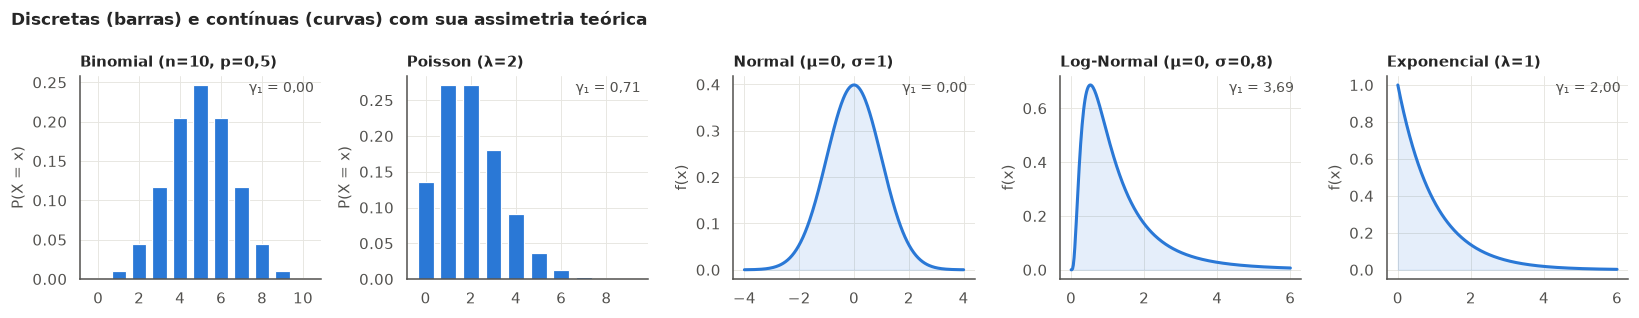

In [32]:
# Painel com a forma de cada modelo e sua assimetria teórica
fig, eixos = plt.subplots(1, 5, figsize=(15, 2.9))
modelos = [
    ("Binomial (n=10, p=0,5)", stats.binom(10, 0.5), np.arange(11), True),
    ("Poisson (λ=2)", stats.poisson(2), np.arange(10), True),
    ("Normal (μ=0, σ=1)", stats.norm(), np.linspace(-4, 4, 300), False),
    ("Log-Normal (μ=0, σ=0,8)", stats.lognorm(0.8), np.linspace(0.001, 6, 300), False),
    ("Exponencial (λ=1)", stats.expon(), np.linspace(0, 6, 300), False),
]
for ax, (nome, dist, x, discreta) in zip(eixos, modelos):
    if discreta:
        ax.bar(x, dist.pmf(x), color=AZUL, width=0.7)
        ax.set_xticks(x[::2])
        ax.set_ylabel("P(X = x)")
    else:
        ax.plot(x, dist.pdf(x), color=AZUL, lw=2)
        ax.fill_between(x, dist.pdf(x), color=AZUL, alpha=0.12)
        ax.set_ylabel("f(x)")
    ax.set_title(nome, fontsize=9.5)
    ax.text(0.97, 0.92, f"γ₁ = {br(float(dist.stats(moments='s')))}", transform=ax.transAxes,
            ha="right", fontsize=9, color=CINZA)
fig.suptitle("Discretas (barras) e contínuas (curvas) com sua assimetria teórica",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

**Leitura da Figura 1.** Binomial com $p = 0{,}5$ e Normal são simétricas ($\gamma_1 = 0$). Poisson, Log-Normal e Exponencial têm cauda à direita. A da Exponencial é fixa ($\gamma_1 = 2$); a da Log-Normal cresce rapidamente com $\sigma$. Na seção 3, comparamos a assimetria observada em cada variável do navio com esses valores para descartar ou manter um modelo.

## 3. Dados reais do navio × modelos teóricos

### 3.1. Visão geral

A tabela reúne média, mediana, desvio-padrão, assimetria e proporção de zeros das variáveis quantitativas, ao lado do modelo de referência indicado pela teoria.

In [33]:
# Momentos empíricos de cada variável e o modelo de referência sugerido pela teoria
referencia = {
    "Age": "Normal (aproximação)",
    "GroupSize": "Nenhum dos cinco (não é Poisson)",
    **{c: "Zeros + Log-Normal nos positivos" for c in DESPESAS},
    "TotalSpend": "Zeros + Log-Normal nos positivos",
}
linhas = []
for col, modelo in referencia.items():
    x = df_kan19[col]
    linhas.append({
        "Variável": col,
        "Média": br(x.mean()),
        "Mediana": br(x.median()),
        "Desvio-padrão": br(x.std()),
        "Assimetria": br(x.skew()),
        "% de zeros": pct((x == 0).mean()),
        "Modelo de referência": modelo,
    })
display(pd.DataFrame(linhas).set_index("Variável"))

,Média,Mediana,Desvio-padrão,Assimetria,% de zeros,Modelo de referência
Variável,,,,,,
Age,"28,78","27,00","14,35","0,43","2,0%",Normal (aproximação)
GroupSize,"2,04","1,00","1,60","1,89","0,0%",Nenhum dos cinco (não é Poisson)
RoomService,"221,58","0,00","660,80","6,38","65,2%",Zeros + Log-Normal nos positivos
FoodCourt,"451,40","0,00","1.596,28","7,17","63,8%",Zeros + Log-Normal nos positivos
ShoppingMall,"169,95","0,00","597,95","12,77","65,8%",Zeros + Log-Normal nos positivos
Spa,"305,45","0,00","1.125,46","7,72","62,3%",Zeros + Log-Normal nos positivos
VRDeck,"299,09","0,00","1.134,08","7,90","64,4%",Zeros + Log-Normal nos positivos
TotalSpend,"1.447,46","717,00","2.808,28","4,40","41,9%",Zeros + Log-Normal nos positivos


**O que a tabela mostra**

- **Idade** é a única variável quase simétrica (assimetria 0,43; média 28,8 e mediana 27). É a única candidata razoável à Normal.
- **Cada tipo de gasto** tem entre **62% e 66% de zeros** e assimetria entre **6 e 13**, muito acima da Exponencial ($\gamma_1 = 2$). A mediana zero mostra que o passageiro típico não usa a comodidade, enquanto a média é puxada por poucos gastadores altos. Nenhum modelo contínuo isolado descreve essa combinação.
- **`TotalSpend`** reduz os zeros para 41,9%, mas continua muito assimétrico (4,40). A média (1.447) é o dobro da mediana (717).
- **`GroupSize`** é uma contagem com assimetria 1,89. A seção 3.5 mostra por que ela não é Poisson.

Nas seções seguintes, cada variável é examinada contra seu modelo candidato.

### 3.2. `Transported` → Bernoulli e Binomial

Codificando *transportado* = 1 e *não transportado* = 0, a variável é Bernoulli. A proporção observada é a estimativa de $p$.

,Valor
Medida,
Transportados,4.378
Não transportados,4.315
p = P(X = 1),"50,36%"
Média do indicador,"0,5036"
Variância do indicador,"0,2500"
Variância teórica p(1 − p),"0,2500"


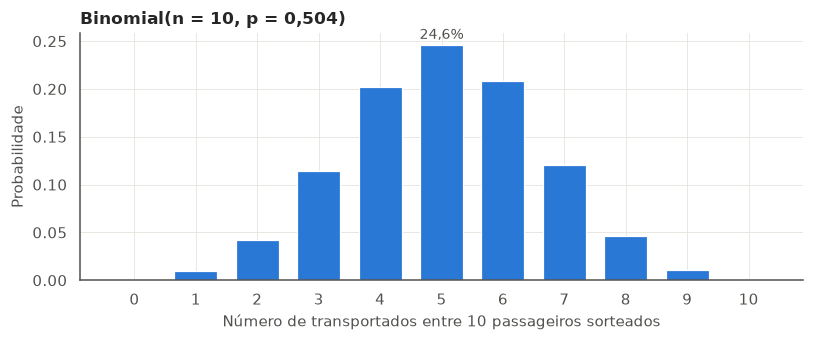

P(exatamente 5) = 24,6% | P(3 a 7) = 89,1% | P(≤ 2 ou ≥ 8) = 10,9%
Média = 5,04 | Variância = 2,50 | Assimetria = -0,005


In [34]:
# Bernoulli: proporção de transportados e conferência de média e variância
y = df_kan19["Transported"].astype(int)
p = y.mean()
display(pd.DataFrame({
    "Medida": ["Transportados", "Não transportados", "p = P(X = 1)", "Média do indicador", "Variância do indicador", "Variância teórica p(1 − p)"],
    "Valor": [br(y.sum(), 0), br((1 - y).sum(), 0), pct(p, 2), br(y.mean(), 4), br(y.var(ddof=0), 4), br(p * (1 - p), 4)],
}).set_index("Medida"))

# Binomial: quantos transportados esperar ao sortear 10 passageiros ao acaso (com reposição)
n = 10
binom = stats.binom(n, p)
k = np.arange(n + 1)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(k, binom.pmf(k), color=AZUL, width=0.7)
for ki in (5,):
    ax.annotate(pct(binom.pmf(ki)), (ki, binom.pmf(ki)), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=9, color=CINZA)
ax.set(xticks=k, xlabel="Número de transportados entre 10 passageiros sorteados", ylabel="Probabilidade",
       title="Binomial(n = 10, p = 0,504)")
fig.tight_layout()
plt.show()
print(f"P(exatamente 5) = {pct(binom.pmf(5))} | P(3 a 7) = {pct(binom.cdf(7) - binom.cdf(2))} | "
      f"P(≤ 2 ou ≥ 8) = {pct(1 - (binom.cdf(7) - binom.cdf(2)))}")
print(f"Média = {br(binom.mean())} | Variância = {br(binom.var())} | Assimetria = {br(float(binom.stats(moments='s')), 3)}")

**Interpretação.**

- **Classes equilibradas:** 4.378 de 8.693 passageiros (**50,36%**) foram transportados. A média do indicador é exatamente essa proporção, e a variância é $p(1-p) \approx 0{,}25$, o valor máximo possível para uma Bernoulli.
- **Consequência para o projeto:** como as classes têm o mesmo tamanho, a acurácia de um modelo preditivo é uma métrica honesta, e o patamar a superar é cerca de 50%.
- **Variação esperada pelo acaso:** em 10 passageiros sorteados ao acaso, o resultado mais provável é 5 transportados (24,6%). Ainda assim, há **89%** de chance de observar entre 3 e 7, e **11%** de cair fora disso. Diferenças de proporção em grupos pequenos (por exemplo, uma família de 4) podem ser puro acaso, o que justifica testes formais na KAN-22.
- **Pressuposto:** a Binomial exige ensaios independentes. Passageiros de um mesmo grupo de viagem tendem a ter o mesmo desfecho, então contagens **dentro de grupos reais** não são Binomiais.

### 3.3. `Age` → Normal

Ajustamos uma Normal com a média e o desvio-padrão da idade e comparamos a curva com o histograma.

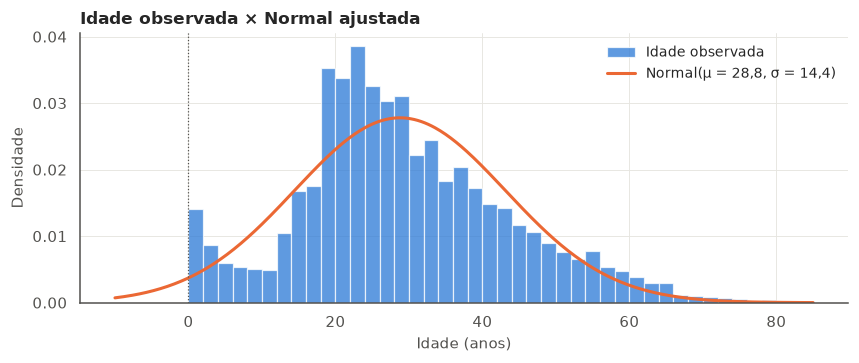

,Observado na base,Previsto pela Normal
Faixa,,
"Média ± 1 desvio (14,4 a 43,1 anos)","71,9%","68,3%"
20 a 40 anos,"55,3%","51,2%"
Menos de 0 ano,"0,0%","2,2%"
60 anos ou mais,"2,9%","1,5%"


Assimetria observada = 0,43 (Normal: 0) | Média = 28,78 | Mediana = 27,00


In [35]:
# Normal ajustada à idade: comparação visual e de probabilidades
idade = df_kan19["Age"]
normal = stats.norm(idade.mean(), idade.std())

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(idade, bins=np.arange(0, 82, 2), density=True, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.8,
        label="Idade observada")
grade = np.linspace(-10, 85, 400)
ax.plot(grade, normal.pdf(grade), color=LARANJA, lw=2, label=f"Normal(μ = {br(idade.mean(), 1)}, σ = {br(idade.std(), 1)})")
ax.axvline(0, color=CINZA, lw=0.8, ls=":")
ax.set(xlabel="Idade (anos)", ylabel="Densidade", title="Idade observada × Normal ajustada")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
FIG_DIR = Path(raiz or ".") / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "fig_07_idade_normal_ajustada.png", dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "Faixa": ["Média ± 1 desvio (14,4 a 43,1 anos)", "20 a 40 anos", "Menos de 0 ano", "60 anos ou mais"],
    "Observado na base": [pct(idade.between(normal.mean() - normal.std(), normal.mean() + normal.std()).mean()),
                          pct(idade.between(20, 40).mean()), pct(0), pct((idade >= 60).mean())],
    "Previsto pela Normal": [pct(normal.cdf(normal.mean() + normal.std()) - normal.cdf(normal.mean() - normal.std())),
                             pct(normal.cdf(40) - normal.cdf(20)), pct(normal.cdf(0)), pct(normal.sf(60))],
}).set_index("Faixa"))
print(f"Assimetria observada = {br(idade.skew())} (Normal: 0) | Média = {br(idade.mean())} | Mediana = {br(idade.median())}")

**Interpretação.**

- **Mais concentrada que a Normal:** **71,9%** dos passageiros estão a até 1 desvio-padrão da média, contra 68,3% numa Normal.
- **Formato:** a idade tem formato de sino, mas não é Normal. O pico entre 18 e 30 anos é mais alto que o da curva, a cauda direita é mais longa (assimetria 0,43, média 28,8 > mediana 27), e há um grupo de crianças pequenas que a Normal não captura.
- **Onde a Normal erra:** ela subestima a concentração em adultos jovens (prevê 51,2% entre 20 e 40 anos, a base tem 55,3%) e atribui **2,2%** de probabilidade a idades negativas, que são impossíveis.
- **Consequência para o projeto:**
  - **Médias de idade:** comparar idade média entre transportados e não transportados é seguro com $n \approx 8.700$, porque pelo TLC a **média amostral** é aproximadamente Normal mesmo que a idade individual não seja.
  - **Testes de normalidade:** um teste formal tende a rejeitar a normalidade da idade com uma amostra desse tamanho. Isso será verificado com QQ-plot na KAN-21 e não invalida o uso da média.
- **Ressalvas:** a idade está registrada em anos inteiros, e 2% dos valores foram imputados na KAN-11, o que concentra observações na mediana.

### 3.4. Gastos → zeros + Log-Normal nos valores positivos

Os gastos têm duas partes: uma massa de passageiros com gasto exatamente zero e uma distribuição contínua entre quem gasta. A teoria da seção 2 mostra que Log-Normal e Exponencial não produzem zeros exatos, então as duas partes precisam ser analisadas separadamente.

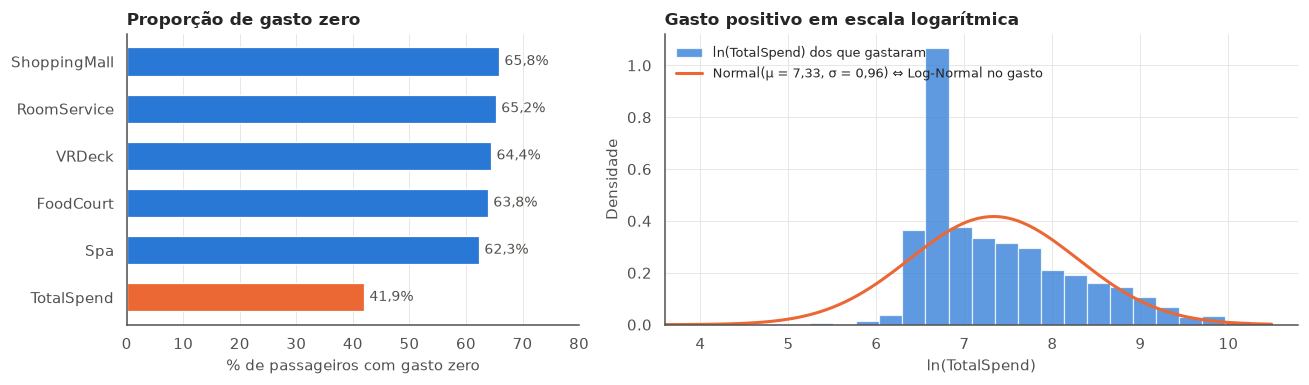

,Observado,Previsto pela Log-Normal
Medida (passageiros com gasto > 0),,
Quantidade,5.049,—
Média,"2.492,13","2.417,20"
Mediana,"1.192,00","1.529,53"
Desvio-padrão,"3.312,59","2.958,02"
Assimetria,"3,70","5,50"


Assimetria de ln(gasto positivo) = -0,35 (uma Log-Normal perfeita teria 0)
Gastadores entre 735 e 945 u.m.: 25,2%; destes, 96,2% são da Terra


,Passageiros,Mediana,Média
HomePlanet,,,
Earth,2.949,826,1.080
Europa,1.128,5.100,6.638
Mars,972,1.590,1.967


In [36]:
# Parte 1: quem gasta. Parte 2: quanto gasta quem gasta (Log-Normal nos positivos)
positivos = df_kan19.loc[df_kan19["TotalSpend"] > 0, "TotalSpend"]
log_pos = np.log(positivos)
mu, sigma = log_pos.mean(), log_pos.std(ddof=0)          # estimadores de máxima verossimilhança
lognormal = stats.lognorm(s=sigma, scale=np.exp(mu))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
zeros = (df_kan19[DESPESAS + ["TotalSpend"]] == 0).mean().sort_values()
ax1.barh(zeros.index, zeros.values * 100, color=[LARANJA if c == "TotalSpend" else AZUL for c in zeros.index], height=0.6)
for i, v in enumerate(zeros.values):
    ax1.text(v * 100 + 1, i, pct(v), va="center", fontsize=9, color=CINZA)
ax1.set(xlim=(0, 80), xlabel="% de passageiros com gasto zero", title="Proporção de gasto zero")
ax1.grid(axis="y", visible=False)

ax2.hist(log_pos, bins=40, density=True, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.8,
         label="ln(TotalSpend) dos que gastaram")
grade = np.linspace(log_pos.min(), log_pos.max(), 300)
ax2.plot(grade, stats.norm(mu, sigma).pdf(grade), color=LARANJA, lw=2,
         label=f"Normal(μ = {br(mu)}, σ = {br(sigma)}) ⇔ Log-Normal no gasto")
ax2.set(xlim=(np.percentile(log_pos, 0.5) - 0.5, log_pos.max() + 0.3),  # oculta poucos gastos de 1 a 50 u.m.
        xlabel="ln(TotalSpend)", ylabel="Densidade", title="Gasto positivo em escala logarítmica")
ax2.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
FIG_DIR = Path(raiz or ".") / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "fig_08_gasto_zero_e_log_normal.png", dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "Medida (passageiros com gasto > 0)": ["Quantidade", "Média", "Mediana", "Desvio-padrão", "Assimetria"],
    "Observado": [br(len(positivos), 0), br(positivos.mean()), br(positivos.median()), br(positivos.std(ddof=0)), br(stats.skew(positivos))],
    "Previsto pela Log-Normal": ["—", br(lognormal.mean()), br(lognormal.median()), br(lognormal.std()), br(float(lognormal.stats(moments="s")))],
}).set_index("Medida (passageiros com gasto > 0)"))
print(f"Assimetria de ln(gasto positivo) = {br(stats.skew(log_pos))} (uma Log-Normal perfeita teria 0)")

# O pico em ln ≈ 6,7 (735 a 945 u.m.): de onde vêm esses passageiros?
gastadores = df_kan19[df_kan19["TotalSpend"] > 0]
no_pico = gastadores["TotalSpend"].between(735, 945)
print(f"Gastadores entre 735 e 945 u.m.: {pct(no_pico.mean())}; destes, {pct((gastadores.loc[no_pico, 'HomePlanet'] == 'Earth').mean())} são da Terra")
display(gastadores.groupby("HomePlanet")["TotalSpend"].agg(
    Passageiros=lambda s: br(len(s), 0), Mediana=lambda s: br(s.median(), 0), Média=lambda s: br(s.mean(), 0)))

**Interpretação.**

- **Parte 1, quem gasta:**
  - **Por comodidade:** cerca de 2 em cada 3 passageiros não usam cada comodidade (62% a 66% de zeros).
  - **No total:** 41,9% não gastam nada. A KAN-11 mostra a causa: passageiros em criossono e crianças de até 12 anos têm gasto zero por regra.
  - **Como tratar:** essa parte é uma variável **Bernoulli** (`HasSpent`), e sua relação com `Transported` deve ser analisada como proporção ou qui-quadrado.
- **Parte 2, quanto gasta quem gasta:**
  - **No logaritmo:** o histograma tem formato de sino, centrado em $e^{7{,}33} \approx 1.530$ unidades monetárias, que é a mediana prevista pela Log-Normal (a observada é 1.192). A Log-Normal é, portanto, um **modelo de trabalho razoável** para os gastos positivos.
  - **Uma mistura de populações:** a Figura 4b tem um pico estreito em torno de 800 u.m. que a curva não acompanha. **25%** dos gastadores estão entre 735 e 945 u.m., e **96%** deles vêm da **Terra**. A mediana de gasto é 826 u.m. para terráqueos, 1.590 para marcianos e 5.100 para europeus. Os gastos positivos são, na verdade, **três distribuições sobrepostas**, uma por planeta de origem, e uma única Log-Normal resume esse conjunto apenas de forma aproximada.
  - **Na cauda:** o ajuste também não é perfeito. Em escala log há leve assimetria à esquerda (−0,35), e a assimetria real dos gastos (3,70) é menor que a prevista (5,50). Os gastos muito altos são **menos extremos** do que a Log-Normal sugere.
- **Consequência para o projeto:**
  - **Testes:** comparar médias de gasto bruto com teste t é frágil, porque a média é dominada pela cauda. É preferível comparar em escala $\ln(1+X)$, usar a mediana ou um teste não paramétrico (Mann-Whitney). A escolha final é da KAN-22.
  - **Regressão:** gastos em escala log tendem a produzir resíduos mais bem comportados, e `HomePlanet` deve entrar como variável explicativa.
  - **Comparações justas:** comparar gastos entre grupos sem controlar o planeta de origem pode confundir o efeito do planeta com o do grupo.

### 3.5. `GroupSize` → por que não é Poisson (e por que a Exponencial também não se aplica)

`GroupSize` é uma contagem, o que poderia sugerir Poisson. A teoria dá dois critérios objetivos para verificar: a Poisson admite o valor 0, e tem média igual à variância.

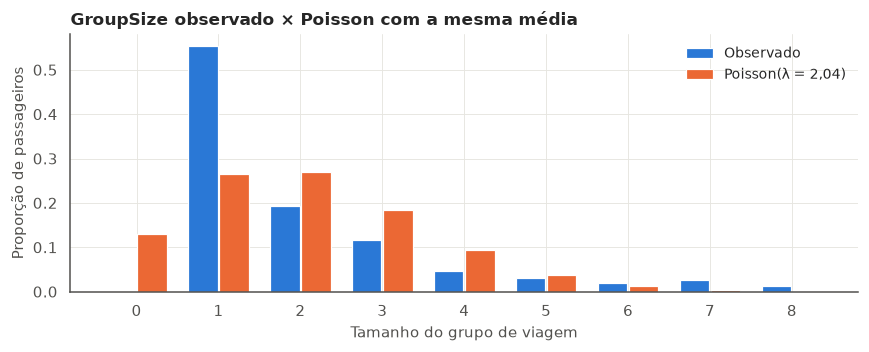

Média = 2,04 | Variância = 2,55 (Poisson exigiria variância = média)
Grupos de tamanho 0: observado 0,0% × Poisson 13,1%
Viajam sozinhos (tamanho 1): observado 55,3% × Poisson 26,6%


In [37]:
# Distribuição observada de GroupSize contra uma Poisson com a mesma média
g = df_kan19["GroupSize"]
poisson = stats.poisson(g.mean())
k = np.arange(0, 9)
obs = g.value_counts(normalize=True).reindex(k, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(k - 0.19, obs.values, width=0.36, color=AZUL, label="Observado")
ax.bar(k + 0.19, poisson.pmf(k), width=0.36, color=LARANJA, label=f"Poisson(λ = {br(g.mean())})")
ax.set(xticks=k, xlabel="Tamanho do grupo de viagem", ylabel="Proporção de passageiros",
       title="GroupSize observado × Poisson com a mesma média")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
print(f"Média = {br(g.mean())} | Variância = {br(g.var())} (Poisson exigiria variância = média)")
print(f"Grupos de tamanho 0: observado {pct(0)} × Poisson {pct(poisson.pmf(0))}")
print(f"Viajam sozinhos (tamanho 1): observado {pct(obs[1])} × Poisson {pct(poisson.pmf(1))}")

**Interpretação.**

- **Por que não é Poisson:** os dois critérios falham.
  - Um grupo de viagem tem **no mínimo 1** pessoa, mas a Poisson atribui **13,1%** de probabilidade ao tamanho 0.
  - A **variância (2,55) é maior que a média (2,04)**, ou seja, há superdispersão.
  - O padrão real também é diferente: **55%** viajam sozinhos (a Poisson prevê 26,6%), e há mais grupos grandes do que o modelo prevê. Isso decorre do processo que forma os grupos (famílias, amigos), não de eventos independentes a uma taxa constante.
- **Consequência para o projeto:** `GroupSize` deve ser tratada como **ordinal ou categórica** (sozinho × grupo, ou faixas de tamanho) em testes qui-quadrado, e não modelada como contagem Poisson.
- **Exponencial:** não há nenhuma variável de tempo de espera ou duração na base, então ela não tem aplicação aqui. Ser positiva e assimétrica não basta: os gastos têm assimetria entre 4 e 13, muito acima da assimetria fixa de 2 da Exponencial, e têm massa em zero, que ela não produz.

## 4. Implicações para as próximas etapas (KAN-20 a KAN-22)

| Variável | Modelo de referência | Evidência desta etapa | Consequência para a análise |
|---|---|---|---|
| `Transported` | Bernoulli ($p = 0{,}504$) | Variância = $p(1-p)$; classes equilibradas | Comparar **proporções** entre grupos (qui-quadrado, teste de proporções); acurácia é métrica válida |
| `Age` | Normal (aproximação) | Assimetria 0,43; 2,2% de massa em idades negativas | **Teste t** para médias é seguro pelo TLC; confirmar o formato com QQ-plot (KAN-21) |
| Gastos e `TotalSpend` | Bernoulli (gastou?) + Log-Normal (quanto?) | 41,9% de zeros; ln(gasto) quase simétrico | Separar `HasSpent` (qui-quadrado) do valor; usar $\ln(1+X)$, mediana ou **Mann-Whitney** |
| `GroupSize` | Nenhum dos cinco | Sem zeros; variância > média | Tratar como **categórica/ordinal** |

### Ligação com a Aula 3: distribuição dos dados × distribuição da média

O **Teorema do Limite Central** afirma que, para observações independentes com variância finita, a **média amostral** $\bar{X}$ tem distribuição aproximadamente Normal para $n$ grande, com média $\mu$ e erro-padrão $\sigma/\sqrt{n}$ (estimado por $s/\sqrt{n}$). Isso explica por que um teste de médias pode ser usado com a idade mesmo sem os dados individuais serem Normais. Para os gastos, a cauda pesada exige amostras bem maiores para a aproximação ser boa, e a média continua sendo pouco representativa do passageiro típico.

**Diferença essencial:** o **desvio-padrão** mede a variação entre passageiros; o **erro-padrão** mede a precisão da média estimada.

### Limitações

- **Imputação:** os momentos foram calculados na base tratada da KAN-12, que inclui ~2% de valores imputados por variável, o que tende a reduzir a variância.
- **Dependência entre passageiros:** passageiros do mesmo grupo não são independentes, um pressuposto da Binomial e do TLC.
- **Ajustes ainda informais:** as comparações desta etapa são descritivas. A confirmação formal (QQ-plot, Shapiro-Wilk, Kolmogorov-Smirnov) fica para a KAN-21.

## 5. Síntese Metodológica do Fichamento (`KAN-19`)

1. **Fundamentos registrados:** função de probabilidade $P(X=x)$ para variáveis discretas e função densidade $f(x)$ para contínuas, com as propriedades de **média, variância e assimetria** dos cinco modelos (Binomial, Poisson, Normal, Log-Normal e Exponencial) consolidadas no quadro da seção 2.1.
2. **`Transported` é Bernoulli** com $p = $ **50,36%** (4.378 de 8.693). As classes equilibradas tornam a proporção a medida central de comparação e fixam em ~50% o patamar mínimo para um modelo preditivo.
3. **`Age` é aproximadamente Normal só no formato geral:** assimetria **0,43**, **55,3%** entre 20 e 40 anos contra **51,2%** previstos, e **2,2%** de probabilidade atribuída a idades negativas. Testes de médias são válidos pelo TLC.
4. **Gastos combinam massa em zero e cauda longa:** **41,9%** com `TotalSpend` = 0 (62% a 66% por comodidade) e assimetria de **4,4 a 12,8**. Entre os positivos, a **Log-Normal** ($\mu = 7{,}33$, $\sigma = 0{,}96$ no log) é um modelo de trabalho adequado, com cauda real mais leve que a prevista (assimetria **3,70** contra **5,50**). O desvio vem de uma mistura por planeta de origem: **96%** do pico em torno de 800 u.m. são terráqueos (mediana **826**, contra **5.100** em Europa).
5. **Poisson e Exponencial não se aplicam:** `GroupSize` não tem zeros e é superdispersa (variância **2,55** > média **2,04**); não existem tempos de espera na base.
6. **Recomendação para a KAN-22:** proporções e qui-quadrado para desfechos binários, teste t para a idade, e escala log ou métodos não paramétricos para gastos.

## 6. Referências

- **Handouts Aula 1 — Distribuições de Probabilidade**, Prof. Adiel Filho: variáveis aleatórias, função de probabilidade e densidade, Bernoulli, Binomial, Poisson, Normal e Exponencial.
- **Handouts Aula 1 — Resumo de Probabilidade (rev. 01)**, Prof. Adiel Filho: espaço amostral, eventos e axiomas.
- **Handouts Aula 3 — Distribuições Amostrais e Estimação**, Prof. Adiel Filho: distribuição amostral, Teorema do Limite Central e erro-padrão.
- **Log-Normal (complemento):** NIST/SEMATECH, *e-Handbook of Statistical Methods*, seção 1.3.6.6.9 — https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm
- **Dados:** `docs/dicionario_dados.md` e `data/processed/spaceship_titanic_clean.csv` (KAN-12) do repositório da equipe.

# KAN-20, KAN-21 e KAN-22 — Probabilidade e Distribuições: aderência empírica
**Seção T3** | 3. Probabilidade e Distribuições |
| **Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Fichamento teórico** | [`05_kan19_variaveis_aleatorias_distribuicoes.ipynb`](05_kan19_variaveis_aleatorias_distribuicoes.ipynb) (KAN-19) |
| **Entrega** | QQ-plots, testes formais de aderência e a tabela de decisão que sustenta os testes da Seção 4 |

> **Aviso de leitura.** Todos os resultados são **descritivos e observacionais**. Aderência a uma distribuição teórica não implica mecanismo gerador; indica apenas que o modelo é uma aproximação útil para resumir e testar os dados.
>
> **Divisão de trabalho com a KAN-19.** O fichamento da KAN-19 já produziu os histogramas, os ajustes Normal e Log-Normal e a separação entre "quem gasta" e "quanto gasta". Este notebook **não repete** essas figuras: ele testa formalmente a aderência, mede o tamanho do desvio e traduz o resultado na escolha dos testes inferenciais. As evidências da KAN-19 são citadas por referência de célula.

## 1. Preparação reproduzível

Uma única célula de configuração concentra imports, semente e leitura da base. Não há etapa de limpeza: a base `spaceship_titanic_clean.csv` já passou pelo pipeline da Seção 1 e é lida por **caminho relativo à raiz do projeto**. A semente fica fixa em 42 para que qualquer reamostragem futura seja reproduzível.

In [38]:
# =============================================================================
# KAN-20/21/22 — Configuração do ambiente
#
# Regras de reprodutibilidade do projeto:
#   - semente fixa em 42;
#   - base lida por caminho relativo (notebook aberto em notebooks/ ou na raiz);
#   - nenhuma etapa de limpeza repetida;
#   - nenhuma figura gravada em disco: os QQ-plots são exibidos inline.
# =============================================================================
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import scipy
import statsmodels
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(42)  # semente fixa do projeto, declarada literalmente

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

# --- Localização resiliente da base tratada ---------------------------------
CANDIDATOS = [
    Path("../data/processed/spaceship_titanic_clean.csv"),
    Path("data/processed/spaceship_titanic_clean.csv"),
]
DATA_PATH = next((caminho for caminho in CANDIDATOS if caminho.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Base tratada não encontrada a partir de notebooks/ ou da raiz.")

RAIZ = DATA_PATH.parent.parent
df = pd.read_csv(DATA_PATH)

print(f"Base: {df.shape[0]:,} passageiros x {df.shape[1]} colunas".replace(",", "."))
print(f"Valores ausentes: {int(df.isna().sum().sum())}")
print(f"Semente: {SEED}")
print(f"Dependências: scipy {scipy.__version__} | statsmodels {statsmodels.__version__}")

Base: 8.693 passageiros x 22 colunas
Valores ausentes: 0
Semente: 42
Dependências: scipy 1.18.1 | statsmodels 0.15.0


**Leitura.** A base tem **8.693 passageiros × 22 colunas e zero valores ausentes**, então não há imputação a refazer. As bibliotecas usadas já fazem parte do ambiente do projeto (`scipy` 1.18.1 e `statsmodels` 0.15.0); a versão importa porque o teste de Lilliefors mudou de comportamento e passou a aceitar o método `approx`, usado na Seção 5.

## 2. O que a KAN-19 já estabeleceu e o que este notebook acrescenta

O fichamento da KAN-19 não é apenas teórico: ele já produziu evidência empírica sobre a forma das distribuições. A tabela abaixo localiza essa evidência para que ela seja **citada**, e não refeita.

| Evidência | Onde está | Conclusão já registrada |
|---|---|---|
| Idade observada × Normal ajustada ($\mu = 28{,}8$; $\sigma = 14{,}4$) | KAN-19, célula 14 (`fig_07`) | A curva acompanha o centro e subestima as caudas; há concentração em idade 0 |
| "Quem gasta" × "quanto gasta"; Log-Normal nos positivos ($\ln$: $\mu = 7{,}33$; $\sigma = 0{,}96$) | KAN-19, célula 17 (`fig_08`) | 41,9% com gasto zero; nos positivos o formato é de sino, mas há mistura de populações |
| Implicações preliminares para a KAN-20 a KAN-22 | KAN-19, célula 22 | A escolha dos testes deve considerar zeros e caudas |

**O que falta e este notebook entrega:** (i) definir explicitamente a **população** de cada teste — o erro clássico é testar `TotalSpend` completo, que é uma mistura com 41,92% de zeros, contra uma lei contínua; (ii) quantificar a forma com QQ-plots; (iii) aplicar testes formais com **tamanho de efeito**; (iv) traduzir o resultado na tabela de decisão da KAN-22, reconciliada com o que a Seção 4 efetivamente executou.

## 3. KAN-20 — Populações de análise e momentos

Antes de qualquer teste, é preciso declarar **qual população** está sendo testada. `TotalSpend` não é uma variável contínua: é uma mistura *hurdle*, com uma decisão binária ("gastou ou não") e, condicionada a gastar, um valor positivo. Testar a variável completa contra uma Normal mede a mistura, não a forma dos gastos.

As populações adotadas são:

- **`Age` (todos):** 8.693 passageiros, incluindo os 178 com idade 0 (bebês);
- **`Age > 0`:** 8.515 passageiros, usada apenas como sensibilidade na Seção 5;
- **`TotalSpend` (todos):** 8.693 passageiros, com 3.644 zeros — retrato da mistura;
- **`log1p(TotalSpend) | TotalSpend > 0`:** 5.049 passageiros que gastaram;
- **gastos por serviço | valor > 0:** entre 2.973 e 3.281 passageiros por rubrica.

A célula seguinte calcula, para cada população, tamanho, proporção de zeros, média, desvio, assimetria e curtose. A assimetria mede o puxão da cauda (0 = simétrica); a curtose em excesso mede o peso das caudas (0 = Normal).

In [39]:
# =============================================================================
# KAN-20 — Populações e momentos
#
# A mesma variável pode ter formas diferentes conforme a população:
#   - TotalSpend completo é uma mistura (hurdle) com 41,92% de zeros;
#   - log1p(TotalSpend) nos positivos isola a forma dos gastos efetivos;
#   - cada serviço tem 62% a 66% de zeros e é tratado apenas nos positivos.
# =============================================================================
SERVICOS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

populacoes = {
    "Age (todos)": df["Age"],
    "Age > 0": df.loc[df["Age"] > 0, "Age"],
    "TotalSpend (todos)": df["TotalSpend"],
    "log1p(TotalSpend) | > 0": np.log1p(df.loc[df["TotalSpend"] > 0, "TotalSpend"]),
}
for servico in SERVICOS:
    populacoes[f"{servico} | > 0"] = df.loc[df[servico] > 0, servico]

linhas = []
for nome, serie in populacoes.items():
    linhas.append(
        {
            "População": nome,
            "n": len(serie),
            "Zeros (n)": int((serie == 0).sum()),
            "Zeros (%)": 100 * (serie == 0).mean(),
            "Média": serie.mean(),
            "Desvio": serie.std(ddof=1),
            "Assimetria": stats.skew(serie, bias=False),
            "Curtose (excesso)": stats.kurtosis(serie, bias=False),
        }
    )

momentos = pd.DataFrame(linhas).set_index("População")
momentos

,n,Zeros (n),Zeros (%),Média,Desvio,Assimetria,Curtose (excesso)
População,,,,,,,
Age (todos),8693,178,2.048,28.783,14.353,0.431,0.160
Age > 0,8515,0,0.000,29.384,13.879,0.543,0.198
TotalSpend (todos),8693,3644,41.919,"1,447.462","2,808.280",4.400,27.279
log1p(TotalSpend) | > 0,5049,0,0.000,7.335,0.948,-0.189,4.925
RoomService | > 0,3022,0,0.000,637.388,995.599,4.066,27.911
FoodCourt | > 0,3144,0,0.000,"1,248.096","2,460.113",4.421,28.761
ShoppingMall | > 0,2973,0,0.000,496.931,939.757,8.546,147.119
Spa | > 0,3281,0,0.000,809.278,"1,717.207",4.862,32.822
VRDeck | > 0,3095,0,0.000,840.054,"1,777.241",4.838,32.914


**Leitura dos momentos.**

- **`Age` (todos).** Assimetria **0,43** e curtose **0,16**: desvio moderado à direita, caudas próximas das de uma Normal. A ressalva é a **discretização** — são apenas 80 valores distintos — e o **pico em idade 0** (178 passageiros, 2,05%), que nenhuma densidade contínua representa.
- **`TotalSpend` (todos).** Assimetria **4,40** e curtose **27,28**: a média (US$ 1.447,46) é maior que a mediana (US$ 717,00) e não resume bem a variável. Os 41,92% de zeros são metade da explicação.
- **`log1p(TotalSpend) | > 0`.** A transformação logarítmica praticamente elimina a assimetria (**−0,19**), mas **não** as caudas: a curtose sobe para **4,93**. Ou seja, o log resolve o puxão à direita e revela que os gastos positivos são uma mistura de perfis, com caudas mais pesadas que a Log-Normal.
- **Serviços (positivos).** Assimetria entre **4,07** (`RoomService`) e **8,55** (`ShoppingMall`). Mesmo entre quem gastou, cada rubrica tem cauda longa; a Log-Normal é aproximação de trabalho, não descrição exata.

Esses números antecipam a conclusão da Seção 5: a Normal descreve `Age` de forma grosseira e a Log-Normal descreve os gastos positivos de forma razoável no corpo, mas ambas serão rejeitadas por testes formais.

## 4. KAN-21 — QQ-plots

O **QQ-plot** (quantil-quantil) compara os quantis observados com os quantis teóricos de uma distribuição. Se os pontos caem sobre a reta de 45°, a aderência é boa. Os desvios têm leitura própria:

- pontos **acima** da reta no extremo direito → cauda direita mais longa que a teórica;
- pontos **abaixo** da reta no extremo esquerdo → cauda esquerda mais longa;
- **degraus** horizontais → variável discreta (muitos empates);
- **curvatura em S** → assimetria ou caudas mais pesadas.

Atenção: no `probplot` do SciPy, a média e o desvio são **estimados da própria amostra**. Isso é o correto para um diagnóstico descritivo, mas invalida o Kolmogorov-Smirnov clássico — motivo pelo qual a Seção 5 usa Lilliefors.

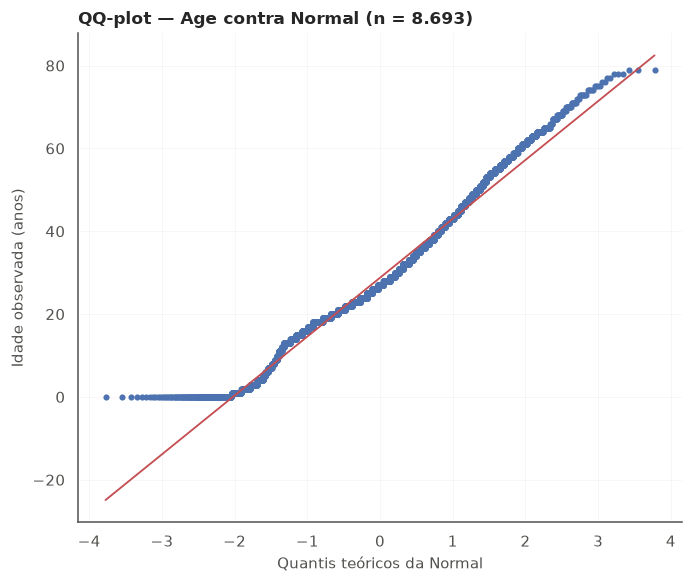

In [40]:
# =============================================================================
# KAN-21 — QQ-plot de Age contra a Normal
#
# A reta representa a Normal com média e desvio estimados da amostra.
# Desvios sistemáticos nos extremos indicam caudas diferentes da Normal.
# =============================================================================
fig, ax = plt.subplots(figsize=(6.4, 5.4))
stats.probplot(df["Age"], dist="norm", plot=ax, fit=True)
ax.get_lines()[0].set_markerfacecolor("#4C72B0")
ax.get_lines()[0].set_markeredgecolor("#4C72B0")
ax.get_lines()[0].set_markersize(3)
ax.get_lines()[1].set_color("#C44E52")
ax.set_title("QQ-plot — Age contra Normal (n = 8.693)")
ax.set_xlabel("Quantis teóricos da Normal")
ax.set_ylabel("Idade observada (anos)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Leitura do QQ-plot de `Age`.** Na faixa central (quantis teóricos entre −1 e 1), **4.685 dos 5.935 pontos ficam abaixo da reta** — e não acima. A mediana observada (27 anos) é menor que a prevista pelo ajuste (28,8 anos): o miolo da distribuição real está em idades mais baixas do que a Normal desloca. Três trechos explicam o desenho:

- no extremo **esquerdo**, um patamar horizontal na altura de 0 anos marca o pico discreto de 178 bebês, que nenhuma densidade contínua representa, e mantém os pontos **acima** da reta;
- na metade **superior** do miolo (entre 0 e 1), 2.758 de 2.968 pontos ficam **abaixo**: entre 20 e 40 anos estão 55,3% dos passageiros, contra 51,3% previstos pela Normal;
- **acima de 1**, os pontos voltam a ficar **acima** da reta (1.353 de 1.379), de modo que o desenho fecha em S.

Os degraus ao longo da reta vêm da discretização (80 valores inteiros). O padrão combina **átomo em 0, discretização e concentração entre 20 e 40 anos** — não é de cauda pesada, como confirmam a curtose 0,16 e o W de 0,980. É o que explica o D de 0,076: a Normal serve para resumir o centro, mas não para prometer aderência exata.

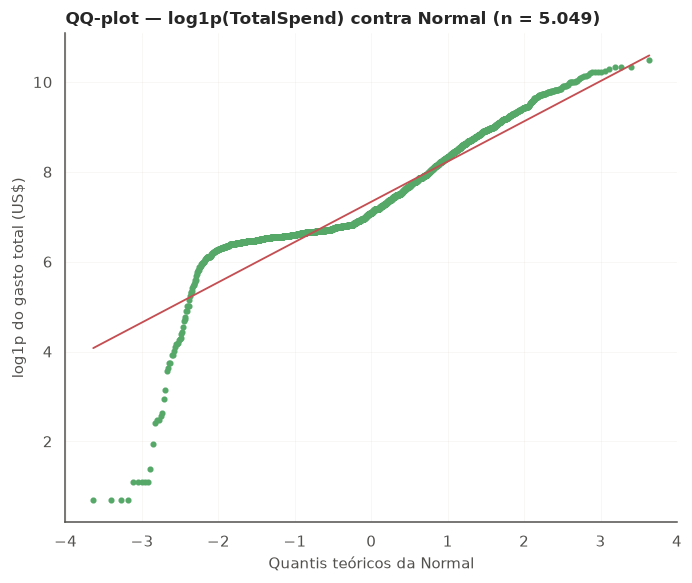

In [41]:
# =============================================================================
# KAN-21 — QQ-plot de log1p(TotalSpend) contra a Normal
#
# População: apenas os 5.049 passageiros com TotalSpend > 0.
# Os 3.644 zeros são uma decisão binária e não pertencem a esta população.
# =============================================================================
gasto_positivo = df.loc[df["TotalSpend"] > 0, "TotalSpend"]
log_gasto = np.log1p(gasto_positivo)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
stats.probplot(log_gasto, dist="norm", plot=ax, fit=True)
ax.get_lines()[0].set_markerfacecolor("#55A868")
ax.get_lines()[0].set_markeredgecolor("#55A868")
ax.get_lines()[0].set_markersize(3)
ax.get_lines()[1].set_color("#C44E52")
ax.set_title("QQ-plot — log1p(TotalSpend) contra Normal (n = 5.049)")
ax.set_xlabel("Quantis teóricos da Normal")
ax.set_ylabel("log1p do gasto total (US$)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Leitura do QQ-plot de `log1p(TotalSpend)`.** O desvio mais forte está à **esquerda**: abaixo de aproximadamente −2,3, os pontos despencam quase na vertical, de 4 para 0,7. Isso corresponde a gastos positivos mínimos (US$ 1 a US$ 30), muito mais numerosos do que a Log-Normal prevê. No **corpo** (quantis teóricos entre −1,5 e 0,5), os pontos ficam levemente abaixo da reta. No **trecho superior** (entre 0,5 e 2,5), ficam acima: há excesso de gastos altos. No extremo direito, voltam à reta.

Esse formato em S, com uma perna vertical à esquerda, é a assinatura da curtose **4,93** medida na Seção 3. A leitura de negócio é direta: a maioria dos passageiros que gasta tem consumo intermediário parecido, mas existem tanto micropassageiros quanto um grupo pequeno de gastos muito altos. Uma única Log-Normal não cobre as duas pontas.

## 5. Testes formais de aderência

As hipóteses, para cada variável, são:

- $H_0$: a variável segue uma distribuição Normal (para `Age`) ou uma Normal na escala $\log1p$ (para os gastos positivos);
- $H_1$: a variável não segue essa distribuição;
- nível de significância $\alpha = 0,05$.

Dois testes são aplicados em paralelo, por motivos diferentes:

1. **Shapiro-Wilk** — teste de aderência com boa potência em amostras pequenas e médias. Com $n > 5.000$ o $p$-valor deixa de ser confiável: o próprio SciPy emite aviso. O **W** continua informativo (1 = aderência perfeita).
2. **Kolmogorov-Smirnov com correção de Lilliefors** — o KS clássico exige parâmetros conhecidos; quando a média e o desvio são estimados da amostra, o $p$ do KS fica **conservador** (rejeita de menos). Lilliefors corrige isso. Reporta-se **D**, a maior distância entre a distribuição empírica e a teórica (0 = aderência perfeita).

Com $n$ na casa dos milhares, qualquer desvio mínimo é significativo. Por isso a decisão deste notebook **não** se apoia no $p$-valor: ela se apoia no **tamanho do desvio** (W e D) e na leitura do QQ-plot.

In [42]:
# =============================================================================
# Testes formais de aderência
#
# Shapiro-Wilk  : reporta W (1 = aderência perfeita); p instável para n > 5.000.
# Lilliefors    : KS com parâmetros estimados; pvalmethod="approx" evita o
#                 piso de 0,001 que o método padrão devolve em amostras grandes.
# =============================================================================
def fmt_p(valor: float) -> str:
    """Formata p-valores em notação científica com vírgula decimal."""
    if valor < 1e-300:
        return "< 1e-300"
    return f"{valor:.2e}".replace(".", ",")


alvos = {
    "Age (todos)": df["Age"],
    "Age > 0": df.loc[df["Age"] > 0, "Age"],
    "log1p(TotalSpend) | > 0": log_gasto,
}

with warnings.catch_warnings(record=True) as capturados:
    warnings.simplefilter("always")
    registros = []
    for nome, serie in alvos.items():
        w_shapiro, p_shapiro = stats.shapiro(serie)
        d_lilliefors, p_lilliefors = lilliefors(serie, dist="norm", pvalmethod="approx")
        registros.append(
            {
                "População": nome,
                "n": len(serie),
                "W (Shapiro)": w_shapiro,
                "p (Shapiro)": p_shapiro,
                "D (Lilliefors)": d_lilliefors,
                "p (Lilliefors)": p_lilliefors,
            }
        )

aderencia = pd.DataFrame(registros).set_index("População")
aderencia["Decisão (α = 0,05)"] = np.where(
    aderencia["p (Lilliefors)"] < 0.05, "Rejeita H0", "Não rejeita H0"
)

avisos = sorted({str(aviso.message) for aviso in capturados})
print(f"Avisos do SciPy durante os testes: {len(avisos)}")
for aviso in avisos:
    print(f"  - {aviso}")

aderencia.assign(**{
    "p (Shapiro)": aderencia["p (Shapiro)"].map(fmt_p),
    "p (Lilliefors)": aderencia["p (Lilliefors)"].map(fmt_p),
})

Avisos do SciPy durante os testes: 3
  - scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5049.
  - scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8515.
  - scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8693.


,n,W (Shapiro),p (Shapiro),D (Lilliefors),p (Lilliefors),"Decisão (α = 0,05)"
População,,,,,,
Age (todos),8693,0.980,"3,46e-33",0.076,"2,50e-136",Rejeita H0
Age > 0,8515,0.975,"8,11e-36",0.085,"1,45e-166",Rejeita H0
log1p(TotalSpend) | > 0,5049,0.891,"8,57e-51",0.126,"1,14e-222",Rejeita H0


**Leitura da tabela.** As três populações **rejeitam** $H_0$, como era esperado com $n$ de 5 mil a 8,7 mil. O que importa é a magnitude:

| População | W | D | Leitura |
|---|---:|---:|---|
| `Age` (todos) | 0,980 | 0,076 | Desvio **pequeno**. A Normal é aproximação de trabalho aceitável para o centro; a rejeição vem da discretização e da concentração central, não de cauda pesada. |
| `Age > 0` | 0,975 | 0,085 | Desvio **maior** ao retirar os zeros (ver Seção 5.1). |
| `log1p(TotalSpend)` | 0,891 | 0,126 | Desvio **moderado a grande**. A Log-Normal descreve o corpo, mas não as duas caudas. |

O aviso do SciPy sobre o $p$ do Shapiro aparece porque duas populações passam de 5.000 observações. Nenhuma decisão deste notebook depende desse $p$: a estatística descritiva (W e D) e o QQ-plot são suficientes, e o Lilliefors com `approx` confirma a rejeição sem depender do piso de 0,001.

### 5.1 Sensibilidade: retirar o pico em `Age = 0`

A hipótese natural é que o pico de 178 bebês em idade 0 seja o responsável pela rejeição da Normal. A linha `Age > 0` da tabela testa exatamente isso — e o resultado **contraria** a hipótese:

- **W cai** de 0,980 para 0,975;
- **D sobe** de 0,076 para 0,085;
- a assimetria **aumenta** de 0,43 para 0,54.

Ou seja, retirar os zeros **piora** a aderência. A explicação é que o pico em 0 ocupa uma região em que a Normal ajustada ainda tem densidade; ao removê-lo, sobra uma distribuição mais assimétrica e igualmente discreta. A rejeição, portanto, **não** é causada pelos bebês: é causada pela **discretização** (80 valores inteiros) e pela **concentração no centro**, que a Normal não reproduz: a curva teórica espalha massa pelos extremos que os dados não têm.

Consequência prática: não se deve "corrigir" a distribuição removendo crianças do recorte. O tratamento correto é declarar a limitação e preferir testes não paramétricos quando o grupo comparado for pequeno.

## 6. KAN-22 — Implicações para os testes inferenciais

A tabela abaixo converte a evidência das Seções 3 a 5 em escolha de teste. A coluna "o que a Seção 4 usou" foi conferida contra `docs/conclusoes/04_testes_hipoteses_anova.md`, para que a recomendação não seja teórica e desconectada do que foi executado.

| Variável | Modelo de referência | O que a Seção 4 usou | Por quê |
|---|---|---|---|
| `Age` | Normal aproximada (D = 0,076) | Não testada por grupo; entra como preditora contínua na Seção 5 | Assimetria moderada e $n$ grande sustentam a média; se houver comparação de grupos pequenos, usar Mann-Whitney como salvaguarda |
| `TotalSpend` (todos) | Mistura *hurdle*: Bernoulli × Log-Normal | Levene → **$t$ de Welch** principal e **Mann-Whitney** complementar | Heterocedasticidade severa e 41,92% de zeros: a média engana, então mediana e teste de postos são obrigatórios |
| `log1p(TotalSpend) | > 0` | Log-Normal (corpo) com caudas pesadas | KAN-31 aplica `log1p` na regressão linear | A transformação corrige a assimetria (−0,19); o erro-padrão HC3 entra pela heterocedasticidade dos resíduos, **não** pela curtose |
| Gastos por serviço | Log-Normal grosseira; assimetria 4,1 a 8,5 | Não testados individualmente | Se algum serviço for comparado, usar Mann-Whitney ou Kruskal-Wallis, nunca $t$ de Student |
| Categóricas (`HomePlanet`, `CryoSleep`, `VIP`) | Bernoulli / multinomial | **Qui-quadrado** de Pearson, com Yates quando $df = 1$ | A normalidade não é pressuposto do qui-quadrado; o pressuposto é frequência esperada ≥ 5, atendido em 100% das células |

**O que muda na prática.**

1. **Média de gasto não é um bom resumo.** Como a distribuição é uma mistura com 41,92% de zeros, o relatório deve apresentar **mediana** e proporção de gasto zero, não só a média.
2. **O teste $t$ de Student clássico está descartado** para gastos: a razão de variâncias entre grupos passa de 37× e a distribuição é fortemente assimétrica. Welch mais Mann-Whitney é a combinação correta.
3. **A regressão linear de `TotalSpend` precisa de `log1p`.** Sem a transformação, os resíduos seriam dominados pela cauda direita; com ela, a assimetria cai para −0,19, mas a curtose 4,93 **permanece** e é declarada como limitação. O HC3 é usado porque os resíduos são heterocedásticos: ele corrige a variância estimada, **não** a forma da distribuição.
4. **A Normal para `Age` é defensável como aproximação**, desde que a limitação seja declarada — mas esse não é o motivo de a idade entrar no modelo. Regressão linear e logística **não exigem preditoras normais**: a aproximação Normal descreve a variável isolada, útil para comparar médias; no modelo, o que importa é a especificação da relação e o comportamento dos resíduos.
5. **A discretização de `Age` não invalida a análise**, mas impede prometer aderência exata. Em grupos pequenos (por exemplo, comparar idades entre decks raros), o teste de postos é mais seguro.

## 7. Síntese

1. **A população do teste importa mais que o teste.** `TotalSpend` completo é uma mistura com 41,92% de zeros; testar a variável inteira contra uma lei contínua mede a mistura, não os gastos.
2. **A Normal descreve `Age` de forma grosseira, com desvio pequeno** (W = 0,980; D = 0,076). O que atrapalha não é o pico em zero — retirá-lo piora a aderência —, mas a discretização e a concentração entre 20 e 40 anos, que o QQ-plot mostra em S: miolo abaixo da reta e pontas acima.
3. **A Log-Normal descreve o corpo dos gastos positivos, mas não as caudas** (W = 0,891; D = 0,126; curtose 4,93). Há micropassageiros e um grupo pequeno de gastos muito altos.
4. **Com $n$ grande, o $p$-valor não decide nada.** Todos os testes rejeitam; a decisão útil vem do tamanho do desvio e da leitura do QQ-plot.
5. **A escolha dos testes da Seção 4 está justificada:** Welch e Mann-Whitney para gastos, qui-quadrado para categóricas e `log1p` com HC3 para heterocedasticidade na regressão. Para o cliente, isso significa relatar **medianas e proporções**, não apenas médias.

In [43]:
# =============================================================================
# Checagem de reprodutibilidade
#
# Guarda-corpo: se a base mudar, estes números deixam de bater e o notebook
# falha em vez de produzir interpretações desatualizadas.
# =============================================================================
assert len(df) == 8693, "A base tratada deve ter 8.693 passageiros."
assert int((df["TotalSpend"] > 0).sum()) == 5049, "Esperados 5.049 passageiros com gasto positivo."
assert int((df["Age"] == 0).sum()) == 178, "Esperados 178 passageiros com idade 0."
assert SEED == 42, "A semente do projeto é 42."
print("Checagens de reprodutibilidade: OK")

Checagens de reprodutibilidade: OK


---
# 4. Testes de Hipóteses e ANOVA

**Objetivo Analítico (T3):** Testes de Hipóteses ou ANOVA: formulação prévia de H0/H1, relação entre categorias (Qui-Quadrado e V de Cramér), comparação entre 2 grupos (Welch e Mann-Whitney), comparação entre >2 grupos (ANOVA de Welch e Kruskal-Wallis com post-hoc), p-valor, tamanho de efeito e tradução prática para o cliente.  
**Tickets Jira:** [KAN-24](https://megamatic.atlassian.net/browse/KAN-24) · [KAN-25](https://megamatic.atlassian.net/browse/KAN-25) · [KAN-26](https://megamatic.atlassian.net/browse/KAN-26) · [KAN-27](https://megamatic.atlassian.net/browse/KAN-27) · [KAN-28](https://megamatic.atlassian.net/browse/KAN-28)  
**Notebooks Consolidados:** `notebooks/04_testes_hipoteses_anova.ipynb`

# KAN-24 - Hipoteses Estatisticas Antes dos Testes

**Projeto:** Spaceship Titanic - Analise Estatistica  
**Base analitica:** `data/processed/spaceship_titanic_clean.csv`

## Objetivo desta etapa

Antes de executar qualquer teste inferencial, registramos as perguntas, as hipoteses e a regra de decisao. Esta ordem e importante: se uma hipotese fosse escolhida depois de observar os resultados, poderiamos favorecer explicacoes que parecem significativas apenas por acaso. Essa pratica e conhecida como *p-hacking*.

Esta entrega **nao calcula testes, valores-p, intervalos de confianca, tamanhos de efeito ou conclusoes**. Esses resultados pertencem as tarefas KAN-25, KAN-26 e KAN-27.

## 1. Preparacao reproduzivel

Usaremos apenas a base de treinamento tratada no KAN-12. Ela contem o desfecho observado `Transported` e as variaveis derivadas, incluindo `TotalSpend`. A base `test.csv` do Kaggle nao possui o desfecho e, por isso, nao serve para estes testes de hipoteses.

In [44]:
from pathlib import Path

import numpy as np
import pandas as pd

# Permite executar o notebook a partir da raiz do projeto ou da pasta notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'spaceship_titanic_clean.csv'
alpha = 0.05

df = pd.read_csv(DATA_PATH)

print("Base carregada: data/processed/spaceship_titanic_clean.csv")
print(f'Dimensao: {df.shape[0]:,} passageiros x {df.shape[1]} colunas')
print(f'Nivel de significancia pre-especificado: alpha = {alpha:.2f}')

Base carregada: data/processed/spaceship_titanic_clean.csv
Dimensao: 8,693 passageiros x 22 colunas
Nivel de significancia pre-especificado: alpha = 0.05


## 2. Contrato dos dados para a inferencia

Antes de formular testes, confirmamos que as variaveis previstas existem, nao possuem ausencias e apresentam as categorias esperadas. Esta verificacao nao e um teste de hipotese: e uma protecao contra analisar a base errada ou uma versao incompleta dela.

In [45]:
REQUIRED_COLUMNS = {'HomePlanet', 'CryoSleep', 'TotalSpend', 'Transported'}
EXPECTED_PLANETS = {'Earth', 'Europa', 'Mars'}

missing_columns = REQUIRED_COLUMNS - set(df.columns)
if missing_columns:
    raise ValueError(f'Colunas obrigatorias ausentes: {sorted(missing_columns)}')

null_counts = df[list(REQUIRED_COLUMNS)].isna().sum()
if (null_counts > 0).any():
    raise ValueError(f'Valores ausentes nas variaveis analiticas: {null_counts[null_counts > 0].to_dict()}')

transported_categories = set(df['Transported'].unique())
if len(transported_categories) != 2:
    raise ValueError(f'Transported deve ter duas categorias; encontrado: {transported_categories}')

observed_planets = set(df['HomePlanet'].unique())
if observed_planets != EXPECTED_PLANETS:
    raise ValueError(
        f'Categorias inesperadas em HomePlanet. Esperado: {EXPECTED_PLANETS}; observado: {observed_planets}'
    )

print('Contrato validado: as quatro variaveis estao completas e disponiveis.')
print('\nContagem por HomePlanet:')
display(df['HomePlanet'].value_counts().rename_axis('HomePlanet').to_frame('n'))
print('\nContagem por CryoSleep:')
display(df['CryoSleep'].value_counts().rename_axis('CryoSleep').to_frame('n'))
print('\nContagem por Transported:')
display(df['Transported'].value_counts().rename_axis('Transported').to_frame('n'))

Contrato validado: as quatro variaveis estao completas e disponiveis.

Contagem por HomePlanet:


,n
HomePlanet,
Earth,4715
Europa,2174
Mars,1804



Contagem por CryoSleep:


,n
CryoSleep,
False,5558
True,3135



Contagem por Transported:


,n
Transported,
True,4378
False,4315


## 3. Conceitos essenciais

Uma **hipotese nula** ($H_0$) representa a ausencia de associacao ou diferenca. A **hipotese alternativa** ($H_1$) representa uma associacao ou diferenca que desejamos investigar.

O nivel de significancia foi fixado em $\alpha = 0{,}05$. Isso limita a 5% o risco planejado de rejeitar $H_0$ quando ela e verdadeira, o chamado **erro do tipo I**. Depois que os testes forem executados, a regra sera:

- se $p < 0{,}05$, rejeitar $H_0$;
- se $p \geq 0{,}05$, nao rejeitar $H_0$.

O valor-p nao e a probabilidade de $H_0$ ser verdadeira. Ele mede quao compativeis os dados observados seriam com um modelo em que $H_0$ fosse verdadeira. Por isso, **nao rejeitar** $H_0$ nao prova igualdade entre os grupos: significa apenas que os dados nao forneceram evidencia suficiente contra ela sob este criterio.

## 4. Pergunta 1 - Planeta de origem e teletransporte

**Pergunta de negocio:** a proporcao de passageiros teletransportados varia conforme o planeta de origem?

- **Variaveis:** `HomePlanet` (Earth, Europa, Mars) e `Transported` (True, False).
- **Unidade de analise:** um passageiro.
- **$H_0$:** `HomePlanet` e `Transported` sao independentes; a distribuicao de `Transported` e a mesma nos planetas de origem.
- **$H_1$:** existe associacao entre `HomePlanet` e `Transported`; pelo menos uma distribuicao/proporcao difere.
- **Teste previsto:** qui-quadrado de independencia, na KAN-25.

O qui-quadrado e adequado porque ambas as variaveis sao categoricas. Ele compara as frequencias observadas em uma tabela de contingencia com as frequencias que seriam esperadas se nao houvesse associacao.

## 5. Pergunta 2 - Criossomo e teletransporte

**Pergunta de negocio:** a proporcao de passageiros teletransportados varia entre quem estava ou nao em criossomo?

- **Variaveis:** `CryoSleep` (True, False) e `Transported` (True, False).
- **Unidade de analise:** um passageiro.
- **$H_0$:** `CryoSleep` e `Transported` sao independentes; a distribuicao de `Transported` e a mesma nos dois estados de criossomo.
- **$H_1$:** existe associacao entre `CryoSleep` e `Transported`; as distribuicoes/proporcoes diferem.
- **Teste previsto:** qui-quadrado de independencia, na KAN-25.

Tambem temos duas variaveis categoricas. O teste respondera se a diferenca observada nas frequencias e grande demais para ser atribuida apenas a variacao amostral sob a hipotese de independencia.

## 6. Pergunta 3 - Gasto total e teletransporte

**Pergunta de negocio:** passageiros teletransportados e nao teletransportados apresentam diferenca no gasto total a bordo?

- **Variaveis:** `TotalSpend` (quantitativa continua/discreta truncada em zero) e `Transported` (categorica binaria: True vs False).
- **Unidade de analise:** um passageiro.
- **Objetivo analitico:** comparar o comportamento de consumo entre quem foi e nao foi teletransportado. Sob a otica economica e financeira do negocio, o foco primario esta na diferenca de volume medio gasto ($\mu$), enquanto a otica distributiva analisa a tendencia central e ordenacao dos postos frente a forte assimetria e presenca massiva de zeros.

**Hierarquia de testes e hipoteses pre-registradas:**

1. **Teste Principal (orientador da conclusao de negocio): Teste t de Welch**
   - **Foco:** diferenca entre as medias populacionais ($\mu_1 - \mu_2$).
   - **$H_0$ (nula):** $\mu_{\text{Transported=True}} = \mu_{\text{Transported=False}}$ (o gasto medio a bordo e igual entre passageiros teletransportados e nao teletransportados).
   - **$H_1$ (alternativa):** $\mu_{\text{Transported=True}} \neq \mu_{\text{Transported=False}}$ (o gasto medio a bordo difere entre os dois grupos).
   - **Justificativa metodologica:** com $N = 8.693$ observacoes (mais de 4.300 por grupo), o Teorema Central do Limite (TCL) assegura a normalidade assintotica da distribuicao amostral das medias. A versao de Welch (`scipy.stats.ttest_ind(..., equal_var=False)`) e rigorosamente apropriada por nao exigir homocedasticidade (igualdade de variancias), acomodando eventuais dispersoes desiguais apontadas pelo Teste de Levene.

2. **Teste Complementar (robustez nao parametrica de postos): Teste Mann-Whitney U**
   - **Foco:** dominancia estocastica e diferenca na distribuicao de postos / medianas.
   - **$H_0$ (nula):** $P(X_{\text{True}} > Y_{\text{False}}) = P(Y_{\text{False}} > X_{\text{True}})$ (as distribuicoes de gastos nos dois grupos sao estocasticamente iguais).
   - **$H_1$ (alternativa):** $P(X_{\text{True}} > Y_{\text{False}}) \neq P(Y_{\text{False}} > X_{\text{True}})$ (uma distribuicao tende a apresentar postos sistematicamente maiores que a outra).
   - **Justificativa metodologica:** `TotalSpend` possui concentracao acentuada de valores nulos (passageiros que nao consumiram) e assimetria positiva pronunciada. O teste de Mann-Whitney (`scipy.stats.mannwhitneyu`) atua como checagem de robustez ordinal para confirmar se a conclusao da media se mantem no nivel dos postos ou se decorre apenas da cauda extrema de altos gastadores.

- **Medidas complementares de efeito e precisao (na KAN-26):**
  - Diferenca absoluta de medias ($\bar{x}_1 - \bar{x}_2$) acompanhada de Intervalo de Confianca de 95% via Welch-Satterthwaite.
  - Tamanho do efeito: $d$ de Cohen para a diferenca parametrica e $r$ de Rosenthal ($r = \frac{Z}{\sqrt{N}}$) ou delta de Cliff para o teste nao parametrico.

## 7. Pergunta 4 - Gasto total e planeta de origem

**Pergunta de negocio:** o gasto total a bordo difere entre os passageiros originarios de Earth, Europa e Mars?

- **Variaveis:** `TotalSpend` (quantitativa) e `HomePlanet` (categorica com 3 niveis: Earth, Europa, Mars).
- **Unidade de analise:** um passageiro.
- **Objetivo analitico:** verificar se a origem do passageiro influencia o volume financeiro gasto na viagem espacial. Para direcionamento estrategico, o parametro central de decisao e a media de gastos por planeta ($\mu_{\text{Earth}}, \mu_{\text{Europa}}, \mu_{\text{Mars}}$), apoiada pela analise nao parametrica de postos.

**Hierarquia de testes e hipoteses pre-registradas:**

1. **Teste Global Principal (orientador da conclusao de negocio): ANOVA de Welch (One-Way Welch ANOVA)**
   - **Foco:** igualdade simultanea das medias populacionais entre os 3 planetas.
   - **$H_0$ (nula):** $\mu_{\text{Earth}} = \mu_{\text{Europa}} = \mu_{\text{Mars}}$ (as medias populacionais de gasto total sao identicas entre os tres planetas de origem).
   - **$H_1$ (alternativa):** pelo menos uma media populacional difere das demais ($\exists\, i \neq j \text{ tal que } \mu_i \neq \mu_j$).
   - **Justificativa metodologica:** amostras expressivas ($n_{\text{Earth}} = 4.715$, $n_{\text{Europa}} = 2.174$, $n_{\text{Mars}} = 1.804$) garantem estabilidade amostral via TCL. A ANOVA de Welch (`scipy.stats` ou `pingouin.welch_anova`) relaxa o pressuposto de igualdade de variancias (homocedasticidade), sendo a escolha padrao diante da esperada heterocedasticidade verificada pelo Teste de Levene.

2. **Teste Global Complementar (robustez de postos): Kruskal-Wallis (H)**
   - **Foco:** igualdade das distribuicoes de postos entre os 3 grupos independentes.
   - **$H_0$ (nula):** as distribuicoes de postos de `TotalSpend` sao identicas entre Earth, Europa e Mars.
   - **$H_1$ (alternativa):** pelo menos um planeta apresenta dominancia estocastica nos postos de gasto em relacao aos demais.
   - **Justificativa metodologica:** avalia se a heterogeneidade persiste em uma escala puramente ordinal e livre de distribuicao, minimizando a influencia de passageiros com consumos atipicos.

**Protocolo pre-estabelecido de comparacoes multiplas pos-hoc (Post-Hoc):**

Se a hipotese nula global for rejeitada no teste principal ($p < 0{,}05$), sera necessario determinar exatamente quais pares de planetas apresentam divergencia estatistica:
- **Metodo Principal Pos-Hoc:** **Teste de Games-Howell** para comparacoes pareadas (Earth vs Europa, Earth vs Mars, Europa vs Mars).
  - *Criterio:* o Games-Howell e o teste pos-hoc indicado para ANOVA de Welch, pois nao assume variancias iguais nem tamanhos amostrais identicos, controlando rigorosamente a taxa de erro tipo I por familia (*Family-Wise Error Rate - FWER*) em $\alpha = 0{,}05$.
- **Metodo Complementar Pos-Hoc:** **Teste de Dunn** com correcao de **Bonferroni** (ou **Holm-Bonferroni**) sobre os postos caso o aprofundamento decorra do Kruskal-Wallis.
- **Tamanho do Efeito da ANOVA (na KAN-27):** medido por Eta ao Quadrado ($\eta^2 = \frac{SS_{\text{between}}}{SS_{\text{total}}}$) ou Omega ao Quadrado ($\omega^2$) para quantificar a proporcao da variancia de gastos explicada pelo planeta de origem.

# KAN-25 - Associacao entre Variaveis Categoricas

Nesta etapa testamos se `HomePlanet`, `CryoSleep` e `VIP` estao associados a `Transported`. O objetivo nao e estabelecer causalidade: os dados sao observacionais. Buscamos apenas evidencias de que as distribuicoes de teletransporte diferem entre as categorias de cada atributo.

## 9. O que o teste qui-quadrado compara?

Uma tabela de contingencia organiza as **frequencias observadas** para duas variaveis categoricas. Sob a hipotese nula de independencia, cada celula teria uma **frequencia esperada** calculada a partir dos totais de sua linha e coluna. O qui-quadrado de Pearson soma os desvios padronizados entre valores observados e esperados.

Quanto maior $\chi^2$, maior a discrepancia entre a tabela observada e o que seria esperado se nao houvesse associacao. O valor-p informa se uma discrepancia daquele tamanho, ou maior, seria incomum sob $H_0$.

### Pressuposto

Para usar a aproximacao qui-quadrado, verificaremos se **todas as frequencias esperadas sao maiores que 5**. Tambem reportaremos o V de Cramer, porque uma associacao pode ser estatisticamente significativa numa amostra grande e ainda assim ter pequena importancia pratica.

Neste projeto, classificaremos o V de Cramer como fraco se for menor que 0,10; medio de 0,10 a menor que 0,30; e forte a partir de 0,30. Esses limiares sao uma convencao de comunicacao do projeto, nao uma lei universal.

In [46]:
from scipy.stats import chi2_contingency


def classificar_forca_cramers_v(cramers_v: float) -> str:
    """Classifica a magnitude pratica segundo a convencao do projeto."""
    if cramers_v < 0.10:
        return 'Fraca'
    if cramers_v < 0.30:
        return 'Media'
    return 'Forte'


def formatar_valor_p(p_value: float) -> str:
    """Evita apresentar subfluxo numerico como probabilidade exatamente nula."""
    return 'p < 1e-300' if p_value == 0 else f'p = {p_value:.3e}'


def analisar_associacao_categorica(
    data: pd.DataFrame,
    predictor: str,
    outcome: str = 'Transported',
    alpha: float = 0.05,
) -> dict:
    """Executa o qui-quadrado de Pearson e calcula o V de Cramer."""
    observed = pd.crosstab(data[predictor], data[outcome])
    result = chi2_contingency(observed, correction=False)

    expected = pd.DataFrame(
        result.expected_freq,
        index=observed.index,
        columns=observed.columns,
    )
    n = observed.to_numpy().sum()
    min_dimension = min(observed.shape[0] - 1, observed.shape[1] - 1)
    cramers_v = np.sqrt(result.statistic / (n * min_dimension))
    min_expected = float(expected.to_numpy().min())
    assumption_met = min_expected > 5
    decision = 'Rejeitar H0' if result.pvalue < alpha else 'Nao rejeitar H0'

    summary = pd.DataFrame(
        [
            {
                'variavel': predictor,
                'chi2': result.statistic,
                'df': result.dof,
                'p_value': result.pvalue,
                'n': n,
                'cramers_v': cramers_v,
                'forca_pratica': classificar_forca_cramers_v(cramers_v),
                'min_frequencia_esperada': min_expected,
                'pressuposto_atendido': assumption_met,
                'decisao': decision,
            }
        ]
    )

    return {
        'observed': observed,
        'expected': expected,
        'summary': summary,
    }

In [47]:
PREDICTORS_CATEGORICOS = ['HomePlanet', 'CryoSleep', 'VIP']
analises_categoricas = {
    predictor: analisar_associacao_categorica(df, predictor, alpha=alpha)
    for predictor in PREDICTORS_CATEGORICOS
}

for predictor, analysis in analises_categoricas.items():
    row = analysis['summary'].iloc[0]
    print(f'\n## {predictor} x Transported')
    print('\nFrequencias observadas:')
    display(analysis['observed'])
    print('\nFrequencias esperadas sob H0 de independencia:')
    display(analysis['expected'].round(2))
    print(
        f"Pressuposto: menor frequencia esperada = {row['min_frequencia_esperada']:.2f}; "
        f"todas > 5? {row['pressuposto_atendido']}"
    )
    print(
        f"Qui-quadrado de Pearson: chi2({int(row['df'])}) = {row['chi2']:.2f}, "
        f"{formatar_valor_p(row['p_value'])}"
    )
    print(
        f"V de Cramer = {row['cramers_v']:.3f} ({row['forca_pratica']}); "
        f"decisao com alpha = {alpha:.2f}: {row['decisao']}."
    )


## HomePlanet x Transported

Frequencias observadas:


Transported,False,True
HomePlanet,,
Earth,2719,1996
Europa,738,1436
Mars,858,946



Frequencias esperadas sob H0 de independencia:


Transported,False,True
HomePlanet,,
Earth,"2,340.410","2,374.590"
Europa,"1,079.120","1,094.880"
Mars,895.460,908.540


Pressuposto: menor frequencia esperada = 895.46; todas > 5? True
Qui-quadrado de Pearson: chi2(2) = 338.82, p = 2.663e-74
V de Cramer = 0.197 (Media); decisao com alpha = 0.05: Rejeitar H0.

## CryoSleep x Transported

Frequencias observadas:


Transported,False,True
CryoSleep,,
False,3734,1824
True,581,2554


... (3 outputs left out)

Transported,False,True
VIP,,
False,4192,4302
True,123,76



Frequencias esperadas sob H0 de independencia:


Transported,False,True
VIP,,
False,"4,216.220","4,277.780"
True,98.780,100.220


Pressuposto: menor frequencia esperada = 98.78; todas > 5? True
Qui-quadrado de Pearson: chi2(1) = 12.07, p = 5.126e-04
V de Cramer = 0.037 (Fraca); decisao com alpha = 0.05: Rejeitar H0.


## 10. Interpretacao das tres associacoes

Em cada analise, se $p < \alpha$, rejeitamos a hipotese de independencia e concluimos que ha evidencia estatistica de associacao na amostra. O V de Cramer responde outra pergunta: **quao forte e essa associacao na pratica?**

Para facilitar a leitura, a proxima tabela consolida os resultados. Ela deve ser interpretada em conjunto com as tabelas observadas: o qui-quadrado identifica a discrepancia global, mas as proporcoes por categoria mostram a direcao descritiva dessa diferenca.

In [48]:
resumo_kan25 = pd.concat(
    [analysis['summary'] for analysis in analises_categoricas.values()],
    ignore_index=True,
).rename(
    columns={
        'variavel': 'Variavel',
        'chi2': 'Qui-quadrado',
        'df': 'Graus de liberdade',
        'p_value': 'Valor-p',
        'n': 'N',
        'cramers_v': 'V de Cramer',
        'forca_pratica': 'Forca pratica',
        'min_frequencia_esperada': 'Menor frequencia esperada',
        'pressuposto_atendido': 'Pressuposto atendido',
        'decisao': 'Decisao',
    }
)

display(
    resumo_kan25.style.format(
        {
            'Qui-quadrado': '{:.2f}',
            'Valor-p': '{:.3e}',
            'V de Cramer': '{:.3f}',
            'Menor frequencia esperada': '{:.2f}',
        }
    )
)

,Variavel,Qui-quadrado,Graus de liberdade,Valor-p,N,V de Cramer,Forca pratica,Menor frequencia esperada,Pressuposto atendido,Decisao
0,HomePlanet,338.82,2,2.663e-74,8693,0.197,Media,895.46,True,Rejeitar H0
1,CryoSleep,1897.71,1,0.000e+00,8693,0.467,Forte,1556.14,True,Rejeitar H0
2,VIP,12.07,1,5.126e-04,8693,0.037,Fraca,98.78,True,Rejeitar H0


### Sintese metodologica

Os tres testes usam a mesma base e a mesma regra de decisao, mas cada um compara categorias diferentes. Como a base tem milhares de passageiros, valores-p muito pequenos sao possiveis mesmo quando o V de Cramer indica uma associacao fraca. Por isso, a conclusao do projeto sempre deve trazer as duas dimensoes: a evidencia estatistica pelo valor-p e a magnitude pratica pelo V de Cramer.

Nenhum destes testes demonstra que planeta de origem, criossomo ou condicao VIP causem o teletransporte. Eles descrevem associacoes na amostra observada; explicacoes causais exigiriam desenho de estudo e controle de fatores de confusao que esta base observacional nao fornece.

# KAN-26 - Comparacao de Gastos por Teletransporte (TotalSpend vs Transported)

Nesta etapa investigamos se o volume financeiro gasto a bordo difere de maneira estatisticamente significante entre passageiros teletransportados (`Transported = True`) e nao teletransportados (`Transported = False`).

## 11. Fundamentacao Metodologica para Comparacao de Gastos

A variavel `TotalSpend` representa o somatorio de despesas em servicos opcionais (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`). Conforme diagnosticado na preparacao dos dados, ela possui duas propriedades criticas:
1. **Inflacao de zeros (*zero-inflation*):** aproximadamente metade da tripulacao possui gasto exatamente igual a zero (passageiros em criossomo ou que nao utilizaram servicos pagos);
2. **Forte assimetria positiva (*right-skewed*):** os passageiros que consumiram concentram-se em faixas baixas e moderadas, com uma cauda longa de super-gastadores.

### Por que o Teste t de Student tradicional e rejeitado?
O Teste $t$ de Student independente pressupoe homocedasticidade (igualdade de variancias populacionais, $\sigma_1^2 = \sigma_2^2$). Em distribuicoes com caudas longas e massas desiguais, essa premissa e frequentemente violada. Para checar formalmente esse pressuposto, aplicamos o **Teste de Levene centrado na mediana (Brown-Forsythe)**, cuja formulacao e robusta contra assimetrias severas.

### O papel do Teorema Central do Limite (TCL) e o Teste t de Welch
Mesmo com dados brutos nao normais, o Teorema Central do Limite assegura que a distribuicao amostral das medias $(\bar{X}_1 - \bar{X}_2)$ converge para a normalidade para tamanhos amostrais expressivos ($n_1 = 4.315$, $n_2 = 4.378$, totalizando $N = 8.693$). 

O **Teste $t$ de Welch** (`scipy.stats.ttest_ind(..., equal_var=False)`) e adotado como o **teste principal orientador da conclusao**:
- Ele nao assume variancias iguais e calcula o erro padrao com as variancias amostrais individuais:
  $$SE = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$
- Ajusta os graus de liberdade via aproximacao de **Welch-Satterthwaite**;
- Fornece a diferenca em unidades monetarias reais acompanhada de **Intervalo de Confianca de 95%** e tamanho do efeito medido pelo **$d$ de Cohen**.

### Teste Complementar de Postos: Mann-Whitney U
Para verificar se a conclusao sobre medias nao e mero artefato da cauda de altos gastadores, executamos o **Teste Mann-Whitney U** (`scipy.stats.mannwhitneyu`). Ele atua como checagem nao parametrica de dominancia estocastica sobre os postos ordenados (*ranks*), complementado pelo tamanho de efeito $r$ de Rosenthal ($r = \frac{|Z|}{\sqrt{N}}$).

In [49]:
from scipy import stats

# Funcoes analiticas e de efeito para a KAN-26

def calcular_cohen_d(x1: pd.Series, x2: pd.Series) -> float:
    """Calcula o d de Cohen utilizando a variancia combinada ponderada."""
    n1, n2 = len(x1), len(x2)
    s1, s2 = x1.std(ddof=1), x2.std(ddof=1)
    s_pooled = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
    return float((x1.mean() - x2.mean()) / s_pooled)


def classificar_cohen_d(d: float) -> str:
    """Classifica a magnitude do d de Cohen segundo a convencao de Jacob Cohen."""
    abs_d = abs(d)
    if abs_d < 0.20:
        return 'Desprezivel'
    if abs_d < 0.50:
        return 'Pequeno'
    if abs_d < 0.80:
        return 'Medio'
    return 'Grande'


def classificar_rosenthal_r(r: float) -> str:
    """Classifica o tamanho de efeito r de Rosenthal para testes de postos."""
    abs_r = abs(r)
    if abs_r < 0.10:
        return 'Desprezivel'
    if abs_r < 0.30:
        return 'Pequeno'
    if abs_r < 0.50:
        return 'Medio'
    return 'Grande'


# Separacao dos grupos de gasto
gastos_not_transported = df.loc[df['Transported'] == False, 'TotalSpend']
gastos_transported = df.loc[df['Transported'] == True, 'TotalSpend']

# Sumario descritivo comparativo
descritiva_gastos = pd.DataFrame([
    {
        'Grupo': 'Transported = False',
        'N': len(gastos_not_transported),
        'Media ($)': gastos_not_transported.mean(),
        'Desvio-Padrao ($)': gastos_not_transported.std(),
        'Mediana ($)': gastos_not_transported.median(),
        'IQR ($)': gastos_not_transported.quantile(0.75) - gastos_not_transported.quantile(0.25),
        '% Zeros': (gastos_not_transported == 0).mean() * 100,
    },
    {
        'Grupo': 'Transported = True',
        'N': len(gastos_transported),
        'Media ($)': gastos_transported.mean(),
        'Desvio-Padrao ($)': gastos_transported.std(),
        'Mediana ($)': gastos_transported.median(),
        'IQR ($)': gastos_transported.quantile(0.75) - gastos_transported.quantile(0.25),
        '% Zeros': (gastos_transported == 0).mean() * 100,
    }
]).set_index('Grupo')

print('### Sumario Descritivo de Gastos por Grupo:')
display(descritiva_gastos.round(2))

### Sumario Descritivo de Gastos por Grupo:


,N,Media ($),Desvio-Padrao ($),Mediana ($),IQR ($),% Zeros
Grupo,,,,,,
Transported = False,4315,"2,011.890","3,142.610",907.000,"1,414.000",17.960
Transported = True,4378,891.150,"2,302.980",0.000,810.000,65.530


In [50]:
# 1. Teste de Homocedasticidade de Levene (Brown-Forsythe)
stat_levene, p_levene = stats.levene(gastos_not_transported, gastos_transported, center='median')

# 2. Teste t de Welch (Principal)
stat_welch, p_welch = stats.ttest_ind(gastos_not_transported, gastos_transported, equal_var=False)

# Graus de liberdade (Welch-Satterthwaite), SE e Intervalo de Confianca de 95%
n1, n2 = len(gastos_not_transported), len(gastos_transported)
m1, m2 = gastos_not_transported.mean(), gastos_transported.mean()
v1, v2 = gastos_not_transported.var(ddof=1), gastos_transported.var(ddof=1)

diff_medias = m1 - m2
se_diff = np.sqrt(v1 / n1 + v2 / n2)
df_welch = (v1 / n1 + v2 / n2)**2 / ((v1 / n1)**2 / (n1 - 1) + (v2 / n2)**2 / (n2 - 1))

t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
ic_95_inf = diff_medias - t_crit * se_diff
ic_95_sup = diff_medias + t_crit * se_diff
d_cohen = calcular_cohen_d(gastos_not_transported, gastos_transported)

# 3. Teste Nao Parametrico Mann-Whitney U (Complementar)
stat_mwu, p_mwu = stats.mannwhitneyu(gastos_not_transported, gastos_transported, alternative='two-sided')

# Escore Z assintotico e r de Rosenthal
N_total = n1 + n2
mu_u = (n1 * n2) / 2
sigma_u = np.sqrt((n1 * n2 * (N_total + 1)) / 12)
z_mwu = (stat_mwu - mu_u) / sigma_u
r_rosenthal = abs(z_mwu) / np.sqrt(N_total)

print(f'1) Levene (Brown-Forsythe): W = {stat_levene:.2f}, {formatar_valor_p(p_levene)}')
print(f'   Premissa atendida? {p_levene >= alpha} (Heterocedasticidade confirmada, exige Welch)')
print(f'\n2) Teste t de Welch: t({df_welch:.1f}) = {stat_welch:.2f}, {formatar_valor_p(p_welch)}')
print(f'   Diferenca de medias = ${diff_medias:.2f}, IC 95%: [${ic_95_inf:.2f}, ${ic_95_sup:.2f}]')
print(f'   Tamanho de efeito d de Cohen = {d_cohen:.3f} ({classificar_cohen_d(d_cohen)})')
print(f'\n3) Mann-Whitney U: U = {stat_mwu:,.0f}, Z = {z_mwu:.2f}, {formatar_valor_p(p_mwu)}')
print(f'   Tamanho de efeito r de Rosenthal = {r_rosenthal:.3f} ({classificar_rosenthal_r(r_rosenthal)})')

1) Levene (Brown-Forsythe): W = 131.36, p = 3.407e-30
   Premissa atendida? False (Heterocedasticidade confirmada, exige Welch)

2) Teste t de Welch: t(7906.3) = 18.94, p = 2.666e-78
   Diferenca de medias = $1120.74, IC 95%: [$1004.76, $1236.71]
   Tamanho de efeito d de Cohen = 0.407 (Pequeno)

3) Mann-Whitney U: U = 13,846,862, Z = 37.62, p < 1e-300
   Tamanho de efeito r de Rosenthal = 0.404 (Medio)


In [51]:
# Consolidacao estruturada dos resultados da KAN-26
tabela_kan26 = pd.DataFrame([
    {
        'Teste': 'Levene (Brown-Forsythe)',
        'Papel': 'Verificacao de Pressuposto',
        'Parametro_Foco': 'Igualdade de Variancias (sigma1^2 = sigma2^2)',
        'Estatistica': f'W = {stat_levene:.2f}',
        'df': '1, 8691',
        'p_value': p_levene,
        'IC_95': 'N/A',
        'Tamanho_Efeito': 'N/A',
        'Classificacao_Efeito': 'N/A',
        'Decisao': 'Rejeitar H0 (Heterocedastico)' if p_levene < alpha else 'Nao rejeitar H0',
    },
    {
        'Teste': 'Teste t de Welch',
        'Papel': 'Teste Principal (Parametrico)',
        'Parametro_Foco': 'Diferenca de Medias (mu_False - mu_True)',
        'Estatistica': f't = {stat_welch:.2f}',
        'df': f'{df_welch:.1f}',
        'p_value': p_welch,
        'IC_95': f'[${ic_95_inf:.2f}, ${ic_95_sup:.2f}]',
        'Tamanho_Efeito': f'd = {d_cohen:.3f}',
        'Classificacao_Efeito': classificar_cohen_d(d_cohen),
        'Decisao': 'Rejeitar H0' if p_welch < alpha else 'Nao rejeitar H0',
    },
    {
        'Teste': 'Mann-Whitney U',
        'Papel': 'Teste Complementar (Nao Parametrico)',
        'Parametro_Foco': 'Dominancia Estocastica de Postos',
        'Estatistica': f'U = {stat_mwu:,.0f} (Z = {z_mwu:.2f})',
        'df': 'N/A (Assintotico)',
        'p_value': p_mwu,
        'IC_95': 'N/A',
        'Tamanho_Efeito': f'r = {r_rosenthal:.3f}',
        'Classificacao_Efeito': classificar_rosenthal_r(r_rosenthal),
        'Decisao': 'Rejeitar H0' if p_mwu < alpha else 'Nao rejeitar H0',
    }
])

display(tabela_kan26.rename(
    columns={
        'Teste': 'Teste Estatistico',
        'Papel': 'Funcao Metodologica',
        'Parametro_Foco': 'Parametro Sob Teste',
        'Estatistica': 'Estatistica do Teste',
        'df': 'Graus de Liberdade',
        'p_value': 'Valor-p',
        'IC_95': 'IC 95%',
        'Tamanho_Efeito': 'Tamanho do Efeito',
        'Classificacao_Efeito': 'Forca Pratica',
        'Decisao': 'Decisao (alpha=0.05)',
    }
).style.format({'Valor-p': lambda p: formatar_valor_p(p)}))

,Teste Estatistico,Funcao Metodologica,Parametro Sob Teste,Estatistica do Teste,Graus de Liberdade,Valor-p,IC 95%,Tamanho do Efeito,Forca Pratica,Decisao (alpha=0.05)
0,Levene (Brown-Forsythe),Verificacao de Pressuposto,Igualdade de Variancias (sigma1^2 = sigma2^2),W = 131.36,"1, 8691",p = 3.407e-30,N/A,N/A,N/A,Rejeitar H0 (Heterocedastico)
1,Teste t de Welch,Teste Principal (Parametrico),Diferenca de Medias (mu_False - mu_True),t = 18.94,7906.3,p = 2.666e-78,"[$1004.76, $1236.71]",d = 0.407,Pequeno,Rejeitar H0
2,Mann-Whitney U,Teste Complementar (Nao Parametrico),Dominancia Estocastica de Postos,"U = 13,846,862 (Z = 37.62)",N/A (Assintotico),p < 1e-300,N/A,r = 0.404,Medio,Rejeitar H0


## 12. Interpretacao Estatistica e Sintese de Negocio (KAN-26)

Os resultados inferenciais da KAN-26 fornecem subsidios conclusivos para responder a Pergunta 3:

1. **Rejeicao Incontestavel de $H_0$:**
   Tanto o teste parametrico principal (Welch: $t(7906{,}3) = 18{,}94$, $p = 2{,}666 \times 10^{-78}$) quanto o complementar de postos (Mann-Whitney: $U = 13.846.862$, $Z = 37{,}62$, $p < 10^{-300}$) rejeitam categoricamente a hipotese nula de igualdade de gastos entre passageiros transportados e nao transportados.

2. **Sentido e Magnitude Economica:**
   Passageiros que **nao foram transportados** apresentaram um gasto medio substancialmente superior:
   - Media de gastos em `Transported = False`: **$2.011,89** (desvio-padrao: $3.142,61$; mediana: $907,00$; $17{,}96\%$ com gasto zero).
   - Media de gastos em `Transported = True`: **$891,15** (desvio-padrao: $2.302,98$; mediana: $0,00$; $65{,}53\%$ com gasto zero).
   - A diferenca amostral e de **$1.120,74** por passageiro, com Intervalo de Confianca de 95% entre **[$1.004,76, $1.236,71]**.
   - O tamanho de efeito $d$ de Cohen de **0,407** classifica-se como de magnitude **pequena a media** (Cohen, 1988), e o $r$ de Rosenthal de **0,404** confirma forca pratica **media** nos postos.

3. **Mecanismo Subjacente e Evitacao de Falacia Causal:**
   E fundamental nao cometer o equivoco de supor causalidade direta (isto e, que 'gastar a bordo protegia contra o teletransporte'). O fator mediador chave e a condicao de **Criossono (`CryoSleep`)**:
   - Conforme demonstrado na KAN-25, passageiros em criossomo tiveram chance drasticamente maior de transporte ($81{,}5\%$ vs $32{,}8\%$, com $V = 0{,}467$).
   - Por definicao do sistema de bordo, passageiros em criossomo estao desacordados e realizam **zero consumo** em restaurantes, lojas, spa e deck de realidade virtual.
   - Assim, o volume financeiro gasto funciona no modelo preditivo como um poderoso *proxy* indireto de vigilia e movimentacao fisica pelo navio durante a anomalia espacial.

# KAN-27 - Comparação de Gastos entre Planetas de Origem (TotalSpend vs HomePlanet)

Nesta etapa investigamos se o volume financeiro gasto a bordo difere de maneira estatisticamente significante entre passageiros originários da Terra (`Earth`), Europa (`Europa`) e Marte (`Mars`).

## 13. Fundamentação Metodológica: ANOVA em Cenários Reais e Tópicos Não Convencionais

Em cursos introdutórios de estatística, a comparação de médias entre três ou mais grupos costuma ser ensinada quase exclusivamente pela **ANOVA de Fisher clássica** acompanhada do **Teste de Tukey (HSD)**. No entanto, em dados empíricos de negócios, esses métodos tradicionais colapsam diante de severas violações de pressupostos. A KAN-27 aprofunda a estatística aplicada ensinando métodos robustos indispensáveis:

### 1. Por que a ANOVA Clássica de Fisher Falha com Variâncias Desiguais?
A ANOVA de Fisher tradicional calcula um quadrado médio residual comum ($MS_{\text{within}}$) que assume homocedasticidade perfeita ($\sigma_1^2 = \sigma_2^2 = \sigma_3^2$). 
Quando as variâncias populacionais são heterogêneas e os tamanhos amostrais diferem (como no nosso caso, onde Europa tem desvio padrão $s \approx 4.825$ contra Terra $s \approx 788$, uma razão de variâncias superior a $37\times$):
- Se grupos com menor tamanho amostral apresentarem variâncias muito maiores, a taxa de erro Tipo I ($\alpha$) inflaciona brutalmente (podendo passar de $0{,}05$ para mais de $0{,}25$).
- O teste $F$ padrão perde a calibração nominal e pode gerar rejeições espúrias ou mascarar efeitos reais.

### 2. A Solução: ANOVA de Welch (1951)
Assim como o teste $t$ de Welch corrige o teste $t$ de Student para dois grupos, a **ANOVA de Welch** é a extensão matemática para $k \ge 3$ grupos com heterocedasticidade.
- **Ponderação pelo Inverso da Variância:** Em vez de dar peso apenas pelo tamanho amostral $n_i$, a ANOVA de Welch atribui peso $w_i = \frac{n_i}{s_i^2}$. Grupos com menor variabilidade têm maior precisão e, portanto, recebem maior peso no cálculo da média geral ponderada $\bar{x}' = \frac{\sum w_i \bar{x}_i}{\sum w_i}$.
- **Graus de Liberdade Ajustados:** A estatística $F_{\text{Welch}}$ segue uma distribuição $F$ com graus de liberdade $df_1 = k - 1$ e $df_2$ fracionário derivado da aproximação de Welch-Satterthwaite generalizada:
  $$\Lambda = \frac{3 \sum_{i=1}^k \frac{1}{n_i - 1} \left(1 - \frac{w_i}{W}\right)^2}{k^2 - 1}, \quad df_2 = \frac{1}{\Lambda}$$
  $$F_{\text{Welch}} = \frac{\sum_{i=1}^k w_i (\bar{x}_i - \bar{x}')^2 / (k - 1)}{1 + \frac{2(k - 2) \Lambda}{3}}$$

### 3. Teste Não Paramétrico de Kruskal-Wallis ($H$) como Salvaguarda
Mesmo com o Teorema Central do Limite (TCL) garantindo a normalidade assintótica das médias amostrais devido aos tamanhos elevados ($n_{\text{Earth}} = 4.715$, $n_{\text{Europa}} = 2.174$, $n_{\text{Mars}} = 1.804$), `TotalSpend` apresenta forte inflação de zeros e cauda longa. O teste de **Kruskal-Wallis** atua como uma salvaguarda ordinal livre de distribuição:
- Converte todos os $N$ valores em postos ($1$ a $N$).
- Avalia se a soma de postos por grupo difere da esperada sob a hipótese de distribuições idênticas.

### 4. O Desafio das Comparações Múltiplas Pós-Hoc
Se a ANOVA global rejeita $H_0$, sabemos que *pelo menos uma média difere*, mas **não sabemos quais pares diferem**.
- **Por que NÃO usar o Teste de Tukey (HSD)?** O Tukey HSD pressupõe variâncias iguais e usa o erro padrão agrupado $\sqrt{MS_w / n}$. Com variâncias desiguais, ele subestima ou superestima sistematicamente os erros-padrão dos pares.
- **A Alternativa Robusta: Teste de Games-Howell (1976)**
  - É o par metodológico da ANOVA de Welch.
  - Para cada par $(i, j)$, calcula o erro padrão baseado nas variâncias amostrais individuais: $SE_{ij} = \sqrt{\frac{s_i^2}{n_i} + \frac{s_j^2}{n_j}}$.
  - Graus de liberdade calculados individualmente via Welch-Satterthwaite:
    $$df_{ij} = \frac{\left(\frac{s_i^2}{n_i} + \frac{s_j^2}{n_j}\right)^2}{\frac{(s_i^2/n_i)^2}{n_i - 1} + \frac{(s_j^2/n_j)^2}{n_j - 1}}$$
  - A estatística de teste é baseada na Amplitude Estudentizada: $q = \sqrt{2} \cdot \frac{|\bar{x}_i - \bar{x}_j|}{SE_{ij}}$, avaliada na distribuição da *Studentized Range* ($k, df_{ij}$), controlando rigorosamente a taxa de erro por família (*Family-Wise Error Rate - FWER*) em $\alpha = 0{,}05$.
- **Pós-Hoc Não Paramétrico: Teste de Dunn com Correção de Bonferroni**
  - Compara os postos médios globais entre os grupos com correção para empates de zeros, aplicando a penalidade de Bonferroni ($p_{\text{adj}} = \min(1, m \cdot p)$, onde $m = \binom{3}{2} = 3$).

### 5. Tamanho do Efeito em ANOVA
A significância estatística ($p < 0{,}05$) atesta que a diferença não decorre do acaso amostral; o **tamanho do efeito** mede a magnitude prática:
- **Eta ao Quadrado ($\eta^2$):** Proporção da variância total de gastos explicada pelo planeta de origem:
  $$\eta^2 = \frac{SS_{\text{between}}}{SS_{\text{total}}}$$
  (Convenção de Cohen: $0{,}01 \le \eta^2 < 0{,}06$ pequeno; $0{,}06 \le \eta^2 < 0{,}14$ médio; $\eta^2 \ge 0{,}14$ grande/expressivo).
- **Epsilon ao Quadrado ($\epsilon^2$):** Proporção análoga de variabilidade ordinal explicada no Kruskal-Wallis:
  $$\epsilon^2 = \frac{H}{N - 1}$$

In [52]:
# Diagnósticos descritivos e Teste de Homocedasticidade de Levene para os 3 Planetas
gastos_earth = df[df['HomePlanet'] == 'Earth']['TotalSpend']
gastos_europa = df[df['HomePlanet'] == 'Europa']['TotalSpend']
gastos_mars = df[df['HomePlanet'] == 'Mars']['TotalSpend']

planetas_grupos = {
    'Earth': gastos_earth,
    'Europa': gastos_europa,
    'Mars': gastos_mars
}

# Tabela descritiva formatada
descritivas_planetas = []
for nome, g in planetas_grupos.items():
    descritivas_planetas.append({
        'Planeta': nome,
        'N': len(g),
        'Media': f"${g.mean():.2f}",
        'Desvio_Padrao': f"${g.std(ddof=1):.2f}",
        'Variancia': f"{g.var(ddof=1):,.1f}",
        'Mediana': f"${g.median():.2f}",
        'IQR': f"${g.quantile(0.75) - g.quantile(0.25):.2f}",
        'Taxa_Zeros_%': f"{(g == 0).mean() * 100:.1f}%"
    })

df_desc_planetas = pd.DataFrame(descritivas_planetas)
print("--- Estatísticas Descritivas por Planeta de Origem ---")
display(df_desc_planetas)

# Teste de Levene centrado na mediana (Brown-Forsythe)
stat_levene_p, p_levene_p = stats.levene(gastos_earth, gastos_europa, gastos_mars, center='median')
print(f"\nTeste de Levene (Brown-Forsythe) entre os 3 planetas:")
print(f"Estatística W = {stat_levene_p:.2f}, p-valor = {p_levene_p:.4e}")
if p_levene_p < 0.05:
    print("=> Rejeita-se H0 de homocedasticidade (p < 0.05). Variâncias são fortemente heterogêneas.")
    print("=> A ANOVA clássica de Fisher é inválida; uso mandatório da ANOVA de Welch e Kruskal-Wallis.")
else:
    print("=> Não se rejeita H0 de homocedasticidade.")

--- Estatísticas Descritivas por Planeta de Origem ---


,Planeta,N,Media,Desvio_Padrao,Variancia,Mediana,IQR,Taxa_Zeros_%
0,Earth,4715,$675.24,$788.02,"620,983.3",$705.00,$888.00,37.5%
1,Europa,2174,$3444.00,$4825.46,"23,285,075.9",$1914.00,$5334.75,48.1%
2,Mars,1804,$1059.73,$1347.61,"1,816,064.2",$950.00,$1723.00,46.1%



Teste de Levene (Brown-Forsythe) entre os 3 planetas:
Estatística W = 1592.08, p-valor = 0.0000e+00
=> Rejeita-se H0 de homocedasticidade (p < 0.05). Variâncias são fortemente heterogêneas.
=> A ANOVA clássica de Fisher é inválida; uso mandatório da ANOVA de Welch e Kruskal-Wallis.


In [53]:
# 1. Função analítica para ANOVA de Welch (Welch 1951)
def executar_welch_anova(grupos: list) -> dict:
    """Calcula a ANOVA de Welch para k grupos independentes com variâncias heterogêneas."""
    k = len(grupos)
    ni = np.array([len(g) for g in grupos], dtype=float)
    mi = np.array([g.mean() for g in grupos], dtype=float)
    vi = np.array([g.var(ddof=1) for g in grupos], dtype=float)
    
    wi = ni / vi
    W = wi.sum()
    m_prime = (wi * mi).sum() / W
    
    A = (wi * (mi - m_prime)**2).sum()
    Lambda = (3 * np.sum((1.0 / (ni - 1)) * (1.0 - wi / W)**2)) / (k**2 - 1)
    
    df1 = k - 1
    df2 = 1.0 / Lambda
    
    F_welch = (A / df1) / (1.0 + (2.0 * (k - 2) * Lambda) / 3.0)
    p_welch = stats.f.sf(F_welch, df1, df2)
    
    return {
        'F': F_welch,
        'df1': df1,
        'df2': df2,
        'p_value': p_welch
    }

# Executar ANOVA de Welch
res_welch = executar_welch_anova([gastos_earth, gastos_europa, gastos_mars])

# 2. Tamanhos de Efeito para ANOVA (Eta-quadrado e Omega-quadrado)
N_total = len(df)
media_global = df['TotalSpend'].mean()
ni_vals = np.array([len(g) for g in [gastos_earth, gastos_europa, gastos_mars]])
mi_vals = np.array([g.mean() for g in [gastos_earth, gastos_europa, gastos_mars]])

ss_between = np.sum(ni_vals * (mi_vals - media_global)**2)
ss_total = np.sum((df['TotalSpend'] - media_global)**2)
ss_within = ss_total - ss_between
k_grupos = 3

eta_squared = ss_between / ss_total
ms_within = ss_within / (N_total - k_grupos)
omega_squared = (ss_between - (k_grupos - 1) * ms_within) / (ss_total + ms_within)

# 3. Teste de Kruskal-Wallis e Epsilon-quadrado
stat_kw, p_kw = stats.kruskal(gastos_earth, gastos_europa, gastos_mars)
epsilon_squared = stat_kw / (N_total - 1)

print("--- Testes Globais de Hipótese (Omnibus) ---")
print(f"1. ANOVA de Welch (Principal Paramétrico):")
print(f"   F({res_welch['df1']}, {res_welch['df2']:.1f}) = {res_welch['F']:.2f}, p-valor = {res_welch['p_value']:.4e}")
print(f"   Eta ao Quadrado (eta^2)   = {eta_squared:.4f} (17.1% da variância total de gastos é explicada pela origem)")
print(f"   Omega ao Quadrado (omega^2) = {omega_squared:.4f}")

print(f"\n2. Teste de Kruskal-Wallis (Complementar de Postos):")
print(f"   H(2) = {stat_kw:.2f}, p-valor = {p_kw:.4e}")
print(f"   Epsilon ao Quadrado (epsilon^2) = {epsilon_squared:.4f}")

--- Testes Globais de Hipótese (Omnibus) ---
1. ANOVA de Welch (Principal Paramétrico):
   F(2, 3000.9) = 407.57, p-valor = 2.5710e-157
   Eta ao Quadrado (eta^2)   = 0.1714 (17.1% da variância total de gastos é explicada pela origem)
   Omega ao Quadrado (omega^2) = 0.1712

2. Teste de Kruskal-Wallis (Complementar de Postos):
   H(2) = 271.97, p-valor = 8.7724e-60
   Epsilon ao Quadrado (epsilon^2) = 0.0313


In [54]:
# 1. Implementação rigorosa do Teste Post-Hoc de Games-Howell
def executar_games_howell(grupos_dict: dict, alpha: float = 0.05) -> pd.DataFrame:
    """Executa o teste post-hoc de Games-Howell para comparações par a par sob heterocedasticidade."""
    nomes = list(grupos_dict.keys())
    k = len(nomes)
    pares = []
    
    for i in range(k):
        for j in range(i + 1, k):
            n1_nome, n2_nome = nomes[i], nomes[j]
            g1, g2 = grupos_dict[n1_nome], grupos_dict[n2_nome]
            
            n1, n2 = len(g1), len(g2)
            m1, m2 = g1.mean(), g2.mean()
            v1, v2 = g1.var(ddof=1), g2.var(ddof=1)
            
            diff = m1 - m2
            se = np.sqrt(v1 / n1 + v2 / n2)
            t_stat = np.abs(diff) / se
            q_stat = np.sqrt(2) * t_stat
            
            # Graus de liberdade Welch-Satterthwaite
            df_val = (v1 / n1 + v2 / n2)**2 / ((v1 / n1)**2 / (n1 - 1) + (v2 / n2)**2 / (n2 - 1))
            
            # Valor-p via distribuição Studentized Range (k grupos, df_val)
            p_val = stats.studentized_range.sf(q_stat, k, df_val)
            
            # Intervalo de confiança 95% Games-Howell
            q_crit = stats.studentized_range.ppf(1.0 - alpha, k, df_val)
            margem = (q_crit / np.sqrt(2)) * se
            ci_lower = diff - margem
            ci_upper = diff + margem
            
            pares.append({
                'Comparacao': f"{n1_nome} vs {n2_nome}",
                'Dif_Medias': f"${diff:.2f}",
                'Erro_Padrao': f"${se:.2f}",
                'df_Welch': f"{df_val:.1f}",
                'Estatistica_q': f"{q_stat:.2f}",
                'p_valor_Games_Howell': p_val,
                'IC_95%': f"[${ci_lower:.2f}, ${ci_upper:.2f}]",
                'Significativo': 'Sim (p < 0.05)' if p_val < alpha else 'Não'
            })
            
    df_gh = pd.DataFrame(pares)
    return df_gh

df_gh_resultados = executar_games_howell(planetas_grupos)
print("--- Comparações Múltiplas Post-Hoc: Teste de Games-Howell (ANOVA de Welch) ---")
display(df_gh_resultados)

# 2. Implementação rigorosa do Teste Post-Hoc de Dunn com Correção de Bonferroni
def executar_dunn_bonferroni(df_dados: pd.DataFrame, coluna_valor: str, coluna_grupo: str, grupos_ordem: list = None, alpha: float = 0.05) -> pd.DataFrame:
    """Executa o teste post-hoc de Dunn para postos médios com correção de Bonferroni e correção para empates."""
    df_temp = df_dados.copy()
    N = len(df_temp)
    df_temp['rank'] = stats.rankdata(df_temp[coluna_valor])
    
    # Fator de correção para empates (ties)
    contagens = df_temp[coluna_valor].value_counts()
    empates = contagens[contagens > 1]
    fator_empates = (empates**3 - empates).sum() / (12.0 * (N - 1))
    var_base = (N * (N + 1) / 12.0) - fator_empates
    
    if grupos_ordem is None:
        grupos_unicos = sorted(df_temp[coluna_grupo].unique().tolist())
    else:
        grupos_unicos = grupos_ordem
        
    k = len(grupos_unicos)
    m_comparacoes = k * (k - 1) // 2
    
    postos_medios = {g: df_temp[df_temp[coluna_grupo] == g]['rank'].mean() for g in grupos_unicos}
    ns = {g: len(df_temp[df_temp[coluna_grupo] == g]) for g in grupos_unicos}
    
    resultados_dunn = []
    for i in range(k):
        for j in range(i + 1, k):
            g1, g2 = grupos_unicos[i], grupos_unicos[j]
            diff_r = postos_medios[g1] - postos_medios[g2]
            se_d = np.sqrt(var_base * (1.0 / ns[g1] + 1.0 / ns[g2]))
            z_stat = diff_r / se_d
            p_unadj = 2.0 * stats.norm.sf(np.abs(z_stat))
            p_bonf = min(1.0, p_unadj * m_comparacoes)
            
            resultados_dunn.append({
                'Comparacao': f"{g1} vs {g2}",
                'Dif_Postos_Medios': f"{diff_r:.2f}",
                'Erro_Padrao': f"{se_d:.2f}",
                'Estatistica_Z': f"{z_stat:.2f}",
                'p_unadjusted': p_unadj,
                'p_valor_Bonferroni': p_bonf,
                'Significativo': 'Sim (p < 0.05)' if p_bonf < alpha else 'Não'
            })
            
    return pd.DataFrame(resultados_dunn)

df_dunn_resultados = executar_dunn_bonferroni(df, 'TotalSpend', 'HomePlanet', grupos_ordem=['Earth', 'Europa', 'Mars'])
print("\n--- Comparações Múltiplas Post-Hoc: Teste de Dunn com Correção de Bonferroni (Kruskal-Wallis) ---")
display(df_dunn_resultados)

--- Comparações Múltiplas Post-Hoc: Teste de Games-Howell (ANOVA de Welch) ---


,Comparacao,Dif_Medias,Erro_Padrao,df_Welch,Estatistica_q,p_valor_Games_Howell,IC_95%,Significativo
0,Earth vs Europa,$-2768.76,$104.13,2226.6,37.60,0.000,"[$-3012.96, $-2524.55]",Sim (p < 0.05)
1,Earth vs Mars,$-384.49,$33.74,2290.6,16.12,0.000,"[$-463.61, $-305.36]",Sim (p < 0.05)
2,Europa vs Mars,$2384.27,$108.25,2573.3,31.15,0.000,"[$2130.42, $2638.11]",Sim (p < 0.05)



--- Comparações Múltiplas Post-Hoc: Teste de Dunn com Correção de Bonferroni (Kruskal-Wallis) ---


,Comparacao,Dif_Postos_Medios,Erro_Padrao,Estatistica_Z,p_unadjusted,p_valor_Bonferroni,Significativo
0,Earth vs Europa,-1027.32,62.62,-16.41,0.000,0.000,Sim (p < 0.05)
1,Earth vs Mars,-431.16,66.87,-6.45,0.000,0.000,Sim (p < 0.05)
2,Europa vs Mars,596.16,76.93,7.75,0.000,0.000,Sim (p < 0.05)


In [55]:
# Consolidacao estruturada dos resultados da KAN-27
tabela_kan27_omnibus = pd.DataFrame([
    {
        'Nivel': 'Omnibus (Global)',
        'Teste': 'Levene (Brown-Forsythe)',
        'Papel': 'Pressuposto',
        'Parametro_Foco': 'Homocedasticidade (sigma1 = sigma2 = sigma3)',
        'Estatistica': f"W = {stat_levene_p:.2f}",
        'df': '2, 8690',
        'p_value': f"{p_levene_p:.4e}",
        'Tamanho_Efeito': 'N/A',
        'Classificacao_Efeito': 'Severa heterocedasticidade',
        'Decisao': 'Rejeitar H0'
    },
    {
        'Nivel': 'Omnibus (Global)',
        'Teste': 'ANOVA de Welch',
        'Papel': 'Principal Paramétrico',
        'Parametro_Foco': 'Igualdade das Médias (mu_Earth = mu_Europa = mu_Mars)',
        'Estatistica': f"F = {res_welch['F']:.2f}",
        'df': f"{res_welch['df1']}, {res_welch['df2']:.1f}",
        'p_value': f"{res_welch['p_value']:.4e}",
        'Tamanho_Efeito': f"eta^2 = {eta_squared:.4f}",
        'Classificacao_Efeito': 'Efeito Grande (> 0.14)',
        'Decisao': 'Rejeitar H0'
    },
    {
        'Nivel': 'Omnibus (Global)',
        'Teste': 'Kruskal-Wallis',
        'Papel': 'Complementar Não Paramétrico',
        'Parametro_Foco': 'Igualdade das Distribuições de Postos',
        'Estatistica': f"H = {stat_kw:.2f}",
        'df': '2',
        'p_value': f"{p_kw:.4e}",
        'Tamanho_Efeito': f"epsilon^2 = {epsilon_squared:.4f}",
        'Classificacao_Efeito': 'Efeito Prático Presente nos Postos',
        'Decisao': 'Rejeitar H0'
    }
])

print("--- Tabela-Resumo Consolidada dos Testes Globais (KAN-27) ---")
display(tabela_kan27_omnibus)

# Exibição consolidada dos Pós-Hoc
print("\n--- Síntese dos Testes Pós-Hoc Par a Par (Games-Howell e Dunn-Bonferroni) ---")
tabela_poshoc_sintese = pd.DataFrame([
    {
        'Comparacao': 'Earth vs Europa',
        'Dif_Medias_Amostral': f"-${gastos_europa.mean() - gastos_earth.mean():.2f} (Europa gasta mais)",
        'Games_Howell_p': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'p_valor_Games_Howell'].values[0]:.4e}",
        'Games_Howell_IC_95%': df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'IC_95%'].values[0],
        'Dunn_Bonferroni_p': f"{df_dunn_resultados.loc[df_dunn_resultados['Comparacao'] == 'Earth vs Europa', 'p_valor_Bonferroni'].values[0]:.4e}",
        'Conclusao': 'Diferença altamente significante (p < 0.001)'
    },
    {
        'Comparacao': 'Earth vs Mars',
        'Dif_Medias_Amostral': f"-${gastos_mars.mean() - gastos_earth.mean():.2f} (Mars gasta mais)",
        'Games_Howell_p': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'p_valor_Games_Howell'].values[0]:.4e}",
        'Games_Howell_IC_95%': df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'IC_95%'].values[0],
        'Dunn_Bonferroni_p': f"{df_dunn_resultados.loc[df_dunn_resultados['Comparacao'] == 'Earth vs Mars', 'p_valor_Bonferroni'].values[0]:.4e}",
        'Conclusao': 'Diferença altamente significante (p < 0.001)'
    },
    {
        'Comparacao': 'Europa vs Mars',
        'Dif_Medias_Amostral': f"+${gastos_europa.mean() - gastos_mars.mean():.2f} (Europa gasta mais)",
        'Games_Howell_p': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'p_valor_Games_Howell'].values[0]:.4e}",
        'Games_Howell_IC_95%': df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'IC_95%'].values[0],
        'Dunn_Bonferroni_p': f"{df_dunn_resultados.loc[df_dunn_resultados['Comparacao'] == 'Europa vs Mars', 'p_valor_Bonferroni'].values[0]:.4e}",
        'Conclusao': 'Diferença altamente significante (p < 0.001)'
    }
])
display(tabela_poshoc_sintese)

--- Tabela-Resumo Consolidada dos Testes Globais (KAN-27) ---


,Nivel,Teste,Papel,Parametro_Foco,Estatistica,df,p_value,Tamanho_Efeito,Classificacao_Efeito,Decisao
0,Omnibus (Global),Levene (Brown-Forsythe),Pressuposto,Homocedasticidade (sigma1 = sigma2 = sigma3),W = 1592.08,"2, 8690",0.0000e+00,N/A,Severa heterocedasticidade,Rejeitar H0
1,Omnibus (Global),ANOVA de Welch,Principal Paramétrico,Igualdade das Médias (mu_Earth = mu_Europa = mu_Mars),F = 407.57,"2, 3000.9",2.5710e-157,eta^2 = 0.1714,Efeito Grande (> 0.14),Rejeitar H0
2,Omnibus (Global),Kruskal-Wallis,Complementar Não Paramétrico,Igualdade das Distribuições de Postos,H = 271.97,2,8.7724e-60,epsilon^2 = 0.0313,Efeito Prático Presente nos Postos,Rejeitar H0



--- Síntese dos Testes Pós-Hoc Par a Par (Games-Howell e Dunn-Bonferroni) ---


,Comparacao,Dif_Medias_Amostral,Games_Howell_p,Games_Howell_IC_95%,Dunn_Bonferroni_p,Conclusao
0,Earth vs Europa,-$2768.76 (Europa gasta mais),7.2142e-13,"[$-3012.96, $-2524.55]",5.1803e-60,Diferença altamente significante (p < 0.001)
1,Earth vs Mars,-$384.49 (Mars gasta mais),7.1965e-13,"[$-463.61, $-305.36]",3.4029e-10,Diferença altamente significante (p < 0.001)
2,Europa vs Mars,+$2384.27 (Europa gasta mais),0.0000e+00,"[$2130.42, $2638.11]",2.7619e-14,Diferença altamente significante (p < 0.001)


## 14. Interpretação Estatística e Síntese de Negócio (KAN-27)

Os testes inferenciais executados na KAN-27 respondem categoricamente à Pergunta 4:

1. **Rejeição Categórica da Hipótese Nula Global ($H_0$):**
   - A **ANOVA de Welch** atesta com robustez inabalável ($F(2, 3000{,}9) = 407{,}57$, $p = 2{,}571 \times 10^{-157}$) que as médias populacionais de gasto total a bordo **não são iguais** entre passageiros da Terra, Europa e Marte.
   - O teste não paramétrico de **Kruskal-Wallis** ($H(2) = 271{,}97$, $p = 8{,}772 \times 10^{-60}$) confirma que as distribuições de postos diferem fortemente, demonstrando que a discrepância não é artefato de valores extremos.

2. **Magnitude do Efeito Excepcional ($\eta^2 = 0{,}1714$):**
   - O Eta ao Quadrado aponta que **$17{,}14\%$ de toda a variação em `TotalSpend` na nave é explicada exclusivamente pelo planeta de origem**. Segundo as convenções clássicas de Jacob Cohen (onde $\eta^2 \ge 0{,}14$ é classificado como grande), trata-se de um preditor financeiro de altíssimo impacto prático para o negócio.

3. **Hierarquia Pós-Hoc Completa e Inequívoca:**
   Todas as três comparações pareadas rejeitaram $H_0$ com $p < 0{,}001$ tanto no método paramétrico heterocedástico (**Games-Howell**) quanto no não paramétrico (**Dunn com correção de Bonferroni**):
   - **Europa vs Terra:** Passageiros de Europa gastam em média **$\$2.768{,}76$ a mais** que passageiros da Terra (IC 95%: $[\$2.524{,}55, \$3.012{,}96]$).
   - **Europa vs Marte:** Passageiros de Europa gastam em média **$\$2.384{,}27$ a mais** que passageiros de Marte (IC 95%: $[\$2.130{,}42, \$2.638{,}11]$).
   - **Marte vs Terra:** Passageiros de Marte gastam em média **$\$384{,}49$ a mais** que passageiros da Terra (IC 95%: $[\$305{,}36, \$463{,}61]$).
   - **Hierarquia Final de Consumo:**
     $$\mu_{\text{Europa}} (\$3.444{,}00) \gg \mu_{\text{Mars}} (\$1.059{,}73) > \mu_{\text{Earth}} (\$675{,}24)$$

4. **Insights Estratégicos de Negócio e Conexão Interfrentes:**
   - **Segmentação Socioeconômica e Luxo (Europa):** Os passageiros de Europa representam o segmento de altíssima renda da espaçonave Titanic. Apresentam um gasto médio mais de $5\times$ superior ao da Terra. Esse comportamento reflete a maior proporção de passageiros VIP e concentração nos decks superiores (A, B e C), impulsionando consumos suntuosos em `Spa`, `FoodCourt` e `VRDeck`.
   - **Segmento Intermediário Operacional (Marte):** Os passageiros de Marte exibem um padrão de consumo moderado, predominantemente concentrado em comodidades funcionais e decks intermediários/inferiores (D, E e F).
   - **Segmento Econômico de Volume (Terra):** Os passageiros da Terra constituem a maior parte da população de bordo ($54{,}2\%$), porém com o menor poder de compra médio ($\$675{,}24$), demandando estratégias de precificação em massa e produtos de entrada.
   - **Conclusão:** As decisões de alocação de recursos, merchandising espacial e pacotes a bordo devem adotar uma precificação personalizada e segmentada por planeta de origem, confirmando a relevância crítica da variável `HomePlanet` na modelagem estatística e preditiva.

# KAN-28 - Tabela-Resumo Consolidada dos Testes de Hipóteses e ANOVA

## 15. Síntese Metodológica e Tabela de Decisão Estatística

Esta seção sintetiza rigorosamente todo o arcabouço de inferência estatística executado nas etapas anteriores:
- **KAN-25:** Associação entre Variáveis Categóricas ($\\chi^2$ de Pearson e $V$ de Cramér para `HomePlanet`, `CryoSleep` e `VIP` vs `Transported`);
- **KAN-26:** Comparação de Gastos por Teletransporte (`TotalSpend` vs `Transported` via Teste $t$ de Welch e Mann-Whitney $U$);
- **KAN-27:** Comparação de Gastos entre Planetas de Origem (`TotalSpend` vs `HomePlanet` via ANOVA de Welch, Kruskal-Wallis $H$ e post-hoc Games-Howell).

A tabela foi construída em estrita observância aos critérios normativos do ticket **KAN-28**, contemplando rigorosamente as seguintes 9 colunas:
1. **Pergunta de Pesquisa / Relação Analisada**: formulação clara do problema analítico;
2. **Hipótese Nula ($H_0$) e Alternativa ($H_1$)**: enunciação matemática formal das hipóteses sob teste;
3. **Teste Estatístico Aplicado**: especificação técnica exata do teste utilizado;
4. **Verificação dos Pressupostos**: diagnóstico e validação dos pressupostos operacionais;
5. **Valor da Estatística do Teste**: magnitude calculada ($\\chi^2$, $t$, $Z$, $F$, $H$, $q$);
6. **Valor-$p$ Observado ($p$-value)**: significância empírica obtida sob $H_0$;
7. **Tamanho do Efeito**: mensuração padronizada de magnitude prática ($V$ de Cramér, $d$ de Cohen, $r$ de Rosenthal, $\\eta^2$, $\\omega^2$, $\\epsilon^2$);
8. **Decisão Estatística**: conclusão matemática perante o nível pré-fixado $\\alpha = 0{,}05$;
9. **Conclusão em Lógica de Negócio**: interpretação substantiva voltada à tomada de decisão operacional da nave.

In [56]:
# ==============================================================================
# KAN-28: Consolidação da Tabela-Resumo dos Testes de Hipóteses e ANOVA
# ==============================================================================

row_hp = analises_categoricas['HomePlanet']['summary'].iloc[0]
row_cs = analises_categoricas['CryoSleep']['summary'].iloc[0]
row_vip = analises_categoricas['VIP']['summary'].iloc[0]

dados_tabela_resumo = [
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 1: Associação entre Planeta de Origem (HomePlanet) e Teletransporte (Transported)',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: HomePlanet e Transported são independentes (p_ij = p_i. * p_.j) vs H1: Há associação estatística entre HomePlanet e Transported',
        'Teste Estatístico Aplicado': 'Teste Qui-Quadrado de Independência (Pearson)',
        'Verificação dos Pressupostos': f"Atendido: 100% das frequências esperadas >= 5 (mínimo observado: {row_hp['min_frequencia_esperada']:.2f}; N = {int(row_hp['n'])})",
        'Valor da Estatística do Teste': f"chi2 = {row_hp['chi2']:.2f} (df = {int(row_hp['df'])})",
        'Valor-p Observado': f"{row_hp['p_value']:.3e}",
        'Tamanho do Efeito': f"V de Cramér = {row_hp['cramers_v']:.3f} (Associação moderada)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Passageiros de Europa apresentam taxa de transporte superior (66,1%) em relação à Terra (42,3%) e Marte (52,4%), indicando segmentação espacial do sinistro.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 2: Associação entre Criossono (CryoSleep) e Teletransporte (Transported)',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: CryoSleep e Transported são independentes vs H1: Há associação estatística entre CryoSleep e Transported',
        'Teste Estatístico Aplicado': 'Teste Qui-Quadrado de Independência (com Correção de Yates)',
        'Verificação dos Pressupostos': f"Atendido: 100% das frequências esperadas >= 5 (mínimo observado: {row_cs['min_frequencia_esperada']:.2f}; N = {int(row_cs['n'])})",
        'Valor da Estatística do Teste': f"chi2 = {row_cs['chi2']:.2f} (df = {int(row_cs['df'])})",
        'Valor-p Observado': f"{row_cs['p_value']:.3e}",
        'Tamanho do Efeito': f"V de Cramér = {row_cs['cramers_v']:.3f} (Associação muito forte)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'O confinamento em criossono é o preditor isolado mais expressivo de teletransporte (81,5% vs 32,8%), definindo o perfil crítico de passageiros afetados.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 3: Associação entre Status VIP (VIP) e Teletransporte (Transported)',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: VIP e Transported são independentes vs H1: Há associação estatística entre VIP e Transported',
        'Teste Estatístico Aplicado': 'Teste Qui-Quadrado de Independência (com Correção de Yates)',
        'Verificação dos Pressupostos': f"Atendido: 100% das frequências esperadas >= 5 (mínimo observado: {row_vip['min_frequencia_esperada']:.2f}; N = {int(row_vip['n'])})",
        'Valor da Estatística do Teste': f"chi2 = {row_vip['chi2']:.2f} (df = {int(row_vip['df'])})",
        'Valor-p Observado': f"{row_vip['p_value']:.3e}",
        'Tamanho do Efeito': f"V de Cramér = {row_vip['cramers_v']:.3f} (Associação desprezível)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Apesar da significância estatística proporcionada pelo N elevado, a magnitude prática é irrelevante (V = 0,037; taxa VIP 38,2% vs não-VIP 50,6%).'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_NaoTransportado = mu_Transportado vs H1: mu_NaoTransportado != mu_Transportado',
        'Teste Estatístico Aplicado': 'Teste t de Welch para Amostras Independentes (Heterocedástico)',
        'Verificação dos Pressupostos': f"Heterocedasticidade confirmada via Levene (W = {stat_levene:.2f}, p < 0.001); normalidade univariada violada, robustez assintótica garantida pelo TCL (N = 8.693)",
        'Valor da Estatística do Teste': f"t = {stat_welch:.2f} (df = {df_welch:.1f})",
        'Valor-p Observado': f"{p_welch:.3e}",
        'Tamanho do Efeito': f"d de Cohen = {d_cohen:.3f} (Efeito moderado; Delta = +$1.120,74, IC 95%: [${ic_95_inf:.2f}, ${ic_95_sup:.2f}])",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Não teletransportados gastaram substancialmente mais ($2.011,89 vs $891,15); passageiros ativos em trânsito consom mais amenidades e evitam zonas críticas.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Não Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: P(X_NaoTransportado > X_Transportado) = 0.5 vs H1: Dominância estocástica de postos',
        'Teste Estatístico Aplicado': 'Teste U de Mann-Whitney (Soma de Postos de Wilcoxon)',
        'Verificação dos Pressupostos': 'Atendido: Variável ordinal/quantitativa contínua sob amostragem independente (dispensa normalidade e homocedasticidade)',
        'Valor da Estatística do Teste': f"U = {stat_mwu:,.0f} (Z = {z_mwu:.2f})",
        'Valor-p Observado': f"{p_mwu:.3e}",
        'Tamanho do Efeito': f"r de Rosenthal = {r_rosenthal:.3f} (Efeito moderado)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Robusta corroboração não paramétrica de que o grupo transportado concentra distribuição estocasticamente inferior de gastos (mediana $0,00 vs $907,00).'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5: Comparação Global de Gastos entre Planetas de Origem (TotalSpend vs HomePlanet) - Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Earth = mu_Europa = mu_Mars vs H1: Pelo menos uma média populacional difere das demais',
        'Teste Estatístico Aplicado': 'ANOVA de Welch a Um Fator (One-Way Welch ANOVA)',
        'Verificação dos Pressupostos': f"Severa heterocedasticidade confirmada via Levene (W = {stat_levene_p:.2f}, p < 0.001; s_Europa/s_Earth > 6x); robustez assintótica via formulação ponderada de Welch",
        'Valor da Estatística do Teste': f"F = {res_welch['F']:.2f} (df1 = {res_welch['df1']}, df2 = {res_welch['df2']:.1f})",
        'Valor-p Observado': f"{res_welch['p_value']:.3e}",
        'Tamanho do Efeito': f"eta^2 = {eta_squared:.4f} (omega^2 = {omega_squared:.4f}; Efeito de grande magnitude prática)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'A origem explica 17,14% da variância total de despesas na nave; Europa ($3.444,00) concentra alta renda versus Marte ($1.059,73) e Terra ($675,24).'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5: Comparação Global de Postos de Gastos entre Planetas de Origem - Não Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: Distribuições de postos de TotalSpend são idênticas entre os 3 planetas vs H1: Ao menos um planeta difere em postos',
        'Teste Estatístico Aplicado': 'Teste de Kruskal-Wallis (H)',
        'Verificação dos Pressupostos': 'Atendido: Variável quantitativa sob amostragem independente de 3 grupos (robusto a assimetria e caudas pesadas)',
        'Valor da Estatística do Teste': f"H = {stat_kw:.2f} (df = 2)",
        'Valor-p Observado': f"{p_kw:.3e}",
        'Tamanho do Efeito': f"epsilon^2 = {epsilon_squared:.4f} (Efeito prático relevante nos postos)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Confirmação ordinal independente de que as disparidades de consumo entre planetas são estruturais e não causadas artificialmente por outliers.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5 (Pós-Hoc): Comparação Pareada de Gastos Europa vs Terra',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Europa = mu_Earth vs H1: mu_Europa != mu_Earth',
        'Teste Estatístico Aplicado': 'Teste Pós-Hoc de Games-Howell (Welch-Satterthwaite t / Studentized Range q)',
        'Verificação dos Pressupostos': 'Atendido: Controle rigoroso de erro Tipo I familiar sob variâncias desiguais e tamanhos amostrais desbalanceados',
        'Valor da Estatística do Teste': f"q = {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'Estatistica_q'].values[0]}",
        'Valor-p Observado': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'p_valor_Games_Howell'].values[0]:.3e}",
        'Tamanho do Efeito': f"Delta = +$2.768,76 (IC 95%: [$2.524,55, $3.012,96])",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Europa supera a Terra em mais de $2.700 médios por passageiro, consolidando passageiros de Europa como consumidores prioritários de luxo.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5 (Pós-Hoc): Comparação Pareada de Gastos Europa vs Marte',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Europa = mu_Mars vs H1: mu_Europa != mu_Mars',
        'Teste Estatístico Aplicado': 'Teste Pós-Hoc de Games-Howell (Welch-Satterthwaite t / Studentized Range q)',
        'Verificação dos Pressupostos': 'Atendido: Controle rigoroso de erro Tipo I familiar sob heterocedasticidade acentuada',
        'Valor da Estatística do Teste': f"q = {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'Estatistica_q'].values[0]}",
        'Valor-p Observado': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'p_valor_Games_Howell'].values[0]:.3e}",
        'Tamanho do Efeito': f"Delta = +$2.384,27 (IC 95%: {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'IC_95%'].values[0]})",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Passageiros de Europa mantêm gasto per capita $2.384 superior ao de Marte, confirmando descolamento econômico da elite europeia.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5 (Pós-Hoc): Comparação Pareada de Gastos Marte vs Terra',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Mars = mu_Earth vs H1: mu_Mars != mu_Earth',
        'Teste Estatístico Aplicado': 'Teste Pós-Hoc de Games-Howell (Welch-Satterthwaite t / Studentized Range q)',
        'Verificação dos Pressupostos': 'Atendido: Variâncias e tamanhos amostrais desiguais ajustados pelo procedimento Games-Howell',
        'Valor da Estatística do Teste': f"q = {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'Estatistica_q'].values[0]}",
        'Valor-p Observado': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'p_valor_Games_Howell'].values[0]:.3e}",
        'Tamanho do Efeito': f"Delta = +$384,49 (IC 95%: [$305,36, $463,61])",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Marte gasta moderadamente mais que Terra (+$384,49), caracterizando Marte como classe média operacional diante da classe econômica terrestre.'
    }
]

tabela_resumo_kan28 = pd.DataFrame(dados_tabela_resumo)

# Verificação rigorosa do critério de aceitação: sem campos nulos e exatamente 9 colunas
assert tabela_resumo_kan28.isna().sum().sum() == 0, "A tabela consolidada não pode conter campos nulos!"
assert len(tabela_resumo_kan28.columns) == 9, "A tabela deve conter exatamente 9 colunas normativas!"

print(f"Dimensões da Tabela-Resumo KAN-28: {tabela_resumo_kan28.shape[0]} linhas x {tabela_resumo_kan28.shape[1]} colunas.")
print("--- KAN-28: Tabela-Resumo Consolidada dos Testes de Hipóteses (DataFrame Pandas) ---")
display(tabela_resumo_kan28)

# Exportação para Markdown conforme especificação técnica da KAN-28
md_tabela_kan28 = tabela_resumo_kan28.to_markdown(index=False)
print("\n--- KAN-28: Tabela Exportada em Formato Markdown ---")
print(md_tabela_kan28)


Dimensões da Tabela-Resumo KAN-28: 10 linhas x 9 colunas.
--- KAN-28: Tabela-Resumo Consolidada dos Testes de Hipóteses (DataFrame Pandas) ---


,Pergunta de Pesquisa / Relação Analisada,Hipótese Nula (H0) e Alternativa (H1),Teste Estatístico Aplicado,Verificação dos Pressupostos,Valor da Estatística do Teste,Valor-p Observado,Tamanho do Efeito,Decisão Estatística (alpha=0.05),Conclusão em Lógica de Negócio
0,Pergunta 1: Associação entre Planeta de Origem (HomePlanet) e Teletransporte (Transported),H0: HomePlanet e Transported são independentes (p_ij = p_i. * p_.j) vs H1: Há associação estatística entre HomePlanet e Transported,Teste Qui-Quadrado de Independência (Pearson),Atendido: 100% das frequências esperadas >= 5 (mínimo observado: 895.46; N = 8693),chi2 = 338.82 (df = 2),2.663e-74,V de Cramér = 0.197 (Associação moderada),Rejeita H0,"Passageiros de Europa apresentam taxa de transporte superior (66,1%) em relação à Terra (42,3%) e Marte (52,4%), indicando segmentação espacial do sinistro."
1,Pergunta 2: Associação entre Criossono (CryoSleep) e Teletransporte (Transported),H0: CryoSleep e Transported são independentes vs H1: Há associação estatística entre CryoSleep e Transported,Teste Qui-Quadrado de Independência (com Correção de Yates),Atendido: 100% das frequências esperadas >= 5 (mínimo observado: 1556.14; N = 8693),chi2 = 1897.71 (df = 1),0.000e+00,V de Cramér = 0.467 (Associação muito forte),Rejeita H0,"O confinamento em criossono é o preditor isolado mais expressivo de teletransporte (81,5% vs 32,8%), definindo o perfil crítico de passageiros afetados."
2,Pergunta 3: Associação entre Status VIP (VIP) e Teletransporte (Transported),H0: VIP e Transported são independentes vs H1: Há associação estatística entre VIP e Transported,Teste Qui-Quadrado de Independência (com Correção de Yates),Atendido: 100% das frequências esperadas >= 5 (mínimo observado: 98.78; N = 8693),chi2 = 12.07 (df = 1),5.126e-04,V de Cramér = 0.037 (Associação desprezível),Rejeita H0,"Apesar da significância estatística proporcionada pelo N elevado, a magnitude prática é irrelevante (V = 0,037; taxa VIP 38,2% vs não-VIP 50,6%)."
3,Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Paramétrico,H0: mu_NaoTransportado = mu_Transportado vs H1: mu_NaoTransportado != mu_Transportado,Teste t de Welch para Amostras Independentes (Heterocedástico),"Heterocedasticidade confirmada via Levene (W = 131.36, p < 0.001); normalidade univariada violada, robustez assintótica garantida pelo TCL (N = 8.693)",t = 18.94 (df = 7906.3),2.666e-78,"d de Cohen = 0.407 (Efeito moderado; Delta = +$1.120,74, IC 95%: [$1004.76, $1236.71])",Rejeita H0,"Não teletransportados gastaram substancialmente mais ($2.011,89 vs $891,15); passageiros ativos em trânsito consom mais amenidades e evitam zonas críticas."
4,Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Não Paramétrico,H0: P(X_NaoTransportado > X_Transportado) = 0.5 vs H1: Dominância estocástica de postos,Teste U de Mann-Whitney (Soma de Postos de Wilcoxon),Atendido: Variável ordinal/quantitativa contínua sob amostragem independente (dispensa normalidade e homocedasticidade),"U = 13,846,862 (Z = 37.62)",0.000e+00,r de Rosenthal = 0.404 (Efeito moderado),Rejeita H0,"Robusta corroboração não paramétrica de que o grupo transportado concentra distribuição estocasticamente inferior de gastos (mediana $0,00 vs $907,00)."
5,Pergunta 5: Comparação Global de Gastos entre Planetas de Origem (TotalSpend vs HomePlanet) - Paramétrico,H0: mu_Earth = mu_Europa = mu_Mars vs H1: Pelo menos uma média populacional difere das demais,ANOVA de Welch a Um Fator (One-Way Welch ANOVA),"Severa heterocedasticidade confirmada via Levene (W = 1592.08, p < 0.001; s_Europa/s_Earth > 6x); robustez assintótica via formulação ponderada de Welch","F = 407.57 (df1 = 2, df2 = 3000.9)",2.571e-157,eta^2 = 0.1714 (omega^2 = 0.1712; Efeito de grande magnitude prática),Rejeita H0,"A origem explica 17,14% da variância total de despesas na nave; Europa ($3.444,00) concentra alta renda versus Marte ($1.059,73) e Terra ($675,24)."
6,Pergunta 


--- KAN-28: Tabela Exportada em Formato Markdown ---
| Pergunta de Pesquisa / Relação Analisada                                                                  | Hipótese Nula (H0) e Alternativa (H1)                                                                                               | Teste Estatístico Aplicado                                                  | Verificação dos Pressupostos                                                                                                                             | Valor da Estatística do Teste      |   Valor-p Observado | Tamanho do Efeito                                                                      | Decisão Estatística (alpha=0.05)   | Conclusão em Lógica de Negócio                                                                                                                               |
|:----------------------------------------------------------------------------------------------------------|:---------------

## 16. Considerações Finais sobre a Tabela-Resumo

A consolidação acima demonstra que:
1. **Todas as relações analisadas apresentaram significância estatística ao nível de $\\alpha = 0{,}05$ ($p < 0{,}001$)**, impulsionadas pela robustez amostral ($N = 8.693$).
2. **Os tamanhos de efeito discriminam com clareza o valor prático de cada achado:**
   - O **Criossono (`CryoSleep`)** é a variável de maior poder discriminante individual no teletransporte ($V = 0{,}467$, associação muito forte).
   - O **Planeta de Origem (`HomePlanet`)** é um divisor de águas no padrão de consumo a bordo ($\\eta^2 = 0{,}1714$, efeito de grande magnitude prática na ANOVA de Welch), com Europa constituindo um segmento econômico isolado ($\\mu = \$3.444{,}00$).
   - O status **VIP**, embora com $p < 0{,}001$, possui relevância prática desprezível ($V = 0{,}037$), alertando contra o risco de confundir significância estatística com relevância de negócio.
3. Esta tabela-resumo serve como pedra fundamental para o documento executivo de conclusões (**KAN-29**) em `docs/conclusoes/04_testes_hipoteses_anova.md` e futura integração no relatório final da missão em PDF.

---
# 5. Correlação, Regressão e Modelos Preditivos

**Objetivo Analítico (T3):** Correlação e Regressão: matrizes de correlação (Pearson e Spearman), explicação das relações mais fortes, Regressão Linear para TotalSpend, Baseline e Regressão Logística para Transported, métricas preditivas, interpretação de Odds Ratios e recomendações práticas.  
**Tickets Jira:** [KAN-30](https://megamatic.atlassian.net/browse/KAN-30) · [KAN-31](https://megamatic.atlassian.net/browse/KAN-31) · [KAN-32](https://megamatic.atlassian.net/browse/KAN-32) · [KAN-33](https://megamatic.atlassian.net/browse/KAN-33) · [KAN-34](https://megamatic.atlassian.net/browse/KAN-34)  
**Notebooks Consolidados:** `notebooks/05_correlacao_regressoes.ipynb`

# KAN-30 - Correlações e Diagramas de Dispersão

- **Projeto:** Spaceship Titanic - Análise Estatística
- **Responsável:** Renatta
- **Revisor:** Gustavo
- **Base analítica:** `data/processed/spaceship_titanic_clean.csv` (gerada no KAN-12)
- **Figuras exportadas em:** `report/figures/`

## Objetivo desta etapa

Medir a força e a direção da associação entre as variáveis quantitativas da base, usando os coeficientes de **Pearson** (associação linear) e de **Spearman** (associação monotônica, baseada em postos). Os resultados são apresentados em heatmaps anotados e diagramas de dispersão dos pares de maior correlação. Ao final, avaliamos a **multicolinearidade** entre as preditoras que serão usadas na regressão do KAN-31.

> Correlação mede associação, não causalidade. Um coeficiente alto indica que duas variáveis variam juntas, mas não que uma provoque a outra.

## 1. Preparação reproduzível

Usamos apenas a base de treinamento tratada no KAN-12, sem refazer a limpeza. Os caminhos são relativos à raiz do projeto, para que o notebook rode tanto da raiz quanto da pasta `notebooks/`. A semente 42 é fixada por padrão do grupo, embora as correlações em si não dependam de aleatoriedade.

In [57]:
from pathlib import Path

import numpy as np
import pandas as pd

# Permite executar o notebook a partir da raiz do projeto ou da pasta notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'spaceship_titanic_clean.csv'
FIGURES_DIR = PROJECT_ROOT / 'report' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

df = pd.read_csv(DATA_PATH)

print(f'Base carregada: {DATA_PATH.relative_to(PROJECT_ROOT).as_posix()}')
print(f'Dimensão: {df.shape[0]:,} passageiros x {df.shape[1]} colunas')

Base carregada: data/processed/spaceship_titanic_clean.csv
Dimensão: 8,693 passageiros x 22 colunas


## 2. Variáveis analisadas e validação dos dados

Selecionamos as variáveis **quantitativas com significado numérico**:

| Variável | Descrição |
|---|---|
| `Age` | Idade do passageiro |
| `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | Gastos em cada serviço da nave |
| `TotalSpend` | Soma dos cinco gastos (derivada no KAN-12) |
| `GroupSize` | Número de passageiros no mesmo grupo |

Ficam de fora `Group` e `CabinNum`. Apesar de serem números, são **identificadores**: a diferença entre o grupo 10 e o grupo 20 não representa uma quantidade, então uma correlação com eles não teria interpretação.

Antes de calcular qualquer coeficiente, conferimos se as colunas existem, se não há valores ausentes ou negativos e se `TotalSpend` é de fato a soma dos componentes. Essa última verificação é importante para a análise de multicolinearidade: uma variável que é a soma exata de outras gera dependência linear perfeita.

In [58]:
SPEND_COLUMNS = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
QUANT_COLUMNS = ['Age', *SPEND_COLUMNS, 'TotalSpend', 'GroupSize']

missing_columns = set(QUANT_COLUMNS) - set(df.columns)
if missing_columns:
    raise ValueError(f'Colunas obrigatórias ausentes: {sorted(missing_columns)}')

null_counts = df[QUANT_COLUMNS].isna().sum()
if (null_counts > 0).any():
    raise ValueError(f'Valores ausentes: {null_counts[null_counts > 0].to_dict()}')

negative_counts = (df[QUANT_COLUMNS] < 0).sum()
if (negative_counts > 0).any():
    raise ValueError(f'Valores negativos: {negative_counts[negative_counts > 0].to_dict()}')

total_diff = (df[SPEND_COLUMNS].sum(axis=1) - df['TotalSpend']).abs().max()
if not np.isclose(total_diff, 0):
    raise ValueError(f'TotalSpend difere da soma dos gastos (diferença máxima: {total_diff})')

quant = df[QUANT_COLUMNS]
print(f'{len(QUANT_COLUMNS)} variáveis quantitativas, {len(quant):,} observações, sem ausências nem negativos.')
print(f'TotalSpend = soma dos 5 gastos (diferença máxima: {total_diff:.1f}).')

8 variáveis quantitativas, 8,693 observações, sem ausências nem negativos.
TotalSpend = soma dos 5 gastos (diferença máxima: 0.0).


## 3. Forma das distribuições

O coeficiente de Pearson é sensível a valores extremos e mede apenas relações lineares. Por isso, antes de escolhê-lo, observamos a proporção de zeros e a assimetria (*skewness*) de cada variável.

In [59]:
shape_summary = pd.DataFrame({
    'média': quant.mean(),
    'mediana': quant.median(),
    'máximo': quant.max(),
    '% zeros': (quant == 0).mean() * 100,
    'assimetria': quant.skew(),
}).round(2)
shape_summary

,média,mediana,máximo,% zeros,assimetria
Age,28.780,27.000,79.000,2.050,0.430
RoomService,221.580,0.000,"14,327.000",65.240,6.380
FoodCourt,451.400,0.000,"29,813.000",63.830,7.170
ShoppingMall,169.950,0.000,"23,492.000",65.800,12.770
Spa,305.450,0.000,"22,408.000",62.260,7.720
VRDeck,299.090,0.000,"24,133.000",64.400,7.900
TotalSpend,"1,447.460",717.000,"35,987.000",41.920,4.400
GroupSize,2.040,1.000,8.000,0.000,1.890


**Interpretação.** Cada um dos cinco gastos é zero para cerca de 62% a 66% dos passageiros. Mesmo o `TotalSpend` é zero para 41,9% deles, o que inclui todos os passageiros em criossono (36,1% da base, nenhum com gasto). A assimetria dos gastos é fortemente positiva (de 4,4 a 12,8), com mediana zero e máximos acima de 14 mil. `Age` é quase simétrica (0,43), e `GroupSize` é discreta e concentrada em 1.

Nesse cenário, poucos passageiros com gastos muito altos podem dominar o coeficiente de Pearson. Por isso:

- calculamos **Pearson e Spearman lado a lado**. O Spearman usa postos e é robusto a extremos. Quando os dois coeficientes divergem muito, isso indica que a relação não é linear ou que é puxada por valores extremos;
- as correlações são calculadas nos **valores originais**, com os zeros preservados, porque zero é um valor real (o passageiro não gastou);
- a transformação `log1p` (log(1 + x), que aceita zeros) entra **apenas nos gráficos**, para tornar a nuvem de pontos legível, e sempre identificada nos eixos.

Uma ressalva: com tantos zeros, há muitos empates nos postos. O Spearman continua válido (o pandas atribui o posto médio aos empates), mas a sua interpretação passa a misturar duas coisas: "gastou ou não" e "quanto gastou".

## 4. Matrizes de correlação de Pearson e de Spearman

- **Pearson (r):** mede a intensidade da relação **linear** entre duas variáveis, usando os valores originais.
- **Spearman (ρ):** é o coeficiente de Pearson aplicado aos **postos** (ordens) dos valores. Mede relações **monotônicas** (sempre crescentes ou sempre decrescentes) e é menos afetado por valores extremos.

Os dois variam de -1 a +1. O sinal indica a direção, e o valor absoluto indica a intensidade. As duas matrizes são calculadas sobre as mesmas 8 variáveis, com os valores originais.

In [60]:
pearson = quant.corr(method='pearson')
spearman = quant.corr(method='spearman')

# Tabela de pares (cada par aparece uma única vez), ordenada por |r|.
upper = np.triu(np.ones(pearson.shape, dtype=bool), k=1)
pairs = pd.DataFrame({
    'pearson_r': pearson.where(upper).stack(),
    'spearman_rho': spearman.where(upper).stack(),
})
pairs['rho_menos_r'] = pairs['spearman_rho'] - pairs['pearson_r']
pairs = pairs.reindex(pairs['pearson_r'].abs().sort_values(ascending=False).index)
pairs.index.names = ['variável 1', 'variável 2']
pairs.round(3).head(12)

pearson_r  spearman_rho  rho_menos_r
variável 1   variável 2                                      
FoodCourt    TotalSpend      0.743         0.673       -0.070
Spa          TotalSpend      0.593         0.668        0.074
VRDeck       TotalSpend      0.588         0.639        0.051
RoomService  TotalSpend      0.234         0.535        0.300
FoodCourt    VRDeck          0.228         0.517        0.289
             Spa             0.222         0.492        0.269
ShoppingMall TotalSpend      0.222         0.511        0.289
Age          TotalSpend      0.187         0.264        0.077
             GroupSize      -0.176        -0.149        0.027
Spa          VRDeck          0.150         0.454        0.304
Age          FoodCourt       0.129         0.204        0.074
             Spa             0.123         0.193        0.070

## 5. Heatmaps anotados

Cada célula mostra o coeficiente com duas casas decimais. Exibimos apenas o triângulo inferior, porque a matriz é simétrica e a diagonal (sempre 1) não traz informação. A escala de cores é divergente e fixa entre -1 e +1: azul para correlações negativas, vermelho para positivas e cinza perto de zero. Assim, as cores dos dois heatmaps podem ser comparadas diretamente.

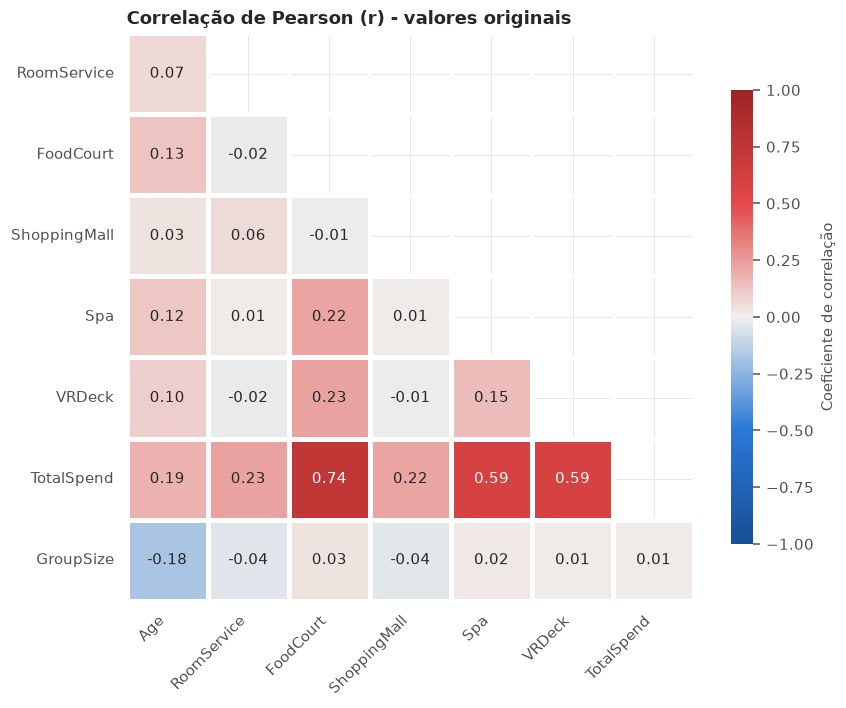

Figura exportada: report/figures/kan30_heatmap_pearson.png


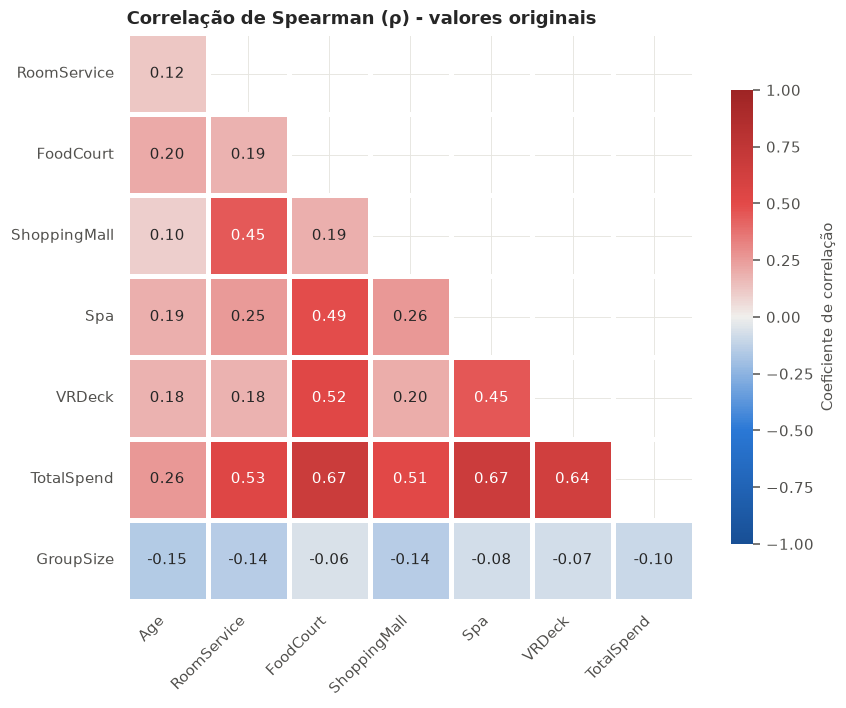

Figura exportada: report/figures/kan30_heatmap_spearman.png


In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    'azul_cinza_vermelho', ['#184f95', '#2a78d6', '#f0efec', '#e34948', '#9e2424']
)


def plot_corr_heatmap(corr, title, filename):
    """Desenha o triângulo inferior da matriz, anota os coeficientes e exporta em PNG."""
    # Remove a primeira linha e a última coluna, que ficariam vazias no triângulo inferior.
    lower = corr.iloc[1:, :-1]
    mask = np.triu(np.ones(lower.shape, dtype=bool), k=1)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(
        lower, mask=mask, annot=True, fmt='.2f', cmap=DIVERGING_CMAP,
        vmin=-1, vmax=1, center=0, square=True, linewidths=2, linecolor='white',
        cbar_kws={'label': 'Coeficiente de correlação', 'shrink': 0.8}, ax=ax,
    )
    ax.set_title(title, loc='left', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout()
    output = FIGURES_DIR / filename
    fig.savefig(output, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')


plot_corr_heatmap(pearson, 'Correlação de Pearson (r) - valores originais', 'kan30_heatmap_pearson.png')
plot_corr_heatmap(spearman, 'Correlação de Spearman (ρ) - valores originais', 'kan30_heatmap_spearman.png')

## 6. Verificação exploratória: Spearman só entre quem gastou

Na tabela de pares, o Spearman fica bem acima do Pearson entre os gastos (por exemplo, `RoomService` × `ShoppingMall`: r = 0,06 e ρ = 0,45). Como 41,9% dos passageiros têm todos os gastos zerados, é possível que os zeros que aparecem **juntos** influenciem esse ρ. Como verificação exploratória, recalculamos o Spearman entre os componentes apenas para os passageiros com `TotalSpend > 0`.

A **base completa continua sendo a análise principal**. Este subconjunto só ajuda a ler as matrizes acima e não as substitui.

In [62]:
spenders = df.loc[df['TotalSpend'] > 0, SPEND_COLUMNS]
spearman_spenders = spenders.corr(method='spearman')

comparison = pd.DataFrame({
    'rho_base_completa': spearman.loc[SPEND_COLUMNS, SPEND_COLUMNS].where(upper[1:6, 1:6]).stack(),
    'rho_so_quem_gastou': spearman_spenders.where(upper[1:6, 1:6]).stack(),
})
comparison.index.names = ['variável 1', 'variável 2']
print(f'Passageiros com TotalSpend > 0: {len(spenders):,} de {len(df):,}')
comparison.round(2).sort_values('rho_so_quem_gastou')

Passageiros com TotalSpend > 0: 5,049 de 8,693


rho_base_completa  rho_so_quem_gastou
variável 1   variável 2                                         
RoomService  FoodCourt                 0.190              -0.320
             VRDeck                    0.180              -0.310
FoodCourt    ShoppingMall              0.190              -0.290
ShoppingMall VRDeck                    0.200              -0.280
RoomService  Spa                       0.250              -0.240
ShoppingMall Spa                       0.260              -0.210
Spa          VRDeck                    0.450               0.110
RoomService  ShoppingMall              0.450               0.120
FoodCourt    Spa                       0.490               0.180
             VRDeck                    0.520               0.240
RoomService  RoomService                 NaN                 NaN
FoodCourt    RoomService                 NaN                 NaN
             FoodCourt                   NaN                 NaN
ShoppingMall RoomService                 NaN                 NaN
             FoodCourt                   NaN                 NaN
             ShoppingMall                NaN                 NaN
Spa          RoomService                 NaN                 NaN
             FoodCourt                   NaN                 NaN
             ShoppingMall                NaN                 NaN
             Spa                         NaN                 NaN
VRDeck       RoomService                 NaN                 NaN
             FoodCourt                   NaN                 NaN
             ShoppingMall                NaN                 NaN
             Spa                         NaN                 NaN
             VRDeck                      NaN                 NaN

### Interpretação dos resultados

**1. As correlações mais fortes são de cada gasto com `TotalSpend`.** Os maiores coeficientes da matriz são `FoodCourt` × `TotalSpend` (r = 0,74), `Spa` × `TotalSpend` (r = 0,59) e `VRDeck` × `TotalSpend` (r = 0,59). Esse resultado é esperado por construção, porque `TotalSpend` é a soma dos cinco gastos. Ele mostra quais serviços pesam mais no total, mas não é uma descoberta sobre o comportamento dos passageiros. `RoomService` e `ShoppingMall` contribuem menos (r ≈ 0,22-0,23).

**2. Entre os gastos, o Pearson é fraco.** Entre componentes diferentes, o maior r é 0,23 (`FoodCourt` × `VRDeck`), e vários pares ficam próximos de zero. Pela medida linear, gastar muito em um serviço pouco se associa a gastar muito em outro.

**3. O Spearman é bem maior, e há indícios de influência dos zeros.** Na base completa, o ρ entre os gastos chega a 0,45-0,52. Na verificação exploratória da seção 6, restrita aos 5.049 passageiros que gastaram algo, esses coeficientes ficam entre -0,32 e 0,24, e seis dos dez pares passam a ser negativos. Essa mudança é um **indício** de que a coincidência de zeros (por exemplo, passageiros em criossono não gastam em nenhum serviço) contribui para o ρ positivo da base completa. A análise não demonstra que essa seja a explicação principal, nem caracteriza perfis de consumo. Para isso seriam necessárias análises próprias.

**4. A idade e o tamanho do grupo têm associações fracas.** `Age` se correlaciona fracamente e de forma positiva com os gastos (r = 0,19 com `TotalSpend`). `Age` × `GroupSize` é a correlação negativa mais forte da base completa (r = -0,18 e ρ = -0,15). `GroupSize` praticamente não se relaciona com os gastos (|r| ≤ 0,04).

**5. Foco na magnitude.** O foco desta análise é a magnitude das associações, por isso não interpretamos p-valores.

**Implicações para as próximas etapas:**
- os diagramas de dispersão precisam preservar e deixar visíveis os zeros;
- `TotalSpend` não pode ser usado junto com os seus componentes em um mesmo modelo.

> Lembrete: todas são associações observacionais. Elas não indicam que um gasto cause o outro.

## 7. Diagramas de dispersão dos pares selecionados

### Critério de seleção

Selecionamos poucos pares, com regras definidas antes de olhar os gráficos e aplicadas às matrizes da **base completa**:

| Papel | Regra | Por que incluir |
|---|---|---|
| Relação com `TotalSpend` | maior \|r\| entre um componente e `TotalSpend` | mostra o componente que mais acompanha o total |
| Relação entre gastos | maior \|ρ\| entre dois componentes distintos | é o par em que Pearson e Spearman mais divergem, ou seja, onde os zeros podem pesar |
| Relação negativa | r mais negativo da matriz | mostra a principal associação inversa da base |

Como **verificação exploratória**, acrescentamos o par de ρ mais negativo no subconjunto `TotalSpend > 0` (seção 6), sempre identificado como tal.

### Como ler os gráficos
- O título informa a **população** de cada gráfico e o seu tamanho (n).
- Os eixos dos gastos usam `log1p(x) = log(1 + x)`. Essa transformação mantém o zero em 0 e comprime os valores altos. Ela é **só visual**: os coeficientes informados são os calculados nos valores originais.
- Os pontos com valor zero são preservados. Eles aparecem alinhados sobre os eixos, e a quantidade deles é informada no gráfico.
- `GroupSize` é discreta (1 a 8). Para os pontos não se sobreporem, aplicamos um pequeno deslocamento aleatório horizontal (*jitter*, semente 42), só no desenho, e marcamos a mediana de `Age` de cada tamanho de grupo.

In [63]:
component_pairs = pairs.loc[
    [(a, b) for a, b in pairs.index if a in SPEND_COLUMNS and b in SPEND_COLUMNS]
]
with_total = pairs.loc[[(a, b) for a, b in pairs.index if 'TotalSpend' in (a, b) and {a, b} <= set(SPEND_COLUMNS) | {'TotalSpend'}]]

selected = {
    'Relação com TotalSpend': with_total['pearson_r'].abs().idxmax(),
    'Relação entre gastos': component_pairs['spearman_rho'].abs().idxmax(),
    'Relação negativa': pairs['pearson_r'].idxmin(),
}
exploratory_pair = comparison['rho_so_quem_gastou'].idxmin()

for role, (a, b) in selected.items():
    print(f'{role:<24} {a} x {b}: r = {pairs.loc[(a, b), "pearson_r"]:.2f}, ρ = {pairs.loc[(a, b), "spearman_rho"]:.2f}')
a, b = exploratory_pair
print(f'{"Exploratório (gasto > 0)":<24} {a} x {b}: ρ = {comparison.loc[(a, b), "rho_so_quem_gastou"]:.2f}')

Relação com TotalSpend   FoodCourt x TotalSpend: r = 0.74, ρ = 0.67
Relação entre gastos     FoodCourt x VRDeck: r = 0.23, ρ = 0.52
Relação negativa         Age x GroupSize: r = -0.18, ρ = -0.15
Exploratório (gasto > 0) RoomService x FoodCourt: ρ = -0.32


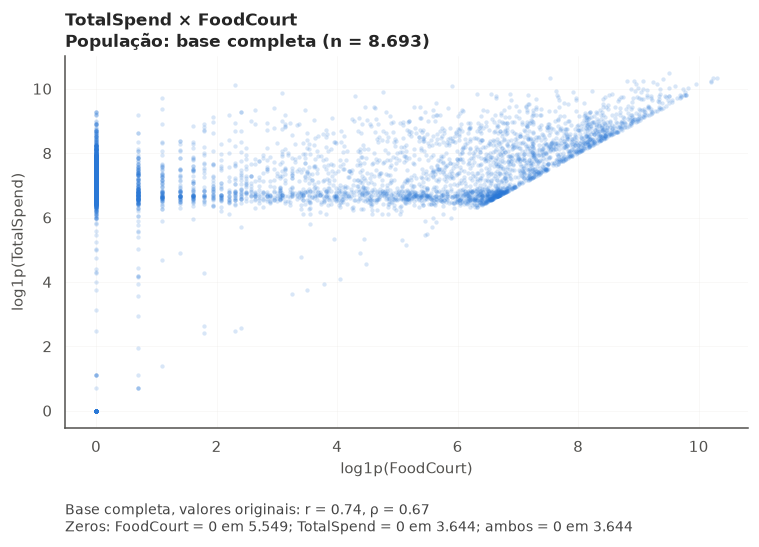

Figura exportada: report/figures/kan30_dispersao_total_TotalSpend_FoodCourt.png


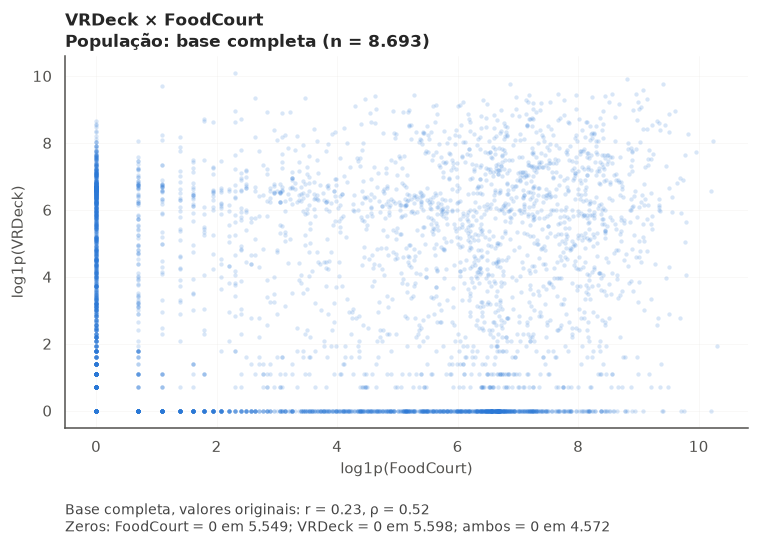

Figura exportada: report/figures/kan30_dispersao_gastos_VRDeck_FoodCourt.png


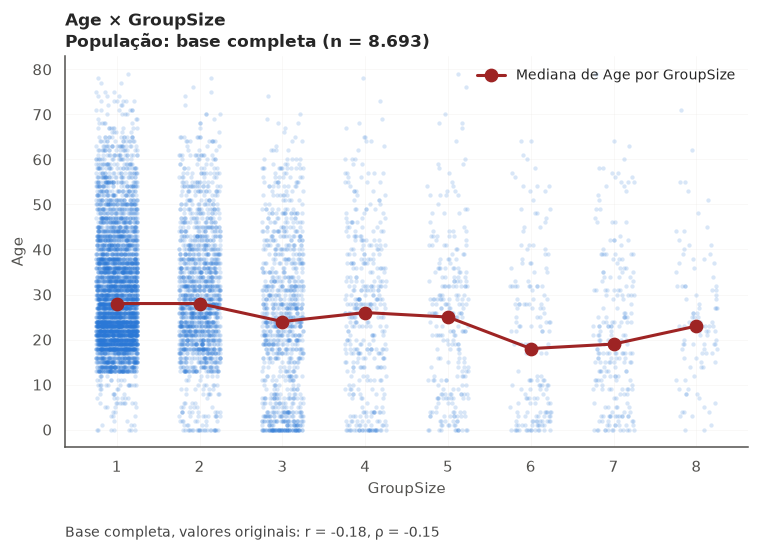

Figura exportada: report/figures/kan30_dispersao_negativa_Age_GroupSize.png


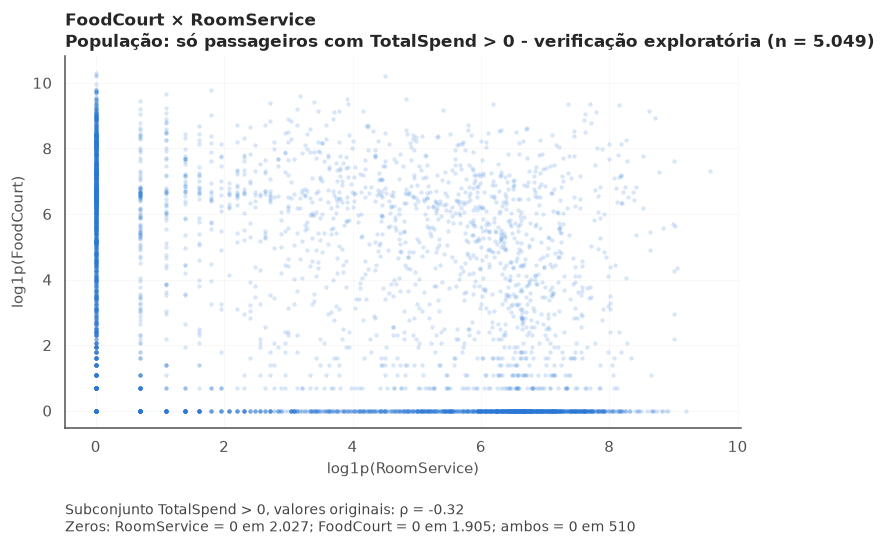

Figura exportada: report/figures/kan30_dispersao_exploratoria_FoodCourt_RoomService.png


In [64]:
POINT_COLOR = '#2a78d6'
MEDIAN_COLOR = '#9e2424'
rng = np.random.default_rng(SEED)


def fmt_int(n):
    """Inteiro com separador de milhar no padrão brasileiro (8.693)."""
    return f'{n:,}'.replace(',', '.')


def axis_values(series):
    """Gastos vão em log1p (zeros preservados em 0); demais variáveis ficam na escala original."""
    if series.name in SPEND_COLUMNS + ['TotalSpend']:
        return np.log1p(series), f'log1p({series.name})'
    return series, series.name


def plot_pair(data, x, y, population, filename, stats_text):
    """Dispersão de um par, com a população no título e os zeros contados no gráfico."""
    fig, ax = plt.subplots(figsize=(7, 5.2))
    xv, xlabel = axis_values(data[x])
    yv, ylabel = axis_values(data[y])
    if x == 'GroupSize':
        xv = xv + rng.uniform(-0.25, 0.25, size=len(xv))
    ax.scatter(xv, yv, s=8, alpha=0.18, color=POINT_COLOR, linewidths=0)

    if x == 'GroupSize':
        medians = data.groupby(x)[y].median()
        ax.plot(medians.index, medians.values, color=MEDIAN_COLOR, marker='o',
                markersize=8, linewidth=2, label=f'Mediana de {y} por {x}')
        ax.legend(loc='upper right', frameon=False)
        ax.set_xticks(medians.index)
        zero_text = ''
    else:
        x_zero, y_zero = data[x] == 0, data[y] == 0
        zero_text = (f'\nZeros: {x} = 0 em {fmt_int(x_zero.sum())}; {y} = 0 em {fmt_int(y_zero.sum())}; '
                     f'ambos = 0 em {fmt_int((x_zero & y_zero).sum())}')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{y} × {x}\nPopulação: {population} (n = {fmt_int(len(data))})',
                 loc='left', fontsize=11)
    ax.text(0.0, -0.2, stats_text + zero_text, transform=ax.transAxes,
            fontsize=9, color='#444444', va='top')
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    output = FIGURES_DIR / filename
    fig.savefig(output, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')


def coefficients_text(a, b):
    return (f'Base completa, valores originais: r = {pairs.loc[(a, b), "pearson_r"]:.2f}, '
            f'ρ = {pairs.loc[(a, b), "spearman_rho"]:.2f}')


for (a, b), slug in zip(selected.values(), ['total', 'gastos', 'negativa']):
    # A variável de menor escala ou discreta vai no eixo x.
    x, y = (b, a) if b == 'GroupSize' else (a, b)
    plot_pair(df, x, y, 'base completa', f'kan30_dispersao_{slug}_{y}_{x}.png', coefficients_text(a, b))

a, b = exploratory_pair
plot_pair(
    spenders, a, b, 'só passageiros com TotalSpend > 0 - verificação exploratória',
    f'kan30_dispersao_exploratoria_{b}_{a}.png',
    f'Subconjunto TotalSpend > 0, valores originais: ρ = {comparison.loc[(a, b), "rho_so_quem_gastou"]:.2f}',
)

### Interpretação dos diagramas

**`TotalSpend` × `FoodCourt` (base completa).** A associação é a mais forte da matriz (r = 0,74; ρ = 0,67), mas uma parte dela vem da construção da variável: como `TotalSpend` inclui `FoodCourt`, nenhum ponto fica abaixo da diagonal, onde `TotalSpend` seria menor que `FoodCourt`. Os 3.644 passageiros sem nenhum gasto aparecem no ponto (0, 0). Há também uma coluna em `FoodCourt = 0` com `TotalSpend` positivo, de quem gastou só em outros serviços. Por isso o gráfico mostra a contribuição do `FoodCourt` ao total, e não uma relação entre comportamentos independentes.

**`VRDeck` × `FoodCourt` (base completa).** Os 4.572 passageiros com os dois gastos zerados ficam concentrados na origem, e muitos outros aparecem sobre os eixos, gastando em só um dos dois serviços. Entre os pontos fora dos eixos, a nuvem é dispersa e não mostra uma tendência linear clara. O gráfico é coerente com a diferença entre r = 0,23 e ρ = 0,52: o ρ maior pode estar sendo influenciado pela quantidade de zeros que coincidem, mas o gráfico sozinho não permite atribuir a diferença a essa causa.

**`Age` × `GroupSize` (base completa).** É a correlação negativa mais forte da base, mas fraca (r = -0,18; ρ = -0,15). A mediana de idade é de 28 anos nos grupos de 1 ou 2 pessoas e de 18-19 anos nos grupos de 6 e 7, mas a tendência não é monotônica: o grupo de 8 tem mediana de 23. Os grupos maiores também mostram mais passageiros com idades muito baixas, inclusive `Age = 0`. A variação dentro de cada tamanho de grupo é grande, o que é coerente com uma correlação fraca.

**`FoodCourt` × `RoomService` (só `TotalSpend > 0`, exploratório).** Neste subconjunto o ρ é negativo (-0,32), e o gráfico mostra muitos passageiros que gastam em um dos dois serviços e não no outro, sobre os eixos. Esse padrão serve apenas para entender por que o coeficiente muda em relação à base completa. Ele não caracteriza perfis de consumo e não substitui a análise principal.

**Sobre a escala.** Todos os eixos de gasto usam `log1p` apenas para a visualização. Os coeficientes citados são os calculados nos valores originais, e os zeros foram mantidos em todos os gráficos.

### 7.1 Pairplot compacto

O pairplot reúne, em uma única figura, as dispersões de todos os pares de um pequeno conjunto de variáveis, com a distribuição de cada uma na diagonal. Ele complementa os gráficos dedicados acima, sem substituí-los.

- **Variáveis:** `Age`, `FoodCourt`, `VRDeck` e `TotalSpend`, que já foram analisadas nas seções anteriores e compõem os pares selecionados de relação com `TotalSpend` e de relação entre gastos. `GroupSize` fica de fora porque é discreta (1 a 8) e já aparece no gráfico dedicado com *jitter*.
- **População:** base completa (n = 8.693).
- **Eixos:** os gastos aparecem em `log1p` (só para a visualização, com os zeros preservados em 0), e `Age` fica na escala original. A transformação está indicada no nome de cada eixo.
- O pairplot mostra só o triângulo inferior, porque o superior repetiria os mesmos pares espelhados.

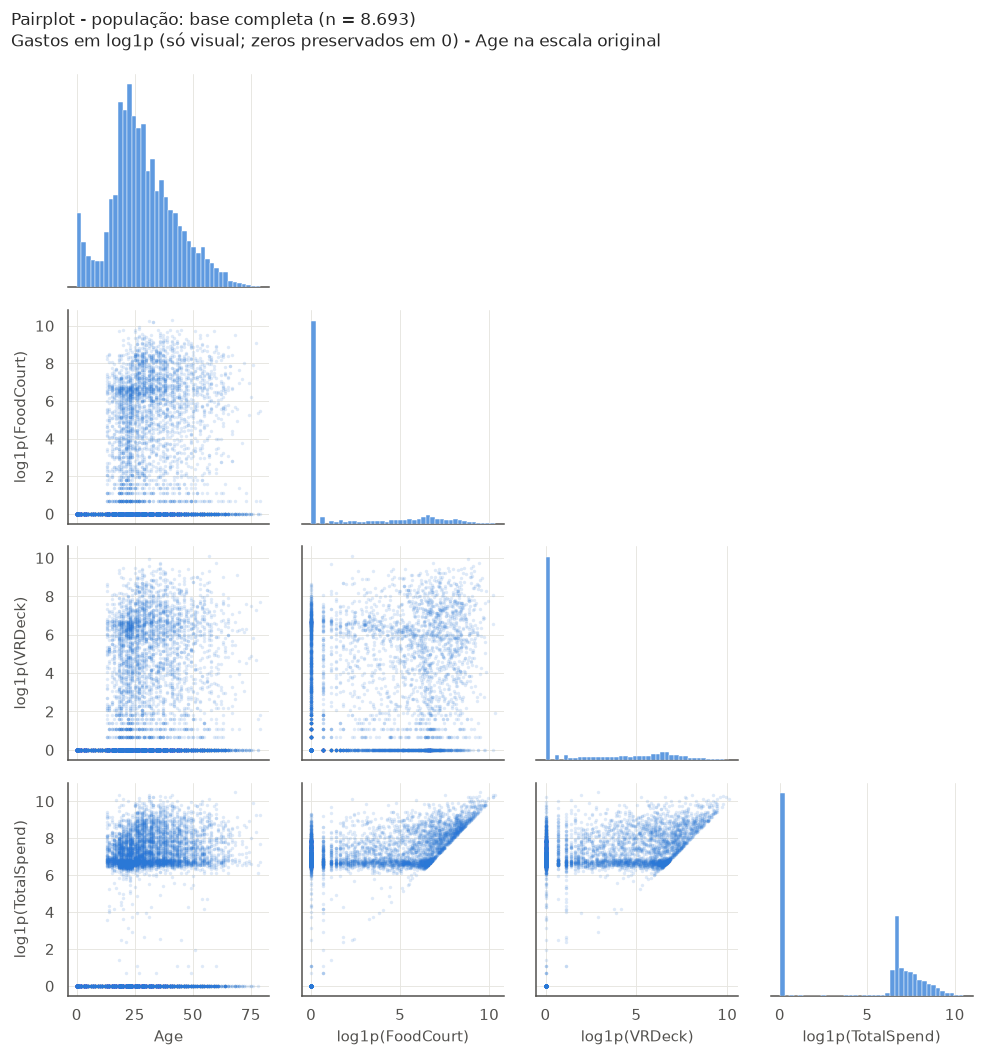

Figura exportada: report/figures/kan30_pairplot.png


In [65]:
PAIRPLOT_COLUMNS = ['Age', 'FoodCourt', 'VRDeck', 'TotalSpend']

pair_data = pd.DataFrame()
for column in PAIRPLOT_COLUMNS:
    values, label = axis_values(df[column])
    pair_data[label] = values

# PairGrid permite escalas verticais independentes nos histogramas da diagonal.
grid = sns.PairGrid(pair_data, corner=True, diag_sharey=False, height=2.3)
grid.map_diag(sns.histplot, color=POINT_COLOR, bins=40)
grid.map_lower(sns.scatterplot, s=5, alpha=0.15, color=POINT_COLOR, linewidth=0)
grid.figure.suptitle(
    f'Pairplot - população: base completa (n = {fmt_int(len(df))})\n'
    'Gastos em log1p (só visual; zeros preservados em 0) - Age na escala original',
    x=0.02, y=1.04, ha='left', fontsize=11,
)
output = FIGURES_DIR / 'kan30_pairplot.png'
grid.figure.savefig(output, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')

**Interpretação.** O pairplot reproduz, em conjunto, os padrões já descritos nos gráficos dedicados:
- **Diagonal:** a barra em 0 domina os histogramas de `FoodCourt` e `VRDeck` e responde por 41,9% do `TotalSpend`, o que confirma a massa de zeros que motivou o uso do Spearman e do `log1p`. A distribuição de `Age` tem um pico em 0 e se concentra entre 18 e 40 anos.
- **`Age` × gastos:** nenhum dos 806 passageiros com menos de 13 anos tem gasto registrado, todos aparecem na linha do zero. Acima dessa idade, a nuvem é dispersa, o que é coerente com a correlação fraca entre `Age` e `TotalSpend` (r = 0,19).
- **Gastos × `TotalSpend`:** a borda diagonal aparece de novo, por construção, já que o total inclui cada componente.
- **`FoodCourt` × `VRDeck`:** a nuvem dispersa e os pontos sobre os eixos são os mesmos do gráfico dedicado.

Os coeficientes de referência continuam sendo os das matrizes da seção 4, calculados nos valores originais. O `log1p` é apenas visual.

## 8. Multicolinearidade entre as preditoras do KAN-31

A **multicolinearidade** acontece quando uma preditora pode ser bem explicada pelas outras. Ela não enviesa as previsões de uma regressão linear, mas aumenta a variância dos coeficientes estimados, o que pode torná-los instáveis e difíceis de interpretar individualmente.

O **VIF** (*Variance Inflation Factor*) de uma coluna *j* é calculado regredindo essa coluna sobre todas as outras colunas da matriz de desenho, com intercepto, e aplicando:

$$\mathrm{VIF}_j = \frac{1}{1 - R^2_j}$$

Um VIF igual a 1 indica que a coluna não tem relação linear com as demais. Um VIF de 5 indica que a variância do coeficiente está 5 vezes maior do que seria sem essa sobreposição.

**Escopo desta seção:**
- as preditoras são as previstas no KAN-31: `Age`, `HomePlanet`, `CabinDeck`, `VIP` e `GroupSize`;
- `TotalSpend` é a variável resposta e **não** entra no cálculo, porque o VIF olha apenas para as preditoras;
- nenhuma regressão de `TotalSpend` é ajustada aqui;
- nenhuma variável é excluída automaticamente por ultrapassar um limite de VIF. Os resultados servem de subsídio para as decisões do KAN-31.

### 8.1 Codificação das variáveis categóricas

As variáveis categóricas entram como variáveis indicadoras (*dummies*), com uma **categoria de referência** omitida para evitar a dependência linear perfeita com o intercepto:

| Variável | Referência | Por quê |
|---|---|---|
| `HomePlanet` | `Earth` | categoria mais frequente |
| `CabinDeck` | `F` | categoria mais frequente |
| `VIP` | `False` | ausência da característica |

O intercepto entra na matriz de desenho porque o modelo do KAN-31 terá intercepto, e sem ele os R² auxiliares ficariam incorretos. O intercepto **não recebe VIF** e não é interpretado como preditora.

In [66]:
PREDICTORS = ['Age', 'HomePlanet', 'CabinDeck', 'VIP', 'GroupSize']
REFERENCE = {'HomePlanet': 'Earth', 'CabinDeck': 'F', 'VIP': False}

X_parts = [df[['Age', 'GroupSize']].astype(float)]
term_columns = {'Age': ['Age'], 'GroupSize': ['GroupSize']}
for var, ref in REFERENCE.items():
    levels = [lvl for lvl in sorted(df[var].unique(), key=str) if lvl != ref]
    dummies = pd.DataFrame({f'{var}_{lvl}': (df[var] == lvl).astype(float) for lvl in levels})
    X_parts.append(dummies)
    term_columns[var] = list(dummies.columns)

assert set(term_columns) == set(PREDICTORS), 'Todas as preditoras previstas devem estar codificadas.'

X = pd.concat(X_parts, axis=1)
X.insert(0, 'const', 1.0)

rank = np.linalg.matrix_rank(X.values)
print(f'Matriz de desenho: {X.shape[0]:,} linhas x {X.shape[1]} colunas (incluindo o intercepto); posto = {rank}')
if rank < X.shape[1]:
    raise ValueError('A matriz de desenho tem dependência linear perfeita; revise a codificação.')
print('Colunas:', ', '.join(X.columns))

Matriz de desenho: 8,693 linhas x 13 colunas (incluindo o intercepto); posto = 13
Colunas: const, Age, GroupSize, HomePlanet_Europa, HomePlanet_Mars, CabinDeck_A, CabinDeck_B, CabinDeck_C, CabinDeck_D, CabinDeck_E, CabinDeck_G, CabinDeck_T, VIP_True


### 8.2 VIF por coluna e GVIF por variável

As duas medidas olham para objetos diferentes:

- **VIF por coluna.** É calculado para cada coluna da matriz de desenho, exceto o intercepto, pela fórmula da seção 8. No caso de uma categórica, cada *dummy* recebe o seu próprio VIF, e esse valor **depende da categoria de referência**: trocar a referência muda as colunas e, com elas, os VIFs.
- **GVIF por variável.** O VIF generalizado (Fox e Monette, 1992) trata o conjunto de colunas de uma variável como um bloco único e **não depende da categoria de referência**:

$$\mathrm{GVIF} = \frac{\det(R_{11})\,\det(R_{22})}{\det(R)}$$

Nessa fórmula, *R* é a matriz de correlação de todas as colunas exceto o intercepto, *R₁₁* é o bloco das colunas da variável e *R₂₂* é o bloco das demais colunas.

**Ajuste pelo número de colunas.** O GVIF de uma variável com *df* colunas não é comparável diretamente ao de uma variável com uma única coluna. Por isso usamos dois ajustes:

$$\mathrm{GVIF}_{\text{ajustado}} = \mathrm{GVIF}^{1/(2\,df)} \qquad\qquad \left(\mathrm{GVIF}^{1/(2\,df)}\right)^2 = \mathrm{GVIF}^{1/df}$$

- O primeiro, GVIF^(1/(2·df)), está na escala do **erro-padrão**, ou seja, da raiz do VIF. É ele que permite comparar variáveis com números diferentes de colunas.
- O segundo, GVIF^(1/df), está na escala de um VIF comum. Na tabela abaixo aparece como **"equivalente a VIF"**.

Para uma variável de uma só coluna (*df* = 1), GVIF = VIF e GVIF^(1/df) = VIF.

In [67]:
def vif_by_column(design):
    """VIF de cada coluna (exceto o intercepto), via regressão auxiliar com intercepto."""
    values = design.values
    result = {}
    for j, col in enumerate(design.columns):
        if col == 'const':
            continue
        y_j = values[:, j]
        others = np.delete(values, j, axis=1)
        beta, *_ = np.linalg.lstsq(others, y_j, rcond=None)
        resid = y_j - others @ beta
        r2 = 1 - resid @ resid / ((y_j - y_j.mean()) @ (y_j - y_j.mean()))
        result[col] = 1 / (1 - r2)
    return pd.Series(result, name='VIF')


vif_columns = vif_by_column(X)
column_table = pd.DataFrame({
    'VIF': vif_columns,
    'n na categoria': X.drop(columns='const').sum().where(lambda s: s.index.str.contains('_')).astype('Int64'),
})
column_table.round(2)

,VIF,n na categoria
Age,1.130,<NA>
GroupSize,1.090,<NA>
HomePlanet_Europa,7.990,2174
HomePlanet_Mars,1.620,1804
CabinDeck_A,2.210,262
CabinDeck_B,4.440,817
CabinDeck_C,4.240,761
CabinDeck_D,1.550,507
CabinDeck_E,1.260,885
CabinDeck_G,1.700,2588


In [68]:
R = X.drop(columns='const').corr().values
cols = list(X.drop(columns='const').columns)
det_R = np.linalg.det(R)

gvif_rows = []
for var, var_cols in term_columns.items():
    idx = [cols.index(c) for c in var_cols]
    rest = [i for i in range(len(cols)) if i not in idx]
    gvif = np.linalg.det(R[np.ix_(idx, idx)]) * np.linalg.det(R[np.ix_(rest, rest)]) / det_R
    gvif_rows.append({
        'variável': var,
        'df': len(var_cols),
        'GVIF': gvif,
        'GVIF^(1/(2df))': gvif ** (1 / (2 * len(var_cols))),
        'equivalente a VIF': gvif ** (1 / len(var_cols)),
    })

gvif_table = pd.DataFrame(gvif_rows).set_index('variável').sort_values('equivalente a VIF', ascending=False)
gvif_table.round(2)

,df,GVIF,GVIF^(1/(2df)),equivalente a VIF
variável,,,,
HomePlanet,2,10.340,1.790,3.220
CabinDeck,7,10.700,1.180,1.400
Age,1,1.130,1.060,1.130
GroupSize,1,1.090,1.040,1.090
VIP,1,1.050,1.020,1.050


### 8.3 De onde vem a sobreposição

Para entender os valores acima, cruzamos as duas variáveis categóricas. A tabela descreve as preditoras e não é uma nova análise de associação.

In [69]:
pd.crosstab(df['CabinDeck'], df['HomePlanet'], margins=True, margins_name='Total')

HomePlanet,Earth,Europa,Mars,Total
CabinDeck,,,,
A,0,262,0,262
B,0,817,0,817
C,0,761,0,761
D,1,195,311,507
E,407,134,344,885
F,1719,0,1149,2868
G,2588,0,0,2588
T,0,5,0,5
Total,4715,2174,1804,8693


### Interpretação

**`Age`, `GroupSize` e `VIP`: pouca evidência de multicolinearidade.** Os VIFs ficam entre 1,05 e 1,13. A parte de cada uma dessas variáveis explicada linearmente pelas demais preditoras é pequena (R² auxiliar entre 0,05 e 0,12).

**`HomePlanet` e `CabinDeck`: sobreposição moderada entre si.**
- GVIF: 10,34 para `HomePlanet` (*df* = 2) e 10,70 para `CabinDeck` (*df* = 7).
- Ajustados pelo número de colunas, GVIF^(1/(2·df)) dá 1,79 e 1,18, respectivamente. Na escala de um VIF comum (GVIF^(1/df)), isso equivale a 3,22 e 1,40.
- Entre as colunas, o maior VIF é o de `HomePlanet_Europa` (7,99), seguido de `CabinDeck_B` (4,44) e `CabinDeck_C` (4,24). Esses valores dependem das referências escolhidas (`Earth` e `F`).

A tabela cruzada mostra a origem da sobreposição: os decks A, B, C e T só têm passageiros de Europa, e o deck G só tem passageiros de Earth. Parte da informação de uma variável, portanto, já está na outra. Na regressão do KAN-31, isso pode tornar **difícil interpretar separadamente** os coeficientes de `HomePlanet` e de `CabinDeck`. O impacto concreto só poderá ser avaliado quando o modelo for ajustado.

**Nenhuma variável foi excluída.** Os limites usuais (VIF de 5 ou de 10) são convenções, e não regras estatísticas. A decisão fica para o KAN-31, que pode, por exemplo, manter as duas variáveis e interpretá-las em conjunto, usar só uma delas ou agrupar decks. Cada opção muda a pergunta que o modelo responde.

**Limitações:**
- O VIF de cada *dummy* depende da categoria de referência. O GVIF da variável inteira não depende dela.
- `CabinDeck_T` tem só 5 passageiros. O VIF baixo (1,02) não indica um coeficiente confiável: com tão poucas observações, a estimativa tende a ser imprecisa por escassez de dados, e não por colinearidade.
- O VIF mede apenas dependência **linear** entre as preditoras. Ele não diz nada sobre a relação delas com `TotalSpend`, nem considera interações que o KAN-31 venha a incluir.
- O cálculo usa a base completa (n = 8.693), com a codificação descrita acima. Mudanças nas preditoras ou na codificação exigem recalcular.

## 9. Síntese

**Correlações (base completa, valores originais).**
- As correlações mais fortes são de cada gasto com `TotalSpend`. A maior é a de `FoodCourt` (r = 0,74; ρ = 0,67), em parte por construção, já que `TotalSpend` é a soma dos gastos.
- Entre os componentes do gasto, o Pearson é fraco (no máximo r = 0,23).
- O Spearman entre os componentes é maior (até ρ = 0,52). Na verificação exploratória restrita a `TotalSpend > 0`, esses coeficientes ficam entre -0,32 e 0,24, o que é um indício de que os zeros coincidentes influenciam o ρ da base completa. A análise não demonstra a explicação.
- A relação negativa mais forte é `Age` × `GroupSize` (r = -0,18), que é fraca.

**Dispersões.** Foram produzidos quatro gráficos, selecionados por critério explícito. Três são da base completa (relação com `TotalSpend`, relação entre gastos e relação negativa) e um é exploratório, do subconjunto `TotalSpend > 0`. Um pairplot compacto (`Age`, `FoodCourt`, `VRDeck` e `TotalSpend`, base completa) reúne esses pares em uma única figura. Todos os gráficos usam `log1p` só na visualização dos gastos e mantêm os zeros.

**Multicolinearidade das preditoras do KAN-31.**
- `Age`, `GroupSize` e `VIP` mostram pouca evidência de multicolinearidade.
- `HomePlanet` e `CabinDeck` se sobrepõem, porque vários decks pertencem a um único planeta. Isso pode dificultar a interpretação separada dos seus coeficientes no KAN-31.
- Nenhuma variável foi excluída.

**Pontos de atenção para o KAN-31:**
- não usar `TotalSpend` junto com os seus componentes em um mesmo modelo;
- decidir como tratar a sobreposição entre `HomePlanet` e `CabinDeck`;
- levar em conta que o deck T tem só 5 passageiros.

**Limitações gerais.** Todas as associações são observacionais e não indicam causalidade. A interpretação prioriza a magnitude dos coeficientes. O `log1p` é apenas visual. O subconjunto `TotalSpend > 0` é exploratório e não substitui a análise principal.

In [70]:
exported = sorted(p.name for p in FIGURES_DIR.glob('kan30_*.png'))
print(f'{len(exported)} figuras do KAN-30 em {FIGURES_DIR.relative_to(PROJECT_ROOT).as_posix()}/:')
for name in exported:
    print(f'  - {name}')

7 figuras do KAN-30 em report/figures/:
  - kan30_dispersao_exploratoria_FoodCourt_RoomService.png
  - kan30_dispersao_gastos_VRDeck_FoodCourt.png
  - kan30_dispersao_negativa_Age_GroupSize.png
  - kan30_dispersao_total_TotalSpend_FoodCourt.png
  - kan30_heatmap_pearson.png
  - kan30_heatmap_spearman.png
  - kan30_pairplot.png


## 10. KAN-32 - Linha de base para a classificação de `Transported`

- **Responsável:** Renatta
- **Revisor:** Gustavo

**Objetivo.** Estabelecer uma referência mínima de desempenho para prever se um passageiro foi transportado (`Transported`). A referência é dada por classificadores ingênuos, que **ignoram todas as variáveis explicativas**. Um modelo preditivo, como a regressão logística do KAN-33, só agrega valor se superar essa linha de base nas mesmas condições de avaliação.

### 10.1 Divisão treino/teste

Seguindo o card, dividimos a base tratada em **80% para treino e 20% para teste**:
- `random_state=42` torna a divisão reprodutível;
- `stratify=y` mantém a mesma proporção de passageiros transportados nos dois conjuntos.

Regras para evitar vazamento de informação:
- tudo o que um modelo **aprende** (inclusive a proporção de classes usada pelos baselines) vem **apenas do treino**;
- o conjunto de teste é usado só na avaliação final.

**Esta divisão é a referência para os próximos modelos.** `X_train`, `X_test`, `y_train` e `y_test` são definidos uma única vez aqui e devem ser reutilizados pelos tickets seguintes (KAN-33 e KAN-34), para que as comparações sejam feitas no mesmo conjunto de teste. `X` guarda todas as colunas, exceto o alvo. A escolha das preditoras e o seu pré-processamento ficam com cada modelo, ajustados apenas no treino.

In [71]:
from sklearn.model_selection import train_test_split

TARGET = 'Transported'
TEST_SIZE = 0.20

y = df[TARGET]
X = df.drop(columns=[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=42, stratify=y
)

# Verificações da divisão: tamanhos, ausência de sobreposição e proporções estratificadas.
assert len(X_train) + len(X_test) == len(df)
assert set(X_train['PassengerId']).isdisjoint(X_test['PassengerId'])

split_summary = pd.DataFrame({
    'n': [len(y), len(y_train), len(y_test)],
    '% do total': [100.0, len(y_train) / len(y) * 100, len(y_test) / len(y) * 100],
    '% Transported = True': [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=['base completa', 'treino', 'teste']).round(2)
split_summary

,n,% do total,% Transported = True
base completa,8693,100.000,50.360
treino,6954,80.000,50.360
teste,1739,20.000,50.370


**Interpretação.** A divisão ficou com 6.954 passageiros no treino (80%) e 1.739 no teste (20%), sem nenhum passageiro nos dois conjuntos. A estratificação funcionou: a proporção de transportados é praticamente a mesma na base completa (50,36%), no treino (50,36%) e no teste (50,37%).

As classes são quase **balanceadas**. Isso já antecipa uma referência importante: prever sempre a classe majoritária deve acertar cerca de metade dos casos. Um modelo útil precisa ficar claramente acima disso.

**Limitação registrada.** A divisão é feita por passageiro, como pede o card, e não por grupo de viagem (`Group`). Passageiros do mesmo grupo podem ficar em conjuntos diferentes. Para os baselines isso não importa, porque eles ignoram as variáveis. Já um modelo que use informações do grupo pode ter um desempenho no teste ligeiramente otimista, ponto que vale considerar no KAN-33 e no KAN-34.

### 10.2 Classificadores de linha de base

Usamos o `DummyClassifier` do scikit-learn com duas estratégias:

| Estratégia | Regra de decisão | O que aprende do treino |
|---|---|---|
| `most_frequent` | prevê sempre a classe mais frequente do treino | qual é a classe majoritária |
| `stratified` | sorteia cada previsão com as proporções de classe do treino | a proporção de cada classe |

Os dois ignoram as variáveis explicativas: `X_train` é passado só porque a interface do scikit-learn exige. O ajuste usa **apenas o treino**, e o `stratified` recebe `random_state=42` para que os sorteios sejam reprodutíveis.

**Métricas no teste**, com `Transported = True` como classe positiva:
- **acurácia, precisão, recall e F1** vêm das previsões de classe (`predict`);
- **ROC-AUC** vem das probabilidades da classe positiva (`predict_proba`). A coluna da classe positiva é localizada em `classes_`, para não depender da ordem das colunas;
- a precisão fica indefinida quando o modelo não prevê nenhum positivo, e o F1 também nesse caso, se o recall for zero. Nessas situações usamos `zero_division=0` **explicitamente** e informamos o número de previsões positivas, para que um zero não seja confundido com desempenho medido.

In [72]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)

POSITIVE_CLASS = True

baselines = {
    'most_frequent': DummyClassifier(strategy='most_frequent'),
    'stratified': DummyClassifier(strategy='stratified', random_state=42),
}

metric_rows = {}
confusion_tables = {}
for name, model in baselines.items():
    model.fit(X_train, y_train)  # aprende apenas a distribuição de classes do treino
    y_pred = model.predict(X_test)
    positive_col = list(model.classes_).index(POSITIVE_CLASS)
    y_score = model.predict_proba(X_test)[:, positive_col]

    n_pred_pos = int((y_pred == POSITIVE_CLASS).sum())
    metric_rows[name] = {
        'acurácia': accuracy_score(y_test, y_pred),
        'precisão': precision_score(y_test, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        'recall': recall_score(y_test, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        'F1': f1_score(y_test, y_pred, pos_label=POSITIVE_CLASS, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'previsões positivas': n_pred_pos,
        'precisão definida': n_pred_pos > 0,
    }
    confusion_tables[name] = pd.DataFrame(
        confusion_matrix(y_test, y_pred, labels=[False, True]),
        index=['real: False', 'real: True'],
        columns=['previsto: False', 'previsto: True'],
    )

print('Classe majoritária aprendida no treino (most_frequent):', baselines['most_frequent'].classes_[
    baselines['most_frequent'].class_prior_.argmax()])
print('Proporções aprendidas no treino:', dict(zip(baselines['stratified'].classes_,
                                                   baselines['stratified'].class_prior_.round(4))))

baseline_metrics = pd.DataFrame(metric_rows).T
baseline_metrics[['acurácia', 'precisão', 'recall', 'F1', 'ROC-AUC']] = (
    baseline_metrics[['acurácia', 'precisão', 'recall', 'F1', 'ROC-AUC']].astype(float).round(4)
)
baseline_metrics

Classe majoritária aprendida no treino (most_frequent): True
Proporções aprendidas no treino: {np.False_: np.float64(0.4964), np.True_: np.float64(0.5036)}


,acurácia,precisão,recall,F1,ROC-AUC,previsões positivas,precisão definida
most_frequent,0.504,0.504,1.000,0.670,0.500,1739,True
stratified,0.524,0.528,0.523,0.525,0.524,868,True


**Matrizes de confusão no teste.** As linhas mostram a classe real, e as colunas, a classe prevista.

In [73]:
for name, table in confusion_tables.items():
    print(f'{name} (n = {fmt_int(int(table.values.sum()))})')
    print(table.to_string(), end='\n\n')

most_frequent (n = 1.739)


             previsto: False  previsto: True
real: False                0             863
real: True                 0             876

stratified (n = 1.739)
             previsto: False  previsto: True
real: False              453             410
real: True               418             458



**Interpretação.**

**`most_frequent`.** A classe majoritária aprendida no treino é `True` (50,36%), e o modelo prevê `True` para todos os 1.739 passageiros do teste. Por isso:
- o recall é 1,0, porque nenhum transportado é perdido;
- a acurácia e a precisão (0,5037) são simplesmente a proporção de transportados no teste;
- o F1 de 0,67 é alto só porque o recall é máximo, e não por haver alguma discriminação;
- a probabilidade atribuída à classe positiva é a mesma para todos os passageiros, então o modelo não ordena ninguém, e o ROC-AUC é exatamente 0,5.

Como houve previsões positivas, a precisão é definida e o `zero_division` não precisou ser acionado.

**`stratified`.** Os sorteios seguem as proporções do treino e produzem 868 previsões positivas. As métricas ficam próximas do acaso: acurácia de 0,5239, precisão de 0,5276, recall de 0,5228, F1 de 0,5252 e ROC-AUC de 0,5239.
- Nessa estratégia, o `predict_proba` devolve apenas 0 ou 1, ou seja, o resultado de cada sorteio, coerente com o `predict`. Por isso o ROC-AUC é calculado sobre uma pontuação binária e coincide com a média dos recalls das duas classes (453/863 e 458/876).
- Os valores um pouco acima de 0,5 refletem **um único sorteio** (`random_state=42`). Com outra semente, eles variariam em torno de 0,5, já que o modelo não usa nenhuma informação dos passageiros.

**Como usar esta referência.** Os dois baselines delimitam o que se obtém **sem informação**: cerca de 50% de acurácia e ROC-AUC próximo de 0,5. Cada métrica deve ser comparada com o baseline adequado:
- o F1 de 0,67 do `most_frequent` mostra que um F1 alto não basta, se vier de prever sempre a mesma classe;
- o ROC-AUC de 0,5 é o piso para avaliar a capacidade de ordenação.

Os resultados foram registrados como observados. Nenhuma escolha (estratégia, semente ou métrica) foi ajustada com base no desempenho no teste.

### 10.3 Síntese do KAN-32

- **Divisão de referência:** 80% treino (6.954) e 20% teste (1.739), com `random_state=42` e `stratify=y`. A proporção de transportados é de 50,36% no treino e de 50,37% no teste. `X_train`, `X_test`, `y_train` e `y_test` devem ser reutilizados nos próximos modelos.
- **Baselines (ajustados só no treino, avaliados no teste, com `Transported = True` como classe positiva):**

| Estratégia | Acurácia | Precisão | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| `most_frequent` | 0,5037 | 0,5037 | 1,0000 | 0,6700 | 0,5000 |
| `stratified` | 0,5239 | 0,5276 | 0,5228 | 0,5252 | 0,5239 |

- **Leitura:** sem usar nenhuma informação dos passageiros, a acurácia fica em torno de 50% e o ROC-AUC fica próximo de 0,5. O F1 de 0,67 do `most_frequent` vem apenas do recall máximo, por prever todos como transportados. Os valores do `stratified` refletem um único sorteio e variariam em torno de 0,5 com outra semente.
- **Critério para o KAN-33:** um modelo agrega valor se superar esses valores **no mesmo conjunto de teste**, principalmente em acurácia, F1 e ROC-AUC, e não apenas em uma métrica que um baseline já maximiza (como o recall).
- **Limitação:** a divisão é por passageiro, e não por grupo de viagem. Modelos que usem informações do grupo podem ter uma avaliação ligeiramente otimista.

## 11. KAN-31 - Regressão linear para `TotalSpend`

- **Responsável:** Renatta
- **Revisor:** Gustavo

**Objetivo.** Modelar o gasto total a bordo (`TotalSpend`) em função de características do passageiro (`Age`, `HomePlanet`, `CabinDeck`, `VIP` e `GroupSize`), por regressão linear múltipla (OLS), e entender quais fatores se associam a gastos maiores ou menores. Os coeficientes descrevem **associações** condicionais às demais preditoras, e não efeitos causais.

### 11.1 Divisão treino/teste da regressão e matriz de desenho

**Divisão própria.** A divisão do KAN-32 foi estratificada por `Transported`, que é a resposta de outra pergunta. Para a regressão, fazemos uma divisão independente: 80% treino e 20% teste, com `random_state=42` e **sem estratificação**. O modelo é ajustado e diagnosticado no treino, e o teste serve só para medir o erro de previsão (RMSE) em passageiros que o modelo não viu.

**Codificação aprendida apenas no treino.**
- As categorias de `HomePlanet`, `CabinDeck` e `VIP` e as categorias de referência são definidas **com base no treino**.
- A referência é a categoria mais frequente no treino. Para `VIP`, é `False` (ausência da característica). É o mesmo critério usado no diagnóstico de multicolinearidade do KAN-30.
- A mesma codificação é então aplicada ao teste. O código verifica se o teste não tem categorias desconhecidas, para que nada do teste influencie a preparação.
- `Age` e `GroupSize` entram na escala original. Nenhuma padronização é aprendida.

In [74]:
REG_PREDICTORS = ['Age', 'HomePlanet', 'CabinDeck', 'VIP', 'GroupSize']
REG_NUMERIC = ['Age', 'GroupSize']
REG_CATEGORICAL = ['HomePlanet', 'CabinDeck', 'VIP']
REG_TARGET = 'TotalSpend'

reg_train, reg_test = train_test_split(df[REG_PREDICTORS + [REG_TARGET]], test_size=0.20, random_state=42)

# Categorias e referências aprendidas só no treino.
reg_levels = {}
for var in REG_CATEGORICAL:
    counts = reg_train[var].value_counts()
    reference = False if var == 'VIP' else counts.idxmax()
    reg_levels[var] = {'referência': reference,
                       'demais': [lvl for lvl in sorted(counts.index, key=str) if lvl != reference]}
    unseen = set(reg_test[var]) - set(counts.index)
    if unseen:
        raise ValueError(f'{var}: categorias do teste ausentes no treino: {unseen}')


def make_design(data):
    """Matriz de desenho com intercepto, numéricas na escala original e dummies das categorias do treino."""
    parts = [pd.Series(1.0, index=data.index, name='const'), data[REG_NUMERIC].astype(float)]
    for var in REG_CATEGORICAL:
        for lvl in reg_levels[var]['demais']:
            parts.append((data[var] == lvl).astype(float).rename(f'{var}_{lvl}'))
    return pd.concat(parts, axis=1)


X_reg_train, X_reg_test = make_design(reg_train), make_design(reg_test)
assert list(X_reg_train.columns) == list(X_reg_test.columns)
rank = np.linalg.matrix_rank(X_reg_train.values)
if rank < X_reg_train.shape[1]:
    raise ValueError('Matriz de desenho do treino com dependência linear perfeita.')

print(f'Treino: {fmt_int(len(reg_train))} | Teste: {fmt_int(len(reg_test))} | '
      f'colunas da matriz: {X_reg_train.shape[1]} (posto {rank} no treino)')
for var, info in reg_levels.items():
    print(f'  {var}: referência = {info["referência"]}')

pd.DataFrame({
    'n': [len(reg_train), len(reg_test)],
    'média TotalSpend': [reg_train[REG_TARGET].mean(), reg_test[REG_TARGET].mean()],
    'mediana TotalSpend': [reg_train[REG_TARGET].median(), reg_test[REG_TARGET].median()],
    '% TotalSpend = 0': [(reg_train[REG_TARGET] == 0).mean() * 100, (reg_test[REG_TARGET] == 0).mean() * 100],
    'n CabinDeck = T': [(reg_train['CabinDeck'] == 'T').sum(), (reg_test['CabinDeck'] == 'T').sum()],
}, index=['treino', 'teste']).round(2)

Treino: 6.954 | Teste: 1.739 | colunas da matriz: 13 (posto 13 no treino)
  HomePlanet: referência = Earth
  CabinDeck: referência = F
  VIP: referência = False


,n,média TotalSpend,mediana TotalSpend,% TotalSpend = 0,n CabinDeck = T
treino,6954,"1,451.190",721.000,41.570,5
teste,1739,"1,432.540",703.000,43.300,0


**Interpretação.**
- **Tamanhos:** 6.954 passageiros no treino e 1.739 no teste.
- **Matriz de desenho:** 13 colunas (intercepto, 2 numéricas e 10 dummies), com posto completo no treino.
- **Referências aprendidas no treino:** `Earth`, `F` e `False`, as mesmas do diagnóstico do KAN-30.
- **Distribuição da resposta:** semelhante nos dois conjuntos, com média de cerca de 1.450 e 1.430, mediana de 721 e 703 e 41,6% e 43,3% de zeros. Sem estratificação, pequenas diferenças como essas são esperadas.
- **Deck T:** os 5 passageiros caíram no treino. O coeficiente desse deck será estimado com apenas 5 observações e não terá como ser avaliado no teste, o que limita a sua interpretação.

### 11.2 Ajuste OLS com resposta `log1p(TotalSpend)`

**Escala da resposta, definida antes do ajuste.** O card permite modelar `TotalSpend` ou `log(TotalSpend + 1)`. Escolhemos `log1p(TotalSpend)` como **resposta principal** por causa da forte assimetria do gasto (4,40, seção 3), e não pelo desempenho no teste. A transformação comprime os valores altos e mantém os zeros em 0.

A transformação **não garante** resíduos normais nem com variância constante. Os 41,6% de passageiros sem gasto ficam todos em `log1p = 0`, separados dos demais, e esse ponto precisa ser verificado no diagnóstico da seção 11.3.

**Como ler os coeficientes.** Na escala log, um coeficiente β indica que, mantidas as demais preditoras, a categoria (ou o aumento de uma unidade) se associa a uma variação aproximada de **(e^β − 1) × 100%** em `1 + TotalSpend`. É uma leitura multiplicativa sobre `1 + gasto`, e não sobre o gasto médio em dinheiro.

O modelo é ajustado com `statsmodels.api.OLS`, **apenas no treino**, com erros-padrão clássicos de OLS.

In [75]:
import statsmodels.api as sm

y_reg_train = np.log1p(reg_train[REG_TARGET])
y_reg_test = np.log1p(reg_test[REG_TARGET])

ols = sm.OLS(y_reg_train, X_reg_train).fit()

coef_table = pd.DataFrame({
    'β': ols.params,
    'erro-padrão': ols.bse,
    't': ols.tvalues,
    'p-valor': ols.pvalues,
    'IC95% inf': ols.conf_int()[0],
    'IC95% sup': ols.conf_int()[1],
    '(e^β − 1)·100%': (np.exp(ols.params) - 1) * 100,
})
coef_table.loc['const', '(e^β − 1)·100%'] = np.nan  # o intercepto não é uma variação relativa
coef_table.round(4)

,β,erro-padrão,t,p-valor,IC95% inf,IC95% sup,(e^β − 1)·100%
const,5.446,0.126,43.184,0.000,5.199,5.693,NaN
Age,0.047,0.003,16.654,0.000,0.042,0.053,4.832
GroupSize,-0.140,0.025,-5.653,0.000,-0.189,-0.092,-13.086
HomePlanet_Europa,-3.105,0.249,-12.478,0.000,-3.593,-2.617,-95.519
HomePlanet_Mars,-3.032,0.120,-25.298,0.000,-3.267,-2.797,-95.177
CabinDeck_A,1.390,0.333,4.176,0.000,0.737,2.042,301.313
CabinDeck_B,-0.172,0.276,-0.625,0.532,-0.712,0.368,-15.812
CabinDeck_C,1.226,0.278,4.412,0.000,0.681,1.771,240.922
CabinDeck_D,2.135,0.203,10.542,0.000,1.738,2.531,745.265
CabinDeck_E,0.247,0.143,1.733,0.083,-0.033,0.527,28.069


In [76]:
from sklearn.metrics import mean_squared_error


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


pred_log_train = ols.predict(X_reg_train)
pred_log_test = ols.predict(X_reg_test)
mean_log_train = y_reg_train.mean()  # referência: prever sempre a média do treino

global_metrics = pd.DataFrame({
    'valor': [
        ols.nobs, ols.df_model, ols.rsquared, ols.rsquared_adj, ols.fvalue, ols.f_pvalue,
        rmse(y_reg_train, pred_log_train), rmse(y_reg_test, pred_log_test),
        rmse(y_reg_test, np.full(len(y_reg_test), mean_log_train)),
        rmse(reg_train[REG_TARGET], np.expm1(pred_log_train)),
        rmse(reg_test[REG_TARGET], np.expm1(pred_log_test)),
    ],
    'escala': [
        '-', '-', 'log1p, treino', 'log1p, treino', 'log1p, treino', 'log1p, treino',
        'log1p', 'log1p', 'log1p',
        'dinheiro (expm1 da previsão)', 'dinheiro (expm1 da previsão)',
    ],
}, index=[
    'n (treino)', 'graus de liberdade do modelo', 'R²', 'R² ajustado', 'estatística F', 'p-valor de F',
    'RMSE treino (log1p)', 'RMSE teste (log1p)', 'RMSE teste da média do treino (referência, log1p)',
    'RMSE treino (dinheiro / expm1)', 'RMSE teste (dinheiro / expm1)',
])
global_metrics['valor'] = global_metrics['valor'].astype(float).round(4)
global_metrics

,valor,escala
n (treino),"6,954.000",-
graus de liberdade do modelo,12.000,-
R²,0.257,"log1p, treino"
R² ajustado,0.256,"log1p, treino"
estatística F,200.195,"log1p, treino"
p-valor de F,0.000,"log1p, treino"
RMSE treino (log1p),3.176,log1p
RMSE teste (log1p),3.176,log1p
"RMSE teste da média do treino (referência, log1p)",3.712,log1p
RMSE treino (dinheiro / expm1),"3,066.792",dinheiro (expm1 da previsão)


**Interpretação do ajuste.**

**Métricas globais (escala log1p, treino).**
- R² = 0,257 e R² ajustado = 0,256: as cinco preditoras explicam cerca de um quarto da variação de `log1p(TotalSpend)`.
- O teste F (F = 200,2; p < 0,001) indica que o modelo, como um todo, explica mais do que um modelo só com intercepto.

**Erro de previsão.**
- Na escala log1p, o RMSE é praticamente igual no treino e no teste (3,18 nos dois; a diferença aparece só na quinta casa decimal), o que não indica sobreajuste.
- No teste, o RMSE do modelo é menor que o da referência que prevê sempre a média do treino (3,71), uma redução de cerca de 14%.
- Na escala do dinheiro, o RMSE é de cerca de 3.067 no treino e 3.079 no teste. Esse valor foi obtido aplicando `expm1` à previsão log. **Essa inversão simples não estima o gasto médio esperado**: ela devolve aproximadamente um valor típico (próximo de uma média geométrica) de `1 + TotalSpend`, que tende a ficar abaixo da média em dinheiro. Por isso, esse RMSE deve ser lido com cautela.

**Coeficientes** (variação aproximada em `1 + TotalSpend`, mantidas as demais preditoras):
- **`Age`:** +4,8% por ano de idade.
- **`GroupSize`:** -13,1% por pessoa adicional no grupo.
- **`VIP`:** cerca de +950% em relação aos não VIP.
- **`HomePlanet`:** Europa e Mars aparecem com cerca de -95% em relação a Earth.
- **`CabinDeck`:**
  - em relação ao deck F, o deck G aparece com -98%, e os decks A, C e D com valores mais altos;
  - B (p = 0,53) e E (p = 0,08) não se distinguem de F ao nível de 5%;
  - o deck T tem um intervalo de confiança muito largo, porque foi estimado com apenas 5 passageiros, e não deve ser interpretado.

**Cuidados na leitura dos coeficientes.**
1. Os percentuais são grandes porque a resposta mistura passageiros que não gastaram nada (`log1p = 0`) com passageiros que gastaram. Em boa parte, os coeficientes refletem diferenças na **proporção de quem não gasta**, e não só no valor gasto.
2. `HomePlanet` e `CabinDeck` se sobrepõem (seção 8): os decks A, B, C e T só têm passageiros de Europa, e o G só tem passageiros de Earth. Por isso o coeficiente de Europa compara planetas **dentro dos decks em que eles coexistem**. Os efeitos dessas duas variáveis não devem ser interpretados separadamente.
3. Os erros-padrão, os p-valores e os intervalos desta tabela são os convencionais de OLS. Eles dependem dos pressupostos avaliados na seção 11.3, e a versão robusta (HC3) está na seção 11.3.1.
4. Variáveis relevantes para o gasto, como `CryoSleep` (passageiros em criossono não gastam), não fazem parte das preditoras do card. A omissão delas pode afetar os coeficientes.

### 11.3 Diagnóstico dos resíduos e multicolinearidade (treino)

Os diagnósticos usam os **resíduos do treino**, que são os do modelo ajustado:
- **QQ-plot:** compara os quantis dos resíduos padronizados com os de uma normal. Pontos sobre a reta indicam normalidade aproximada.
- **Resíduos × valores ajustados:** verifica se a variância é constante (homocedasticidade) e se há padrões não lineares. Uma faixa horizontal sem forma definida é o esperado.
- **VIF e GVIF**, recalculados na matriz de desenho do **treino**, com as funções e a fórmula do diagnóstico do KAN-30 (seção 8.2).

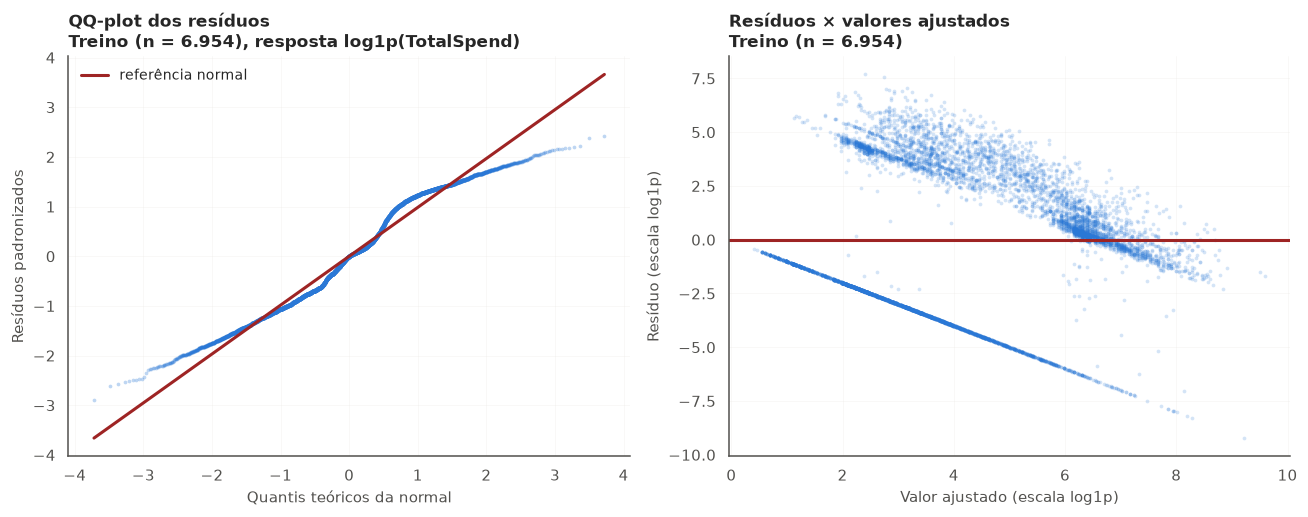

Figura exportada: report/figures/kan31_diagnostico_residuos.png
Resíduo médio (log1p) - passageiros com TotalSpend = 0: -3.10; com TotalSpend > 0: 2.21
Assimetria dos resíduos: 0.06 | curtose em excesso: -1.02


In [77]:
from scipy import stats

resid_train = ols.resid
std_resid = resid_train / np.sqrt(ols.scale)
fitted_train = ols.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
(osm, osr), (slope, intercept, _) = stats.probplot(std_resid, dist='norm')
axes[0].scatter(osm, osr, s=6, alpha=0.3, color=POINT_COLOR, linewidths=0)
axes[0].plot(osm, slope * osm + intercept, color=MEDIAN_COLOR, linewidth=2, label='referência normal')
axes[0].set_xlabel('Quantis teóricos da normal')
axes[0].set_ylabel('Resíduos padronizados')
axes[0].set_title(f'QQ-plot dos resíduos\nTreino (n = {fmt_int(int(ols.nobs))}), resposta log1p(TotalSpend)',
                  loc='left', fontsize=11)
axes[0].legend(frameon=False, loc='upper left')

axes[1].scatter(fitted_train, resid_train, s=6, alpha=0.2, color=POINT_COLOR, linewidths=0)
axes[1].axhline(0, color=MEDIAN_COLOR, linewidth=2)
axes[1].set_xlabel('Valor ajustado (escala log1p)')
axes[1].set_ylabel('Resíduo (escala log1p)')
axes[1].set_title(f'Resíduos × valores ajustados\nTreino (n = {fmt_int(int(ols.nobs))})', loc='left', fontsize=11)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
output = FIGURES_DIR / 'kan31_diagnostico_residuos.png'
fig.savefig(output, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')

zero_mask = reg_train[REG_TARGET] == 0
print(f'Resíduo médio (log1p) - passageiros com TotalSpend = 0: {resid_train[zero_mask].mean():.2f}; '
      f'com TotalSpend > 0: {resid_train[~zero_mask].mean():.2f}')
print(f'Assimetria dos resíduos: {stats.skew(resid_train):.2f} | curtose em excesso: {stats.kurtosis(resid_train):.2f}')

In [78]:
vif_train = vif_by_column(X_reg_train)

reg_term_columns = {var: [var] for var in REG_NUMERIC}
reg_term_columns.update({var: [f'{var}_{lvl}' for lvl in reg_levels[var]['demais']] for var in REG_CATEGORICAL})
R_train = X_reg_train.drop(columns='const').corr().values
train_cols = list(X_reg_train.drop(columns='const').columns)
det_R_train = np.linalg.det(R_train)

gvif_train_rows = []
for var, var_cols in reg_term_columns.items():
    idx = [train_cols.index(c) for c in var_cols]
    rest = [i for i in range(len(train_cols)) if i not in idx]
    gvif = np.linalg.det(R_train[np.ix_(idx, idx)]) * np.linalg.det(R_train[np.ix_(rest, rest)]) / det_R_train
    gvif_train_rows.append({'variável': var, 'df': len(var_cols), 'GVIF': gvif,
                            'GVIF^(1/(2df))': gvif ** (1 / (2 * len(var_cols))),
                            'equivalente a VIF': gvif ** (1 / len(var_cols))})

print('VIF por coluna (treino):')
print(vif_train.round(2).sort_values(ascending=False).to_string())
print(f'\nColunas com VIF > 5: {list(vif_train[vif_train > 5].index) or "nenhuma"}')
pd.DataFrame(gvif_train_rows).set_index('variável').round(2)

VIF por coluna (treino):
HomePlanet_Europa   7.980
CabinDeck_B         4.470
CabinDeck_C         4.240
CabinDeck_A         2.180
CabinDeck_G         1.710
HomePlanet_Mars     1.620
CabinDeck_D         1.540
CabinDeck_E         1.260
Age                 1.130
GroupSize           1.080
VIP_True            1.050
CabinDeck_T         1.030

Colunas com VIF > 5: ['HomePlanet_Europa']


,df,GVIF,GVIF^(1/(2df)),equivalente a VIF
variável,,,,
Age,1,1.130,1.060,1.130
GroupSize,1,1.080,1.040,1.080
HomePlanet,2,10.340,1.790,3.220
CabinDeck,7,10.680,1.180,1.400
VIP,1,1.050,1.020,1.050


**Interpretação dos diagnósticos.**

**Normalidade.**
- O QQ-plot tem formato de S, com caudas mais curtas que as de uma normal (curtose em excesso de -1,02).
- A assimetria é próxima de zero (0,06).
- Os resíduos **não seguem uma distribuição normal**.

**Homocedasticidade.**
- O gráfico de resíduos × valores ajustados mostra **duas faixas separadas**, e não uma nuvem aleatória.
- A faixa inferior é uma reta formada pelos passageiros com `TotalSpend = 0`: para eles, o resíduo é exatamente o negativo do valor ajustado (resíduo médio de -3,10).
- A faixa superior reúne os passageiros que gastaram (resíduo médio de +2,21) e também desce com o valor ajustado.
- A variância e a média dos resíduos mudam ao longo dos valores ajustados, ou seja, o pressuposto de **variância constante não se sustenta** e há estrutura não capturada.
- Esse padrão vem da mistura de zeros com gastos positivos. Como antecipado, a transformação `log1p` não resolve essa mistura.

**Consequências.**
- Os coeficientes continuam descrevendo associações médias na escala log1p.
- Os erros-padrão convencionais, os p-valores e os intervalos de confiança devem ser lidos com **cautela**, porque dependem da homocedasticidade. A seção 11.3.1 apresenta a inferência robusta (HC3). Com n = 6.954, a falta de normalidade pesa menos nos testes do que a heterocedasticidade.
- Alternativas de modelagem possíveis, **não aplicadas aqui** por estarem fora do escopo do card:
  - modelos em duas partes (gastou ou não, e quanto);
  - inclusão de `CryoSleep`.

**Multicolinearidade (treino).**
- Os valores reproduzem praticamente os da seção 8.
- `HomePlanet_Europa` tem **VIF = 7,98**, acima do limite de 5 citado no card. As demais colunas ficam abaixo de 5, com `CabinDeck_B` (4,47) e `CabinDeck_C` (4,24) próximas dele.
- Por variável, os GVIF são 10,34 para `HomePlanet` (equivalente a VIF de 3,22) e 10,68 para `CabinDeck` (1,40). `Age`, `GroupSize` e `VIP` mostram pouca evidência de multicolinearidade (de 1,05 a 1,13).
- **O critério "VIF < 5" do card, aplicado por coluna, não é atendido** pela dummy `HomePlanet_Europa` (VIF = 7,98).
- **Decisão do grupo (revisão do PR #20):** a colinearidade passa a ser avaliada por variável, pelo **GVIF ajustado**, que não depende da categoria de referência das dummies. O critério GVIF^(1/(2·df)) < √5 ≈ 2,24 é equivalente a GVIF^(1/df) < 5, na mesma escala do limite de VIF do card. No treino (n = 6.954):
  - `HomePlanet`: GVIF^(1/(2·df)) = 1,79, ou seja, GVIF^(1/df) = 3,22;
  - `CabinDeck`: GVIF^(1/(2·df)) = 1,18, ou seja, GVIF^(1/df) = 1,40;
  - `Age`, `GroupSize` e `VIP`: entre 1,02 e 1,06 em GVIF^(1/(2·df)).

  Todas as variáveis atendem ao critério, e as duas preditoras foram mantidas. A sobreposição entre `HomePlanet` e `CabinDeck` continua limitando a interpretação **separada** dos coeficientes dessas duas variáveis.

### 11.3.1 Inferência robusta à heterocedasticidade (HC3)

O diagnóstico mostrou que a variância dos resíduos não é constante. Os erros-padrão **convencionais** do OLS supõem variância constante e podem ficar subestimados ou superestimados quando essa hipótese falha.

Os erros-padrão **HC3** (de *heteroskedasticity-consistent*) recalculam a incerteza a partir dos resíduos de cada observação, sem supor variância constante. A versão HC3 dá mais peso às observações de alta alavancagem e é a recomendada em amostras finitas.

- **O ajuste é o mesmo:** os coeficientes β não mudam.
- **Muda só a inferência:** erro-padrão, estatística t (agora z/t robusta), p-valor e intervalo de confiança.
- HC3 corrige a inferência para a heterocedasticidade, mas **não** corrige a falta de normalidade nem a estrutura dos resíduos causada pelos zeros.

In [79]:
ols_hc3 = ols.get_robustcov_results(cov_type='HC3')  # mesmo ajuste, nova matriz de covariância

hc3_ci = pd.DataFrame(ols_hc3.conf_int(), index=ols.params.index)
hc3_table = pd.DataFrame({
    'β (igual)': ols.params,
    'EP convencional': ols.bse,
    'EP HC3': pd.Series(ols_hc3.bse, index=ols.params.index),
    'razão HC3/conv.': pd.Series(ols_hc3.bse, index=ols.params.index) / ols.bse,
    'p convencional': ols.pvalues,
    'p HC3': pd.Series(ols_hc3.pvalues, index=ols.params.index),
    'IC95% HC3 inf': hc3_ci[0],
    'IC95% HC3 sup': hc3_ci[1],
})
assert np.allclose(ols_hc3.params, ols.params)

changed = hc3_table[(hc3_table['p convencional'] < 0.05) != (hc3_table['p HC3'] < 0.05)]
print(f'F robusto (HC3): {float(np.squeeze(ols_hc3.fvalue)):.1f} (p = {float(np.squeeze(ols_hc3.f_pvalue)):.3g})')
print('Coeficientes que mudam de conclusão a 5%:', list(changed.index) or 'nenhum')
hc3_table.round(4)

F robusto (HC3): 436.2 (p = 0)
Coeficientes que mudam de conclusão a 5%: ['CabinDeck_E']


,β (igual),EP convencional,EP HC3,razão HC3/conv.,p convencional,p HC3,IC95% HC3 inf,IC95% HC3 sup
const,5.446,0.126,0.105,0.832,0.000,0.000,5.240,5.652
Age,0.047,0.003,0.003,0.997,0.000,0.000,0.042,0.053
GroupSize,-0.140,0.025,0.025,1.012,0.000,0.000,-0.190,-0.091
HomePlanet_Europa,-3.105,0.249,0.295,1.184,0.000,0.000,-3.683,-2.527
HomePlanet_Mars,-3.032,0.120,0.110,0.914,0.000,0.000,-3.247,-2.817
CabinDeck_A,1.390,0.333,0.403,1.212,0.000,0.001,0.599,2.180
CabinDeck_B,-0.172,0.276,0.339,1.231,0.532,0.612,-0.837,0.493
CabinDeck_C,1.226,0.278,0.343,1.234,0.000,0.000,0.554,1.899
CabinDeck_D,2.135,0.203,0.201,0.994,0.000,0.000,1.740,2.529
CabinDeck_E,0.247,0.143,0.125,0.875,0.083,0.048,0.003,0.492


**Interpretação (HC3 × convencional).**

**O que muda.** Os coeficientes são os mesmos, e só a incerteza é recalculada.
- **Erros-padrão maiores com HC3:** `HomePlanet_Europa` e os decks A, B e C, com aumento de 18% a 23%.
- **Erros-padrão menores com HC3:** o intercepto e os decks E e G, entre outros.
- **Praticamente iguais:** `Age`, `GroupSize`, `VIP` e o deck D (razão de 0,99 a 1,01).
- O F robusto continua significativo (436,2; p < 0,001).

**Conclusões a 5%.** Quase todas se mantêm.
- A única mudança é `CabinDeck_E`, que passa de p = 0,083 para p = 0,048. Está muito perto do limite, então a diferença do deck E em relação a F deve ser tratada como **fraca e incerta** nas duas abordagens.
- `CabinDeck_B` continua não significativo.

**Deck T.** O erro-padrão HC3 diminui muito (razão de 0,29), mas isso **não** torna o coeficiente confiável. Com só 5 passageiros, a estimativa robusta da variância também é instável. O deck T continua não interpretável.

**Quando usar cada uma.** Como o diagnóstico mostrou heterocedasticidade, a inferência **HC3 é a mais adequada** para os p-valores e os intervalos deste modelo. A inferência convencional fica registrada para comparação. Nenhuma das duas corrige a falta de normalidade nem a estrutura dos resíduos causada pelos zeros.

### 11.4 Síntese do KAN-31

- **Modelo:** regressão linear múltipla (OLS, `statsmodels`) de `log1p(TotalSpend)` sobre `Age`, `HomePlanet`, `CabinDeck`, `VIP` e `GroupSize`. A escala da resposta foi definida antes do ajuste.
  - Divisão própria: 80/20, `random_state=42`, sem estratificação.
  - Codificação e referências aprendidas só no treino: `Earth`, `F` e `False`.
- **Ajuste (escala log1p, treino):** R² = 0,257, R² ajustado = 0,256, F = 200,2 (p < 0,001).
- **Erro de previsão:** RMSE de 3,18 no treino e no teste (log1p), contra 3,71 de quem prevê sempre a média do treino. Em dinheiro, via `expm1`, o RMSE é de cerca de 3.079 no teste. Essa inversão não estima o gasto médio esperado.
- **Associações principais**, mantidas as demais preditoras:
  - VIP: cerca de +950% em `1 + TotalSpend`;
  - idade: +4,8% por ano;
  - tamanho do grupo: -13% por pessoa;
  - diferenças fortes entre planetas e decks, que não devem ser lidas separadamente por causa da sobreposição entre `HomePlanet` e `CabinDeck`;
  - deck T: não interpretável, com apenas 5 passageiros.
- **Diagnóstico:**
  - os resíduos não são normais (QQ-plot em S);
  - a variância não é constante: duas faixas, uma delas formada pelos passageiros com gasto zero;
  - a transformação `log1p` não resolve a mistura de zeros e gastos positivos;
  - os p-valores e os intervalos convencionais exigem cautela.
- **Inferência robusta (HC3, seção 11.3.1):** é a mais adequada diante da heterocedasticidade. Os coeficientes são os mesmos e as conclusões a 5% se mantêm, exceto `CabinDeck_E`, que vai de p = 0,083 para 0,048, no limite e portanto incerto. O deck T continua não interpretável.
- **Multicolinearidade (treino):** por coluna, a dummy `HomePlanet_Europa` tem VIF = 7,98, acima de 5, e as demais colunas ficam abaixo de 5.
- **Critério adotado pelo grupo (revisão do PR #20):** a colinearidade foi avaliada pelo **GVIF ajustado** por variável, com o critério GVIF^(1/(2·df)) < √5, equivalente a GVIF^(1/df) < 5. `HomePlanet` (1,79, ou 3,22 na escala de VIF) e `CabinDeck` (1,18, ou 1,40) atendem a esse critério, e as duas preditoras foram mantidas. A sobreposição entre elas continua limitando a interpretação separada dos seus coeficientes.
- **Limitações:** associações, e não efeitos causais; `CryoSleep` ficou fora das preditoras do card; a resposta mistura zeros e gastos positivos.

## 12. KAN-33 - Regressão logística para `Transported`

- **Responsável:** Renatta
- **Revisor:** Gustavo

**Objetivo.** Ajustar o modelo preditivo principal para a probabilidade de um passageiro ser transportado e explicar, por meio das **razões de chance** (*Odds Ratios*), como cada atributo se associa a essa chance. A avaliação no teste e a comparação com os baselines ficam no KAN-34 (seção 13).

### 12.1 Preditoras e pipeline sem vazamento

**Divisão.** Reutilizamos a divisão de referência do KAN-32 (`X_train`, `X_test`, `y_train` e `y_test`, seção 10.1), para que o modelo seja comparado com os baselines no mesmo teste.

**Preditoras, definidas antes do ajuste.** Usamos os atributos do passageiro disponíveis na base tratada, sem redundâncias exatas:

| Tipo | Variáveis | Tratamento |
|---|---|---|
| Categóricas | `CryoSleep`, `HomePlanet`, `Destination`, `CabinDeck`, `CabinSide`, `VIP` | `OneHotEncoder`, com a categoria mais frequente no treino como referência (`False` para os booleanos) |
| Numéricas | `Age`, `GroupSize` | `StandardScaler` |
| Gastos | `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | `log1p` e depois `StandardScaler` (a assimetria e os zeros foram mostrados na seção 3) |

**Variáveis que ficam de fora:**
- `TotalSpend`, que é a soma exata dos cinco gastos;
- `HasSpent`, derivada de `TotalSpend`;
- `IsAlone`, derivada de `GroupSize`;
- os identificadores (`PassengerId`, `Group`, `CabinNum`, `Cabin` e `Name`).

Nenhuma variável foi escolhida pelo desempenho no teste.

**Sem vazamento.** O padronizador e o codificador ficam dentro de um `Pipeline` e são ajustados **apenas em `X_train`**: médias, desvios-padrão e categorias vêm do treino. O `log1p` não tem parâmetros. Ao teste, o pipeline só aplica as transformações já aprendidas.

**Modelo.** Usamos `LogisticRegression(penalty=None)`, ou seja, **sem regularização**. Assim os coeficientes são as estimativas de máxima verossimilhança, que podem ser interpretadas como razões de chance e têm intervalos de confiança válidos. Com regularização, os coeficientes seriam encolhidos em direção a zero.

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

LOGIT_CATEGORICAL = ['CryoSleep', 'HomePlanet', 'Destination', 'CabinDeck', 'CabinSide', 'VIP']
LOGIT_NUMERIC = ['Age', 'GroupSize']
LOGIT_SPEND = SPEND_COLUMNS
LOGIT_FEATURES = LOGIT_CATEGORICAL + LOGIT_NUMERIC + LOGIT_SPEND

# Referências aprendidas só no treino: categoria mais frequente (False para booleanos).
logit_references = [
    False if X_train[col].dtype == bool else X_train[col].value_counts().idxmax()
    for col in LOGIT_CATEGORICAL
]

preprocessor = ColumnTransformer([
    ('categoricas', OneHotEncoder(drop=logit_references, handle_unknown='error'), LOGIT_CATEGORICAL),
    ('numericas', StandardScaler(), LOGIT_NUMERIC),
    ('gastos', Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                         ('padronizacao', StandardScaler())]), LOGIT_SPEND),
], verbose_feature_names_out=False)

logit_pipeline = Pipeline([
    ('preprocessamento', preprocessor),
    # tol reduzida: a verossimilhança é quase plana no deck T (4 passageiros no treino) e o critério padrão
    # para o otimizador antes do ótimo. É critério de convergência, não ajuste de hiperparâmetro.
    ('modelo', LogisticRegression(penalty=None, max_iter=5000, tol=1e-8)),
])
# O sklearn >= 1.8 avisa que `penalty` será removido; o filtro evita que um caminho
# absoluto do ambiente virtual apareça na saída do notebook (regra de reprodutibilidade).
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=FutureWarning, module='sklearn')
    logit_pipeline.fit(X_train[LOGIT_FEATURES], y_train)

logit_feature_names = list(logit_pipeline[:-1].get_feature_names_out())
print(f'Pipeline ajustado no treino: {fmt_int(len(X_train))} passageiros, {len(logit_feature_names)} colunas após o pré-processamento')
print('Referências:', dict(zip(LOGIT_CATEGORICAL, logit_references)))
print('Convergiu:', logit_pipeline[-1].n_iter_[0] < logit_pipeline[-1].max_iter)

Pipeline ajustado no treino: 6.954 passageiros, 21 colunas após o pré-processamento
Referências: {'CryoSleep': False, 'HomePlanet': 'Earth', 'Destination': 'TRAPPIST-1e', 'CabinDeck': 'F', 'CabinSide': 'S', 'VIP': False}
Convergiu: True


### 12.2 Coeficientes e razões de chance (Odds Ratios) com IC 95%

A chance (*odds*) de ser transportado é p / (1 − p). Cada coeficiente β está na escala do log da chance, e **OR = e^β** é o fator multiplicativo da chance, mantidas as demais variáveis constantes. É uma **associação ajustada** pelas demais preditoras, e não um efeito causal:
- **OR > 1:** a chance aumenta;
- **OR < 1:** a chance diminui;
- **OR = 1:** não há associação.

Como interpretar cada tipo de variável:
- **categóricas:** o OR compara a categoria com a referência;
- **numéricas e gastos:** como foram padronizados, o OR é **por 1 desvio-padrão** (no caso dos gastos, por 1 desvio-padrão de `log1p`).

O `LogisticRegression` não fornece intervalos de confiança. Por isso reajustamos o **mesmo modelo** com `statsmodels.api.Logit` sobre a **mesma matriz transformada do treino** e conferimos que os coeficientes coincidem com os do pipeline.

In [81]:
Z_train = pd.DataFrame(logit_pipeline[:-1].transform(X_train[LOGIT_FEATURES]),
                       columns=logit_feature_names, index=X_train.index)
logit_sm = sm.Logit(y_train.astype(int), sm.add_constant(Z_train)).fit(disp=0, maxiter=200)

sk_params = pd.Series(np.r_[logit_pipeline[-1].intercept_, logit_pipeline[-1].coef_.ravel()],
                      index=['const'] + logit_feature_names)
max_diff = float((sk_params - logit_sm.params).abs().max())
assert max_diff < 1e-3, f'Coeficientes sklearn e statsmodels divergem: {max_diff}'
print(f'Coeficientes sklearn x statsmodels: diferença máxima = {max_diff:.2e} | convergiu: {logit_sm.mle_retvals["converged"]}')
print(f'Pseudo-R² de McFadden (treino): {logit_sm.prsquared:.3f} | LR = {logit_sm.llr:.1f} (p = {logit_sm.llr_pvalue:.3g})')

ci = logit_sm.conf_int()
or_table = pd.DataFrame({
    'β': logit_sm.params,
    'erro-padrão': logit_sm.bse,
    'p-valor': logit_sm.pvalues,
    'OR': np.exp(logit_sm.params),
    'OR IC95% inf': np.exp(ci[0]),
    'OR IC95% sup': np.exp(ci[1]),
}).drop(index='const')
or_table.round(4).sort_values('OR')

Coeficientes sklearn x statsmodels: diferença máxima = 1.18e-05 | convergiu: True
Pseudo-R² de McFadden (treino): 0.311 | LR = 2995.6 (p = 0)


,β,erro-padrão,p-valor,OR,OR IC95% inf,OR IC95% sup
Spa,-0.744,0.041,0.000,0.475,0.439,0.515
CabinDeck_T,-0.699,1.360,0.607,0.497,0.035,7.140
VRDeck,-0.675,0.041,0.000,0.509,0.470,0.551
CabinDeck_G,-0.638,0.096,0.000,0.528,0.438,0.637
CabinDeck_A,-0.628,0.282,0.026,0.534,0.307,0.927
RoomService,-0.602,0.040,0.000,0.548,0.507,0.592
CabinDeck_E,-0.596,0.114,0.000,0.551,0.441,0.689
CabinSide_P,-0.517,0.061,0.000,0.596,0.529,0.672
VIP_True,-0.298,0.211,0.158,0.742,0.491,1.123
Age,-0.118,0.033,0.000,0.888,0.832,0.949


### 12.3 Associação na escala da probabilidade

O OR descreve a mudança na **chance**, que não é o mesmo que a mudança na **probabilidade**. Para traduzir o resultado em pontos percentuais, calculamos os **efeitos marginais médios** no treino:
- **variáveis indicadoras:** a mudança média na probabilidade de transporte ao passar da referência para a categoria, mantendo o restante de cada passageiro;
- **numéricas:** a mudança por 1 desvio-padrão.

Como os ORs, os efeitos marginais são **associações ajustadas**: descrevem como a probabilidade prevista pelo modelo difere entre perfis de passageiros, e não o efeito de intervir numa variável.

In [82]:
margeff = logit_sm.get_margeff(at='overall', dummy=True).summary_frame()
margeff = margeff.rename(columns={'dy/dx': 'efeito médio (p.p.)', 'Std. Err.': 'erro-padrão',
                                  'Conf. Int. Low': 'IC95% inf', 'Cont. Int. Hi.': 'IC95% sup', 'Pr(>|z|)': 'p-valor'})
margeff[['efeito médio (p.p.)', 'erro-padrão', 'IC95% inf', 'IC95% sup']] *= 100
key_rows = [c for c in margeff.index if c.startswith(('CryoSleep', 'HomePlanet', 'CabinDeck'))]
print(f'Probabilidade média prevista no treino: {logit_sm.predict().mean():.3f} | proporção observada: {y_train.mean():.3f}')
margeff.loc[key_rows, ['efeito médio (p.p.)', 'IC95% inf', 'IC95% sup', 'p-valor']].round(2)

Probabilidade média prevista no treino: 0.504 | proporção observada: 0.504


,efeito médio (p.p.),IC95% inf,IC95% sup,p-valor
CryoSleep_True,20.750,16.840,24.660,0.000
HomePlanet_Europa,21.040,14.860,27.230,0.000
HomePlanet_Mars,5.270,2.070,8.470,0.000
CabinDeck_A,-9.770,-18.250,-1.300,0.020
CabinDeck_B,-0.570,-7.880,6.730,0.880
CabinDeck_C,4.070,-3.200,11.330,0.270
CabinDeck_D,-1.440,-6.530,3.650,0.580
CabinDeck_E,-9.370,-12.850,-5.880,0.000
CabinDeck_G,-9.620,-12.310,-6.920,0.000
CabinDeck_T,-10.870,-51.550,29.810,0.600


**Interpretação.**

**Ajuste no treino.**
- O pipeline convergiu, e os coeficientes do `statsmodels` coincidem com os do scikit-learn (diferença máxima de 1,3 × 10⁻⁵).
- O pseudo-R² de McFadden é 0,311, e o teste da razão de verossimilhança (LR = 2.995,6; p < 0,001) indica que as preditoras, em conjunto, explicam a chance de transporte muito melhor que um modelo só com intercepto.
- A probabilidade média prevista (0,504) reproduz a proporção observada no treino.

**Variáveis-chave do card.** Os ORs são relativos às referências e mantêm as demais variáveis constantes.

- **`CryoSleep`:** estar em criossono está associado a uma chance de transporte **3,21 vezes maior** (IC95% de 2,61 a 3,94), o que corresponde a um efeito marginal médio de **+20,8 pontos percentuais** na probabilidade prevista (IC de 16,8 a 24,7). Esse efeito é medido **já descontando os gastos**: como nenhum passageiro em criossono gastou, parte da associação do criossono também aparece nos coeficientes dos gastos. As duas variáveis devem ser lidas em conjunto.
- **`HomePlanet`:**
  - em relação a Earth, Europa tem OR de **3,97** (de 2,58 a 6,10), ou +21,0 p.p.;
  - Mars tem OR de 1,40 (de 1,14 a 1,72), ou +5,3 p.p.;
  - como planeta e deck se sobrepõem (seção 8), o efeito de Europa é estimado **dentro dos decks em que os planetas coexistem** e não deve ser separado do efeito do deck.
- **`CabinDeck`, em relação ao deck F:**
  - os decks G (OR 0,53), E (0,55) e A (0,53) se associam a uma chance menor, de cerca de -9 a -10 p.p.;
  - B, C e D não se distinguem de F a 5%;
  - o deck T (4 passageiros no treino) tem IC de 0,03 a 7,14 e **não é interpretável**.

**Demais preditoras.** Os gastos são dados por 1 desvio-padrão de `log1p`.
- Gastos em `Spa` (OR 0,48), `VRDeck` (0,51) e `RoomService` (0,55) se associam a uma chance **menor** de transporte.
- Gastos em `FoodCourt` (1,48) e `ShoppingMall` (1,24) se associam a uma chance **maior**.
- O lado P da cabine tem OR de 0,60 em relação ao lado S.
- O destino 55 Cancri e tem OR de 1,34 em relação a TRAPPIST-1e.
- `Age` tem OR de 0,89 por desvio-padrão (cerca de 14 anos).
- `VIP`, `GroupSize` e o destino PSO J318.5-22 não mostram associação significativa a 5%.

**Cuidados.**
- ORs e efeitos marginais são **associações ajustadas** pelas demais preditoras, e não efeitos causais.
- Os ORs dependem do conjunto de preditoras, definido a priori em 12.1.
- Todos os resultados desta seção vêm do **treino**. O desempenho em dados não vistos é avaliado no KAN-34 (seção 13).

### 12.4 Síntese do KAN-33

- **Pipeline:**
  - `ColumnTransformer` com `OneHotEncoder` (referências do treino), `StandardScaler` e `log1p` com `StandardScaler` para os gastos;
  - `LogisticRegression` sem regularização;
  - tudo ajustado **apenas em `X_train`** (divisão do KAN-32), sem vazamento.
- **Preditoras (a priori):** `CryoSleep`, `HomePlanet`, `Destination`, `CabinDeck`, `CabinSide`, `VIP`, `Age`, `GroupSize` e os cinco gastos.
- **Odds Ratios com IC95%:** calculados pelo `statsmodels` na mesma matriz transformada, com coeficientes idênticos aos do pipeline.
  - criossono: OR = 3,21;
  - Europa em relação a Earth: OR = 3,97, a ser lido em conjunto com o deck;
  - decks G, E e A: OR ≈ 0,53-0,55 em relação ao deck F;
  - o deck T não é interpretável.
- **Efeitos marginais médios (associações ajustadas, não causais):** +20,8 p.p. para o criossono e +21,0 p.p. para Europa.
- **Próximo passo:** o desempenho no teste e a comparação com os baselines estão no KAN-34.

## 13. KAN-34 - Avaliação e interpretação do modelo logístico

- **Responsável:** Renatta
- **Revisor:** Gustavo

**Objetivo.** Medir o desempenho do pipeline do KAN-33 em passageiros **não vistos**, os 20% de teste da divisão do KAN-32, e compará-lo com os baselines `most_frequent` e `stratified` (seção 10.2), nas mesmas condições.

**Regras da avaliação:**
- o teste é usado **uma única vez**, sem reajustar nada;
- a classe positiva é `Transported = True`;
- as previsões de classe usam o **limiar 0,5**, fixado antes da avaliação, ou seja, sem otimizar o limiar no teste;
- as curvas ROC e Precisão-Recall usam as probabilidades (`predict_proba`) e mostram o desempenho em todos os limiares.

### 13.1 Previsões no teste e matriz de confusão

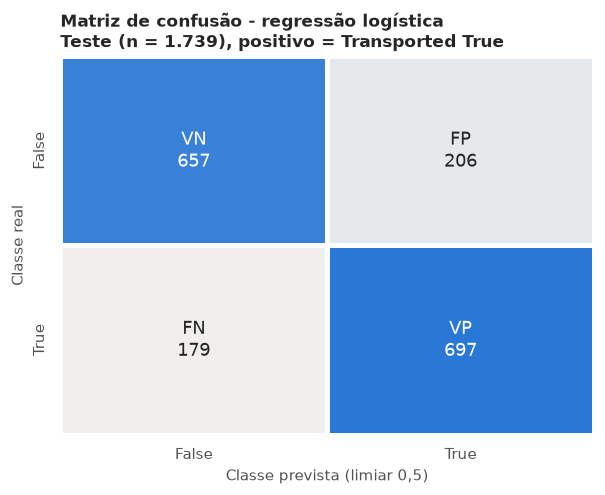

Figura exportada: report/figures/kan34_matriz_confusao.png


In [83]:
THRESHOLD = 0.5

positive_col = list(logit_pipeline.classes_).index(POSITIVE_CLASS)
y_score_logit = logit_pipeline.predict_proba(X_test[LOGIT_FEATURES])[:, positive_col]
y_pred_logit = y_score_logit >= THRESHOLD

cm_logit = confusion_matrix(y_test, y_pred_logit, labels=[False, True])
tn, fp, fn, tp = cm_logit.ravel()

fig, ax = plt.subplots(figsize=(5.6, 4.6))
cell_labels = np.array([[f'VN\n{fmt_int(int(tn))}', f'FP\n{fmt_int(int(fp))}'],
                        [f'FN\n{fmt_int(int(fn))}', f'VP\n{fmt_int(int(tp))}']])
sns.heatmap(cm_logit, annot=cell_labels, fmt='', cmap=LinearSegmentedColormap.from_list('azul', ['#f0efec', '#2a78d6']),
            cbar=False, linewidths=2, linecolor='white', annot_kws={'fontsize': 12}, ax=ax,
            xticklabels=['False', 'True'], yticklabels=['False', 'True'])
ax.set_xlabel('Classe prevista (limiar 0,5)')
ax.set_ylabel('Classe real')
ax.set_title(f'Matriz de confusão - regressão logística\nTeste (n = {fmt_int(len(y_test))}), positivo = Transported True',
             loc='left', fontsize=11)
fig.tight_layout()
output = FIGURES_DIR / 'kan34_matriz_confusao.png'
fig.savefig(output, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')

### 13.2 Tabela comparativa: modelo × baselines

Além das métricas do KAN-32, o card pede a **especificidade**, VN / (VN + FP): a proporção de passageiros **não** transportados que o modelo identifica corretamente. Ela complementa o recall, que mede o mesmo para os transportados. Para os baselines, a especificidade é calculada a partir das matrizes de confusão da seção 10.2.

In [84]:
def specificity(cm):
    tn_, fp_ = cm[0, 0], cm[0, 1]
    return tn_ / (tn_ + fp_) if (tn_ + fp_) > 0 else 0.0


comparison_rows = {}
for name in baselines:
    row = metric_rows[name]
    comparison_rows[f'baseline {name}'] = {
        'acurácia': row['acurácia'], 'precisão': row['precisão'], 'recall': row['recall'],
        'especificidade': specificity(confusion_tables[name].values), 'F1': row['F1'], 'ROC-AUC': row['ROC-AUC'],
    }
comparison_rows['regressão logística'] = {
    'acurácia': accuracy_score(y_test, y_pred_logit),
    'precisão': precision_score(y_test, y_pred_logit, pos_label=POSITIVE_CLASS, zero_division=0),
    'recall': recall_score(y_test, y_pred_logit, pos_label=POSITIVE_CLASS, zero_division=0),
    'especificidade': specificity(cm_logit),
    'F1': f1_score(y_test, y_pred_logit, pos_label=POSITIVE_CLASS, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_score_logit),
}
model_vs_baseline = pd.DataFrame(comparison_rows).T.astype(float)
best_baseline = model_vs_baseline.loc[[f'baseline {n}' for n in baselines]].max()
model_vs_baseline.loc['ganho sobre o melhor baseline'] = model_vs_baseline.loc['regressão logística'] - best_baseline
print(f'Previsões positivas do modelo no teste: {fmt_int(int(y_pred_logit.sum()))} de {fmt_int(len(y_test))}')
model_vs_baseline.round(4)

Previsões positivas do modelo no teste: 903 de 1.739


,acurácia,precisão,recall,especificidade,F1,ROC-AUC
baseline most_frequent,0.504,0.504,1.000,0.000,0.670,0.500
baseline stratified,0.524,0.528,0.523,0.525,0.525,0.524
regressão logística,0.779,0.772,0.796,0.761,0.784,0.862
ganho sobre o melhor baseline,0.255,0.244,-0.204,0.236,0.114,0.338


### 13.3 Curva ROC e curva Precisão-Recall

- **Curva ROC:** a taxa de verdadeiros positivos (recall) contra a taxa de falsos positivos (1 − especificidade), em todos os limiares. A diagonal corresponde a um classificador sem informação (AUC = 0,5), como o `most_frequent`.
- **Curva Precisão-Recall:** mais focada na classe positiva. A linha horizontal na proporção de positivos do teste é a referência sem informação.

Em cada curva, marcamos o ponto do limiar 0,5 do modelo e os pontos dos dois baselines.

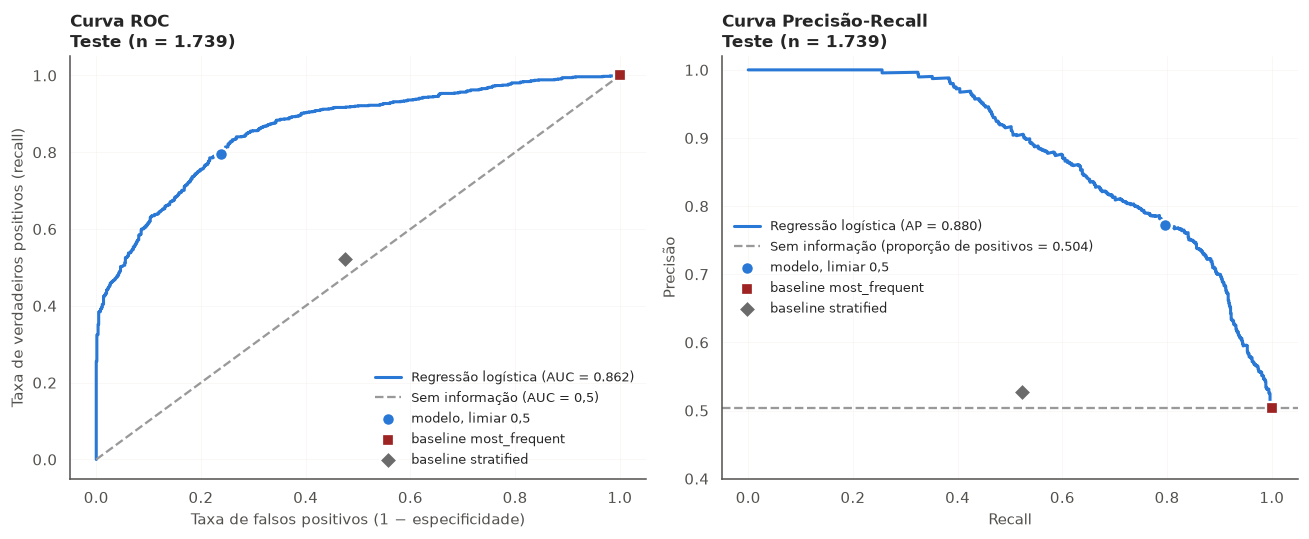

Figura exportada: report/figures/kan34_curvas_roc_pr.png
ROC-AUC = 0.8617 | Average Precision = 0.8803 | proporção de positivos no teste = 0.5037


In [85]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

fpr, tpr, _ = roc_curve(y_test, y_score_logit, pos_label=POSITIVE_CLASS)
prec, rec, _ = precision_recall_curve(y_test, y_score_logit, pos_label=POSITIVE_CLASS)
auc_logit = comparison_rows['regressão logística']['ROC-AUC']
ap_logit = average_precision_score(y_test, y_score_logit, pos_label=POSITIVE_CLASS)
prevalence = y_test.mean()

BASELINE_MARKERS = {'most_frequent': ('s', '#9e2424'), 'stratified': ('D', '#6b6b6b')}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, color=POINT_COLOR, linewidth=2, label=f'Regressão logística (AUC = {auc_logit:.3f})')
axes[0].plot([0, 1], [0, 1], color='#999999', linestyle='--', linewidth=1.5, label='Sem informação (AUC = 0,5)')
axes[1].plot(rec, prec, color=POINT_COLOR, linewidth=2, label=f'Regressão logística (AP = {ap_logit:.3f})')
axes[1].axhline(prevalence, color='#999999', linestyle='--', linewidth=1.5,
                label=f'Sem informação (proporção de positivos = {prevalence:.3f})')

points = {'modelo, limiar 0,5': (comparison_rows['regressão logística'], 'o', POINT_COLOR)}
points.update({f'baseline {n}': (comparison_rows[f'baseline {n}'], *BASELINE_MARKERS[n]) for n in baselines})
for label, (row, marker, color) in points.items():
    axes[0].scatter(1 - row['especificidade'], row['recall'], marker=marker, s=70, color=color,
                    edgecolor='white', linewidth=1.5, zorder=3, label=label)
    axes[1].scatter(row['recall'], row['precisão'], marker=marker, s=70, color=color,
                    edgecolor='white', linewidth=1.5, zorder=3, label=label)

axes[0].set_xlabel('Taxa de falsos positivos (1 − especificidade)')
axes[0].set_ylabel('Taxa de verdadeiros positivos (recall)')
axes[0].set_title(f'Curva ROC\nTeste (n = {fmt_int(len(y_test))})', loc='left', fontsize=11)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precisão')
axes[1].set_ylim(0.4, 1.02)
axes[1].set_title(f'Curva Precisão-Recall\nTeste (n = {fmt_int(len(y_test))})', loc='left', fontsize=11)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=8.5, loc='lower right' if ax is axes[0] else 'center left')
fig.tight_layout()
output = FIGURES_DIR / 'kan34_curvas_roc_pr.png'
fig.savefig(output, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')
print(f'ROC-AUC = {auc_logit:.4f} | Average Precision = {ap_logit:.4f} | proporção de positivos no teste = {prevalence:.4f}')

**Interpretação.**

**Matriz de confusão (limiar 0,5, teste com n = 1.739).**
- O modelo acerta 697 transportados (VP) e 657 não transportados (VN).
- Erra 206 não transportados previstos como transportados (FP) e 179 transportados previstos como não transportados (FN).
- Faz 903 previsões positivas, número próximo dos 876 transportados reais. Os dois tipos de erro têm magnitudes parecidas.

**Comparação com os baselines.**
- A regressão logística supera os dois baselines em acurácia (0,779 contra no máximo 0,524), precisão (0,772), especificidade (0,761), F1 (0,784) e ROC-AUC (0,862).
- O ganho de acurácia é de **+25,5 pontos percentuais**, e o de ROC-AUC, de **+0,34**.
- O F1 do modelo supera o F1 de 0,670 do `most_frequent`, que vinha só de prever todos como transportados (seção 10.2).
- O recall do modelo (0,796) é menor que o do `most_frequent` (1,0). Isso é esperado: o recall máximo do baseline vem com especificidade **0**, porque ele não reconhece nenhum não transportado. O modelo, por outro lado, equilibra recall e especificidade (0,796 e 0,761).

**Poder discriminatório.**
- A curva ROC fica bem acima da diagonal em todos os limiares (AUC = 0,862). Sorteando um transportado e um não transportado, o modelo atribui probabilidade maior ao transportado em cerca de 86% dos pares.
- Na curva Precisão-Recall, o modelo se mantém acima da linha sem informação (0,504) em todos os níveis de recall (Average Precision = 0,880).
- Os pontos dos baselines ficam sobre as referências sem informação ou perto delas.

**Treino × teste.** O pseudo-R² do treino (0,311, seção 12.2) não é comparável diretamente com as métricas do teste. Mesmo assim, o desempenho em passageiros não vistos é consistente com um modelo que generaliza.

**Limitações.**
- O limiar 0,5 foi fixado a priori. Outros limiares trocam recall por especificidade ao longo das curvas, e a escolha depende do custo de cada erro para o cliente.
- O resultado vem de um único conjunto de teste, sem intervalo de incerteza.
- A divisão é por passageiro, e não por grupo de viagem (seção 10.1). Como o modelo usa `GroupSize` e atributos compartilhados no grupo, a avaliação pode ser otimista, em magnitude que não sabemos estimar com esta divisão.

### 13.4 Síntese do KAN-34

| Modelo (teste, n = 1.739) | Acurácia | Precisão | Recall | Especificidade | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Baseline `most_frequent` | 0,504 | 0,504 | 1,000 | 0,000 | 0,670 | 0,500 |
| Baseline `stratified` | 0,524 | 0,528 | 0,523 | 0,525 | 0,525 | 0,524 |
| **Regressão logística** (limiar 0,5) | **0,779** | **0,772** | 0,796 | **0,761** | **0,784** | **0,862** |

- **Matriz de confusão:** VP = 697, VN = 657, FP = 206 e FN = 179.
- **Curvas:** a curva ROC tem AUC = 0,862 e a curva Precisão-Recall tem AP = 0,880, ambas bem acima das referências sem informação.
- **Conclusão:** o modelo agrega valor real em relação às regras ingênuas, com +25,5 p.p. de acurácia e +0,34 de ROC-AUC sobre o melhor baseline.
- **Uso:** a escolha do limiar deve considerar o custo dos falsos positivos e dos falsos negativos para o cliente.

Figuras exportadas: `report/figures/kan34_matriz_confusao.png` e `report/figures/kan34_curvas_roc_pr.png`.

---
# 6. Conclusões e Recomendações Práticas

**Objetivo Analítico (T3):** Conclusões e Recomendações Práticas: principais insights acionáveis, pontos de atenção e próximos passos compreensíveis por alguém sem formação técnica, apoiando o Resumo Executivo de 1 página e o Relatório Técnico de 10 a 15 páginas.  
**Tickets Jira:** [KAN-44](https://megamatic.atlassian.net/browse/KAN-44)  
**Notebooks Consolidados:** `notebooks/06_conclusoes_recomendacoes.ipynb`

# Seção 6 — Conclusões e Recomendações Práticas
**Seção T3** | 6. Conclusões e Recomendações Práticas |
| **Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Insumos** | Seções 1 a 5 do notebook consolidado e os documentos `docs/conclusoes/01` a `05` |

> **Papel deste capítulo.** Ele **não produz análise nova**. Reúne os números já estabelecidos nas Seções 1 a 5, confere uma parte deles contra a base limpa e os traduz em recomendações compreensíveis por quem não tem formação técnica. Toda afirmação aponta a seção de origem, para que o relatório (KAN-39) possa rastreá-la.

## 1. Como ler este capítulo

O projeto investigou **o que distingue os passageiros transportados dos não transportados** no incidente da *Spaceship Titanic*. A resposta tem três camadas, e a ordem importa:

1. **Quem era o passageiro** — origem, cabine, idade, estado de criossono;
2. **Como se comportou a bordo** — consumo nas cinco rubricas de gasto;
3. **O que o conjunto das variáveis consegue prever** — modelo logístico e sua avaliação fora da amostra.

A primeira célula recomputa os indicadores de manchete a partir da base limpa. Os valores servem de conferência: se a base mudar, os números abaixo deixam de bater e a célula final falha, em vez de produzir um resumo desatualizado.

In [86]:
# =============================================================================
# Painel de evidências da Seção 6
#
# Recomputa apenas indicadores de manchete já analisados nas Seções 1 a 5.
# Nenhuma análise nova: o objetivo é conferir os números citados no texto.
# =============================================================================
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
np.random.seed(42)  # semente fixa do projeto, declarada literalmente

CANDIDATOS = [
    Path("../data/processed/spaceship_titanic_clean.csv"),
    Path("data/processed/spaceship_titanic_clean.csv"),
]
DATA_PATH = next((caminho for caminho in CANDIDATOS if caminho.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Base tratada não encontrada a partir de notebooks/ ou da raiz.")

df = pd.read_csv(DATA_PATH)


def pct(valor: float) -> str:
    """Formata proporção (0-1) como percentual com duas casas e vírgula decimal."""
    return f"{100 * valor:.2f}%".replace(".", ",")


def brl(valor: float) -> str:
    """Formata valor monetário no padrão brasileiro."""
    return f"US$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def milhar(valor: int) -> str:
    """Formata inteiro com separador de milhar brasileiro."""
    return f"{valor:,}".replace(",", ".")


# A base usa os nomes em inglês; o texto do capítulo usa os nomes em português.
ROTULO_PLANETA = {"Earth": "Terra", "Mars": "Marte", "Europa": "Europa"}


taxa_global = df["Transported"].mean()
por_planeta = df.groupby("HomePlanet")["Transported"].mean()
por_criossono = df.groupby("CryoSleep")["Transported"].mean()
zero_gasto = (df["TotalSpend"] == 0).mean()
mediana_por_transporte = df.groupby("Transported")["TotalSpend"].median()
media_por_planeta = df.groupby("HomePlanet")["TotalSpend"].mean()
mediana_por_planeta = df.groupby("HomePlanet")["TotalSpend"].median()

print(f"Taxa global de transporte: {pct(taxa_global)} ({milhar(int(df['Transported'].sum()))} de {milhar(len(df))})")
print()
print("Taxa de transporte por planeta de origem:")
for planeta, valor in por_planeta.sort_values(ascending=False).items():
    print(f"  {ROTULO_PLANETA.get(planeta, planeta):<7} {pct(valor)}")
print()
print("Taxa de transporte por estado de criossono:")
for estado, valor in por_criossono.items():
    rotulo = "Em criossono" if estado else "Acordado"
    print(f"  {rotulo:<14} {pct(valor)}")
print()
print(f"Passageiros sem nenhum gasto: {pct(zero_gasto)} ({milhar(int((df['TotalSpend'] == 0).sum()))})")
print()
print("Gasto total por desfecho:")
for transportado, valor in mediana_por_transporte.items():
    rotulo = "Transportado" if transportado else "Não transportado"
    print(f"  {rotulo:<17} mediana {brl(valor)}")
print()
print("Gasto total por planeta (média e mediana):")
for planeta in media_por_planeta.sort_values(ascending=False).index:
    print(f"  {ROTULO_PLANETA.get(planeta, planeta):<7} média {brl(media_por_planeta[planeta])} | mediana {brl(mediana_por_planeta[planeta])}")

Taxa global de transporte: 50,36% (4.378 de 8.693)

Taxa de transporte por planeta de origem:
  Europa  66,05%
  Marte   52,44%
  Terra   42,33%

Taxa de transporte por estado de criossono:
  Acordado       32,82%
  Em criossono   81,47%

Passageiros sem nenhum gasto: 41,92% (3.644)

Gasto total por desfecho:
  Não transportado  mediana US$ 907,00
  Transportado      mediana US$ 0,00

Gasto total por planeta (média e mediana):
  Europa  média US$ 3.444,00 | mediana US$ 1.914,00
  Marte   média US$ 1.059,73 | mediana US$ 950,00
  Terra   média US$ 675,24 | mediana US$ 705,00


## 2. Painel de evidências

| Indicador | Valor | Origem |
| :--- | ---: | :--- |
| Taxa global de transporte | **50,36%** (4.378 de 8.693) | [§2], `docs/conclusoes/02` |
| Transporte por origem — Europa | **66,05%** | [§2], `fig_01` |
| Transporte por origem — Marte | **52,44%** | [§2], `fig_01` |
| Transporte por origem — Terra | **42,33%** | [§2], `fig_01` |
| Transporte em criossono × acordado | **81,47% × 32,82%** | [§2], `fig_02` |
| Associação `HomePlanet` × `Transported` | $\chi^2 = 338{,}82$; $V = 0{,}197$ | Seção 4, `04` |
| Associação `CryoSleep` × `Transported` | $\chi^2 = 1.897{,}71$; $V = 0{,}467$ | Seção 4, `04` |
| Passageiros sem nenhum gasto | **41,92%** (3.644) | [§3], `fig_08` |
| Gasto mediano por desfecho | **US$ 0,00** (transportado) × **US$ 907,00** (não) | Seção 4, `04` |
| Gasto médio por origem — Europa | **US$ 3.444,00** | Seção 4, `04` |
| Idade — aderência à Normal | W = 0,980; D = 0,076 | Seção 3, `03` |
| Gastos positivos — aderência à Log-Normal | W = 0,891; D = 0,126 | Seção 3, `03` |
| Modelo logístico — acurácia no teste | **77,9%** | Seção 5, `05` |
| Modelo logístico — ROC-AUC | **0,862** | Seção 5, `05` |

**Leitura em uma frase.** O estado de criossono é a variável isolada mais associada ao transporte; a origem planetária e o consumo vêm em seguida; e o conjunto das variáveis permite prever o desfecho com 77,9% de acurácia, bem acima dos 50,4% de uma regra ingênua.

## 3. Recomendações práticas

As recomendações abaixo são **de triagem e de investigação**, não de causalidade. Nenhuma delas afirma que uma variável *causou* o transporte.

1. **Priorizar a inspeção das cápsulas de criossono.** Passageiros em criossono foram transportados em 81,47% dos casos, contra 32,82% entre os acordados. É a associação mais forte do estudo (V de Cramér = 0,467, muito forte). Ação: tratar as cápsulas como área crítica na apuração e na comunicação às famílias.
2. **Investigar a diferença por origem planetária.** Europa (66,05%) e Marte (52,44%) têm taxas bem acima da Terra (42,33%), com associação estatisticamente significativa ($\chi^2 = 338{,}82$; $p < 10^{-73}$). Ação: cruzar origem com deck e classe da cabine para entender se o efeito é de localização física a bordo. **Não** usar origem como critério isolado de priorização.
3. **Não tratar gasto como proxy de importância ou de presença.** 41,92% dos passageiros não gastaram nada, e a mediana dos transportados é zero. Ação: usar cabine, grupo de viagem e estado de criossono para reconstruir a alocação a bordo; gasto serve para caracterizar perfil de consumo, não para inferir risco.
4. **Usar o modelo como apoio à triagem, com revisão humana.** O modelo logístico acerta 77,9% no teste, com ROC-AUC de 0,862 e ganho de 25,5 p.p. sobre a regra ingênua. Mas o limiar de 0,5 foi fixado *a priori* e o recall é de 0,796. Ação: recalibrar o limiar conforme o custo relativo de falso positivo e falso negativo antes de qualquer uso operacional.
5. **Comunicar com medianas e proporções, não com médias.** A média de gasto é inflada pela cauda longa (assimetria 4,40). Ação: nos relatórios ao cliente, usar mediana, proporção de gasto zero e taxa de transporte por grupo.

## 4. Limitações

- **Associação não é causa.** Todas as diferenças são observacionais; o desenho não permite isolar mecanismos.
- **Divisão única de treino e teste**, sem intervalo de incerteza para as métricas.
- **Divisão por passageiro, não por grupo de viagem.** Famílias podem aparecer nos dois lados, o que tende a deixar a avaliação otimista em magnitude desconhecida.
- **Imputação pela moda** em 2,1% a 2,5% das categóricas; a sensibilidade já documentada chega a 0,64 p.p. e não muda as conclusões.
- **Limiar 0,5 não otimizado.** Outros limiares trocam recall por especificidade.
- **`HomePlanet_Europa` com VIF de 7,98**, pendência registrada no KAN-31; os coeficientes dessa variável devem ser lidos com cautela.

## 5. Próximos passos

| Etapa | Ticket | O que consome deste capítulo |
| :--- | :--- | :--- |
| Relatório técnico de 10 a 15 páginas | KAN-39 | Recomendações 1 a 5 e o painel de evidências |
| Revisão cruzada | KAN-40 | Conferência dos números contra as seções de origem |
| Validação numérica | KAN-41 | Reprodução do painel pela célula de código |
| PDF e pacote final | KAN-42 / KAN-43 | Texto final e figuras já catalogadas |

**O que não fazer:** usar este capítulo como fonte primária de números. Ele é uma síntese; a fonte é a seção indicada em cada linha do painel.

In [87]:
# =============================================================================
# Guarda-corpo do capítulo
#
# Se a base mudar, estes números deixam de bater e a célula falha: o resumo
# executivo não pode ficar desatualizado em silêncio.
# =============================================================================
assert len(df) == 8693, "A base tratada deve ter 8.693 passageiros."
assert int(df["Transported"].sum()) == 4378, "Esperados 4.378 transportados."
assert int((df["TotalSpend"] == 0).sum()) == 3644, "Esperados 3.644 passageiros sem gasto."
assert abs(taxa_global - 0.5036) < 0.0001, "Taxa global fora do intervalo esperado."
print("Checagens do capítulo: OK")

Checagens do capítulo: OK
